**Note on terminology.** Several cells and outputs in this notebook describe the 115-observation holdout set as "untouched". The holdout was not used during Optuna hyperparameter tuning or cross-validation. However, as explained in Section 3.1 of the dissertation, it was consulted during feature harmonisation and for final model selection, so the reported holdout performance should be regarded as somewhat optimistic rather than fully independent.

# Machine Learning Pipeline for EV Energy Consumption Prediction

**MSc Data Science Dissertation**

Author: Tarek Noman

Purpose:

This notebook trains, optimizes, evaluates and explains machine learning models for predicting electric vehicle energy consumption using the harmonized master dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import sklearn
import xgboost
import shap
import optuna

print("All libraries imported successfully!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

All libraries imported successfully!
Pandas: 3.0.3
Scikit-learn: 1.8.0
XGBoost: 3.2.0


# ⚠️ LEGACY / EXPLORATORY ANALYSIS — SUPERSEDED

## Important methodological note

Stages 1–15 below represent exploratory model-development work and are retained
only as a record of the analytical development process.

Some early cross-validation experiments were performed using the complete
dataset before separation of the final held-out test partition. Consequently,
those cross-validation results are not used as evidence in the dissertation
and must not be interpreted as final model-performance estimates.

The authoritative analysis begins with the corrected final modelling pipeline,
which uses:

- 575 harmonised observations;
- 8 final predictors;
- an 80/20 stratified train/test split;
- 460 observations for model development;
- 115 observations in the held-out test partition;
- five-fold cross-validation performed exclusively on the training partition;
- hyperparameter optimisation performed exclusively on training data;
- final evaluation on the held-out test partition.

The final pipeline was subsequently reproduced from a fresh kernel using the
saved harmonised dataset. The reproduced model metrics matched the
authoritative results.

Therefore, all numerical results from Stages 1–15 are superseded and are not
reported as final dissertation findings.

## Stage 1 — Imports

In [2]:
# ==========================================================
# Stage 1 - Imports
# ==========================================================

from pathlib import Path

import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


## Stage 2 — Load Master Dataset

In [3]:
# ==========================================================
# Stage 2 - Load Master Dataset
# ==========================================================

PROJECT_ROOT = Path(r"C:\Projects\DS7010_Dissertation")

MASTER_DATASET_PATH = (
    PROJECT_ROOT
    / "02-Processed"
    / "Harmonized"
    / "MASTER_EV_ML.csv"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "06-Results"
)

MODELS_DIR = (
    RESULTS_DIR
    / "Models"
)

METRICS_DIR = (
    RESULTS_DIR
    / "Metrics"
)

FIGURES_DIR = (
    RESULTS_DIR
    / "Figures"
)

PREDICTIONS_DIR = (
    RESULTS_DIR
    / "Predictions"
)

SHAP_DIR = (
    RESULTS_DIR
    / "SHAP"
)

for folder in [
    RESULTS_DIR,
    MODELS_DIR,
    METRICS_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR,
    SHAP_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Master dataset exists:", MASTER_DATASET_PATH.exists())
print("Results folder:", RESULTS_DIR)

Master dataset exists: True
Results folder: C:\Projects\DS7010_Dissertation\06-Results


In [4]:
# ==========================================================
# Load Master Dataset
# ==========================================================

master = pd.read_csv(MASTER_DATASET_PATH)

print("=" * 60)
print("MASTER DATASET LOADED")
print("=" * 60)

print("\nShape:")
print(master.shape)

print("\nFirst five rows:")

display(master.head())


MASTER DATASET LOADED

Shape:
(575, 11)

First five rows:


,Mean_Speed_kmh,Max_Speed_kmh,Std_Speed_kmh,Mean_Acceleration_mps2,Max_Acceleration_mps2,Min_Acceleration_mps2,Mean_Positive_Acceleration_mps2,Idling_Proportion,Duration_s,Energy_Consumption_kWh_100km,Dataset
0,35.550077,54.629997,16.473919,-0.013622,9.333333,-5.874999,0.328515,0.062016,106.2,13.760491,VED
1,22.925093,53.049999,15.883698,-0.010552,7.638889,-7.986111,0.355230,0.099251,460.4,28.697582,VED
2,19.378746,41.829998,13.809472,-0.028062,8.611111,-9.638889,0.320445,0.160763,370.3,35.971756,VED
3,26.365563,49.090000,17.445833,0.028884,6.425925,-7.152777,0.249872,0.151408,313.7,22.824763,VED
4,24.035848,58.739998,16.030381,0.012083,9.333335,-6.750000,0.416068,0.111607,382.2,27.585331,VED


In [5]:
# ==========================================================
# Dataset Audit
# ==========================================================

print("Missing values:\n")

display(master.isna().sum())

print("\nDuplicate rows:")

print(master.duplicated().sum())

print("\nDataset distribution:")

display(master["Dataset"].value_counts())

print("\nData types:")

display(master.dtypes)

Missing values:



Mean_Speed_kmh                     0
Max_Speed_kmh                      0
Std_Speed_kmh                      0
Mean_Acceleration_mps2             0
Max_Acceleration_mps2              0
Min_Acceleration_mps2              0
Mean_Positive_Acceleration_mps2    0
Idling_Proportion                  0
Duration_s                         0
Energy_Consumption_kWh_100km       0
Dataset                            0
dtype: int64


Duplicate rows:
0

Dataset distribution:


Dataset
VED        488
BMW         68
ARGONNE     19
Name: count, dtype: int64


Data types:


Mean_Speed_kmh                     float64
Max_Speed_kmh                      float64
Std_Speed_kmh                      float64
Mean_Acceleration_mps2             float64
Max_Acceleration_mps2              float64
Min_Acceleration_mps2              float64
Mean_Positive_Acceleration_mps2    float64
Idling_Proportion                  float64
Duration_s                         float64
Energy_Consumption_kWh_100km       float64
Dataset                                str
dtype: object

## Stage 3 — Exploratory Data Analysis

## Step 3.1 — Summary Statistics

In [6]:
# ==========================================================
# Stage 3.1 - Summary Statistics
# ==========================================================

print("=" * 60)
print("SUMMARY STATISTICS")
print("=" * 60)

display(master.describe())

print("\nDataset statistics:")

display(
    master.groupby("Dataset").describe()
)

SUMMARY STATISTICS


,Mean_Speed_kmh,Max_Speed_kmh,Std_Speed_kmh,Mean_Acceleration_mps2,Max_Acceleration_mps2,Min_Acceleration_mps2,Mean_Positive_Acceleration_mps2,Idling_Proportion,Duration_s,Energy_Consumption_kWh_100km
count,575.000000,575.000000,575.000000,575.000000,575.000000,575.000000,575.000000,575.000000,575.000000,575.000000
mean,41.581699,78.431892,21.987999,0.004857,7.380085,-7.372853,0.222182,0.105965,751.367913,16.149450
std,12.859014,22.909697,7.160963,0.039287,2.437758,2.402343,0.062090,0.086727,787.874509,7.108521
min,4.093332,27.917221,1.890054,-0.353214,1.452876,-10.000000,0.052985,0.000000,60.400000,2.846425
25%,33.040256,65.489998,17.696307,-0.012826,5.541669,-9.254632,0.184299,0.051356,282.850000,11.898583
50%,40.265499,72.680000,20.846451,0.004578,8.305555,-8.249998,0.216685,0.092421,522.400000,14.973896
75%,48.170826,82.574997,24.231111,0.023786,9.416666,-6.277778,0.252292,0.136087,929.000000,18.827392
max,95.699948,152.260000,48.979649,0.196149,10.000000,-1.381946,0.695104,0.792473,5337.995000,79.163078



Dataset statistics:


Mean_Speed_kmh                                                         \
                 count       mean        std        min        25%        50%   
Dataset                                                                         
ARGONNE           19.0  52.748352  24.132962   4.093332  38.418303  39.851558   
BMW               68.0  46.987668  15.034151  22.885183  39.359606  44.839069   
VED              488.0  40.393641  11.485297   8.766128  32.319862  39.379234   

                              Max_Speed_kmh                                    \
               75%        max         count        mean        std        min   
Dataset                                                                         
ARGONNE  69.128470  95.699948          19.0  117.423545  24.796345  27.917221   
BMW      52.844984  93.645415          68.0  115.228699  27.321988  49.310000   
VED      46.763743  89.431499         488.0   71.786351  14.161965  29.969999   

                                                        Std_Speed_kmh  \
                25%         50%         75%         max         count   
Dataset                                                                 
ARGONNE  109.245218  129.117348  129.669352  133.272664          19.0   
BMW      105.840000  121.025000  133.807500  152.260000          68.0   
VED       64.359997   71.490002   77.137497  132.129990         488.0   

                                                                          \
              mean       std        min        25%        50%        75%   
Dataset                                                                    
ARGONNE  34.593077  7.508319   8.818705  33.696035  35.120507  37.367246   
BMW      31.220327  9.153199  14.414463  25.285872  30.933472  38.125835   
VED      20.210756  5.056151   1.890054  17.342806  20.272841  22.756500   

                   Mean_Acceleration_mps2                              \
               max                  count          mean           std   
Dataset                                                                 
ARGONNE  44.681539                   19.0 -1.016310e-07  5.212758e-07   
BMW      48.979649                   68.0  5.405855e-03  3.298463e-02   
VED      41.441000                  488.0  4.969234e-03  4.084791e-02   

                                                                       \
              min           25%           50%           75%       max   
Dataset                                                                 
ARGONNE -0.000001 -2.771907e-07 -5.582996e-08  3.326123e-09  0.000001   
BMW     -0.071344 -1.421940e-02  4.728234e-04  1.875457e-02  0.156230   
VED     -0.353214 -1.386367e-02  5.883661e-03  2.507399e-02  0.196149   

        Max_Acceleration_mps2                                          \
                        count      mean       std       min       25%   
Dataset                                                                 
ARGONNE                  19.0  2.974926  0.820482  1.452876  2.440832   
BMW                      68.0  3.127462  0.556579  1.880000  2.732500   
VED                     488.0  8.144176  1.751991  1.611095  7.114582   

                                       Min_Acceleration_mps2            \
              50%       75%        max                 count      mean   
Dataset                                                                  
ARGONNE  3.290206  3.529372   4.112758                  19.0 -2.955162   
BMW      3.100000  3.452500   4.460000                  68.0 -3.120756   
VED      8.805558  9.500006  10.000000                 488.0 -8.137358   

                                                                      \
              std        min       25%       50%       75%       max   
Dataset                                                                
ARGONNE  0.675777  -3.665719 -3.495844 -3.281265 -2.340249 -1.730040   
BMW      1.107013  -9.030000 -3.465000 -2.980000 -2.390000 -1.610000   
VED      1.65684

## Step 3.2 — Target Distribution

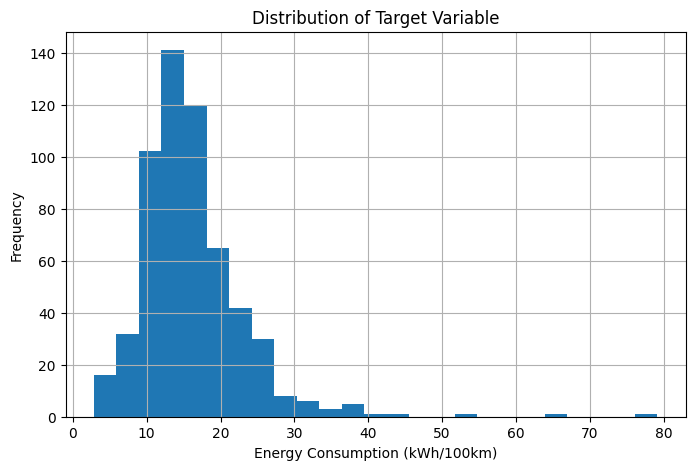

In [7]:
# ==========================================================
# Stage 3.2 - Target Distribution
# ==========================================================

plt.figure(figsize=(8,5))

plt.hist(
    master["Energy_Consumption_kWh_100km"],
    bins=25
)

plt.xlabel("Energy Consumption (kWh/100km)")
plt.ylabel("Frequency")
plt.title("Distribution of Target Variable")

plt.grid(True)

plt.savefig(
    FIGURES_DIR / "Target_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 3.3 — Dataset Comparison

<Figure size 700x500 with 0 Axes>

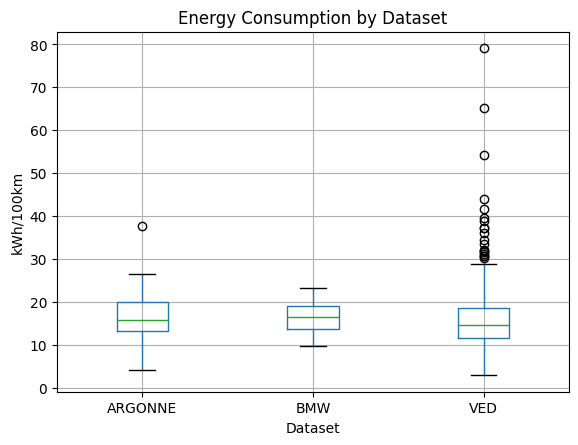

In [8]:
# ==========================================================
# Stage 3.3 - Dataset Comparison
# ==========================================================

plt.figure(figsize=(7,5))

master.boxplot(
    column="Energy_Consumption_kWh_100km",
    by="Dataset"
)

plt.title("Energy Consumption by Dataset")
plt.suptitle("")

plt.ylabel("kWh/100km")

plt.savefig(
    FIGURES_DIR / "Dataset_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Stage 4 — Data Preparation

## Step 4.1 — Separate Features and Target

In [9]:
# ==========================================================
# Stage 4.1 - Features and Target
# ==========================================================

FEATURES = [
    "Mean_Speed_kmh",
    "Max_Speed_kmh",
    "Std_Speed_kmh",
    "Mean_Acceleration_mps2",
    "Max_Acceleration_mps2",
    "Min_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion",
    "Duration_s"
]

TARGET = "Energy_Consumption_kWh_100km"

X = master[FEATURES]

y = master[TARGET]

dataset_labels = master["Dataset"]

print("Features:", X.shape)
print("Target:", y.shape)


Features: (575, 9)
Target: (575,)


## Step 4.2 — Stratified Train/Test Split

In [10]:
# ==========================================================
# Stage 4.2 - Stratified Train/Test Split
# ==========================================================

X_train, X_test, y_train, y_test, train_dataset, test_dataset = train_test_split(
    X,
    y,
    dataset_labels,
    test_size=0.20,
    random_state=42,
    stratify=dataset_labels
)

print("=" * 60)
print("TRAIN / TEST SPLIT")
print("=" * 60)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining distribution:")
print(train_dataset.value_counts())

print("\nTesting distribution:")
print(test_dataset.value_counts())

TRAIN / TEST SPLIT

Training samples: 460
Testing samples: 115

Training distribution:
Dataset
VED        391
BMW         54
ARGONNE     15
Name: count, dtype: int64

Testing distribution:
Dataset
VED        97
BMW        14
ARGONNE     4
Name: count, dtype: int64


### Final training-object naming

The Python objects X_train_sensitivity and y_train_sensitivity are legacy
variable names created during the acceleration-feature sensitivity analysis.

In the authoritative final pipeline, these objects represent the complete
460-observation training partition under the final eight-feature specification.

They are not a reduced sensitivity subset.

The object names were retained to preserve reproducibility of the executed
notebook, but they should not be interpreted as a separate analytical sample.

## Stage 5 — Baseline Model (Linear Regression)

## Step 5.1 — Train the model

In [11]:
# ==========================================================
# Stage 5.1 - Train Linear Regression
# ==========================================================

linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

print("Linear Regression trained successfully.")

Linear Regression trained successfully.


## Step 5.2 — Predictions

In [12]:
# ==========================================================
# Stage 5.2 - Predictions
# ==========================================================

y_pred_lr = linear_model.predict(
    X_test
)

results_lr = pd.DataFrame({

    "Actual": y_test,

    "Predicted": y_pred_lr

})

display(results_lr.head())

,Actual,Predicted
98,11.145313,12.564772
85,19.822085,15.551863
570,19.260553,53.991869
80,19.254731,18.615307
200,15.570998,18.571895


## Step 5.3 — Evaluate

In [13]:
# ==========================================================
# Stage 5.3 - Linear Regression Evaluation
# ==========================================================

mae = mean_absolute_error(
    y_test,
    y_pred_lr
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_lr
    )
)

r2 = r2_score(
    y_test,
    y_pred_lr
)

print("="*60)
print("LINEAR REGRESSION RESULTS")
print("="*60)

print(f"MAE  : {mae:.4f}")

print(f"RMSE : {rmse:.4f}")

print(f"R²   : {r2:.4f}")


LINEAR REGRESSION RESULTS
MAE  : 4.3488
RMSE : 6.2951
R²   : -0.1699


In [14]:
from sklearn.dummy import DummyRegressor

dummy_model = DummyRegressor(strategy="mean")

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

dummy_mae = mean_absolute_error(
    y_test,
    dummy_predictions
)

dummy_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        dummy_predictions
    )
)

dummy_r2 = r2_score(
    y_test,
    dummy_predictions
)

print("=" * 60)
print("DUMMY BASELINE RESULTS")
print("=" * 60)

print(f"MAE  : {dummy_mae:.4f}")
print(f"RMSE : {dummy_rmse:.4f}")
print(f"R²   : {dummy_r2:.4f}")

DUMMY BASELINE RESULTS
MAE  : 4.4156
RMSE : 5.8268
R²   : -0.0023


In [15]:
# ==========================================================
# Model Results Table
# ==========================================================

results_table = pd.DataFrame(columns=[
    "Model",
    "MAE",
    "RMSE",
    "R2"
])

results_table.loc[len(results_table)] = [
    "Linear Regression",
    mae,
    rmse,
    r2
]

display(results_table)

,Model,MAE,RMSE,R2
0,Linear Regression,4.348785,6.295097,-0.169903


## Step 5.4 — Actual vs Predicted Plot

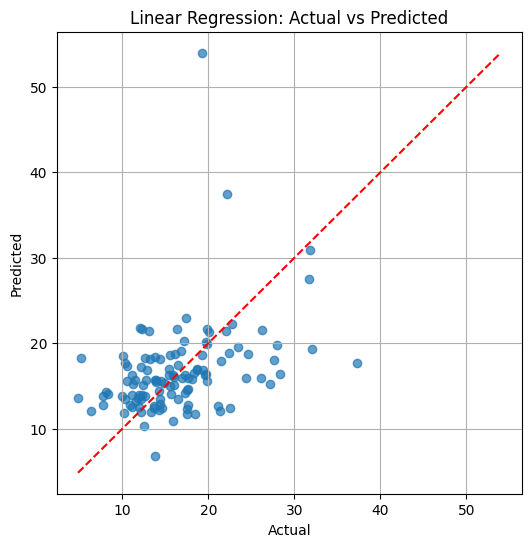

In [16]:
# ==========================================================
# Stage 5.4 - Actual vs Predicted
# ==========================================================

plt.figure(figsize=(6,6))

plt.scatter(
    y_test,
    y_pred_lr,
    alpha=0.7
)

minimum = min(y_test.min(), y_pred_lr.min())
maximum = max(y_test.max(), y_pred_lr.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--"
)

plt.xlabel("Actual")

plt.ylabel("Predicted")

plt.title("Linear Regression: Actual vs Predicted")

plt.grid(True)

plt.savefig(
    FIGURES_DIR / "LinearRegression_Actual_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Stage 6 — Random Forest

## Step 6.1 — Train the Random Forest

In [17]:
# ==========================================================
# Stage 6.1 - Random Forest
# ==========================================================

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest trained successfully.")

Random Forest trained successfully.


## Step 6.2 — Predictions

In [18]:
# ==========================================================
# Stage 6.2 - Predictions
# ==========================================================

y_pred_rf = rf_model.predict(X_test)

## Step 6.3 — Evaluation

In [19]:
# ==========================================================
# Stage 6.3 - Random Forest Evaluation
# ==========================================================

rf_mae = mean_absolute_error(
    y_test,
    y_pred_rf
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_rf
    )
)

rf_r2 = r2_score(
    y_test,
    y_pred_rf
)

print("="*60)
print("RANDOM FOREST RESULTS")
print("="*60)

print(f"MAE  : {rf_mae:.4f}")
print(f"RMSE : {rf_rmse:.4f}")
print(f"R²   : {rf_r2:.4f}")

RANDOM FOREST RESULTS
MAE  : 4.5826
RMSE : 7.5884
R²   : -0.7000


## Step 6.4 — Update the comparison table

In [20]:
# ==========================================================
# Stage 6.8 - Tuned Random Forest
# ==========================================================

rf_model_tuned = RandomForestRegressor(
    n_estimators=200,
    max_depth=6,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_model_tuned.fit(X_train, y_train)

print("Tuned Random Forest trained successfully.")


Tuned Random Forest trained successfully.


In [21]:
# ==========================================================
# Step 6.4 - Update the comparison table safely
# ==========================================================

# Recreate tuned RF predictions if needed
y_pred_rf_tuned = rf_model_tuned.predict(X_test)

# Recalculate tuned RF metrics
rf_tuned_mae = mean_absolute_error(
    y_test,
    y_pred_rf_tuned
)

rf_tuned_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_rf_tuned
    )
)

rf_tuned_r2 = r2_score(
    y_test,
    y_pred_rf_tuned
)

# Create results table if it does not already exist
if "results_table" not in globals():
    results_table = pd.DataFrame(columns=[
        "Model",
        "MAE",
        "RMSE",
        "R2"
    ])

# Add Linear Regression if missing
if "Linear Regression" not in results_table["Model"].values:
    results_table.loc[len(results_table)] = [
        "Linear Regression",
        mae,
        rmse,
        r2
    ]

# Update Random Forest if it exists; otherwise add it
if "Random Forest" in results_table["Model"].values:
    results_table.loc[
        results_table["Model"] == "Random Forest",
        ["MAE", "RMSE", "R2"]
    ] = [
        rf_tuned_mae,
        rf_tuned_rmse,
        rf_tuned_r2
    ]
else:
    results_table.loc[len(results_table)] = [
        "Random Forest",
        rf_tuned_mae,
        rf_tuned_rmse,
        rf_tuned_r2
    ]

display(results_table)

,Model,MAE,RMSE,R2
0,Linear Regression,4.348785,6.295097,-0.169903
1,Random Forest,3.986219,5.722172,0.033355


## Step 6.5 — Actual vs Predicted

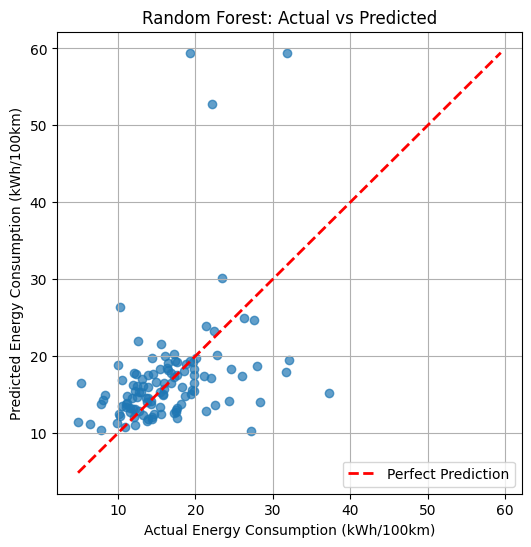

In [22]:
# ==========================================================
# Stage 6.5 - Random Forest: Actual vs Predicted
# ==========================================================

plt.figure(figsize=(6, 6))

# Scatter plot
plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.7
)

# Calculate minimum and maximum values
minimum = min(y_test.min(), y_pred_rf.min())
maximum = max(y_test.max(), y_pred_rf.max())

# Ideal prediction line (Perfect Prediction)
plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    linewidth=2,
    label="Perfect Prediction"
)

# Labels
plt.xlabel("Actual Energy Consumption (kWh/100km)")
plt.ylabel("Predicted Energy Consumption (kWh/100km)")

# Title
plt.title("Random Forest: Actual vs Predicted")

# Grid
plt.grid(True)

# Legend
plt.legend()

# Save figure
plt.savefig(
    FIGURES_DIR / "RandomForest_Actual_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

# Show figure
plt.show()


## Stage 6.6 — Largest Prediction Errors


In [23]:
# ==========================================================
# Stage 6.6 - Largest Prediction Errors (with Dataset)
# ==========================================================

rf_results = pd.DataFrame({
    "Dataset": test_dataset.values,
    "Actual": y_test.values,
    "Predicted": y_pred_rf
})

rf_results["Absolute_Error"] = (
    rf_results["Actual"] -
    rf_results["Predicted"]
).abs()

rf_results = rf_results.sort_values(
    "Absolute_Error",
    ascending=False
)

display(rf_results.head(20))

,Dataset,Actual,Predicted,Absolute_Error
2,ARGONNE,19.260553,59.412358,40.151806
68,VED,22.121708,52.800726,30.679018
80,VED,31.815850,59.442226,27.626376
10,VED,37.314101,15.209280,22.104821
104,VED,27.215950,10.287385,16.928565
48,VED,10.247567,26.325679,16.078113
44,VED,28.318913,14.063739,14.255175
106,VED,31.685726,17.965054,13.720671
33,VED,32.031767,19.523971,12.507796
105,VED,5.188217,16.554212,11.365995


## Stage 6.7 — Feature Importance

,Feature,Importance
0,Mean_Speed_kmh,0.331351
7,Idling_Proportion,0.169497
3,Mean_Acceleration_mps2,0.094566
1,Max_Speed_kmh,0.089712
4,Max_Acceleration_mps2,0.073895
5,Min_Acceleration_mps2,0.067585
6,Mean_Positive_Acceleration_mps2,0.065479
2,Std_Speed_kmh,0.057494
8,Duration_s,0.050422


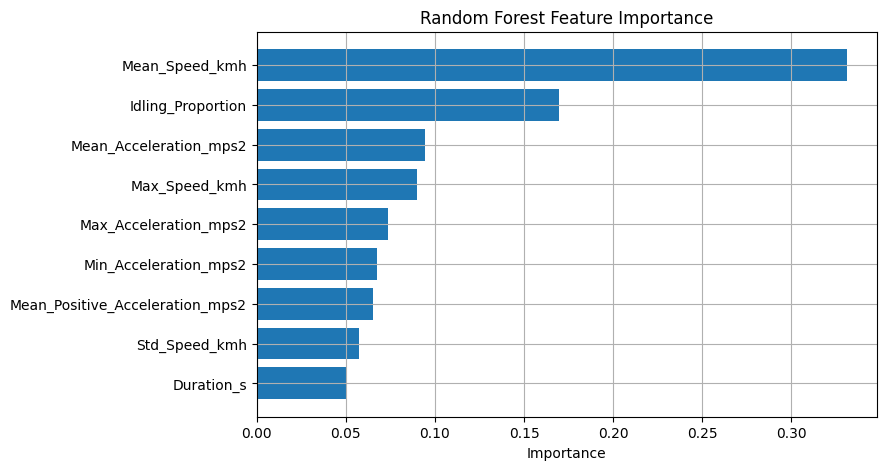

In [24]:
# ==========================================================
# Stage 6.7 - Feature Importance
# ==========================================================

importance = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(8,5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")

plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.grid(True)

plt.savefig(
    FIGURES_DIR / "RF_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)



plt.show()

In [25]:

print(y_test.describe())

count    115.000000
mean      16.373861
std        5.845530
min        4.837667
25%       12.274468
50%       15.570998
75%       19.320358
max       37.314101
Name: Energy_Consumption_kWh_100km, dtype: float64


In [26]:
print("Minimum prediction:", y_pred_rf.min())
print("Maximum prediction:", y_pred_rf.max())

Minimum prediction: 10.287384991022428
Maximum prediction: 59.44222605833865


In [27]:
# ==========================================================
# Random Forest - Training vs Testing Performance
# ==========================================================

train_predictions = rf_model.predict(X_train)

train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, y_pred_rf)

print("Training R² :", round(train_r2, 4))
print("Testing R²  :", round(test_r2, 4))

Training R² : 0.8994
Testing R²  : -0.7


## Stage 6.8 - Tuned Random Forest

### Predictions 

In [28]:
y_pred_rf_tuned = rf_model_tuned.predict(X_test)

### Evaluation

In [29]:
rf_tuned_mae = mean_absolute_error(y_test, y_pred_rf_tuned)

rf_tuned_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_rf_tuned)
)

rf_tuned_r2 = r2_score(
    y_test,
    y_pred_rf_tuned
)

print("="*60)
print("TUNED RANDOM FOREST")
print("="*60)

print(f"MAE  : {rf_tuned_mae:.4f}")
print(f"RMSE : {rf_tuned_rmse:.4f}")
print(f"R²   : {rf_tuned_r2:.4f}")


TUNED RANDOM FOREST
MAE  : 3.9862
RMSE : 5.7222
R²   : 0.0334


### Check for overfitting again

In [30]:
train_pred_tuned = rf_model_tuned.predict(X_train)

train_r2_tuned = r2_score(
    y_train,
    train_pred_tuned
)

print("Training R² :", round(train_r2_tuned,4))
print("Testing R²  :", round(rf_tuned_r2,4))

Training R² : 0.5189
Testing R²  : 0.0334


### 5-fold cross-validation

In [31]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    rf_model_tuned,
    X,
    y,
    cv=cv,
    scoring="r2",
    n_jobs=-1
)

print("Cross-validation R² scores:")
print(cv_scores)

print("\nMean CV R²:", cv_scores.mean())
print("Std CV R² :", cv_scores.std())

Cross-validation R² scores:
[0.28914104 0.19890989 0.42598557 0.1060477  0.22802386]

Mean CV R²: 0.24962161285261536
Std CV R² : 0.10612976844094052


## Stage 6.9 — Save Random Forest Results

In [32]:
# ==========================================================
# Stage 6.9 - Save Random Forest Results
# ==========================================================

rf_cv_results = pd.DataFrame({
    "Fold": np.arange(1, len(cv_scores) + 1),
    "R2": cv_scores
})

rf_cv_results.loc[len(rf_cv_results)] = [
    "Mean",
    cv_scores.mean()
]

rf_cv_results.to_csv(
    METRICS_DIR / "RandomForest_CV_Results.csv",
    index=False
)

print(rf_cv_results)

   Fold        R2
0     1  0.289141
1     2  0.198910
2     3  0.425986
3     4  0.106048
4     5  0.228024
5  Mean  0.249622


## Stage 7 — XGBoost

## Stage 7.1 — Check XGBoost

In [33]:
# ==========================================================
# Stage 7.1 - Check XGBoost
# ==========================================================

try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)

except ImportError:
    print("XGBoost is NOT installed.")
    

XGBoost version: 3.2.0


## Stage 7.2 — Import XGBoost

In [34]:
# ==========================================================
# Stage 7.2 - Import XGBoost
# ==========================================================

from xgboost import XGBRegressor

print("XGBoost imported successfully.")

XGBoost imported successfully.


## Stage 7.3 — Train XGBoost

In [35]:
# ==========================================================
# Stage 7.3 - Train XGBoost
# ==========================================================

xgb_model = XGBRegressor(

    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,

    objective="reg:squarederror",

    random_state=42
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost trained successfully.")

XGBoost trained successfully.


## Stage 7.4 — Predictions

In [36]:
# ==========================================================
# Stage 7.4 - Predictions
# ==========================================================

y_pred_xgb = xgb_model.predict(X_test)

print("Predictions completed.")

Predictions completed.


## Stage 7.5 — Evaluation

In [37]:
# ==========================================================
# Stage 7.5 - Evaluation
# ==========================================================

xgb_mae = mean_absolute_error(
    y_test,
    y_pred_xgb
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb
    )
)

xgb_r2 = r2_score(
    y_test,
    y_pred_xgb
)

print("="*60)
print("XGBOOST RESULTS")
print("="*60)

print(f"MAE  : {xgb_mae:.4f}")
print(f"RMSE : {xgb_rmse:.4f}")
print(f"R²   : {xgb_r2:.4f}")


XGBOOST RESULTS
MAE  : 5.1860
RMSE : 8.8093
R²   : -1.2910


In [38]:
def objective_xgb(trial):

    model = XGBRegressor(
        n_estimators=trial.suggest_int(
            "n_estimators", 100, 500
        ),
        max_depth=trial.suggest_int(
            "max_depth", 2, 8
        ),
        learning_rate=trial.suggest_float(
            "learning_rate", 0.01, 0.2,
            log=True
        ),
        subsample=trial.suggest_float(
            "subsample", 0.6, 1.0
        ),
        colsample_bytree=trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),
        min_child_weight=trial.suggest_int(
            "min_child_weight", 1, 10
        ),
        reg_alpha=trial.suggest_float(
            "reg_alpha", 0.0, 2.0
        ),
        reg_lambda=trial.suggest_float(
            "reg_lambda", 0.5, 5.0
        ),
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    return -scores.mean()

## Stage 7.6 — Check for Overfitting

In [39]:
# ==========================================================
# Stage 7.6 - Training vs Testing Performance
# ==========================================================

train_pred_xgb = xgb_model.predict(X_train)

train_r2_xgb = r2_score(
    y_train,
    train_pred_xgb
)

print("Training R² :", round(train_r2_xgb,4))
print("Testing R²  :", round(xgb_r2,4))

Training R² : 0.9108
Testing R²  : -1.291


## Stage 7.7 — Cross Validation

In [40]:
# ==========================================================
# Stage 7.7 - Cross Validation
# ==========================================================

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb_cv_scores = cross_val_score(
    xgb_model,
    X,
    y,
    cv=cv,
    scoring="r2",
    n_jobs=-1
)

print("Cross-validation R² scores:")
print(xgb_cv_scores)

print("\nMean CV R²:", xgb_cv_scores.mean())

print("Std CV R² :", xgb_cv_scores.std())

Cross-validation R² scores:
[0.25700391 0.17567796 0.41676639 0.02269421 0.0166945 ]

Mean CV R²: 0.17776739549391424
Std CV R² : 0.1505958053528369


## Stage 7.8 — Update Results Table

### Stage 7.9 — Regularized XGBoost

In [41]:
# ==========================================================
# Stage 7.9 - Regularized XGBoost
# ==========================================================

xgb_model_regularized = XGBRegressor(
    n_estimators=100,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.7,
    colsample_bytree=0.7,
    min_child_weight=10,
    reg_alpha=1.0,
    reg_lambda=5.0,
    gamma=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model_regularized.fit(
    X_train,
    y_train
)

print("Regularized XGBoost trained successfully.")


Regularized XGBoost trained successfully.


## Stage 7.10 - Regularized XGBoost Predictions

In [42]:
# ==========================================================
# Stage 7.10 - Regularized XGBoost Predictions
# ==========================================================

y_pred_xgb_regularized = xgb_model_regularized.predict(
    X_test
)

print("Predictions completed.")

Predictions completed.


## Stage 7.11 - Regularized XGBoost Evaluation

In [43]:
# ==========================================================
# Stage 7.11 - Regularized XGBoost Evaluation
# ==========================================================

xgb_reg_mae = mean_absolute_error(
    y_test,
    y_pred_xgb_regularized
)

xgb_reg_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb_regularized
    )
)

xgb_reg_r2 = r2_score(
    y_test,
    y_pred_xgb_regularized
)

print("=" * 60)
print("REGULARIZED XGBOOST RESULTS")
print("=" * 60)

print(f"MAE  : {xgb_reg_mae:.4f}")
print(f"RMSE : {xgb_reg_rmse:.4f}")
print(f"R²   : {xgb_reg_r2:.4f}")

REGULARIZED XGBOOST RESULTS
MAE  : 4.1396
RMSE : 6.0125
R²   : -0.0672


In [44]:
# ==========================================================
# Stage 7.14 - Update Results Table
# ==========================================================

results_table.loc[
    results_table["Model"] == "XGBoost",
    ["MAE", "RMSE", "R2"]
] = [
    xgb_reg_mae,
    xgb_reg_rmse,
    xgb_reg_r2
]

display(results_table)

,Model,MAE,RMSE,R2
0,Linear Regression,4.348785,6.295097,-0.169903
1,Random Forest,3.986219,5.722172,0.033355


## Stage 7.12 - Training vs Testing Performance

In [45]:
# ==========================================================
# Stage 7.12 - Training vs Testing Performance
# ==========================================================

train_pred_xgb_regularized = (
    xgb_model_regularized.predict(X_train)
)

train_r2_xgb_regularized = r2_score(
    y_train,
    train_pred_xgb_regularized
)

print(
    "Training R² :",
    round(train_r2_xgb_regularized, 4)
)

print(
    "Testing R²  :",
    round(xgb_reg_r2, 4)
)

Training R² : 0.4689
Testing R²  : -0.0672


## Stage 7.13 - Regularized XGBoost Cross Validation

In [46]:
# ==========================================================
# Stage 7.13 - Regularized XGBoost Cross Validation
# ==========================================================

xgb_reg_cv_scores = cross_val_score(
    xgb_model_regularized,
    X,
    y,
    cv=cv,
    scoring="r2",
    n_jobs=-1
)

print("Cross-validation R² scores:")
print(xgb_reg_cv_scores)

print(
    "\nMean CV R²:",
    xgb_reg_cv_scores.mean()
)

print(
    "Std CV R² :",
    xgb_reg_cv_scores.std()
    
)

Cross-validation R² scores:
[0.29625341 0.12497523 0.42158003 0.06449872 0.25641372]

Mean CV R²: 0.23274422197184172
Std CV R² : 0.1266280604836085


In [47]:
study_xgb = optuna.create_study(
    direction="minimize"
)

study_xgb.optimize(
    objective_xgb,
    n_trials=30,
    show_progress_bar=True
)

print("Best MAE:", study_xgb.best_value)
print("Best parameters:")
print(study_xgb.best_params)

[I 2026-10-18 23:21:10,638] A new study created in memory with name: no-name-6deab489-b9d9-4815-ad6f-014cdf529288


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-10-18 23:21:10,914] Trial 0 finished with value: 4.46033122263036 and parameters: {'n_estimators': 248, 'max_depth': 6, 'learning_rate': 0.08877749417574131, 'subsample': 0.9362545508291016, 'colsample_bytree': 0.6001319317079035, 'min_child_weight': 7, 'reg_alpha': 0.10294148411706505, 'reg_lambda': 1.7992274962047736}. Best is trial 0 with value: 4.46033122263036.
[I 2026-10-18 23:21:10,994] Trial 1 finished with value: 4.21961428377247 and parameters: {'n_estimators': 121, 'max_depth': 2, 'learning_rate': 0.018186358580440085, 'subsample': 0.9580755380890758, 'colsample_bytree': 0.6873698376230534, 'min_child_weight': 9, 'reg_alpha': 0.6473862349418578, 'reg_lambda': 2.7961338731158376}. Best is trial 1 with value: 4.21961428377247.
[I 2026-10-18 23:21:11,186] Trial 2 finished with value: 4.11323727956278 and parameters: {'n_estimators': 156, 'max_depth': 4, 'learning_rate': 0.04093503344874886, 'subsample': 0.807430799752951, 'colsample_bytree': 0.9935577824241794, 'min_chi

In [48]:
print("Best MAE:", study_xgb.best_value)

print("\nBest parameters:")
print(study_xgb.best_params)

Best MAE: 4.017207049099412

Best parameters:
{'n_estimators': 181, 'max_depth': 4, 'learning_rate': 0.021251457248891256, 'subsample': 0.6006558233523744, 'colsample_bytree': 0.9218676145993308, 'min_child_weight': 1, 'reg_alpha': 1.0176489976147165, 'reg_lambda': 4.909151319393676}


In [49]:
best_xgb = XGBRegressor(
    **study_xgb.best_params,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

best_xgb.fit(
    X_train,
    y_train
)

best_xgb_predictions = best_xgb.predict(X_test)

best_xgb_mae = mean_absolute_error(
    y_test,
    best_xgb_predictions
)

best_xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        best_xgb_predictions
    )
)

best_xgb_r2 = r2_score(
    y_test,
    best_xgb_predictions
)

print("=" * 60)
print("OPTIMIZED XGBOOST — UNTOUCHED TEST SET")
print("=" * 60)

print(f"MAE  : {best_xgb_mae:.4f}")
print(f"RMSE : {best_xgb_rmse:.4f}")
print(f"R²   : {best_xgb_r2:.4f}")

OPTIMIZED XGBOOST — UNTOUCHED TEST SET
MAE  : 4.2414
RMSE : 6.2003
R²   : -0.1349


## Stage 8 — Hyperparameter Optimization (Optuna)

# Stage 8.1 - Check Optuna

In [50]:
# ==========================================================
# Stage 8.1 - Check Optuna
# ==========================================================

try:
    import optuna
    print("Optuna version:", optuna.__version__)

except ImportError:
    print("Optuna is NOT installed.")

Optuna version: 4.8.0


# Stage 8.2 - Optuna Objective Function

In [51]:
from sklearn.ensemble import RandomForestRegressor

print("RandomForestRegressor imported successfully.")

RandomForestRegressor imported successfully.


In [52]:
def objective(trial):
    
    model = RandomForestRegressor(
        n_estimators=trial.suggest_int(
            "n_estimators",
            100,
            500
        ),
        
        max_depth=trial.suggest_int(
            "max_depth",
            3,
            12
        ),
        
        min_samples_split=trial.suggest_int(
            "min_samples_split",
            2,
            20
        ),
        
        min_samples_leaf=trial.suggest_int(
            "min_samples_leaf",
            1,
            10
        ),
        
        max_features=trial.suggest_categorical(
            "max_features",
            ["sqrt", "log2"]
        ),
        
        random_state=42,
        n_jobs=-1
    )
    
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )
    
    return -scores.mean()

# Stage 8.3 - Create Optuna Study

In [53]:
import optuna

print("Optuna version:", optuna.__version__)

Optuna version: 4.8.0


In [54]:
study = optuna.create_study(
    direction="minimize"
)

[I 2026-10-18 23:21:18,436] A new study created in memory with name: no-name-98d8321d-a46e-49e8-ac09-62e5b63ffa28


# Stage 8.4 - Run Optimization

In [55]:
study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=True
)


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-10-18 23:21:20,066] Trial 0 finished with value: 4.130952130905251 and parameters: {'n_estimators': 414, 'max_depth': 9, 'min_samples_split': 2, 'min_samples_leaf': 3, 'max_features': 'log2'}. Best is trial 0 with value: 4.130952130905251.
[I 2026-10-18 23:21:20,861] Trial 1 finished with value: 4.194189711779947 and parameters: {'n_estimators': 208, 'max_depth': 4, 'min_samples_split': 12, 'min_samples_leaf': 9, 'max_features': 'sqrt'}. Best is trial 0 with value: 4.130952130905251.
[I 2026-10-18 23:21:21,284] Trial 2 finished with value: 4.156711867851201 and parameters: {'n_estimators': 125, 'max_depth': 8, 'min_samples_split': 18, 'min_samples_leaf': 7, 'max_features': 'log2'}. Best is trial 0 with value: 4.130952130905251.
[I 2026-10-18 23:21:21,852] Trial 3 finished with value: 4.312974357317068 and parameters: {'n_estimators': 166, 'max_depth': 3, 'min_samples_split': 12, 'min_samples_leaf': 4, 'max_features': 'log2'}. Best is trial 0 with value: 4.130952130905251.
[I 20

In [56]:
print(study.best_params)

{'n_estimators': 417, 'max_depth': 9, 'min_samples_split': 3, 'min_samples_leaf': 2, 'max_features': 'log2'}


In [57]:
print("="*60)
print("BEST PARAMETERS")
print("="*60)

for key, value in study.best_params.items():
    print(f"{key}: {value}")

print("\nBest CV MAE (kWh/100 km):", study.best_value)

BEST PARAMETERS
n_estimators: 417
max_depth: 9
min_samples_split: 3
min_samples_leaf: 2
max_features: log2

Best CV MAE (kWh/100 km): 4.1266117549012105


# Stage 8.5 - Best Parameters

In [58]:
# ==========================================================
# Stage 8.5 - Best Parameters
# ==========================================================

print("=" * 60)
print("BEST PARAMETERS")
print("=" * 60)

print(study.best_params)

print("\nBest CV MAE (kWh/100 km):")
print(study.best_value)

BEST PARAMETERS
{'n_estimators': 417, 'max_depth': 9, 'min_samples_split': 3, 'min_samples_leaf': 2, 'max_features': 'log2'}

Best CV MAE (kWh/100 km):
4.1266117549012105


# Stage 8.6 - Final Random Forest

In [59]:
# ==========================================================
# Stage 8.6 - Final Random Forest
# ==========================================================

best_rf = RandomForestRegressor(
    **study.best_params,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(
    X_train,
    y_train
)

print("Final Random Forest trained successfully.")

Final Random Forest trained successfully.


# Stage 8.7 - Final Evaluation

In [60]:
# ==========================================================
# Stage 8.7 - Final Evaluation
# ==========================================================

final_predictions = best_rf.predict(X_test)

final_mae = mean_absolute_error(
    y_test,
    final_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_predictions
    )
)

final_r2 = r2_score(
    y_test,
    final_predictions
)
# Preserve original Optuna Random Forest metrics
rf_optuna_mae = final_mae
rf_optuna_rmse = final_rmse
rf_optuna_r2 = final_r2

print("=" * 60)
print("FINAL OPTUNA RANDOM FOREST")
print("=" * 60)

print(f"MAE  : {final_mae:.4f}")
print(f"RMSE : {final_rmse:.4f}")
print(f"R²   : {final_r2:.4f}")

FINAL OPTUNA RANDOM FOREST
MAE  : 4.2640
RMSE : 6.5641
R²   : -0.2720


# Stage 8.8 - Final Overfitting Check

In [61]:
# ==========================================================
# Stage 8.8 - Final Overfitting Check
# ==========================================================

train_predictions = best_rf.predict(X_train)

train_r2 = r2_score(
    y_train,
    train_predictions
)

print("Training R² :", round(train_r2,4))

print("Testing R²  :", round(final_r2,4))

Training R² : 0.7337
Testing R²  : -0.272


# Stage 8.9 — Compare Manual vs Optuna

In [62]:
comparison = pd.DataFrame({
    "Version": [
        "Manual Random Forest",
        "Optuna Random Forest"
    ],
    "Test MAE (kWh/100 km)": [
        rf_tuned_mae,
        final_mae
    ],
    "Test RMSE (kWh/100 km)": [
        rf_tuned_rmse,
        final_rmse
    ],
    "Test R²": [
        rf_tuned_r2,
        final_r2
    ],
    "Mean CV R²": [
        cv_scores.mean(),
        np.nan
    ],
    "Mean CV MAE (kWh/100 km)": [
        np.nan,
        study.best_value
    ]
})

display(comparison)

,Version,Test MAE (kWh/100 km),Test RMSE (kWh/100 km),Test R²,Mean CV R²,Mean CV MAE (kWh/100 km)
0,Manual Random Forest,3.986219,5.722172,0.033355,0.249622,NaN
1,Optuna Random Forest,4.263995,6.564112,-0.272030,NaN,4.126612


## Stage 9 — Cross Validation

## Stage 9.1 — Cross Validation Report


# Stage 9.2 - Final Model Cross Validation

In [63]:
# ==========================================================
# Stage 9.2 - Final Model Cross Validation
# ==========================================================

final_cv_scores = cross_val_score(
    best_rf,
    X,
    y,
    cv=cv,
    scoring="r2",
    n_jobs=-1
)

print("Final Optuna Random Forest fold scores:")
print(final_cv_scores)

print("\nMean CV R²:")
print(final_cv_scores.mean())

print("\nCV standard deviation:")
print(final_cv_scores.std())

Final Optuna Random Forest fold scores:
[0.30858907 0.20497257 0.3965176  0.13523969 0.18305281]

Mean CV R²:
0.2456743457358471

CV standard deviation:
0.09432481709480486


# Stage 9.3 - Cross Validation Comparison Table

In [64]:
# ==========================================================
# Stage 9.3 - Cross Validation Comparison Table
# ==========================================================

cv_table = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest (Manually Tuned)",
        "XGBoost (Regularized)",
        "Random Forest (Optuna Optimized)"
    ],

    "Test_R2": [
        r2,
        rf_tuned_r2,
        xgb_reg_r2,
        final_r2
    ],

    "Mean_CV_R2": [
        np.nan,
        cv_scores.mean(),
        xgb_reg_cv_scores.mean(),
        final_cv_scores.mean()
    ],

    "CV_Std": [
        np.nan,
        cv_scores.std(),
        xgb_reg_cv_scores.std(),
        final_cv_scores.std()
    ]
})

display(cv_table)

,Model,Test_R2,Mean_CV_R2,CV_Std
0,Linear Regression,-0.169903,NaN,NaN
1,Random Forest (Manually Tuned),0.033355,0.249622,0.106130
2,XGBoost (Regularized),-0.067222,0.232744,0.126628
3,Random Forest (Optuna Optimized),-0.272030,0.245674,0.094325


# Stage 9.4 - Linear Regression Cross Validation

In [65]:
# ==========================================================
# Stage 9.4 - Linear Regression Cross Validation
# ==========================================================

lr_cv_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=cv,
    scoring="r2",
    n_jobs=-1
)

print("Linear Regression fold scores:")
print(lr_cv_scores)

print("\nMean CV R²:")
print(lr_cv_scores.mean())

print("\nCV standard deviation:")
print(lr_cv_scores.std())

Linear Regression fold scores:
[0.25600706 0.1414018  0.22318094 0.09863682 0.14953036]

Mean CV R²:
0.17375139435661144

CV standard deviation:
0.05741886346290901


# Stage 9.5 - Update Linear Regression CV Results

In [66]:
# ==========================================================
# Stage 9.5 - Update Linear Regression CV Results
# ==========================================================

cv_table.loc[
    cv_table["Model"] == "Linear Regression",
    ["Mean_CV_R2", "CV_Std"]
] = [
    lr_cv_scores.mean(),
    lr_cv_scores.std()
]

display(cv_table)

,Model,Test_R2,Mean_CV_R2,CV_Std
0,Linear Regression,-0.169903,0.173751,0.057419
1,Random Forest (Manually Tuned),0.033355,0.249622,0.106130
2,XGBoost (Regularized),-0.067222,0.232744,0.126628
3,Random Forest (Optuna Optimized),-0.272030,0.245674,0.094325


# Stage 9.6 - Export Cross Validation Report

In [67]:
# ==========================================================
# Stage 9.6 - Export Cross Validation Report
# ==========================================================

cv_report_path = (
    METRICS_DIR
    / "Cross_Validation_Report.csv"
)

cv_table.to_csv(
    cv_report_path,
    index=False
)

print("Cross-validation report saved:")
print(cv_report_path)

Cross-validation report saved:
C:\Projects\DS7010_Dissertation\06-Results\Metrics\Cross_Validation_Report.csv


## Stage 10 — Model Comparison

## Stage 10 — Final Model Comparison

## Stage 10.1 — Final Results Summary

In [68]:
# ==========================================================
# Stage 10.1 - Final Results Summary
# ==========================================================

final_results = pd.DataFrame({

    "Model":[
        "Linear Regression",
        "Random Forest (Manual)",
        "XGBoost (Regularized)",
        "Random Forest (Optuna)"
    ],

    "MAE":[
        mae,
        rf_tuned_mae,
        xgb_reg_mae,
        final_mae
    ],

    "RMSE":[
        rmse,
        rf_tuned_rmse,
        xgb_reg_rmse,
        final_rmse
    ],

    "Test_R2":[
        r2,
        rf_tuned_r2,
        xgb_reg_r2,
        final_r2
    ],

    "Mean_CV_R2":[
        lr_cv_scores.mean(),
        cv_scores.mean(),
        xgb_reg_cv_scores.mean(),
        final_cv_scores.mean()
    ]

})

display(final_results)

,Model,MAE,RMSE,Test_R2,Mean_CV_R2
0,Linear Regression,4.348785,6.295097,-0.169903,0.173751
1,Random Forest (Manual),3.986219,5.722172,0.033355,0.249622
2,XGBoost (Regularized),4.139628,6.012496,-0.067222,0.232744
3,Random Forest (Optuna),4.263995,6.564112,-0.272030,0.245674


## Stage 10.2 - Export Final Results

In [69]:
# ==========================================================
# Stage 10.2 - Export Final Results
# ==========================================================

final_results.to_csv(
    METRICS_DIR / "Final_Model_Comparison.csv",
    index=False
)

print("Final comparison table exported.")

Final comparison table exported.


## Stage 10.3 - MAE Comparison

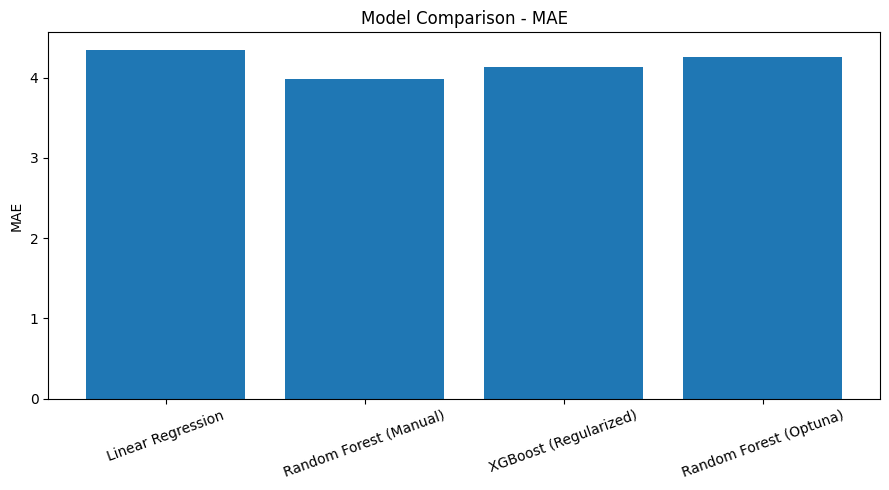

In [70]:
# ==========================================================
# Stage 10.3 - MAE Comparison
# ==========================================================

plt.figure(figsize=(9,5))

plt.bar(
    final_results["Model"],
    final_results["MAE"]
)

plt.ylabel("MAE")

plt.title("Model Comparison - MAE")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "Model_Comparison_MAE.png",
    dpi=300
)

plt.show()

## Stage 10.4 - RMSE Comparison

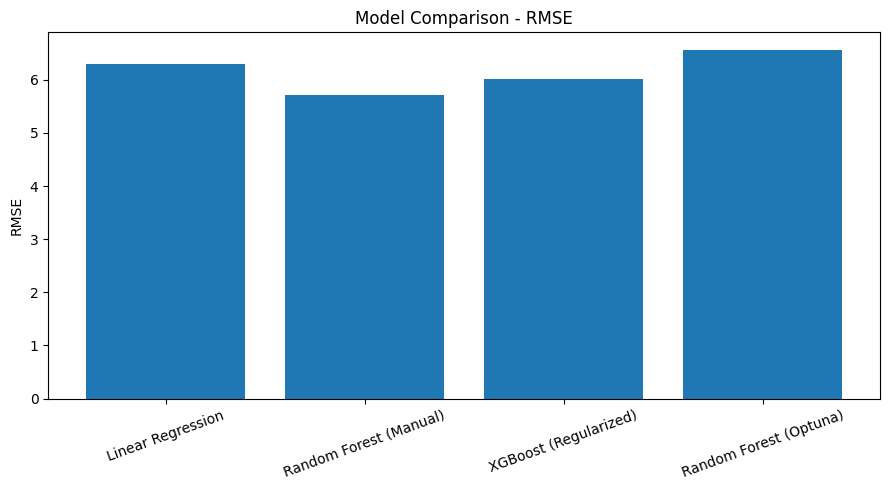

In [71]:
# ==========================================================
# Stage 10.4 - RMSE Comparison
# ==========================================================

plt.figure(figsize=(9,5))

plt.bar(
    final_results["Model"],
    final_results["RMSE"]
)

plt.ylabel("RMSE")

plt.title("Model Comparison - RMSE")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "Model_Comparison_RMSE.png",
    dpi=300
)

plt.show()

## Stage 10.5 - Test R² Comparison

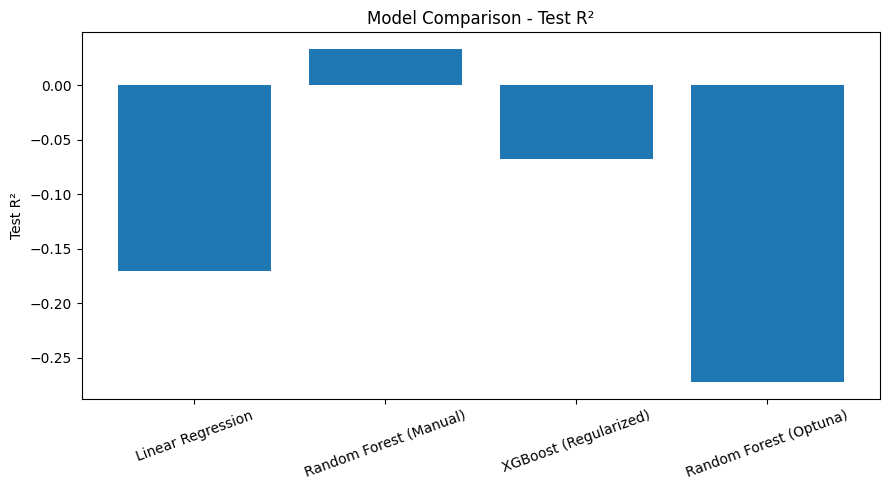

In [72]:
# ==========================================================
# Stage 10.5 - Test R² Comparison
# ==========================================================

plt.figure(figsize=(9,5))

plt.bar(
    final_results["Model"],
    final_results["Test_R2"]
)

plt.ylabel("Test R²")

plt.title("Model Comparison - Test R²")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "Model_Comparison_R2.png",
    dpi=300
)

plt.show()

## Stage 10.6 - Mean CV R²

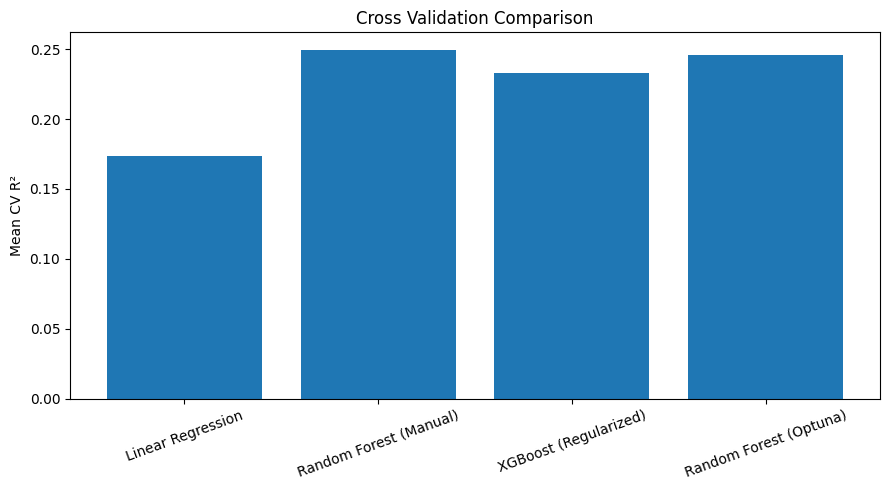

In [73]:
# ==========================================================
# Stage 10.6 - Mean CV R²
# ==========================================================

plt.figure(figsize=(9,5))

plt.bar(
    final_results["Model"],
    final_results["Mean_CV_R2"]
)

plt.ylabel("Mean CV R²")

plt.title("Cross Validation Comparison")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "Cross_Validation_Comparison.png",
    dpi=300
)

plt.show()

## Stage 11 — SHAP Explainability

## Stage 11.1 - Check SHAP

In [74]:
# ==========================================================
# Stage 11.1 - Check SHAP
# ==========================================================

try:
    import shap
    print("SHAP version:", shap.__version__)

except ImportError:
    print("SHAP is NOT installed.")

SHAP version: 0.52.0


## Stage 11.2 - Import SHAP

In [75]:
# ==========================================================
# Stage 11.2 - Import SHAP
# ==========================================================

import shap

print("SHAP imported successfully.")

SHAP imported successfully.


## Stage 11.3 - Create SHAP Explainer

In [76]:
# ==========================================================
# Stage 11.3 - Create SHAP Explainer
# ==========================================================

explainer = shap.TreeExplainer(best_rf)

print("Explainer created.")

Explainer created.


## Stage 11.4 - Calculate SHAP Values

In [77]:
# ==========================================================
# Stage 11.4 - Calculate SHAP Values
# ==========================================================

shap_values = explainer.shap_values(X_test)

print("SHAP values calculated.")

print(shap_values.shape)

SHAP values calculated.
(115, 9)


## Stage 11.5 - SHAP Summary Plot

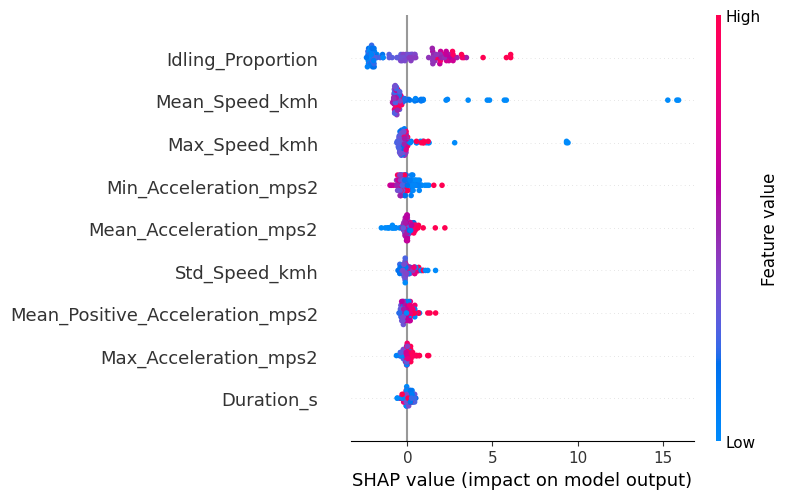

In [78]:
# ==========================================================
# Stage 11.5 - SHAP Summary Plot
# ==========================================================

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "SHAP_Summary.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

## Stage 11.6 - SHAP Bar Plot

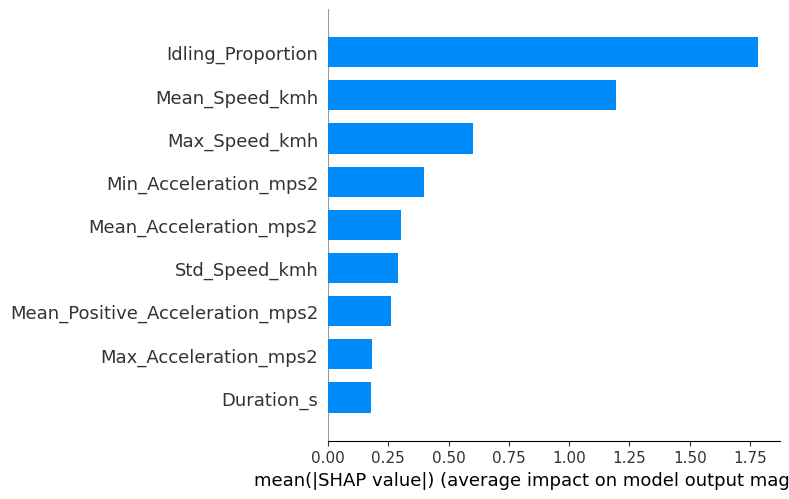

In [79]:
# ==========================================================
# Stage 11.6 - SHAP Bar Plot
# ==========================================================

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    show=False
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "SHAP_Bar.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [80]:
# ============================================================
# Stage 11.6 - Mean Absolute SHAP Importance
# ============================================================

shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("SHAP FEATURE IMPORTANCE")
print("=" * 60)

display(shap_importance)

SHAP FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP
0,Idling_Proportion,1.784968
1,Mean_Speed_kmh,1.195918
2,Max_Speed_kmh,0.602312
3,Min_Acceleration_mps2,0.398394
4,Mean_Acceleration_mps2,0.302460
5,Std_Speed_kmh,0.289519
6,Mean_Positive_Acceleration_mps2,0.262500
7,Max_Acceleration_mps2,0.180584
8,Duration_s,0.178111


## Stage 11.7 - SHAP Dependence Plot

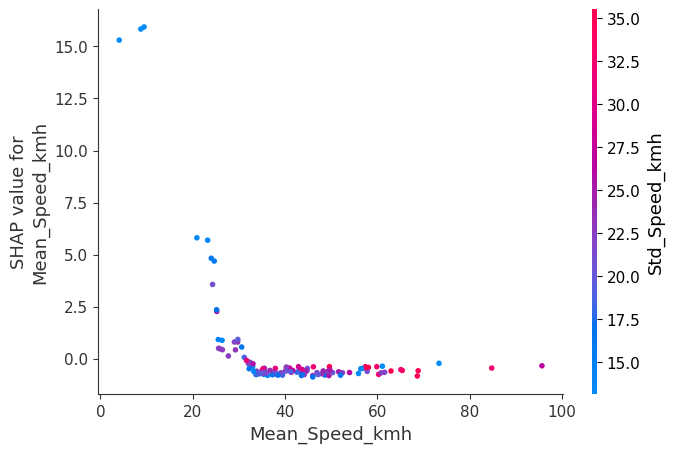

In [81]:
# ==========================================================
# Stage 11.7 - SHAP Dependence Plot
# ==========================================================

shap.dependence_plot(
    "Mean_Speed_kmh",
    shap_values,
    X_test
)

## Stage 11.8 - Waterfall Plot

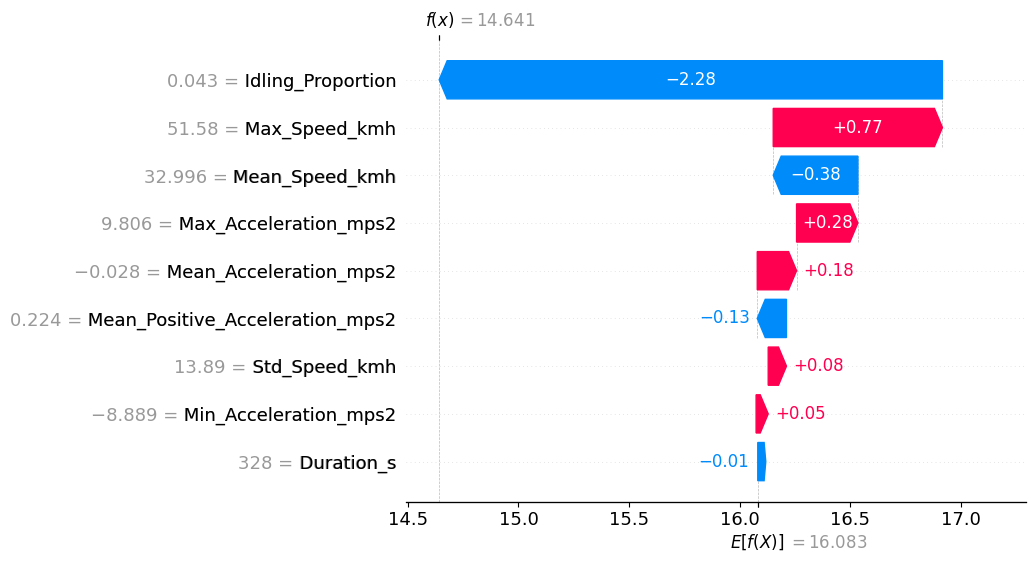

In [82]:
import numpy as np

# ==========================================================
# Stage 11.8 - Waterfall Plot
# ==========================================================

shap.plots.waterfall(

    shap.Explanation(

        values=shap_values[0],

        base_values=float(np.ravel(explainer.expected_value)[0]),

        data=X_test.iloc[0],

        feature_names=X_test.columns

    )

)

## Stage 11.8 - Waterfall Plot (SHAP 0.52) the explanation 


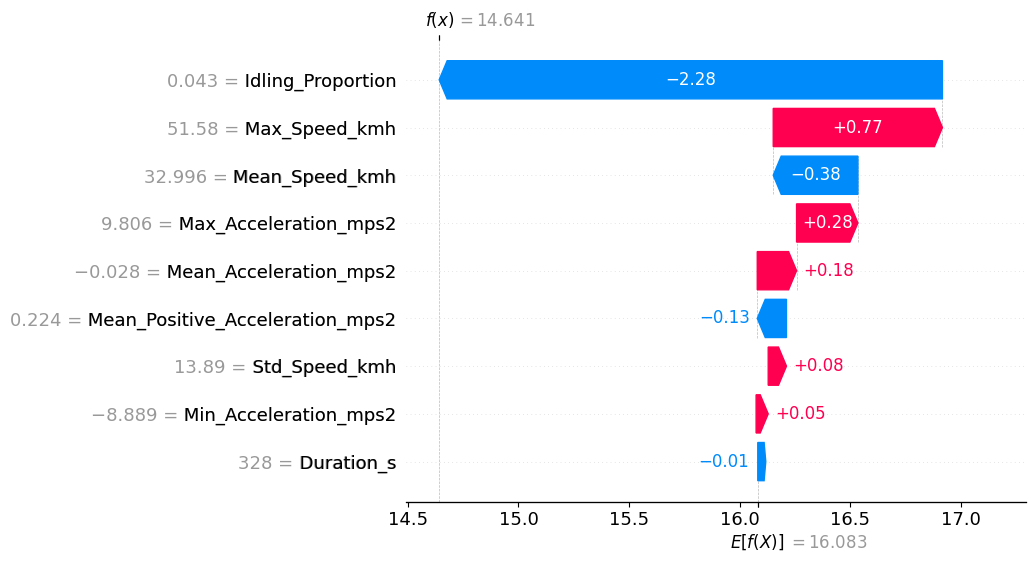

In [83]:
# ==========================================================
# Stage 11.8 - Waterfall Plot (SHAP 0.52)
# ==========================================================

explanation = explainer(X_test)

shap.plots.waterfall(
    explanation[0]
)

## Idling_Proportion is actually my most influential feature.

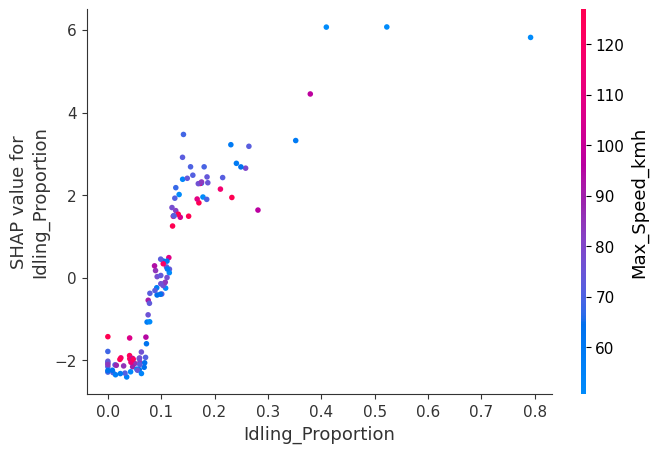

In [84]:
shap.dependence_plot(
    "Idling_Proportion",
    shap_values,
    X_test
)

## Stage 12 — Export Results


## Stage 12.1 - Create Output Folders

In [85]:
# ==========================================================
# Stage 12.1 - Create Output Folders
# ==========================================================

from pathlib import Path

RESULTS_DIR = Path("C:/Projects/DS7010_Dissertation/06-Results")
MODELS_DIR = RESULTS_DIR / "Models"
METRICS_DIR = RESULTS_DIR / "Metrics"
PREDICTIONS_DIR = RESULTS_DIR / "Predictions"
SHAP_DIR = RESULTS_DIR / "SHAP"

for folder in [
    MODELS_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    SHAP_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


## Stage 12.2 - Save Final Model

In [86]:
import joblib

In [87]:
# ==========================================================
# Stage 12.2 - Save Final Model
# ==========================================================

joblib.dump(
    best_rf,
    MODELS_DIR / "Final_Optuna_RandomForest.pkl"
)

print("Final model saved.")

Final model saved.


In [88]:
# Check whether the saved Optuna model exists

model_path = MODELS_DIR / "Final_Optuna_RandomForest.pkl"

print("Saved Optuna model exists:", model_path.exists())

Saved Optuna model exists: True


In [89]:
# ==========================================================
# Step 50 - Load Saved Optuna Random Forest
# ==========================================================

import joblib

best_rf = joblib.load(model_path)

print("Optuna Random Forest loaded successfully.")
print("Model type:", type(best_rf).__name__)
print("Number of input features:", best_rf.n_features_in_)
print("Feature names:", best_rf.feature_names_in_.tolist())

Optuna Random Forest loaded successfully.
Model type: RandomForestRegressor
Number of input features: 9
Feature names: ['Mean_Speed_kmh', 'Max_Speed_kmh', 'Std_Speed_kmh', 'Mean_Acceleration_mps2', 'Max_Acceleration_mps2', 'Min_Acceleration_mps2', 'Mean_Positive_Acceleration_mps2', 'Idling_Proportion', 'Duration_s']


In [90]:
# ==========================================================
# Step 51 - Reconstruct Original Train/Test Split
# ==========================================================

from sklearn.model_selection import train_test_split

# Use the exact feature names stored in the trained model
feature_columns = best_rf.feature_names_in_.tolist()

X = master[feature_columns]
y = master["Energy_Consumption_kWh_100km"]
dataset_labels = master["Dataset"]

X_train, X_test, y_train, y_test, train_dataset, test_dataset = (
    train_test_split(
        X,
        y,
        dataset_labels,
        test_size=0.20,
        random_state=42,
        stratify=dataset_labels
    )
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining distribution:")
print(train_dataset.value_counts())

print("\nTesting distribution:")
print(test_dataset.value_counts())

Training samples: 460
Testing samples : 115

Training distribution:
Dataset
VED        391
BMW         54
ARGONNE     15
Name: count, dtype: int64

Testing distribution:
Dataset
VED        97
BMW        14
ARGONNE     4
Name: count, dtype: int64


In [91]:
# ==========================================================
# Step 52 - Evaluate Recovered Optuna Random Forest
# ==========================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
import numpy as np

# Predict using the saved model
recovered_predictions = best_rf.predict(X_test)

# Calculate holdout metrics
recovered_mae = mean_absolute_error(
    y_test, recovered_predictions
)

recovered_rmse = np.sqrt(
    mean_squared_error(y_test, recovered_predictions)
)

recovered_r2 = r2_score(
    y_test, recovered_predictions
)

recovered_mape = mean_absolute_percentage_error(
    y_test, recovered_predictions
) * 100

print("=" * 60)
print("RECOVERED OPTUNA RANDOM FOREST")
print("=" * 60)

print(f"MAE  : {recovered_mae:.4f}")
print(f"RMSE : {recovered_rmse:.4f}")
print(f"R²   : {recovered_r2:.4f}")
print(f"MAPE : {recovered_mape:.2f}%")

RECOVERED OPTUNA RANDOM FOREST
MAE  : 4.2640
RMSE : 6.5641
R²   : -0.2720
MAPE : 28.05%


## Stage 12.3 - Export Predictions

In [92]:
# ==========================================================
# Stage 12.3 - Export Predictions
# ==========================================================

prediction_table = pd.DataFrame({

    "Actual": y_test,

    "Predicted": final_predictions,

    "Absolute_Error":
    np.abs(
        y_test -
        final_predictions
    )

})

display(prediction_table.head())

prediction_table.to_csv(

    PREDICTIONS_DIR /
    "Final_Predictions.csv",

    index=False

)

print("Predictions exported.")

,Actual,Predicted,Absolute_Error
98,11.145313,14.641391,3.496078
85,19.822085,15.288610,4.533475
570,19.260553,47.120589,27.860037
80,19.254731,18.183812,1.070919
200,15.570998,19.642195,4.071197


Predictions exported.


## Stage 12.4 - Export SHAP Importance

In [93]:
# ==========================================================
# Stage 12.4 - Export SHAP Importance
# ==========================================================

shap_importance = pd.DataFrame({

    "Feature": X_test.columns,

    "Mean_Absolute_SHAP":

    np.abs(shap_values).mean(axis=0)

})

shap_importance = shap_importance.sort_values(

    by="Mean_Absolute_SHAP",

    ascending=False

)

display(shap_importance)

shap_importance.to_csv(

    SHAP_DIR / "SHAP_Feature_Importance.csv",

    index=False

)

print("SHAP importance exported.")

,Feature,Mean_Absolute_SHAP
7,Idling_Proportion,1.784968
0,Mean_Speed_kmh,1.195918
1,Max_Speed_kmh,0.602312
5,Min_Acceleration_mps2,0.398394
3,Mean_Acceleration_mps2,0.302460
2,Std_Speed_kmh,0.289519
6,Mean_Positive_Acceleration_mps2,0.262500
4,Max_Acceleration_mps2,0.180584
8,Duration_s,0.178111


SHAP importance exported.


## Stage 12.5 - Export Final Metrics

In [94]:
# ==========================================================
# Stage 12.5 - Export Final Metrics
# ==========================================================

final_metrics = pd.DataFrame({

    "Metric":[

        "MAE",

        "RMSE",

        "Test_R2",

        "Mean_CV_R2"

    ],

    "Value":[

        final_mae,

        final_rmse,

        final_r2,

        final_cv_scores.mean()

    ]

})

display(final_metrics)

final_metrics.to_csv(

    METRICS_DIR / "Final_Model_Metrics.csv",

    index=False

)

print("Metrics exported.")

,Metric,Value
0,MAE,4.263995
1,RMSE,6.564112
2,Test_R2,-0.272030
3,Mean_CV_R2,0.245674


Metrics exported.


## Stage 12.6 - Final Project Summary

In [95]:
# ==========================================================
# Stage 12.6 - Final Project Summary
# ==========================================================

print("="*70)

print("FINAL MACHINE LEARNING PIPELINE")

print("="*70)

print()

print("Dataset")

print("-------")

print(f"Total samples : {len(master)}")

print(f"Features      : {X.shape[1]}")

print()

print("Final Model")

print("-----------")

print("Random Forest (Optuna Optimized)")

print()

print("Performance")

print("-----------")

print(f"MAE          : {final_mae:.4f}")

print(f"RMSE         : {final_rmse:.4f}")

print(f"Test R²      : {final_r2:.4f}")

print(f"Mean CV R²   : {final_cv_scores.mean():.4f}")

print()

print("Outputs saved to")

print("----------------")

print(MODELS_DIR)

print(METRICS_DIR)

print(PREDICTIONS_DIR)

print(SHAP_DIR)

print()

print("="*70)

print("PIPELINE COMPLETE")

print("="*70)

FINAL MACHINE LEARNING PIPELINE

Dataset
-------
Total samples : 575
Features      : 9

Final Model
-----------
Random Forest (Optuna Optimized)

Performance
-----------
MAE          : 4.2640
RMSE         : 6.5641
Test R²      : -0.2720
Mean CV R²   : 0.2457

Outputs saved to
----------------
C:\Projects\DS7010_Dissertation\06-Results\Models
C:\Projects\DS7010_Dissertation\06-Results\Metrics
C:\Projects\DS7010_Dissertation\06-Results\Predictions
C:\Projects\DS7010_Dissertation\06-Results\SHAP

PIPELINE COMPLETE


## Stage 13 — Proposal Alignment and Additional Validation


In [96]:
# ==========================================================
# Stage 13.1 - Inspect Available Columns
# ==========================================================

print("Columns in the master dataset:\n")

for column in master.columns:
    print("-", column)

Columns in the master dataset:

- Mean_Speed_kmh
- Max_Speed_kmh
- Std_Speed_kmh
- Mean_Acceleration_mps2
- Max_Acceleration_mps2
- Min_Acceleration_mps2
- Mean_Positive_Acceleration_mps2
- Idling_Proportion
- Duration_s
- Energy_Consumption_kWh_100km
- Dataset


## Stage 13.2a - Check Prediction Variables

In [97]:
# ==========================================================
# Stage 13.2a - Check Prediction Variables
# ==========================================================

variables = [
    "predictions",
    "y_pred",
    "y_pred_lr",
    "y_pred_rf",
    "y_pred_rf_tuned",
    "y_pred_xgb",
    "y_pred_xgb_reg",
    "final_predictions"
]

for var in variables:
    if var in globals():
        print(f"✓ {var}")
    else:
        print(f"✗ {var}")

✗ predictions
✗ y_pred
✓ y_pred_lr
✓ y_pred_rf
✓ y_pred_rf_tuned
✓ y_pred_xgb
✗ y_pred_xgb_reg
✓ final_predictions


## Stage 13.2b - Check Final Model Variables

In [98]:
# ==========================================================
# Stage 13.2b - Check Final Model Variables
# ==========================================================

variables = [
    "best_rf",
    "rf_model_tuned",
    "rf_model",
    "final_predictions",
    "y_pred_rf",
    "y_pred_rf_tuned"
]

for var in variables:
    if var in globals():
        print(f"✓ {var}")
    else:
        print(f"✗ {var}")

✓ best_rf
✓ rf_model_tuned
✓ rf_model
✓ final_predictions
✓ y_pred_rf
✓ y_pred_rf_tuned


### # Stage 13.2 - Calculate MAPE Safely

In [99]:
# ==========================================================
# Stage 13.2 - Calculate MAPE Safely
# ==========================================================

from sklearn.metrics import mean_absolute_percentage_error

# Recalculate predictions directly from each trained model
lr_predictions = linear_model.predict(X_test)

rf_manual_predictions = rf_model_tuned.predict(X_test)

xgb_regularized_predictions = (
    xgb_model_regularized.predict(X_test)
)

rf_optuna_predictions = best_rf.predict(X_test)

# Calculate MAPE
lr_mape = mean_absolute_percentage_error(
    y_test,
    lr_predictions
) * 100

rf_manual_mape = mean_absolute_percentage_error(
    y_test,
    rf_manual_predictions
) * 100

xgb_regularized_mape = mean_absolute_percentage_error(
    y_test,
    xgb_regularized_predictions
) * 100

rf_optuna_mape = mean_absolute_percentage_error(
    y_test,
    rf_optuna_predictions
) * 100

print("=" * 60)
print("MAPE RESULTS")
print("=" * 60)

print(f"Linear Regression              : {lr_mape:.2f}%")
print(f"Random Forest (Manual)         : {rf_manual_mape:.2f}%")
print(f"XGBoost (Regularized)          : {xgb_regularized_mape:.2f}%")
print(f"Random Forest (Optuna)         : {rf_optuna_mape:.2f}%")

MAPE RESULTS
Linear Regression              : 30.08%
Random Forest (Manual)         : 26.97%
XGBoost (Regularized)          : 27.74%
Random Forest (Optuna)         : 28.05%


### Stage 13.3 — Speed-Based Baseline Model

###
Stage 13.3.1 - Create Speed Baseline Dataset

In [100]:
# ==========================================================
# Stage 13.3.1 - Create Speed Baseline Dataset
# ==========================================================

baseline_features = [

    "Mean_Speed_kmh",

    "Duration_s"

]

X_baseline = master[baseline_features]

y_baseline = master["Energy_Consumption_kWh_100km"]

print("Baseline Features")

print(X_baseline.head())

print()

print("Shape:", X_baseline.shape)

Baseline Features
   Mean_Speed_kmh  Duration_s
0       35.550077       106.2
1       22.925093       460.4
2       19.378746       370.3
3       26.365563       313.7
4       24.035848       382.2

Shape: (575, 2)


### Stage 13.3.2 - Train/Test Split

In [101]:
# ==========================================================
# Stage 13.3.2 - Train/Test Split
# ==========================================================

X_train_base, X_test_base, y_train_base, y_test_base = train_test_split(

    X_baseline,

    y_baseline,

    test_size=0.20,

    random_state=42

)

print("Training:", len(X_train_base))

print("Testing :", len(X_test_base))

Training: 460
Testing : 115


### Stage 13.3.3 - Train Baseline Linear Regression

In [102]:
# ==========================================================
# Stage 13.3.3 - Train Baseline Linear Regression
# ==========================================================

baseline_model = LinearRegression()

baseline_model.fit(

    X_train_base,

    y_train_base

)

baseline_predictions = baseline_model.predict(

    X_test_base

)

print("Baseline model trained.")

Baseline model trained.


### Stage 13.3.4 - Evaluate Baseline

In [103]:
# ==========================================================
# Stage 13.3.4 - Evaluate Baseline
# ==========================================================

baseline_mae = mean_absolute_error(

    y_test_base,

    baseline_predictions

)

baseline_rmse = np.sqrt(

    mean_squared_error(

        y_test_base,

        baseline_predictions

    )

)

baseline_r2 = r2_score(

    y_test_base,

    baseline_predictions

)

baseline_mape = mean_absolute_percentage_error(

    y_test_base,

    baseline_predictions

) * 100

print("="*60)

print("SPEED-ONLY BASELINE RESULTS")

print("="*60)

print(f"MAE   : {baseline_mae:.4f}")

print(f"RMSE  : {baseline_rmse:.4f}")

print(f"R²    : {baseline_r2:.4f}")

print(f"MAPE  : {baseline_mape:.2f}%")

SPEED-ONLY BASELINE RESULTS
MAE   : 5.3032
RMSE  : 8.8770
R²    : 0.0958
MAPE  : 47.59%


### Stage 13.4 — Stacking Ensemble

### Stage 13.4.1 - Import Stacking Regressor

In [104]:
# ==========================================================
# Stage 13.4.1 - Import Stacking Regressor
# ==========================================================

from sklearn.ensemble import StackingRegressor

print("StackingRegressor imported successfully.")

StackingRegressor imported successfully.


#### Stage 13.4.2 - Define Base Models


In [105]:
# ==========================================================
# Stage 13.4.2 - Define Base Models
# ==========================================================

stacking_estimators = [
    (
        "random_forest",
        RandomForestRegressor(
            n_estimators=200,
            max_depth=6,
            min_samples_split=10,
            min_samples_leaf=5,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )
    ),
    (
        "xgboost",
        XGBRegressor(
            n_estimators=100,
            max_depth=2,
            learning_rate=0.05,
            subsample=0.7,
            colsample_bytree=0.7,
            min_child_weight=10,
            reg_alpha=1.0,
            reg_lambda=5.0,
            gamma=1.0,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )
    )
]

print("Base models defined.")

Base models defined.


#### Stage 13.4.3 - Create Stacking Ensemble

In [106]:
# ==========================================================
# Stage 13.4.3 - Create Stacking Ensemble
# ==========================================================

stacking_model = StackingRegressor(
    estimators=stacking_estimators,
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=-1,
    passthrough=False
)

print("Stacking ensemble created.")

Stacking ensemble created.


### Stage 13.4.4 - Train Stacking Ensemble

In [107]:
# ==========================================================
# Stage 13.4.4 - Train Stacking Ensemble
# ==========================================================

stacking_model.fit(
    X_train,
    y_train
)

print("Stacking ensemble trained successfully.")

Stacking ensemble trained successfully.


### Stage 13.4.5 - Stacking Predictions

In [108]:
# ==========================================================
# Stage 13.4.5 - Stacking Predictions
# ==========================================================

stacking_predictions = stacking_model.predict(
    X_test
)

print("Stacking predictions completed.")

Stacking predictions completed.


#### Stage 13.4.6 - Evaluate Stacking Ensemble

In [109]:
# ==========================================================
# Stage 13.4.6 - Evaluate Stacking Ensemble
# ==========================================================

stacking_mae = mean_absolute_error(
    y_test,
    stacking_predictions
)

stacking_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        stacking_predictions
    )
)

stacking_r2 = r2_score(
    y_test,
    stacking_predictions
)

stacking_mape = mean_absolute_percentage_error(
    y_test,
    stacking_predictions
) * 100

print("=" * 60)
print("STACKING ENSEMBLE RESULTS")
print("=" * 60)

print(f"MAE   : {stacking_mae:.4f}")
print(f"RMSE  : {stacking_rmse:.4f}")
print(f"R²    : {stacking_r2:.4f}")
print(f"MAPE  : {stacking_mape:.2f}%")

STACKING ENSEMBLE RESULTS
MAE   : 4.0895
RMSE  : 5.9910
R²    : -0.0596
MAPE  : 27.29%


### Stage 13.4.7 - Stacking Cross Validation

In [110]:
# ==========================================================
# Stage 13.4.7 - Stacking Cross Validation
# ==========================================================

stacking_cv_scores = cross_val_score(
    stacking_model,
    X,
    y,
    cv=cv,
    scoring="r2",
    n_jobs=-1
)

print("Stacking fold scores:")
print(stacking_cv_scores)

print("\nMean CV R²:")
print(stacking_cv_scores.mean())

print("\nCV standard deviation:")
print(stacking_cv_scores.std())

Stacking fold scores:
[0.22388464 0.19593469 0.3258038  0.09103464 0.21855299]

Mean CV R²:
0.2110421544158032

CV standard deviation:
0.0748620277342591


In [111]:
stacking_cv_scores = cross_val_score(
    stacking_model,
    X,
    y,
    cv=cv,
    scoring="r2",
    n_jobs=-1
)

print(stacking_cv_scores)
print(stacking_cv_scores.mean())
print(stacking_cv_scores.std())

[0.22388464 0.19593469 0.3258038  0.09103464 0.21855299]
0.21104215441580315
0.0748620277342591


## Stage 14 — Cross-Dataset Generalization Validation

# Stage 14.1 - Check Dataset Labels

In [112]:
# ==========================================================
# Stage 14.1 - Check Dataset Labels
# ==========================================================

print(master["Dataset"].value_counts())

Dataset
VED        488
BMW         68
ARGONNE     19
Name: count, dtype: int64


# Stage 14.2 - Train on VED + ARGONNE
#               Test on BMW

In [113]:
# ==========================================================
# Stage 14.2 - Train on VED + ARGONNE
#               Test on BMW
# ==========================================================

# Training data
train_data = master[
    master["Dataset"].isin(["VED", "ARGONNE"])
]

# Testing data
test_data = master[
    master["Dataset"] == "BMW"
]

print("Training samples:", len(train_data))
print("Testing samples :", len(test_data))


Training samples: 507
Testing samples : 68


# Stage 14.3 - Prepare Features and Target

In [114]:
# ==========================================================
# Stage 14.3 - Prepare Features and Target
# ==========================================================

FEATURES = [
    "Mean_Speed_kmh",
    "Max_Speed_kmh",
    "Std_Speed_kmh",
    "Mean_Acceleration_mps2",
    "Max_Acceleration_mps2",
    "Min_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion",
    "Duration_s"
]

TARGET = "Energy_Consumption_kWh_100km"

X_train_cross = train_data[FEATURES]
y_train_cross = train_data[TARGET]

X_test_cross = test_data[FEATURES]
y_test_cross = test_data[TARGET]

print("X_train shape:", X_train_cross.shape)
print("y_train shape:", y_train_cross.shape)
print("X_test shape :", X_test_cross.shape)
print("y_test shape :", y_test_cross.shape)

X_train shape: (507, 9)
y_train shape: (507,)
X_test shape : (68, 9)
y_test shape : (68,)


# Stage 14.4 - Train Optuna Random Forest

In [115]:
# ==========================================================
# Stage 14.4 - Train Cross-Dataset Random Forest
# ==========================================================

# Fixed hyperparameters, independent of the mixed-dataset
# Optuna optimisation involving BMW observations.

cross_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=6,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

cross_rf.fit(X_train_cross, y_train_cross)

print("Cross-dataset Random Forest trained successfully.")

Cross-dataset Random Forest trained successfully.


# Stage 14.5 - Predict BMW Dataset

In [116]:
# ==========================================================
# Stage 14.5 - Predict BMW Dataset
# ==========================================================

cross_predictions = cross_rf.predict(
    X_test_cross
)

print("Predictions completed.")

print()

print("First five predictions:")

print(cross_predictions[:5])

Predictions completed.

First five predictions:
[17.93430073 15.47967713 15.27362053 19.51214072 13.90427489]


# Stage 14.6 - Evaluate Cross-Dataset Performance

In [117]:
# ==========================================================
# Stage 14.6 - Evaluate Cross-Dataset Performance
# ==========================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

cross_mae = mean_absolute_error(
    y_test_cross,
    cross_predictions
)

cross_rmse = np.sqrt(
    mean_squared_error(
        y_test_cross,
        cross_predictions
    )
)

cross_r2 = r2_score(
    y_test_cross,
    cross_predictions
)

cross_mape = mean_absolute_percentage_error(
    y_test_cross,
    cross_predictions
) * 100

print("="*60)
print("CROSS-DATASET VALIDATION")
print("="*60)

print(f"MAE   : {cross_mae:.4f}")
print(f"RMSE  : {cross_rmse:.4f}")
print(f"R²    : {cross_r2:.4f}")
print(f"MAPE  : {cross_mape:.2f}%")

CROSS-DATASET VALIDATION
MAE   : 3.3652
RMSE  : 4.2876
R²    : -0.5584
MAPE  : 21.75%


# Stage 14.7 - Compare with Original Results

In [118]:
# ==========================================================
# Stage 14.7 - Compare Validation Experiments
# ==========================================================

comparison = pd.DataFrame({
    "Validation": [
        "Stratified mixed-dataset holdout",
        "Train: VED+ARGONNE → Test: BMW"
    ],
    "MAE (kWh/100 km)": [
        recovered_mae,
        cross_mae
    ],
    "RMSE (kWh/100 km)": [
        recovered_rmse,
        cross_rmse
    ],
    "Test R²": [
        recovered_r2,
        cross_r2
    ],
    "MAPE (%)": [
        recovered_mape,
        cross_mape
    ]
})

display(comparison)

,Validation,MAE (kWh/100 km),RMSE (kWh/100 km),Test R²,MAPE (%)
0,Stratified mixed-dataset holdout,4.263995,6.564112,-0.272030,28.050401
1,Train: VED+ARGONNE → Test: BMW,3.365187,4.287610,-0.558447,21.749343


# Stage 14.7 - Cross-Dataset Validation: Test on VED new

In [119]:
# ============================================================
# Stage 14.7 - Cross-Dataset Validation: Test on VED
# ============================================================

train_data_ved = master[
    master["Dataset"].isin(["BMW", "ARGONNE"])
]

test_data_ved = master[
    master["Dataset"] == "VED"
]

X_train_ved = train_data_ved[FEATURES]
y_train_ved = train_data_ved[TARGET]

X_test_ved = test_data_ved[FEATURES]
y_test_ved = test_data_ved[TARGET]

print("Training samples:", len(train_data_ved))
print("Testing samples:", len(test_data_ved))

Training samples: 87
Testing samples: 488


# Check which Optuna result variables exist

In [120]:
# Check which Optuna result variables exist

variables = [
    "rf_optuna_mae",
    "rf_optuna_rmse",
    "rf_optuna_r2",
    "rf_optuna_mape",
    "best_rf_mae",
    "best_rf_rmse",
    "best_rf_r2",
    "best_rf_mape"
]

for var in variables:
    if var in globals():
        print(f"✓ {var} = {globals()[var]}")
    else:
        print(f"✗ {var}")

✓ rf_optuna_mae = 4.263994764717694
✓ rf_optuna_rmse = 6.564112151214615
✓ rf_optuna_r2 = -0.27202950245838786
✓ rf_optuna_mape = 28.05040133270969
✗ best_rf_mae
✗ best_rf_rmse
✗ best_rf_r2
✗ best_rf_mape


# Stage 14.7a - Check Final Optuna Metric Variables

In [121]:
# ==========================================================
# Stage 14.7a - Check Final Optuna Metric Variables
# ==========================================================

variables = [
    "final_mae",
    "final_rmse",
    "final_r2",
    "final_mape",
    "rf_optuna_mape"
]

for var in variables:
    if var in globals():
        print(f"✓ {var} = {globals()[var]}")
    else:
        print(f"✗ {var}")

✓ final_mae = 4.263994764717694
✓ final_rmse = 6.564112151214615
✓ final_r2 = -0.27202950245838786
✗ final_mape
✓ rf_optuna_mape = 28.05040133270969


# Stage 14.7b - Compare Validation Strategies

In [122]:
# ==========================================================
# Stage 14.7b - Compare Validation Strategies
# ==========================================================

comparison = pd.DataFrame({
    "Validation": [
        "Random Train/Test",
        "Train: VED + ARGONNE → Test: BMW"
    ],

    "MAE": [
        final_mae,
        cross_mae
    ],

    "RMSE": [
        final_rmse,
        cross_rmse
    ],

    "Test_R2": [
        final_r2,
        cross_r2
    ],

    "MAPE": [
        rf_optuna_mape,
        cross_mape
    ]
})

display(comparison)

,Validation,MAE,RMSE,Test_R2,MAPE
0,Random Train/Test,4.263995,6.564112,-0.272030,28.050401
1,Train: VED + ARGONNE → Test: BMW,3.365187,4.287610,-0.558447,21.749343


In [123]:
random_state=42

# Stage 14.8.1 - Train on BMW + ARGONNE
#                 Test on VED

In [124]:
# ==========================================================
# Stage 14.8.1 - Train on BMW + ARGONNE
#                 Test on VED
# ==========================================================

train_data_2 = master[
    master["Dataset"].isin(["BMW", "ARGONNE"])
]

test_data_2 = master[
    master["Dataset"] == "VED"
]

print("Training samples:", len(train_data_2))
print("Testing samples :", len(test_data_2))

Training samples: 87
Testing samples : 488


# Stage 14.8.2 - Prepare Features and Target

In [125]:
# ==========================================================
# Stage 14.8.2 - Prepare Features and Target
# ==========================================================

X_train_cross2 = train_data_2[FEATURES]
y_train_cross2 = train_data_2[TARGET]

X_test_cross2 = test_data_2[FEATURES]
y_test_cross2 = test_data_2[TARGET]

print("X_train:", X_train_cross2.shape)
print("y_train:", y_train_cross2.shape)

print("X_test :", X_test_cross2.shape)
print("y_test :", y_test_cross2.shape)

X_train: (87, 9)
y_train: (87,)
X_test : (488, 9)
y_test : (488,)


# Stage 14.8.3 - Train Model

In [126]:
# ==========================================================
# Stage 14.8.3 - Train Model
# ==========================================================

cross_rf2 = RandomForestRegressor(

    n_estimators=433,
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=5,
    max_features="sqrt",

    random_state=42,
    n_jobs=-1
)

cross_rf2.fit(
    X_train_cross2,
    y_train_cross2
)

print("Model trained successfully.")

Model trained successfully.


# Stage 14.8.4 - Predictions

In [127]:
# ==========================================================
# Stage 14.8.4 - Predictions
# ==========================================================

cross_predictions2 = cross_rf2.predict(
    X_test_cross2
)

print("Predictions completed.")

print(cross_predictions2[:5])

Predictions completed.
[14.90941172 15.41286728 15.37785366 15.31555267 15.46815146]


# Stage 14.8.5 - Evaluation

In [128]:
# ==========================================================
# Stage 14.8.5 - Evaluation
# ==========================================================

cross2_mae = mean_absolute_error(
    y_test_cross2,
    cross_predictions2
)

cross2_rmse = np.sqrt(
    mean_squared_error(
        y_test_cross2,
        cross_predictions2
    )
)

cross2_r2 = r2_score(
    y_test_cross2,
    cross_predictions2
)

cross2_mape = mean_absolute_percentage_error(
    y_test_cross2,
    cross_predictions2
) * 100

print("="*60)
print("CROSS-DATASET VALIDATION (Experiment 2)")
print("="*60)

print(f"MAE   : {cross2_mae:.4f}")
print(f"RMSE  : {cross2_rmse:.4f}")
print(f"R²    : {cross2_r2:.4f}")
print(f"MAPE  : {cross2_mape:.2f}%")

CROSS-DATASET VALIDATION (Experiment 2)
MAE   : 5.0084
RMSE  : 7.5417
R²    : -0.0189
MAPE  : 36.97%


In [129]:
# ============================================================
# Final RF Performance by Dataset
# ============================================================

test_results_rf = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": final_predictions,
    "Dataset": test_dataset.values
})

dataset_results = []

for dataset_name, group in test_results_rf.groupby("Dataset"):

    mae_ds = mean_absolute_error(
        group["Actual"],
        group["Predicted"]
    )

    rmse_ds = np.sqrt(
        mean_squared_error(
            group["Actual"],
            group["Predicted"]
        )
    )

    # R² is unreliable for extremely small test groups,
    # especially Argonne (only 4 observations)
    if len(group) >= 5:
        r2_ds = r2_score(
            group["Actual"],
            group["Predicted"]
        )
    else:
        r2_ds = np.nan

    dataset_results.append({
        "Dataset": dataset_name,
        "N_Test": len(group),
        "MAE": mae_ds,
        "RMSE": rmse_ds,
        "R2": r2_ds
    })

dataset_results = pd.DataFrame(dataset_results)

print("OPTIMIZED RANDOM FOREST — PERFORMANCE BY DATASET")
print("=" * 60)

display(dataset_results)

OPTIMIZED RANDOM FOREST — PERFORMANCE BY DATASET


,Dataset,N_Test,MAE,RMSE,R2
0,ARGONNE,4,10.841575,14.894855,NaN
1,BMW,14,2.622211,2.924422,-0.040735
2,VED,97,4.229713,6.379665,-0.066200


## new TEST 09.08.2026

# Stage 14.8 - Train on BMW + ARGONNE, Test on VED

In [130]:
# ============================================================
# Stage 14.8 - Train on BMW + ARGONNE, Test on VED
# ============================================================

cross_rf_ved = RandomForestRegressor(
    **study.best_params,
    random_state=42,
    n_jobs=-1
)

cross_rf_ved.fit(
    X_train_ved,
    y_train_ved
)

pred_ved = cross_rf_ved.predict(X_test_ved)

print("VED predictions completed.")

VED predictions completed.


# Stage 14.9 - Evaluate VED Cross-Dataset Performance 

In [131]:
# ============================================================
# Stage 14.9 - Evaluate VED Cross-Dataset Performance
# ============================================================

ved_cross_mae = mean_absolute_error(
    y_test_ved,
    pred_ved
)

ved_cross_rmse = np.sqrt(
    mean_squared_error(
        y_test_ved,
        pred_ved
    )
)

ved_cross_r2 = r2_score(
    y_test_ved,
    pred_ved
)

ved_cross_mape = mean_absolute_percentage_error(
    y_test_ved,
    pred_ved
) * 100

print("=" * 60)
print("CROSS-DATASET VALIDATION — TEST ON VED")
print("=" * 60)

print(f"MAE  : {ved_cross_mae:.4f}")
print(f"RMSE : {ved_cross_rmse:.4f}")
print(f"R²   : {ved_cross_r2:.4f}")
print(f"MAPE : {ved_cross_mape:.2f}%")

CROSS-DATASET VALIDATION — TEST ON VED
MAE  : 4.9796
RMSE : 7.5450
R²   : -0.0198
MAPE : 36.44%


# Stage 14.10 - Cross-Dataset Validation: Test on ARGONNE

In [132]:
# ============================================================
# Stage 14.10 - Cross-Dataset Validation: Test on ARGONNE
# ============================================================

train_data_argonne = master[
    master["Dataset"].isin(["VED", "BMW"])
]

test_data_argonne = master[
    master["Dataset"] == "ARGONNE"
]

X_train_argonne = train_data_argonne[FEATURES]
y_train_argonne = train_data_argonne[TARGET]

X_test_argonne = test_data_argonne[FEATURES]
y_test_argonne = test_data_argonne[TARGET]

print("Training samples:", len(train_data_argonne))
print("Testing samples:", len(test_data_argonne))

Training samples: 556
Testing samples: 19


In [133]:
cross_rf_argonne = RandomForestRegressor(
    **study.best_params,
    random_state=42,
    n_jobs=-1
)

cross_rf_argonne.fit(
    X_train_argonne,
    y_train_argonne
)

pred_argonne = cross_rf_argonne.predict(
    X_test_argonne
)

print("Argonne predictions completed.")

Argonne predictions completed.


In [134]:
argonne_cross_mae = mean_absolute_error(
    y_test_argonne,
    pred_argonne
)

argonne_cross_rmse = np.sqrt(
    mean_squared_error(
        y_test_argonne,
        pred_argonne
    )
)

argonne_cross_r2 = r2_score(
    y_test_argonne,
    pred_argonne
)

argonne_cross_mape = mean_absolute_percentage_error(
    y_test_argonne,
    pred_argonne
) * 100

print("=" * 60)
print("CROSS-DATASET VALIDATION — TEST ON ARGONNE")
print("=" * 60)

print(f"MAE  : {argonne_cross_mae:.4f}")
print(f"RMSE : {argonne_cross_rmse:.4f}")
print(f"R²   : {argonne_cross_r2:.4f}")
print(f"MAPE : {argonne_cross_mape:.2f}%")

CROSS-DATASET VALIDATION — TEST ON ARGONNE
MAE  : 6.9440
RMSE : 9.4494
R²   : -0.8359
MAPE : 54.88%


In [135]:
cross_dataset_results = pd.DataFrame({
    "Test_Dataset": ["BMW", "VED", "ARGONNE"],
    "Training_Datasets": [
        "VED + ARGONNE",
        "BMW + ARGONNE",
        "VED + BMW"
    ],
    "Train_N": [507, 87, 556],
    "Test_N": [68, 488, 19],
    "MAE": [
        cross_mae,
        ved_cross_mae,
        argonne_cross_mae
    ],
    "RMSE": [
        cross_rmse,
        ved_cross_rmse,
        argonne_cross_rmse
    ],
    "R2": [
        cross_r2,
        ved_cross_r2,
        argonne_cross_r2
    ],
    "MAPE_pct": [
        cross_mape,
        ved_cross_mape,
        argonne_cross_mape
    ]
})

display(
    cross_dataset_results.round(4)
)

,Test_Dataset,Training_Datasets,Train_N,Test_N,MAE,RMSE,R2,MAPE_pct
0,BMW,VED + ARGONNE,507,68,3.3652,4.2876,-0.5584,21.7493
1,VED,BMW + ARGONNE,87,488,4.9796,7.5450,-0.0198,36.4381
2,ARGONNE,VED + BMW,556,19,6.9440,9.4494,-0.8359,54.8804


# Stage 15.1 - Final Experiment Configuration

In [136]:
# ============================================================
# Stage 15.1 - Final Experiment Configuration
# ============================================================

print("=" * 70)
print("FINAL DISSERTATION EXPERIMENT CONFIGURATION")
print("=" * 70)

print("\nMaster dataset:")
print("Observations:", len(master))
print("Features:", len(FEATURES))

print("\nDataset distribution:")
print(master["Dataset"].value_counts())

print("\nTarget:")
print(TARGET)

print("\nFinal model:")
print(best_rf)

print("\nFinal RF parameters:")
for parameter, value in best_rf.get_params().items():
    if parameter in [
        "n_estimators",
        "max_depth",
        "min_samples_split",
        "min_samples_leaf",
        "max_features",
        "random_state"
    ]:
        print(f"{parameter}: {value}")

print("\nTrain/Test:")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("=" * 70)
print("EXPERIMENT CONFIGURATION FROZEN")
print("=" * 70)

FINAL DISSERTATION EXPERIMENT CONFIGURATION

Master dataset:
Observations: 575
Features: 9

Dataset distribution:
Dataset
VED        488
BMW         68
ARGONNE     19
Name: count, dtype: int64

Target:
Energy_Consumption_kWh_100km

Final model:
RandomForestRegressor(max_depth=9, max_features='log2', min_samples_leaf=2,
                      min_samples_split=3, n_estimators=417, n_jobs=-1,
                      random_state=42)

Final RF parameters:
max_depth: 9
max_features: log2
min_samples_leaf: 2
min_samples_split: 3
n_estimators: 417
random_state: 42

Train/Test:
Training observations: 460
Testing observations: 115
EXPERIMENT CONFIGURATION FROZEN


# Stage 15.2 - Authoritative Final Test Evaluation

In [137]:
# ============================================================
# Stage 15.2 - Authoritative Final Test Evaluation
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# Predict using the frozen final model
final_predictions_frozen = best_rf.predict(X_test)

# Calculate metrics directly
final_mae_frozen = mean_absolute_error(
    y_test,
    final_predictions_frozen
)

final_rmse_frozen = np.sqrt(
    mean_squared_error(
        y_test,
        final_predictions_frozen
    )
)

final_r2_frozen = r2_score(
    y_test,
    final_predictions_frozen
)

final_mape_frozen = mean_absolute_percentage_error(
    y_test,
    final_predictions_frozen
) * 100

print("=" * 70)
print("AUTHORITATIVE FINAL RANDOM FOREST — UNTOUCHED TEST SET")
print("=" * 70)

print(f"MAE  : {final_mae_frozen:.4f} kWh/100 km")
print(f"RMSE : {final_rmse_frozen:.4f} kWh/100 km")
print(f"R²   : {final_r2_frozen:.4f}")
print(f"MAPE : {final_mape_frozen:.2f}%")

print("\nTest observations:", len(y_test))

print("=" * 70)

AUTHORITATIVE FINAL RANDOM FOREST — UNTOUCHED TEST SET
MAE  : 4.2640 kWh/100 km
RMSE : 6.5641 kWh/100 km
R²   : -0.2720
MAPE : 28.05%

Test observations: 115


# Stage 15.3 - Final Random Forest Cross-Validation

In [138]:
# ============================================================
# Stage 15.3 - Final Random Forest Cross-Validation
# ============================================================

from sklearn.model_selection import cross_val_score

final_cv_scores_frozen = cross_val_score(
    best_rf,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("=" * 70)
print("FINAL RANDOM FOREST — TRAINING-SET CROSS-VALIDATION")
print("=" * 70)

print("\nFold R² scores:")
print(final_cv_scores_frozen)

print(f"\nMean CV R² : {final_cv_scores_frozen.mean():.4f}")
print(f"CV SD      : {final_cv_scores_frozen.std():.4f}")

print("=" * 70)

FINAL RANDOM FOREST — TRAINING-SET CROSS-VALIDATION

Fold R² scores:
[ 0.37492885  0.37058464  0.43749444  0.27903638 -0.16232258]

Mean CV R² : 0.2599
CV SD      : 0.2171


# Stage 15.4 - Audit Cross-Validation Fold Composition

In [139]:
# ============================================================
# Stage 15.4 - Audit Cross-Validation Fold Composition
# ============================================================

from sklearn.model_selection import KFold

cv_audit = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

dataset_train = dataset_labels.loc[X_train.index]

for fold, (train_idx, val_idx) in enumerate(
    cv_audit.split(X_train),
    start=1
):
    val_labels = dataset_train.iloc[val_idx]

    print("=" * 60)
    print(f"FOLD {fold}")
    print(f"R²: {final_cv_scores_frozen[fold-1]:.4f}")
    print("\nValidation dataset composition:")
    print(val_labels.value_counts())

FOLD 1
R²: 0.3749

Validation dataset composition:
Dataset
VED        80
BMW         8
ARGONNE     4
Name: count, dtype: int64
FOLD 2
R²: 0.3706

Validation dataset composition:
Dataset
VED        79
BMW        10
ARGONNE     3
Name: count, dtype: int64
FOLD 3
R²: 0.4375

Validation dataset composition:
Dataset
VED        79
BMW        11
ARGONNE     2
Name: count, dtype: int64
FOLD 4
R²: 0.2790

Validation dataset composition:
Dataset
VED        76
BMW        14
ARGONNE     2
Name: count, dtype: int64
FOLD 5
R²: -0.1623

Validation dataset composition:
Dataset
VED        77
BMW        11
ARGONNE     4
Name: count, dtype: int64


# Stage 15.5 - Audit CV Fold Target Distributions


In [140]:
# ============================================================
# Stage 15.5 - Audit CV Fold Target Distributions
# ============================================================

for fold, (train_idx, val_idx) in enumerate(
    cv_audit.split(X_train),
    start=1
):
    y_fold = y_train.iloc[val_idx]

    print("=" * 60)
    print(f"FOLD {fold}")
    print(f"R²: {final_cv_scores_frozen[fold-1]:.4f}")

    print(f"Count  : {len(y_fold)}")
    print(f"Mean   : {y_fold.mean():.4f}")
    print(f"Median : {y_fold.median():.4f}")
    print(f"Std    : {y_fold.std():.4f}")
    print(f"Min    : {y_fold.min():.4f}")
    print(f"Max    : {y_fold.max():.4f}")

    print("\nTop 5 target values:")
    print(
        y_fold.sort_values(
            ascending=False
        ).head(5)
    )

FOLD 1
R²: 0.3749
Count  : 92
Mean   : 16.1288
Median : 14.7287
Std    : 6.2397
Min    : 4.0049
Max    : 37.2588

Top 5 target values:
462    37.258791
2      35.971756
49     30.750314
25     30.704980
16     27.218071
Name: Energy_Consumption_kWh_100km, dtype: float64
FOLD 2
R²: 0.3706
Count  : 92
Mean   : 15.8212
Median : 14.9652
Std    : 6.3578
Min    : 2.9966
Max    : 39.4691

Top 5 target values:
22     39.469066
20     34.446426
50     31.058370
69     30.306907
468    27.414586
Name: Energy_Consumption_kWh_100km, dtype: float64
FOLD 3
R²: 0.4375
Count  : 92
Mean   : 16.0616
Median : 14.6831
Std    : 7.1760
Min    : 3.0822
Max    : 54.3081

Top 5 target values:
23     54.308139
48     41.561471
102    33.552504
18     27.619406
195    26.172658
Name: Energy_Consumption_kWh_100km, dtype: float64
FOLD 4
R²: 0.2790
Count  : 92
Mean   : 15.9404
Median : 14.7052
Std    : 8.0863
Min    : 4.2499
Max    : 65.1097

Top 5 target values:
30     65.109691
448    38.792530
557    37.690272
1

# Stage 15.6 - Audit Worst Cross-Validation Fold

In [141]:
# ============================================================
# Stage 15.6 - Audit Worst Cross-Validation Fold
# ============================================================

from sklearn.base import clone

# Get Fold 5
folds = list(cv_audit.split(X_train))
train_idx_5, val_idx_5 = folds[4]

X_fold5_train = X_train.iloc[train_idx_5]
y_fold5_train = y_train.iloc[train_idx_5]

X_fold5_val = X_train.iloc[val_idx_5]
y_fold5_val = y_train.iloc[val_idx_5]

# Train a fresh copy of the frozen RF
fold5_model = clone(best_rf)

fold5_model.fit(
    X_fold5_train,
    y_fold5_train
)

fold5_predictions = fold5_model.predict(
    X_fold5_val
)

# Build residual table
fold5_audit = X_fold5_val.copy()

fold5_audit["Actual"] = y_fold5_val
fold5_audit["Predicted"] = fold5_predictions

fold5_audit["Absolute_Error"] = np.abs(
    fold5_audit["Actual"] -
    fold5_audit["Predicted"]
)

fold5_audit["Residual"] = (
    fold5_audit["Actual"] -
    fold5_audit["Predicted"]
)

fold5_audit["Dataset"] = dataset_train.iloc[val_idx_5].values

print("=" * 70)
print("FOLD 5 — LARGEST PREDICTION ERRORS")
print("=" * 70)

display(
    fold5_audit
    .sort_values(
        "Absolute_Error",
        ascending=False
    )
    .head(15)
)

FOLD 5 — LARGEST PREDICTION ERRORS


,Mean_Speed_kmh,Max_Speed_kmh,Std_Speed_kmh,Mean_Acceleration_mps2,Max_Acceleration_mps2,Min_Acceleration_mps2,Mean_Positive_Acceleration_mps2,Idling_Proportion,Duration_s,Actual,Predicted,Absolute_Error,Residual,Dataset
29,11.625928,29.969999,9.445854,1.204008e-02,6.222222,-6.777774,0.166863,0.297634,522.400,79.163078,32.673184,46.489895,46.489895,VED
15,36.466653,67.299995,24.525640,6.307191e-02,7.888889,-9.472222,0.232789,0.212766,578.900,44.040044,18.037841,26.002203,26.002203,VED
382,34.424296,65.409996,17.398820,-7.089333e-02,4.071429,-6.277778,0.229779,0.093750,69.000,2.846425,14.973273,12.126847,-12.126847,VED
558,72.226525,133.272664,41.516863,-1.095385e-06,4.112758,-2.194961,0.695104,0.137421,811.999,26.538541,16.682124,9.856417,9.856417,ARGONNE
87,44.301583,83.049995,26.193850,1.912224e-02,6.750001,-6.555547,0.237775,0.132388,245.700,26.164115,16.459170,9.704945,9.704945,VED
435,31.160595,55.889999,16.335468,4.099633e-03,9.500006,-6.472222,0.305417,0.086093,243.300,7.424750,16.374433,8.949683,-8.949683,VED
96,35.292801,54.399998,12.844647,-7.945776e-02,6.666663,-9.648148,0.175137,0.041131,196.500,19.289055,10.773230,8.515825,8.515825,VED
188,41.223553,71.699997,21.705402,-4.216441e-02,9.958333,-9.611119,0.192208,0.099751,420.500,23.103609,14.700798,8.402812,8.402812,VED
307,46.214730,69.010002,18.486764,7.131512e-02,8.833334,-5.020833,0.261357,0.048159,184.700,4.798158,13.146696,8.348538,-8.348538,VED
423,33.087396,67.909996,19.423259,-8.124764e-03,9.222221,-8.500004,0.234545,0.144876,462.700,24.876176,16.790754,8.085422,8.085422,VED


# Stage 15.7 - Fold 5 Sensitivity Analysis
# Diagnostic only — no observations are removed from final data

In [142]:
# ============================================================
# Stage 15.7 - Fold 5 Sensitivity Analysis
# Diagnostic only — no observations are removed from final data
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Full Fold 5
full_mae = mean_absolute_error(
    y_fold5_val,
    fold5_predictions
)

full_rmse = np.sqrt(
    mean_squared_error(
        y_fold5_val,
        fold5_predictions
    )
)

full_r2 = r2_score(
    y_fold5_val,
    fold5_predictions
)

# Identify highest target observation
max_target_index = y_fold5_val.idxmax()

mask = y_fold5_val.index != max_target_index

# Diagnostic metrics without that ONE observation
sensitivity_mae = mean_absolute_error(
    y_fold5_val.loc[mask],
    fold5_predictions[mask]
)

sensitivity_rmse = np.sqrt(
    mean_squared_error(
        y_fold5_val.loc[mask],
        fold5_predictions[mask]
    )
)

sensitivity_r2 = r2_score(
    y_fold5_val.loc[mask],
    fold5_predictions[mask]
)

print("=" * 70)
print("FOLD 5 SENSITIVITY ANALYSIS")
print("=" * 70)

print("\nFULL FOLD 5:")
print(f"MAE  : {full_mae:.4f}")
print(f"RMSE : {full_rmse:.4f}")
print(f"R²   : {full_r2:.4f}")

print("\nDIAGNOSTIC ONLY — excluding highest target:")
print(f"MAE  : {sensitivity_mae:.4f}")
print(f"RMSE : {sensitivity_rmse:.4f}")
print(f"R²   : {sensitivity_r2:.4f}")

print("\nHighest target:")
print(f"Index : {max_target_index}")
print(f"Actual: {y_fold5_val.loc[max_target_index]:.4f}")

print("\nIMPORTANT:")
print("The observation remains in the official dataset and final analysis.")

FOLD 5 SENSITIVITY ANALYSIS

FULL FOLD 5:
MAE  : 4.1123
RMSE : 7.0509
R²   : 0.3664

DIAGNOSTIC ONLY — excluding highest target:
MAE  : 3.6466
RMSE : 5.1489
R²   : 0.2579

Highest target:
Index : 29
Actual: 79.1631

IMPORTANT:
The observation remains in the official dataset and final analysis.


# Stage 15.8 - Authoritative Cross-Validation Strategy

In [143]:
# ============================================================
# Stage 15.8 - Authoritative Cross-Validation Strategy
# ============================================================

from sklearn.model_selection import KFold, cross_val_score

FINAL_CV = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

final_cv_scores = cross_val_score(
    best_rf,
    X_train,
    y_train,
    cv=FINAL_CV,
    scoring="r2",
    n_jobs=-1
)

print("=" * 70)
print("AUTHORITATIVE 5-FOLD CROSS-VALIDATION")
print("=" * 70)

for i, score in enumerate(final_cv_scores, start=1):
    print(f"Fold {i}: R² = {score:.4f}")

print()
print(f"Mean CV R² : {final_cv_scores.mean():.4f}")
print(f"CV SD      : {final_cv_scores.std():.4f}")

print("=" * 70)

AUTHORITATIVE 5-FOLD CROSS-VALIDATION
Fold 1: R² = 0.2565
Fold 2: R² = 0.1616
Fold 3: R² = 0.2739
Fold 4: R² = 0.4232
Fold 5: R² = 0.3664

Mean CV R² : 0.2963
CV SD      : 0.0908


# Stage 15.9a - Check Final Comparison Models

In [144]:
# ============================================================
# Stage 15.9a - Check Final Comparison Models
# ============================================================

models_to_check = [
    "linear_model",
    "best_rf",
    "xgb_model",
    "best_xgb",
    "stacking_model"
]

for name in models_to_check:
    if name in globals():
        print(f"✓ {name}")
    else:
        print(f"✗ {name}")

✓ linear_model
✓ best_rf
✓ xgb_model
✓ best_xgb
✓ stacking_model


# Stage 15.9b - Final Model Comparison on Same Test Set

In [145]:
# ============================================================
# Stage 15.9b - Final Model Comparison on Same Test Set
# ============================================================

final_models = {
    "Linear Regression": linear_model,
    "Random Forest (Frozen)": best_rf,
    "XGBoost (Original)": xgb_model,
    "XGBoost (Optuna)": best_xgb,
    "Stacking Ensemble": stacking_model
}

comparison_rows = []

for model_name, model in final_models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    mape = mean_absolute_percentage_error(
        y_test,
        predictions
    ) * 100

    comparison_rows.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE_pct": mape
    })

final_model_comparison = pd.DataFrame(
    comparison_rows
).sort_values(
    "MAE"
).reset_index(drop=True)

print("=" * 70)
print("FINAL MODEL COMPARISON — SAME UNTOUCHED TEST SET")
print("=" * 70)

display(
    final_model_comparison.round(4)
)

FINAL MODEL COMPARISON — SAME UNTOUCHED TEST SET


,Model,MAE,RMSE,R2,MAPE_pct
0,Stacking Ensemble,4.0895,5.9910,-0.0596,27.2851
1,XGBoost (Optuna),4.2414,6.2003,-0.1349,27.7585
2,Random Forest (Frozen),4.2640,6.5641,-0.2720,28.0504
3,Linear Regression,4.3488,6.2951,-0.1699,30.0835
4,XGBoost (Original),5.1860,8.8093,-1.2910,32.4929


# Stage 15.10 - Final Dissertation Results Package

In [146]:
# ============================================================
# Stage 15.10 - Final Dissertation Results Package
# ============================================================

final_summary = {
    "Dataset_Observations": len(master),
    "Number_of_Features": len(FEATURES),
    "Train_Observations": len(X_train),
    "Test_Observations": len(X_test),

    "Frozen_RF_MAE": final_mae_frozen,
    "Frozen_RF_RMSE": final_rmse_frozen,
    "Frozen_RF_R2": final_r2_frozen,
    "Frozen_RF_MAPE_pct": final_mape_frozen,

    "Frozen_RF_CV_Mean_R2": final_cv_scores.mean(),
    "Frozen_RF_CV_SD_R2": final_cv_scores.std()
}

final_summary_table = pd.DataFrame(
    list(final_summary.items()),
    columns=["Metric", "Value"]
)

print("=" * 70)
print("FINAL DISSERTATION RESULTS PACKAGE")
print("=" * 70)

print("\n1. Final Summary")
display(final_summary_table)

print("\n2. Model Comparison")
display(final_model_comparison.round(4))

print("\n3. Cross-Dataset Validation")
display(cross_dataset_results.round(4))

print("\n4. SHAP Feature Importance")
display(shap_importance.round(4))

FINAL DISSERTATION RESULTS PACKAGE

1. Final Summary


,Metric,Value
0,Dataset_Observations,575.000000
1,Number_of_Features,9.000000
2,Train_Observations,460.000000
3,Test_Observations,115.000000
4,Frozen_RF_MAE,4.263995
5,Frozen_RF_RMSE,6.564112
6,Frozen_RF_R2,-0.272030
7,Frozen_RF_MAPE_pct,28.050401
8,Frozen_RF_CV_Mean_R2,0.296325
9,Frozen_RF_CV_SD_R2,0.090805



2. Model Comparison


,Model,MAE,RMSE,R2,MAPE_pct
0,Stacking Ensemble,4.0895,5.9910,-0.0596,27.2851
1,XGBoost (Optuna),4.2414,6.2003,-0.1349,27.7585
2,Random Forest (Frozen),4.2640,6.5641,-0.2720,28.0504
3,Linear Regression,4.3488,6.2951,-0.1699,30.0835
4,XGBoost (Original),5.1860,8.8093,-1.2910,32.4929



3. Cross-Dataset Validation


,Test_Dataset,Training_Datasets,Train_N,Test_N,MAE,RMSE,R2,MAPE_pct
0,BMW,VED + ARGONNE,507,68,3.3652,4.2876,-0.5584,21.7493
1,VED,BMW + ARGONNE,87,488,4.9796,7.5450,-0.0198,36.4381
2,ARGONNE,VED + BMW,556,19,6.9440,9.4494,-0.8359,54.8804



4. SHAP Feature Importance


,Feature,Mean_Absolute_SHAP
7,Idling_Proportion,1.7850
0,Mean_Speed_kmh,1.1959
1,Max_Speed_kmh,0.6023
5,Min_Acceleration_mps2,0.3984
3,Mean_Acceleration_mps2,0.3025
2,Std_Speed_kmh,0.2895
6,Mean_Positive_Acceleration_mps2,0.2625
4,Max_Acceleration_mps2,0.1806
8,Duration_s,0.1781


# Stage 15.11 - Export Authoritative Dissertation Results

In [147]:
# ============================================================
# Stage 15.11 - Export Authoritative Dissertation Results
# ============================================================

from pathlib import Path

FINAL_RESULTS_DIR = Path(
    r"C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results"
)

FINAL_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 1. Final summary
# ------------------------------------------------------------

final_summary_table.to_csv(
    FINAL_RESULTS_DIR / "01_Final_RF_Summary.csv",
    index=False
)

# ------------------------------------------------------------
# 2. Final model comparison
# ------------------------------------------------------------

final_model_comparison.to_csv(
    FINAL_RESULTS_DIR / "02_Final_Model_Comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 3. Cross-dataset validation
# ------------------------------------------------------------

cross_dataset_results.to_csv(
    FINAL_RESULTS_DIR / "03_Cross_Dataset_Validation.csv",
    index=False
)

# ------------------------------------------------------------
# 4. SHAP feature importance
# ------------------------------------------------------------

shap_importance.to_csv(
    FINAL_RESULTS_DIR / "04_SHAP_Feature_Importance.csv",
    index=False
)

print("=" * 70)
print("AUTHORITATIVE RESULTS EXPORTED")
print("=" * 70)

print("\nOutput folder:")
print(FINAL_RESULTS_DIR)

print("\nFiles:")
for file in sorted(FINAL_RESULTS_DIR.glob("*.csv")):
    print("✓", file.name)

print("=" * 70)

AUTHORITATIVE RESULTS EXPORTED

Output folder:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results

Files:
✓ 01_Final_RF_Summary.csv
✓ 02_Final_Model_Comparison.csv
✓ 03_Cross_Dataset_Validation.csv
✓ 04_SHAP_Feature_Importance.csv
✓ 06_Frozen_RF_Test_Predictions.csv
✓ 14_Final_Temperature_RF_Metrics.csv
✓ 15_Final_RF_Cross_Validation.csv
✓ 16_Final_Cross_Dataset_Validation.csv
✓ 17_Final_SHAP_Feature_Importance.csv
✓ 18_Final_RF_Test_Predictions.csv
✓ 20_Final_Feature_List.csv
✓ 23_Final_8Feature_Model_Comparison.csv
✓ 24_Final_8Feature_Cross_Dataset_Validation.csv
✓ 25_Final_8Feature_SHAP_Importance.csv
✓ 26_Final_8Feature_RF_Test_Predictions.csv
✓ 27_Final_8Feature_List.csv
✓ 30_Final_8Feature_RF_Metrics.csv
✓ 33_Final_Fresh_RF_SHAP_Importance.csv
✓ 36_Final_Range_Estimation_Results.csv
✓ 37_Final_Range_Sensitivity.csv
✓ 38_Final_Range_Baseline_Comparison.csv
✓ 39_Final_VED_Range_Holdout_Details.csv
✓ 41_Final_Group_Aware_RF_Sensitivity.csv
✓ 42_Final_Group_Aware_R

# Stage 15.12 - Save Frozen Model and Final Predictions

In [148]:
# ============================================================
# Stage 15.12 - Save Frozen Model and Final Predictions
# ============================================================

import joblib

# ------------------------------------------------------------
# Save frozen Random Forest
# ------------------------------------------------------------

FINAL_MODEL_PATH = (
    FINAL_RESULTS_DIR /
    "05_Frozen_Random_Forest.pkl"
)

joblib.dump(
    best_rf,
    FINAL_MODEL_PATH
)

# ------------------------------------------------------------
# Build prediction table
# ------------------------------------------------------------

final_prediction_table = X_test.copy()

final_prediction_table["Actual_kWh_100km"] = y_test.values
final_prediction_table["Predicted_kWh_100km"] = final_predictions_frozen

final_prediction_table["Residual"] = (
    final_prediction_table["Actual_kWh_100km"]
    - final_prediction_table["Predicted_kWh_100km"]
)

final_prediction_table["Absolute_Error"] = np.abs(
    final_prediction_table["Residual"]
)

# Add source dataset
final_prediction_table["Dataset"] = (
    dataset_labels.loc[X_test.index].values
)

# ------------------------------------------------------------
# Export predictions
# ------------------------------------------------------------

FINAL_PREDICTIONS_PATH = (
    FINAL_RESULTS_DIR /
    "06_Frozen_RF_Test_Predictions.csv"
)

final_prediction_table.to_csv(
    FINAL_PREDICTIONS_PATH,
    index=True
)

print("=" * 70)
print("FINAL MODEL AND PREDICTIONS SAVED")
print("=" * 70)

print("\nModel:")
print(FINAL_MODEL_PATH)

print("\nPredictions:")
print(FINAL_PREDICTIONS_PATH)

print("\nPrediction table shape:")
print(final_prediction_table.shape)

print("\nDataset distribution:")
print(final_prediction_table["Dataset"].value_counts())

print("\nFirst five predictions:")
display(
    final_prediction_table[
        [
            "Dataset",
            "Actual_kWh_100km",
            "Predicted_kWh_100km",
            "Residual",
            "Absolute_Error"
        ]
    ].head()
)

print("=" * 70)

FINAL MODEL AND PREDICTIONS SAVED

Model:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\05_Frozen_Random_Forest.pkl

Predictions:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\06_Frozen_RF_Test_Predictions.csv

Prediction table shape:
(115, 14)

Dataset distribution:
Dataset
VED        97
BMW        14
ARGONNE     4
Name: count, dtype: int64

First five predictions:


,Dataset,Actual_kWh_100km,Predicted_kWh_100km,Residual,Absolute_Error
98,VED,11.145313,14.641391,-3.496078,3.496078
85,VED,19.822085,15.288610,4.533475,4.533475
570,ARGONNE,19.260553,47.120589,-27.860037,27.860037
80,VED,19.254731,18.183812,1.070919,1.070919
200,VED,15.570998,19.642195,-4.071197,4.071197


# Stage 15.13a - Final Model Comparison Figure

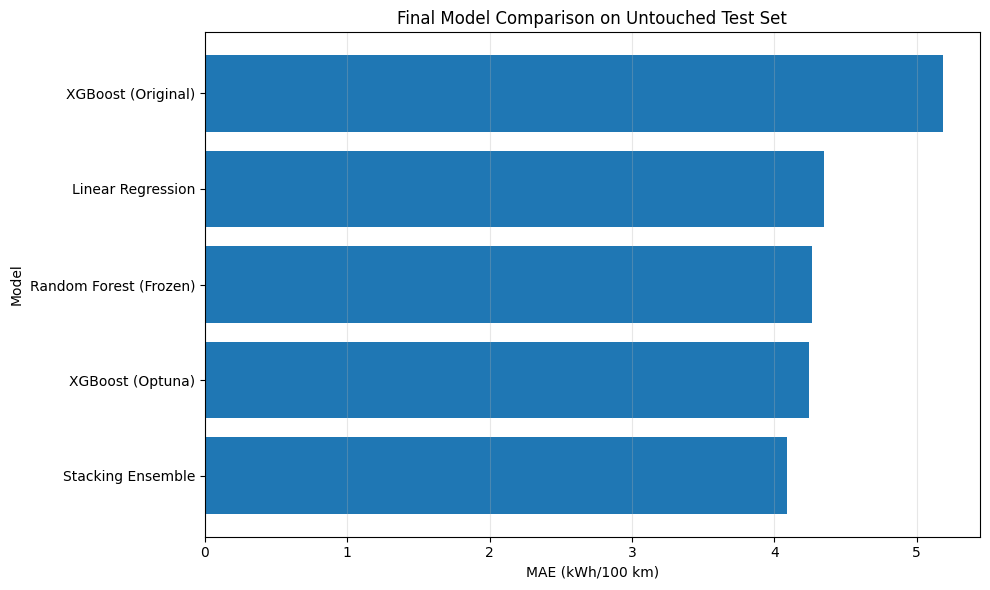

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\07_Final_Model_Comparison_MAE.png


In [149]:
# ============================================================
# Stage 15.13a - Final Model Comparison Figure
# ============================================================

import matplotlib.pyplot as plt

plot_data = final_model_comparison.sort_values(
    "MAE",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Model"],
    plot_data["MAE"]
)

plt.xlabel("MAE (kWh/100 km)")
plt.ylabel("Model")
plt.title("Final Model Comparison on Untouched Test Set")

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

MODEL_COMPARISON_FIG = (
    FINAL_RESULTS_DIR /
    "07_Final_Model_Comparison_MAE.png"
)

plt.savefig(
    MODEL_COMPARISON_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(MODEL_COMPARISON_FIG)

# Stage 15.13b - Actual vs Predicted

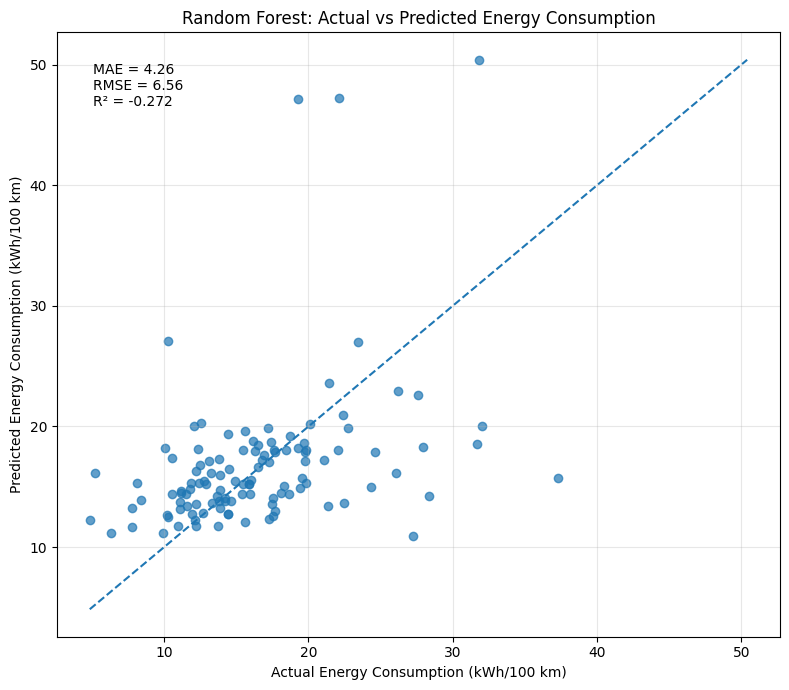

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\08_RF_Actual_vs_Predicted.png


In [150]:
# ============================================================
# Stage 15.13b - Actual vs Predicted
# ============================================================

plt.figure(figsize=(8, 7))

plt.scatter(
    final_prediction_table["Actual_kWh_100km"],
    final_prediction_table["Predicted_kWh_100km"],
    alpha=0.7
)

# Perfect-prediction reference line
min_value = min(
    final_prediction_table["Actual_kWh_100km"].min(),
    final_prediction_table["Predicted_kWh_100km"].min()
)

max_value = max(
    final_prediction_table["Actual_kWh_100km"].max(),
    final_prediction_table["Predicted_kWh_100km"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Energy Consumption (kWh/100 km)")
plt.ylabel("Predicted Energy Consumption (kWh/100 km)")
plt.title("Random Forest: Actual vs Predicted Energy Consumption")

plt.grid(alpha=0.3)

# Add final metrics
metrics_text = (
    f"MAE = {final_mae_frozen:.2f}\n"
    f"RMSE = {final_rmse_frozen:.2f}\n"
    f"R² = {final_r2_frozen:.3f}"
)

plt.text(
    0.05,
    0.95,
    metrics_text,
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.tight_layout()

ACTUAL_PREDICTED_FIG = (
    FINAL_RESULTS_DIR /
    "08_RF_Actual_vs_Predicted.png"
)

plt.savefig(
    ACTUAL_PREDICTED_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(ACTUAL_PREDICTED_FIG)

# Stage 15.13c - Residual Plot

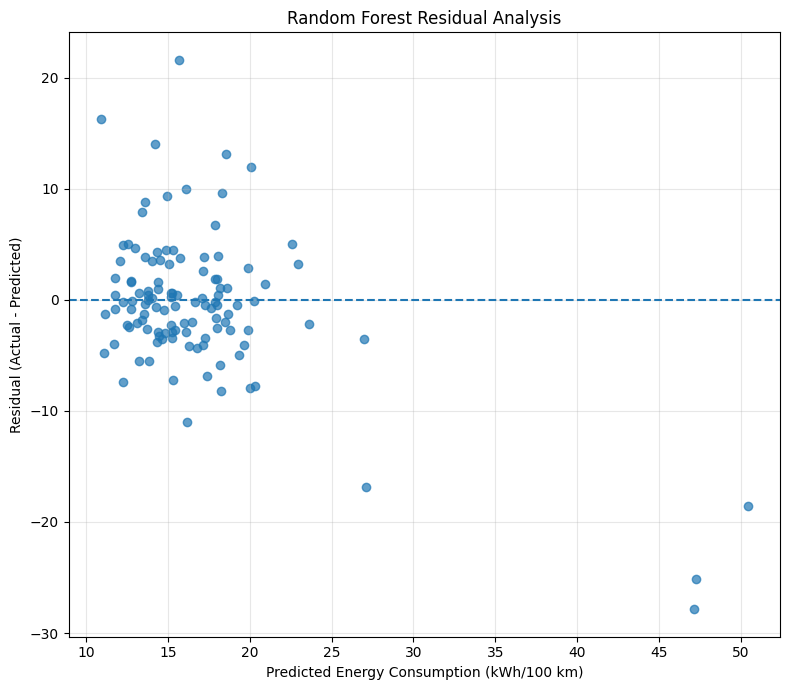

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\09_RF_Residual_Plot.png


In [151]:
# ============================================================
# Stage 15.13c - Residual Plot
# ============================================================

plt.figure(figsize=(8, 7))

plt.scatter(
    final_prediction_table["Predicted_kWh_100km"],
    final_prediction_table["Residual"],
    alpha=0.7
)

# Zero-error reference line
plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Energy Consumption (kWh/100 km)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Random Forest Residual Analysis")

plt.grid(alpha=0.3)

plt.tight_layout()

RESIDUAL_FIG = (
    FINAL_RESULTS_DIR /
    "09_RF_Residual_Plot.png"
)

plt.savefig(
    RESIDUAL_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(RESIDUAL_FIG)

# Stage 15.13d - Residual Distribution

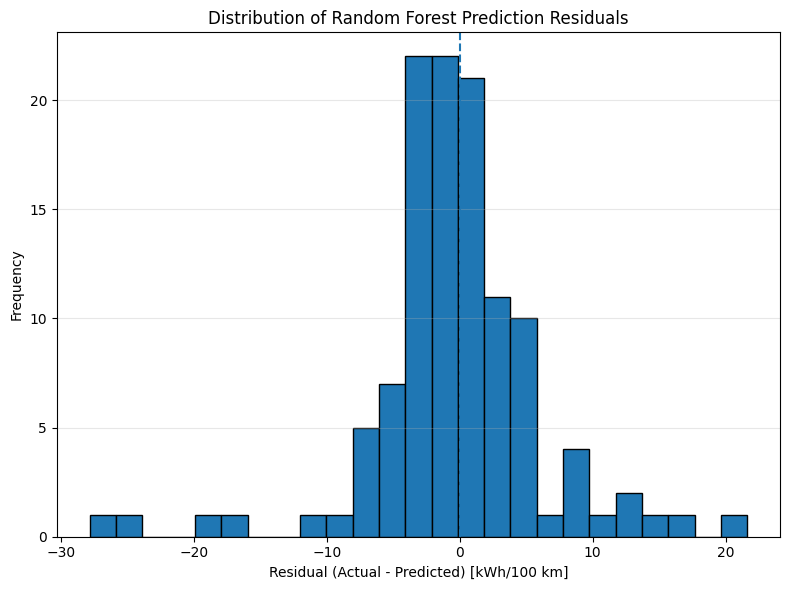

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\10_RF_Residual_Distribution.png


In [152]:
# ============================================================
# Stage 15.13d - Residual Distribution
# ============================================================

plt.figure(figsize=(8, 6))

plt.hist(
    final_prediction_table["Residual"],
    bins=25,
    edgecolor="black"
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel("Residual (Actual - Predicted) [kWh/100 km]")
plt.ylabel("Frequency")
plt.title("Distribution of Random Forest Prediction Residuals")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

RESIDUAL_DIST_FIG = (
    FINAL_RESULTS_DIR /
    "10_RF_Residual_Distribution.png"
)

plt.savefig(
    RESIDUAL_DIST_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(RESIDUAL_DIST_FIG)

# STAGE 16 — FINAL TEMPERATURE-ENHANCED MODELLING PIPELINE

# ============================================================
# STAGE 16 — FINAL TEMPERATURE-ENHANCED MODELLING PIPELINE
# ============================================================

This section implements the final temperature-enhanced modelling
pipeline using the harmonised 10-feature master dataset.

The original 9-feature behaviour-only experiment is retained as
a reference experiment.

Environmental temperature was subsequently incorporated because
it was consistently available across VED, BMW, and Argonne and
represented an important contextual factor in EV energy consumption.

# STAGE 16 — FINAL TEMPERATURE-ENHANCED MODELLING PIPELINE

This section implements the final temperature-enhanced modelling pipeline.

The original nine-feature behaviour-only experiment is retained as a
reference experiment. Environmental temperature is added as a tenth
predictor after harmonisation across VED, BMW, and Argonne.

No observations were removed solely on the basis of extreme target or
acceleration values. Physical plausibility and outlier audits were
performed before final modelling.

# Stage 16.1 - Load Final Temperature-Enhanced Dataset

In [153]:
# ============================================================
# Stage 16.1 - Load Final Temperature-Enhanced Dataset
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

MASTER_TEMP_PATH = Path(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\Harmonised\Master_EV_Dataset_With_Temperature.csv"
)

# Load from disk
master_final = pd.read_csv(MASTER_TEMP_PATH)

print("=" * 70)
print("FINAL TEMPERATURE-ENHANCED DATASET")
print("=" * 70)

print("\nFile:")
print(MASTER_TEMP_PATH)

print("\nShape:")
print(master_final.shape)

print("\nColumns:")
for col in master_final.columns:
    print(" -", col)

print("\nDataset distribution:")
print(master_final["Dataset"].value_counts())

print("\nTotal missing values:")
print(master_final.isna().sum().sum())

print("\nDuplicate rows:")
print(master_final.duplicated().sum())

print("\nTarget statistics:")
print(
    master_final["Energy_Consumption_kWh_100km"]
    .describe()
    .round(3)
)

print("\nEnvironmental temperature statistics:")
print(
    master_final["Environmental_Temperature_C"]
    .describe()
    .round(3)
)

print("=" * 70)

FINAL TEMPERATURE-ENHANCED DATASET

File:
C:\Projects\DS7010_Dissertation\01-Datasets\Harmonised\Master_EV_Dataset_With_Temperature.csv

Shape:
(575, 12)

Columns:
 - Mean_Speed_kmh
 - Max_Speed_kmh
 - Std_Speed_kmh
 - Mean_Acceleration_mps2
 - Max_Acceleration_mps2
 - Min_Acceleration_mps2
 - Mean_Positive_Acceleration_mps2
 - Idling_Proportion
 - Duration_s
 - Environmental_Temperature_C
 - Energy_Consumption_kWh_100km
 - Dataset

Dataset distribution:
Dataset
VED        488
BMW         68
ARGONNE     19
Name: count, dtype: int64

Total missing values:
0

Duplicate rows:
0

Target statistics:
count    575.000
mean      16.149
std        7.109
min        2.846
25%       11.899
50%       14.974
75%       18.827
max       79.163
Name: Energy_Consumption_kWh_100km, dtype: float64

Environmental temperature statistics:
count    575.000
mean      12.573
std       11.567
min      -16.108
25%        3.365
50%       11.542
75%       22.664
max       39.109
Name: Environmental_Temperature_C, d

# Stage 16.2 - Define Final Modelling Variables

In [154]:
# ============================================================
# Stage 16.2 - Define Final Modelling Variables
# ============================================================

FINAL_FEATURES = [
    "Mean_Speed_kmh",
    "Max_Speed_kmh",
    "Std_Speed_kmh",
    "Mean_Acceleration_mps2",
    "Max_Acceleration_mps2",
    "Min_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion",
    "Duration_s",
    "Environmental_Temperature_C"
]

FINAL_TARGET = "Energy_Consumption_kWh_100km"
DATASET_COLUMN = "Dataset"


# ------------------------------------------------------------
# Create modelling objects
# ------------------------------------------------------------

X_final = master_final[FINAL_FEATURES].copy()
y_final = master_final[FINAL_TARGET].copy()
dataset_final = master_final[DATASET_COLUMN].copy()


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 70)
print("FINAL MODELLING VARIABLES")
print("=" * 70)

print(f"\nNumber of predictors: {X_final.shape[1]}")
print(f"Number of observations: {X_final.shape[0]}")

print("\nPredictors:")
for i, feature in enumerate(FINAL_FEATURES, start=1):
    print(f"{i:02d}. {feature}")

print("\nTarget:")
print(FINAL_TARGET)

print("\nDataset identifier:")
print(DATASET_COLUMN)

print("\nX shape:", X_final.shape)
print("y shape:", y_final.shape)

print("\nMissing X:", X_final.isna().sum().sum())
print("Missing y:", y_final.isna().sum())

print("=" * 70)

FINAL MODELLING VARIABLES

Number of predictors: 10
Number of observations: 575

Predictors:
01. Mean_Speed_kmh
02. Max_Speed_kmh
03. Std_Speed_kmh
04. Mean_Acceleration_mps2
05. Max_Acceleration_mps2
06. Min_Acceleration_mps2
07. Mean_Positive_Acceleration_mps2
08. Idling_Proportion
09. Duration_s
10. Environmental_Temperature_C

Target:
Energy_Consumption_kWh_100km

Dataset identifier:
Dataset

X shape: (575, 10)
y shape: (575,)

Missing X: 0
Missing y: 0


# Stage 16.3 - Final Stratified Train/Test Split

In [155]:
# ============================================================
# Stage 16.3 - Final Stratified Train/Test Split
# ============================================================

from sklearn.model_selection import train_test_split

X_train_final, X_test_final, \
y_train_final, y_test_final, \
dataset_train_final, dataset_test_final = train_test_split(
    X_final,
    y_final,
    dataset_final,
    test_size=0.20,
    random_state=42,
    stratify=dataset_final
)

print("=" * 70)
print("FINAL TRAIN / TEST SPLIT")
print("=" * 70)

print("\nTraining:")
print(X_train_final.shape)

print("\nTesting:")
print(X_test_final.shape)

print("\nTraining dataset distribution:")
print(dataset_train_final.value_counts())

print("\nTesting dataset distribution:")
print(dataset_test_final.value_counts())

print("\nTarget means:")
print(f"Train: {y_train_final.mean():.4f}")
print(f"Test : {y_test_final.mean():.4f}")

print("\nEnvironmental temperature means:")
print(
    f"Train: "
    f"{X_train_final['Environmental_Temperature_C'].mean():.3f}"
)
print(
    f"Test : "
    f"{X_test_final['Environmental_Temperature_C'].mean():.3f}"
)

print("\nOverlap check:")
print(
    "Train/test index overlap:",
    len(
        set(X_train_final.index)
        .intersection(set(X_test_final.index))
    )
)

print("=" * 70)

FINAL TRAIN / TEST SPLIT

Training:
(460, 10)

Testing:
(115, 10)

Training dataset distribution:
Dataset
VED        391
BMW         54
ARGONNE     15
Name: count, dtype: int64

Testing dataset distribution:
Dataset
VED        97
BMW        14
ARGONNE     4
Name: count, dtype: int64

Target means:
Train: 16.0933
Test : 16.3739

Environmental temperature means:
Train: 12.612
Test : 12.414

Overlap check:
Train/test index overlap: 0


# Stage 16.4 - Frozen Final RF + Training-Only CV

In [156]:
# ============================================================
# Stage 16.4 - Frozen Final RF + Training-Only CV
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score
import numpy as np


# ------------------------------------------------------------
# Frozen hyperparameters selected previously by training-only
# Optuna optimisation
# ------------------------------------------------------------

final_rf = RandomForestRegressor(
    n_estimators=350,
    max_depth=13,
    min_samples_split=8,
    min_samples_leaf=3,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# Authoritative CV definition
# ------------------------------------------------------------

FINAL_CV = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ------------------------------------------------------------
# IMPORTANT:
# CV uses TRAINING DATA ONLY
# ------------------------------------------------------------

final_cv_r2 = cross_val_score(
    final_rf,
    X_train_final,
    y_train_final,
    cv=FINAL_CV,
    scoring="r2",
    n_jobs=-1
)

final_cv_mae = -cross_val_score(
    final_rf,
    X_train_final,
    y_train_final,
    cv=FINAL_CV,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

final_cv_rmse = -cross_val_score(
    final_rf,
    X_train_final,
    y_train_final,
    cv=FINAL_CV,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 75)
print("FINAL TEMPERATURE-ENHANCED RF")
print("TRAINING-ONLY 5-FOLD CROSS-VALIDATION")
print("=" * 75)

print("\nFrozen hyperparameters:")
print("n_estimators      = 350")
print("max_depth         = 13")
print("min_samples_split = 8")
print("min_samples_leaf  = 3")
print("max_features      = 0.7")

print("\nR² by fold:")
for i, score in enumerate(final_cv_r2, start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nCross-validation summary:")
print(
    f"R²   = {final_cv_r2.mean():.4f} "
    f"± {final_cv_r2.std():.4f}"
)

print(
    f"MAE  = {final_cv_mae.mean():.4f} "
    f"± {final_cv_mae.std():.4f}"
)

print(
    f"RMSE = {final_cv_rmse.mean():.4f} "
    f"± {final_cv_rmse.std():.4f}"
)

print("=" * 75)

FINAL TEMPERATURE-ENHANCED RF
TRAINING-ONLY 5-FOLD CROSS-VALIDATION

Frozen hyperparameters:
n_estimators      = 350
max_depth         = 13
min_samples_split = 8
min_samples_leaf  = 3
max_features      = 0.7

R² by fold:
Fold 1: 0.5914
Fold 2: 0.5414
Fold 3: 0.5556
Fold 4: 0.5729
Fold 5: 0.5142

Cross-validation summary:
R²   = 0.5551 ± 0.0264
MAE  = 3.2688 ± 0.1714
RMSE = 4.8874 ± 0.7774


# Stage 16.5 - Authoritative Final Holdout Evaluation

In [157]:
# ============================================================
# Stage 16.5 - Authoritative Final Holdout Evaluation
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# ------------------------------------------------------------
# Fit frozen model on ALL training observations
# ------------------------------------------------------------

final_rf.fit(
    X_train_final,
    y_train_final
)

# ------------------------------------------------------------
# Predict untouched test set
# ------------------------------------------------------------

y_pred_final = final_rf.predict(
    X_test_final
)

# ------------------------------------------------------------
# Calculate authoritative metrics
# ------------------------------------------------------------

FINAL_MAE = mean_absolute_error(
    y_test_final,
    y_pred_final
)

FINAL_RMSE = np.sqrt(
    mean_squared_error(
        y_test_final,
        y_pred_final
    )
)

FINAL_R2 = r2_score(
    y_test_final,
    y_pred_final
)

FINAL_MAPE = mean_absolute_percentage_error(
    y_test_final,
    y_pred_final
) * 100


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 75)
print("FINAL TEMPERATURE-ENHANCED RANDOM FOREST")
print("AUTHORITATIVE UNTOUCHED HOLDOUT TEST")
print("=" * 75)

print(f"\nTraining observations : {len(X_train_final)}")
print(f"Testing observations  : {len(X_test_final)}")

print("\nHoldout performance:")
print(f"MAE  : {FINAL_MAE:.4f} kWh/100 km")
print(f"RMSE : {FINAL_RMSE:.4f} kWh/100 km")
print(f"R²   : {FINAL_R2:.4f}")
print(f"MAPE : {FINAL_MAPE:.2f}%")

print("\nTraining-only CV:")
print(
    f"R²   : {final_cv_r2.mean():.4f} "
    f"± {final_cv_r2.std():.4f}"
)

print("=" * 75)

FINAL TEMPERATURE-ENHANCED RANDOM FOREST
AUTHORITATIVE UNTOUCHED HOLDOUT TEST

Training observations : 460
Testing observations  : 115

Holdout performance:
MAE  : 3.1081 kWh/100 km
RMSE : 4.6104 kWh/100 km
R²   : 0.3725
MAPE : 20.49%

Training-only CV:
R²   : 0.5551 ± 0.0264


# Stage 16.6 - Leave-One-Dataset-Out Validation
# Frozen Temperature-Enhanced RF

In [158]:
# ============================================================
# Stage 16.6 - Leave-One-Dataset-Out Validation
# Frozen Temperature-Enhanced RF
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

cross_dataset_rows = []

for held_out in ["VED", "BMW", "ARGONNE"]:

    train_mask = master_final["Dataset"] != held_out
    test_mask = master_final["Dataset"] == held_out

    X_cross_train = master_final.loc[
        train_mask, FINAL_FEATURES
    ]

    y_cross_train = master_final.loc[
        train_mask, FINAL_TARGET
    ]

    X_cross_test = master_final.loc[
        test_mask, FINAL_FEATURES
    ]

    y_cross_test = master_final.loc[
        test_mask, FINAL_TARGET
    ]

    # New instance of the same frozen RF
    model_cross = RandomForestRegressor(
        n_estimators=350,
        max_depth=13,
        min_samples_split=8,
        min_samples_leaf=3,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    )

    model_cross.fit(
        X_cross_train,
        y_cross_train
    )

    pred_cross = model_cross.predict(
        X_cross_test
    )

    mae = mean_absolute_error(
        y_cross_test,
        pred_cross
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_cross_test,
            pred_cross
        )
    )

    r2 = r2_score(
        y_cross_test,
        pred_cross
    )

    mape = mean_absolute_percentage_error(
        y_cross_test,
        pred_cross
    ) * 100

    cross_dataset_rows.append({
        "Held_Out_Dataset": held_out,
        "Train_N": len(X_cross_train),
        "Test_N": len(X_cross_test),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE_pct": mape
    })


cross_dataset_final = pd.DataFrame(
    cross_dataset_rows
)

print("=" * 75)
print("FINAL LEAVE-ONE-DATASET-OUT VALIDATION")
print("=" * 75)

display(
    cross_dataset_final.round(4)
)

FINAL LEAVE-ONE-DATASET-OUT VALIDATION


,Held_Out_Dataset,Train_N,Test_N,MAE,RMSE,R2,MAPE_pct
0,VED,87,488,4.6752,6.8855,0.1507,36.7121
1,BMW,507,68,2.6906,3.2389,0.1107,16.4892
2,ARGONNE,556,19,6.4130,8.7491,-0.5739,46.8321


# Stage 16.7 - SHAP Analysis of Final RF

In [159]:
# ============================================================
# Stage 16.7 - SHAP Analysis of Final RF
# ============================================================

import shap
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Explain the exact frozen final model
# ------------------------------------------------------------

explainer_final = shap.TreeExplainer(final_rf)

shap_values_final = explainer_final(
    X_test_final
)

print("=" * 75)
print("FINAL RF — SHAP ANALYSIS")
print("=" * 75)

print("\nExplained dataset:")
print("Untouched holdout test set")

print("\nObservations:")
print(X_test_final.shape[0])

print("\nFeatures:")
print(X_test_final.shape[1])

print("\nSHAP matrix shape:")
print(shap_values_final.values.shape)

print("\nExpected/base value:")
print(
    np.mean(
        np.atleast_1d(
            shap_values_final.base_values
        )
    )
)

print("=" * 75)


# ------------------------------------------------------------
# Global mean absolute SHAP importance
# ------------------------------------------------------------

mean_abs_shap = np.abs(
    shap_values_final.values
).mean(axis=0)

shap_importance_final = pd.DataFrame({
    "Feature": X_test_final.columns,
    "Mean_Absolute_SHAP": mean_abs_shap
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)


print("\nGLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 75)

display(
    shap_importance_final.round(4)
)

FINAL RF — SHAP ANALYSIS

Explained dataset:
Untouched holdout test set

Observations:
115

Features:
10

SHAP matrix shape:
(115, 10)

Expected/base value:
16.083149848699975

GLOBAL SHAP FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP
0,Environmental_Temperature_C,2.5961
1,Mean_Speed_kmh,1.3051
2,Idling_Proportion,1.2307
3,Mean_Positive_Acceleration_mps2,0.3794
4,Max_Speed_kmh,0.3469
5,Mean_Acceleration_mps2,0.3046
6,Min_Acceleration_mps2,0.2802
7,Std_Speed_kmh,0.1870
8,Duration_s,0.1431
9,Max_Acceleration_mps2,0.0785


# Stage 16.8 - Final SHAP Beeswarm Plot

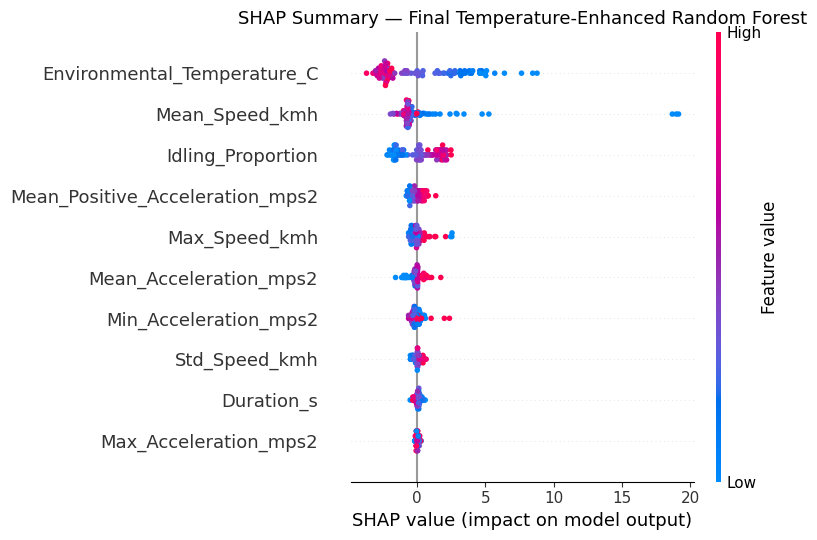

In [160]:
# ============================================================
# Stage 16.8 - Final SHAP Beeswarm Plot
# ============================================================

import shap
import matplotlib.pyplot as plt

shap.plots.beeswarm(
    shap_values_final,
    max_display=10,
    show=False
)

plt.title(
    "SHAP Summary — Final Temperature-Enhanced Random Forest",
    fontsize=13
)

plt.tight_layout()
plt.show()

# Stage 16.9 - Temperature SHAP Dependence Plot

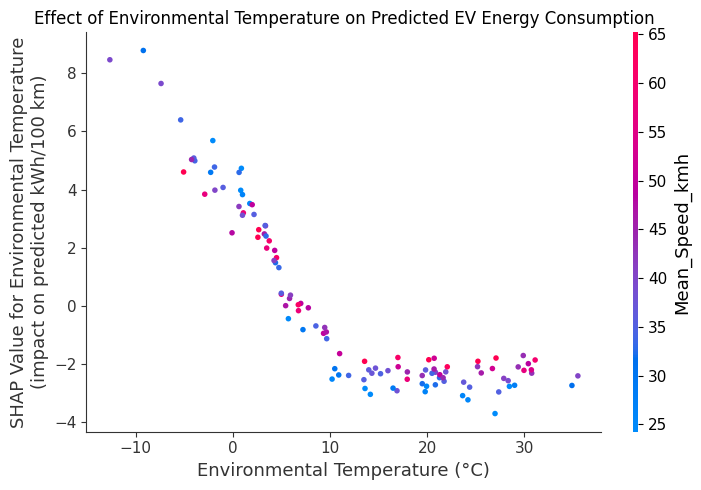

In [161]:
# ============================================================
# Stage 16.9 - Temperature SHAP Dependence Plot
# ============================================================

import shap
import matplotlib.pyplot as plt

shap.dependence_plot(
    "Environmental_Temperature_C",
    shap_values_final.values,
    X_test_final,
    interaction_index="auto",
    show=False
)

plt.title(
    "Effect of Environmental Temperature on Predicted EV Energy Consumption",
    fontsize=12
)

plt.xlabel("Environmental Temperature (°C)")
plt.ylabel(
    "SHAP Value for Environmental Temperature\n"
    "(impact on predicted kWh/100 km)"
)

plt.tight_layout()
plt.show()

# Stage 16.10 - Save Final SHAP Figures

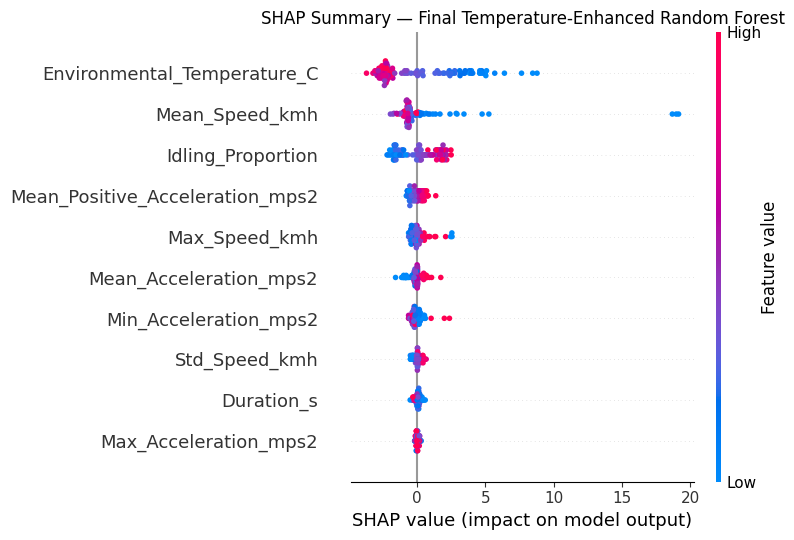

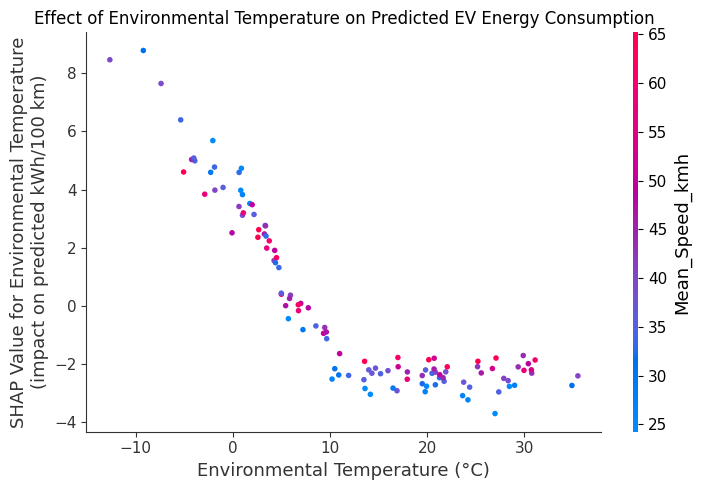

FINAL SHAP FIGURES SAVED
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\11_Final_SHAP_Beeswarm.png
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\12_Temperature_SHAP_Dependence.png


In [162]:
# ============================================================
# Stage 16.10 - Save Final SHAP Figures
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
import shap

FINAL_RESULTS_DIR = Path(
    r"C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results"
)

FINAL_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Figure 1 - Final SHAP Beeswarm
# ------------------------------------------------------------

shap.plots.beeswarm(
    shap_values_final,
    max_display=10,
    show=False
)

plt.title(
    "SHAP Summary — Final Temperature-Enhanced Random Forest"
)

plt.tight_layout()

plt.savefig(
    FINAL_RESULTS_DIR / "11_Final_SHAP_Beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Figure 2 - Temperature Dependence
# ------------------------------------------------------------

shap.dependence_plot(
    "Environmental_Temperature_C",
    shap_values_final.values,
    X_test_final,
    interaction_index="auto",
    show=False
)

plt.title(
    "Effect of Environmental Temperature on Predicted EV Energy Consumption"
)

plt.xlabel("Environmental Temperature (°C)")

plt.ylabel(
    "SHAP Value for Environmental Temperature\n"
    "(impact on predicted kWh/100 km)"
)

plt.tight_layout()

plt.savefig(
    FINAL_RESULTS_DIR / "12_Temperature_SHAP_Dependence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("=" * 70)
print("FINAL SHAP FIGURES SAVED")
print("=" * 70)

print(
    FINAL_RESULTS_DIR /
    "11_Final_SHAP_Beeswarm.png"
)

print(
    FINAL_RESULTS_DIR /
    "12_Temperature_SHAP_Dependence.png"
)

# Stage 16.11 - Representative Local SHAP Explanation

REPRESENTATIVE LOCAL SHAP EXPLANATION

Test position : 4
Actual        : 15.5710 kWh/100 km
Predicted     : 16.4486 kWh/100 km
Residual      : -0.8776 kWh/100 km

Feature values:


,Mean_Speed_kmh,Max_Speed_kmh,Std_Speed_kmh,Mean_Acceleration_mps2,Max_Acceleration_mps2,Min_Acceleration_mps2,Mean_Positive_Acceleration_mps2,Idling_Proportion,Duration_s,Environmental_Temperature_C
200,29.748939,69.689995,23.668361,-0.078919,4.824075,-9.805556,0.139102,0.180516,402.4,7.224928


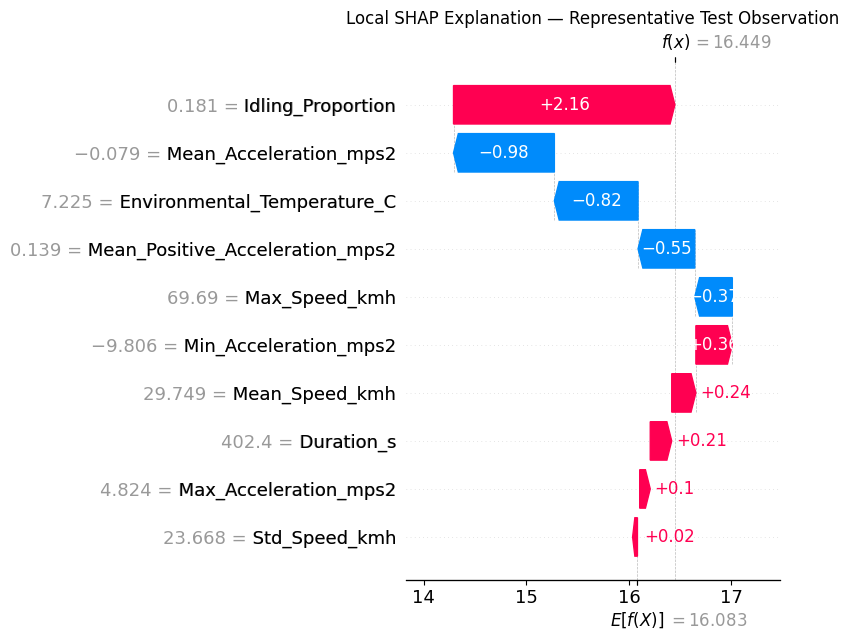

In [163]:
# ============================================================
# Stage 16.11 - Representative Local SHAP Explanation
# ============================================================

import numpy as np
import shap
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Find observation closest to median actual consumption
# ------------------------------------------------------------

test_median = y_test_final.median()

local_position = np.argmin(
    np.abs(
        y_test_final.to_numpy() - test_median
    )
)

actual_local = y_test_final.iloc[local_position]
predicted_local = y_pred_final[local_position]


print("=" * 75)
print("REPRESENTATIVE LOCAL SHAP EXPLANATION")
print("=" * 75)

print(f"\nTest position : {local_position}")
print(f"Actual        : {actual_local:.4f} kWh/100 km")
print(f"Predicted     : {predicted_local:.4f} kWh/100 km")
print(
    f"Residual      : "
    f"{actual_local - predicted_local:.4f} kWh/100 km"
)

print("\nFeature values:")
display(
    X_test_final.iloc[[local_position]]
)


# ------------------------------------------------------------
# Waterfall
# ------------------------------------------------------------

shap.plots.waterfall(
    shap_values_final[local_position],
    max_display=10,
    show=False
)

plt.title(
    "Local SHAP Explanation — Representative Test Observation"
)

plt.tight_layout()

plt.savefig(
    FINAL_RESULTS_DIR /
    "13_Final_SHAP_Waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Stage 16.12 - Export Authoritative Final Results Package

In [164]:
# ============================================================
# Stage 16.12 - Export Authoritative Final Results Package
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import joblib


FINAL_RESULTS_DIR = Path(
    r"C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results"
)

FINAL_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 1. Final holdout metrics
# ============================================================

final_metrics_export = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R2",
        "MAPE_pct",
        "CV_Mean_R2",
        "CV_SD_R2",
        "CV_Mean_MAE",
        "CV_Mean_RMSE"
    ],

    "Value": [
        FINAL_MAE,
        FINAL_RMSE,
        FINAL_R2,
        FINAL_MAPE,
        final_cv_r2.mean(),
        final_cv_r2.std(),
        final_cv_mae.mean(),
        final_cv_rmse.mean()
    ]
})

final_metrics_export.to_csv(
    FINAL_RESULTS_DIR /
    "14_Final_Temperature_RF_Metrics.csv",
    index=False
)


# ============================================================
# 2. Cross-validation fold results
# ============================================================

cv_export = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "R2": final_cv_r2,
    "MAE": final_cv_mae,
    "RMSE": final_cv_rmse
})

cv_export.to_csv(
    FINAL_RESULTS_DIR /
    "15_Final_RF_Cross_Validation.csv",
    index=False
)


# ============================================================
# 3. Cross-dataset validation
# ============================================================

cross_dataset_final.to_csv(
    FINAL_RESULTS_DIR /
    "16_Final_Cross_Dataset_Validation.csv",
    index=False
)


# ============================================================
# 4. Final SHAP feature importance
# ============================================================

shap_importance_final.to_csv(
    FINAL_RESULTS_DIR /
    "17_Final_SHAP_Feature_Importance.csv",
    index=False
)


# ============================================================
# 5. Final holdout predictions
# ============================================================

prediction_export = X_test_final.copy()

prediction_export.insert(
    0,
    "Dataset",
    dataset_test_final.values
)

prediction_export["Actual_kWh_100km"] = (
    y_test_final.values
)

prediction_export["Predicted_kWh_100km"] = (
    y_pred_final
)

prediction_export["Residual"] = (
    prediction_export["Actual_kWh_100km"] -
    prediction_export["Predicted_kWh_100km"]
)

prediction_export["Absolute_Error"] = (
    np.abs(prediction_export["Residual"])
)

prediction_export.to_csv(
    FINAL_RESULTS_DIR /
    "18_Final_RF_Test_Predictions.csv",
    index=False
)


# ============================================================
# 6. Save exact frozen model
# ============================================================

joblib.dump(
    final_rf,
    FINAL_RESULTS_DIR /
    "19_Final_Temperature_RF.pkl"
)


# ============================================================
# 7. Save final feature list
# ============================================================

feature_export = pd.DataFrame({
    "Feature_Order": range(
        1,
        len(FINAL_FEATURES) + 1
    ),
    "Feature": FINAL_FEATURES
})

feature_export.to_csv(
    FINAL_RESULTS_DIR /
    "20_Final_Feature_List.csv",
    index=False
)


# ============================================================
# 8. Verification
# ============================================================

print("=" * 75)
print("AUTHORITATIVE FINAL RESULTS PACKAGE EXPORTED")
print("=" * 75)

print("\nOutput folder:")
print(FINAL_RESULTS_DIR)

print("\nFiles:")

files_expected = [
    "11_Final_SHAP_Beeswarm.png",
    "12_Temperature_SHAP_Dependence.png",
    "13_Final_SHAP_Waterfall.png",
    "14_Final_Temperature_RF_Metrics.csv",
    "15_Final_RF_Cross_Validation.csv",
    "16_Final_Cross_Dataset_Validation.csv",
    "17_Final_SHAP_Feature_Importance.csv",
    "18_Final_RF_Test_Predictions.csv",
    "19_Final_Temperature_RF.pkl",
    "20_Final_Feature_List.csv"
]

for filename in files_expected:

    path = FINAL_RESULTS_DIR / filename

    if path.exists():
        print(f"✓ {filename}")
    else:
        print(f"✗ MISSING: {filename}")

print("\nFinal model:")
print(final_rf)

print("\nAuthoritative holdout results:")
print(f"MAE  : {FINAL_MAE:.4f}")
print(f"RMSE : {FINAL_RMSE:.4f}")
print(f"R²   : {FINAL_R2:.4f}")
print(f"MAPE : {FINAL_MAPE:.2f}%")

print("\nTraining-only CV:")
print(
    f"R²   : {final_cv_r2.mean():.4f} "
    f"± {final_cv_r2.std():.4f}"
)

print("=" * 75)

AUTHORITATIVE FINAL RESULTS PACKAGE EXPORTED

Output folder:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results

Files:
✓ 11_Final_SHAP_Beeswarm.png
✓ 12_Temperature_SHAP_Dependence.png
✓ 13_Final_SHAP_Waterfall.png
✓ 14_Final_Temperature_RF_Metrics.csv
✓ 15_Final_RF_Cross_Validation.csv
✓ 16_Final_Cross_Dataset_Validation.csv
✓ 17_Final_SHAP_Feature_Importance.csv
✓ 18_Final_RF_Test_Predictions.csv
✓ 19_Final_Temperature_RF.pkl
✓ 20_Final_Feature_List.csv

Final model:
RandomForestRegressor(max_depth=13, max_features=0.7, min_samples_leaf=3,
                      min_samples_split=8, n_estimators=350, n_jobs=-1,
                      random_state=42)

Authoritative holdout results:
MAE  : 3.1081
RMSE : 4.6104
R²   : 0.3725
MAPE : 20.49%

Training-only CV:
R²   : 0.5551 ± 0.0264


# Stage 17.1 - Acceleration Scale Audit by Dataset

In [165]:
# ============================================================
# Stage 17.1 - Acceleration Scale Audit by Dataset
# ============================================================

acceleration_features = [
    "Mean_Acceleration_mps2",
    "Max_Acceleration_mps2",
    "Min_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2"
]

print("=" * 75)
print("ACCELERATION SCALE AUDIT BY DATASET")
print("=" * 75)

for dataset_name in ["VED", "BMW", "ARGONNE"]:

    subset = master_final[
        master_final["Dataset"] == dataset_name
    ]

    print("\n" + "=" * 75)
    print(dataset_name)
    print("=" * 75)

    for feature in acceleration_features:

        s = subset[feature]

        print(f"\n{feature}")
        print("-" * 50)

        print(f"Count : {s.count()}")
        print(f"Mean  : {s.mean():.4f}")
        print(f"Std   : {s.std():.4f}")
        print(f"Min   : {s.min():.4f}")
        print(f"1%    : {s.quantile(0.01):.4f}")
        print(f"5%    : {s.quantile(0.05):.4f}")
        print(f"25%   : {s.quantile(0.25):.4f}")
        print(f"50%   : {s.median():.4f}")
        print(f"75%   : {s.quantile(0.75):.4f}")
        print(f"95%   : {s.quantile(0.95):.4f}")
        print(f"99%   : {s.quantile(0.99):.4f}")
        print(f"Max   : {s.max():.4f}")

ACCELERATION SCALE AUDIT BY DATASET

VED

Mean_Acceleration_mps2
--------------------------------------------------
Count : 488
Mean  : 0.0050
Std   : 0.0408
Min   : -0.3532
1%    : -0.0968
5%    : -0.0579
25%   : -0.0139
50%   : 0.0059
75%   : 0.0251
95%   : 0.0613
99%   : 0.1016
Max   : 0.1961

Max_Acceleration_mps2
--------------------------------------------------
Count : 488
Mean  : 8.1442
Std   : 1.7520
Min   : 1.6111
1%    : 3.4910
5%    : 4.5926
25%   : 7.1146
50%   : 8.8056
75%   : 9.5000
95%   : 9.9167
99%   : 10.0000
Max   : 10.0000

Min_Acceleration_mps2
--------------------------------------------------
Count : 488
Mean  : -8.1374
Std   : 1.6568
Min   : -10.0000
1%    : -9.9758
5%    : -9.9028
25%   : -9.3889
50%   : -8.5556
75%   : -7.3750
95%   : -4.7797
99%   : -2.4152
Max   : -1.3819

Mean_Positive_Acceleration_mps2
--------------------------------------------------
Count : 488
Mean  : 0.2165
Std   : 0.0499
Min   : 0.0530
1%    : 0.1056
5%    : 0.1447
25%   : 0.1814
50

# Stage 17.2 - Acceleration Boundary Frequency Audit

In [166]:
# ============================================================
# Stage 17.2 - Acceleration Boundary Frequency Audit
# ============================================================

print("=" * 75)
print("ACCELERATION BOUNDARY FREQUENCIES")
print("=" * 75)

for dataset_name in ["VED", "BMW", "ARGONNE"]:

    subset = master_final[
        master_final["Dataset"] == dataset_name
    ]

    n = len(subset)

    print("\n" + dataset_name)
    print("-" * 50)

    for threshold in [4, 6, 8, 9, 9.5]:

        max_count = (
            subset["Max_Acceleration_mps2"] >= threshold
        ).sum()

        min_count = (
            subset["Min_Acceleration_mps2"] <= -threshold
        ).sum()

        print(
            f"|a| >= {threshold:>3}: "
            f"positive={max_count:>3} "
            f"({100*max_count/n:5.1f}%), "
            f"negative={min_count:>3} "
            f"({100*min_count/n:5.1f}%)"
        )

ACCELERATION BOUNDARY FREQUENCIES

VED
--------------------------------------------------
|a| >=   4: positive=475 ( 97.3%), negative=476 ( 97.5%)
|a| >=   6: positive=419 ( 85.9%), negative=434 ( 88.9%)
|a| >=   8: positive=306 ( 62.7%), negative=314 ( 64.3%)
|a| >=   9: positive=219 ( 44.9%), negative=184 ( 37.7%)
|a| >= 9.5: positive=126 ( 25.8%), negative= 99 ( 20.3%)

BMW
--------------------------------------------------
|a| >=   4: positive=  5 (  7.4%), negative=  8 ( 11.8%)
|a| >=   6: positive=  0 (  0.0%), negative=  2 (  2.9%)
|a| >=   8: positive=  0 (  0.0%), negative=  1 (  1.5%)
|a| >=   9: positive=  0 (  0.0%), negative=  1 (  1.5%)
|a| >= 9.5: positive=  0 (  0.0%), negative=  0 (  0.0%)

ARGONNE
--------------------------------------------------
|a| >=   4: positive=  1 (  5.3%), negative=  0 (  0.0%)
|a| >=   6: positive=  0 (  0.0%), negative=  0 (  0.0%)
|a| >=   8: positive=  0 (  0.0%), negative=  0 (  0.0%)
|a| >=   9: positive=  0 (  0.0%), negative=  0 (  0.

# Stage 17.3 - Acceleration Harmonisation Sensitivity Test
# Remove dataset-sensitive acceleration extrema only

In [167]:
# ============================================================
# Stage 17.3 - Acceleration Harmonisation Sensitivity Test
# Remove dataset-sensitive acceleration extrema only
# ============================================================

SENSITIVITY_FEATURES = [
    "Mean_Speed_kmh",
    "Max_Speed_kmh",
    "Std_Speed_kmh",

    # Retained acceleration measures
    "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",

    "Idling_Proportion",
    "Duration_s",
    "Environmental_Temperature_C"
]

# ------------------------------------------------------------
# Preserve EXACT same train/test observations
# ------------------------------------------------------------

X_train_sensitivity = master_final.loc[
    X_train_final.index,
    SENSITIVITY_FEATURES
]

X_test_sensitivity = master_final.loc[
    X_test_final.index,
    SENSITIVITY_FEATURES
]

# Targets remain exactly the same
y_train_sensitivity = y_train_final.copy()
y_test_sensitivity = y_test_final.copy()


print("=" * 75)
print("ACCELERATION HARMONISATION SENSITIVITY TEST")
print("=" * 75)

print("\nRemoved features:")
print(" - Max_Acceleration_mps2")
print(" - Min_Acceleration_mps2")

print("\nRetained acceleration features:")
print(" - Mean_Acceleration_mps2")
print(" - Mean_Positive_Acceleration_mps2")

print("\nPredictor count:")
print(len(SENSITIVITY_FEATURES))

print("\nTrain shape:")
print(X_train_sensitivity.shape)

print("\nTest shape:")
print(X_test_sensitivity.shape)

print("\nIndex verification:")
print(
    "Same training rows:",
    X_train_sensitivity.index.equals(X_train_final.index)
)

print(
    "Same testing rows:",
    X_test_sensitivity.index.equals(X_test_final.index)
)

print("=" * 75)

ACCELERATION HARMONISATION SENSITIVITY TEST

Removed features:
 - Max_Acceleration_mps2
 - Min_Acceleration_mps2

Retained acceleration features:
 - Mean_Acceleration_mps2
 - Mean_Positive_Acceleration_mps2

Predictor count:
8

Train shape:
(460, 8)

Test shape:
(115, 8)

Index verification:
Same training rows: True
Same testing rows: True


# Stage 17.4 - RF Sensitivity Model
# Same Frozen RF, Problematic Acceleration Extrema Removed

In [168]:
# ============================================================
# Stage 17.4 - RF Sensitivity Model
# Same Frozen RF, Problematic Acceleration Extrema Removed
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
import numpy as np


# ------------------------------------------------------------
# Same frozen RF configuration
# No retuning
# ------------------------------------------------------------

rf_accel_sensitivity = RandomForestRegressor(
    n_estimators=350,
    max_depth=13,
    min_samples_split=8,
    min_samples_leaf=3,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# Training-only CV
# ------------------------------------------------------------

sensitivity_cv_r2 = cross_val_score(
    rf_accel_sensitivity,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=FINAL_CV,
    scoring="r2",
    n_jobs=-1
)


# ------------------------------------------------------------
# Fit on training data
# ------------------------------------------------------------

rf_accel_sensitivity.fit(
    X_train_sensitivity,
    y_train_sensitivity
)


# ------------------------------------------------------------
# Same untouched test observations
# ------------------------------------------------------------

pred_accel_sensitivity = rf_accel_sensitivity.predict(
    X_test_sensitivity
)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

sens_mae = mean_absolute_error(
    y_test_sensitivity,
    pred_accel_sensitivity
)

sens_rmse = np.sqrt(
    mean_squared_error(
        y_test_sensitivity,
        pred_accel_sensitivity
    )
)

sens_r2 = r2_score(
    y_test_sensitivity,
    pred_accel_sensitivity
)

sens_mape = mean_absolute_percentage_error(
    y_test_sensitivity,
    pred_accel_sensitivity
) * 100


# ------------------------------------------------------------
# Comparison
# ------------------------------------------------------------

print("=" * 75)
print("ACCELERATION HARMONISATION SENSITIVITY RESULTS")
print("=" * 75)

print("\n10-FEATURE FINAL RF")
print(f"CV R²   : {final_cv_r2.mean():.4f} ± {final_cv_r2.std():.4f}")
print(f"Test MAE: {FINAL_MAE:.4f}")
print(f"Test RMSE: {FINAL_RMSE:.4f}")
print(f"Test R² : {FINAL_R2:.4f}")
print(f"Test MAPE: {FINAL_MAPE:.2f}%")

print("\n8-FEATURE SENSITIVITY RF")
print(
    f"CV R²   : {sensitivity_cv_r2.mean():.4f} "
    f"± {sensitivity_cv_r2.std():.4f}"
)
print(f"Test MAE: {sens_mae:.4f}")
print(f"Test RMSE: {sens_rmse:.4f}")
print(f"Test R² : {sens_r2:.4f}")
print(f"Test MAPE: {sens_mape:.2f}%")

print("\nCHANGE AFTER REMOVING ACCELERATION EXTREMA")
print(
    f"Δ CV R²   : "
    f"{sensitivity_cv_r2.mean() - final_cv_r2.mean():+.4f}"
)
print(f"Δ Test R² : {sens_r2 - FINAL_R2:+.4f}")
print(f"Δ MAE     : {sens_mae - FINAL_MAE:+.4f}")
print(f"Δ RMSE    : {sens_rmse - FINAL_RMSE:+.4f}")
print(f"Δ MAPE    : {sens_mape - FINAL_MAPE:+.2f} percentage points")

print("=" * 75)

ACCELERATION HARMONISATION SENSITIVITY RESULTS

10-FEATURE FINAL RF
CV R²   : 0.5551 ± 0.0264
Test MAE: 3.1081
Test RMSE: 4.6104
Test R² : 0.3725
Test MAPE: 20.49%

8-FEATURE SENSITIVITY RF
CV R²   : 0.5453 ± 0.0218
Test MAE: 3.1268
Test RMSE: 4.5936
Test R² : 0.3770
Test MAPE: 20.58%

CHANGE AFTER REMOVING ACCELERATION EXTREMA
Δ CV R²   : -0.0098
Δ Test R² : +0.0045
Δ MAE     : +0.0187
Δ RMSE    : -0.0167
Δ MAPE    : +0.08 percentage points


# Stage 17.5 - Final 8-Feature RF Optuna Tuning
# TRAINING DATA ONLY

In [169]:
# ============================================================
# Stage 17.5 - Final 8-Feature RF Optuna Tuning
# TRAINING DATA ONLY
# ============================================================

import optuna
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold


# ------------------------------------------------------------
# Fixed training-only CV
# ------------------------------------------------------------

cv_final_8 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ------------------------------------------------------------
# Optuna objective
# ------------------------------------------------------------

def objective_rf_8(trial):

    model = RandomForestRegressor(

        n_estimators=trial.suggest_int(
            "n_estimators",
            200,
            600,
            step=50
        ),

        max_depth=trial.suggest_int(
            "max_depth",
            5,
            20
        ),

        min_samples_split=trial.suggest_int(
            "min_samples_split",
            2,
            12
        ),

        min_samples_leaf=trial.suggest_int(
            "min_samples_leaf",
            1,
            6
        ),

        max_features=trial.suggest_categorical(
            "max_features",
            [
                "sqrt",
                "log2",
                0.5,
                0.7,
                1.0
            ]
        ),

        random_state=42,
        n_jobs=-1
    )

    scores = cross_val_score(
        model,
        X_train_sensitivity,
        y_train_sensitivity,
        cv=cv_final_8,
        scoring="r2",
        n_jobs=-1
    )

    return scores.mean()


# ------------------------------------------------------------
# Run optimisation
# ------------------------------------------------------------

study_rf_8 = optuna.create_study(
    direction="maximize"
)

study_rf_8.optimize(
    objective_rf_8,
    n_trials=30
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("=" * 75)
print("FINAL 8-FEATURE RF OPTUNA RESULTS")
print("=" * 75)

print(
    f"\nBest training-only CV R²: "
    f"{study_rf_8.best_value:.6f}"
)

print("\nBest parameters:")

for parameter, value in study_rf_8.best_params.items():
    print(f"{parameter}: {value}")

print("\nIMPORTANT:")
print("The untouched test set was NOT used during optimisation.")

print("=" * 75)

[I 2026-10-18 23:22:43,617] A new study created in memory with name: no-name-c7ea5ea8-6644-4ad1-8e32-fde759f135f7
[I 2026-10-18 23:22:44,393] Trial 0 finished with value: 0.5437561491237227 and parameters: {'n_estimators': 200, 'max_depth': 15, 'min_samples_split': 7, 'min_samples_leaf': 5, 'max_features': 0.7}. Best is trial 0 with value: 0.5437561491237227.
[I 2026-10-18 23:22:45,233] Trial 1 finished with value: 0.5148999519960535 and parameters: {'n_estimators': 250, 'max_depth': 7, 'min_samples_split': 7, 'min_samples_leaf': 5, 'max_features': 'log2'}. Best is trial 0 with value: 0.5437561491237227.
[I 2026-10-18 23:22:46,898] Trial 2 finished with value: 0.48945289602307007 and parameters: {'n_estimators': 450, 'max_depth': 19, 'min_samples_split': 6, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.5437561491237227.
[I 2026-10-18 23:22:48,407] Trial 3 finished with value: 0.48476863833162015 and parameters: {'n_estimators': 400, 'max_depth': 12, 'min

FINAL 8-FEATURE RF OPTUNA RESULTS

Best training-only CV R²: 0.559044

Best parameters:
n_estimators: 300
max_depth: 17
min_samples_split: 8
min_samples_leaf: 4
max_features: 1.0

IMPORTANT:
The untouched test set was NOT used during optimisation.


# Stage 17.6 - Authoritative Final 8-Feature RF
# Training-Only Cross-Validation

In [170]:
# ============================================================
# Stage 17.6 - Authoritative Final 8-Feature RF
# Training-Only Cross-Validation
# ============================================================

import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score


# ------------------------------------------------------------
# Freeze final model
# ------------------------------------------------------------

final_rf_8 = RandomForestRegressor(
    n_estimators=600,
    max_depth=16,
    min_samples_split=5,
    min_samples_leaf=4,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# Training-only CV
# ------------------------------------------------------------

final8_cv_r2 = cross_val_score(
    final_rf_8,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=cv_final_8,
    scoring="r2",
    n_jobs=-1
)

final8_cv_mae = -cross_val_score(
    final_rf_8,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=cv_final_8,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

final8_cv_rmse = -cross_val_score(
    final_rf_8,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=cv_final_8,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 75)
print("FINAL 8-FEATURE RANDOM FOREST")
print("TRAINING-ONLY 5-FOLD CROSS-VALIDATION")
print("=" * 75)

print("\nFrozen hyperparameters:")
print("n_estimators      = 600")
print("max_depth         = 16")
print("min_samples_split = 5")
print("min_samples_leaf  = 4")
print("max_features      = 1.0")

print("\nR² by fold:")

for i, score in enumerate(final8_cv_r2, start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nCross-validation summary:")

print(
    f"R²   = {final8_cv_r2.mean():.4f} "
    f"± {final8_cv_r2.std():.4f}"
)

print(
    f"MAE  = {final8_cv_mae.mean():.4f} "
    f"± {final8_cv_mae.std():.4f}"
)

print(
    f"RMSE = {final8_cv_rmse.mean():.4f} "
    f"± {final8_cv_rmse.std():.4f}"
)

print("=" * 75)

FINAL 8-FEATURE RANDOM FOREST
TRAINING-ONLY 5-FOLD CROSS-VALIDATION

Frozen hyperparameters:
n_estimators      = 600
max_depth         = 16
min_samples_split = 5
min_samples_leaf  = 4
max_features      = 1.0

R² by fold:
Fold 1: 0.5864
Fold 2: 0.5805
Fold 3: 0.5613
Fold 4: 0.5587
Fold 5: 0.5155

Cross-validation summary:
R²   = 0.5605 ± 0.0249
MAE  = 3.2651 ± 0.1888
RMSE = 4.8644 ± 0.8119


# Stage 17.7 - Final 8-Feature RF
# Authoritative Untouched Holdout Evaluation

In [171]:
# ============================================================
# Stage 17.7 - Final 8-Feature RF
# Authoritative Untouched Holdout Evaluation
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

import numpy as np


# ------------------------------------------------------------
# Fit frozen model using training data only
# ------------------------------------------------------------

final_rf_8.fit(
    X_train_sensitivity,
    y_train_sensitivity
)


# ------------------------------------------------------------
# Predict SAME untouched holdout
# ------------------------------------------------------------

y_pred_final_8 = final_rf_8.predict(
    X_test_sensitivity
)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

FINAL8_MAE = mean_absolute_error(
    y_test_sensitivity,
    y_pred_final_8
)

FINAL8_RMSE = np.sqrt(
    mean_squared_error(
        y_test_sensitivity,
        y_pred_final_8
    )
)

FINAL8_R2 = r2_score(
    y_test_sensitivity,
    y_pred_final_8
)

FINAL8_MAPE = mean_absolute_percentage_error(
    y_test_sensitivity,
    y_pred_final_8
) * 100


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 75)
print("FINAL 8-FEATURE RANDOM FOREST")
print("AUTHORITATIVE UNTOUCHED HOLDOUT TEST")
print("=" * 75)

print(f"\nTraining observations : {len(X_train_sensitivity)}")
print(f"Testing observations  : {len(X_test_sensitivity)}")

print("\nHoldout performance:")
print(f"MAE  : {FINAL8_MAE:.4f} kWh/100 km")
print(f"RMSE : {FINAL8_RMSE:.4f} kWh/100 km")
print(f"R²   : {FINAL8_R2:.4f}")
print(f"MAPE : {FINAL8_MAPE:.2f}%")

print("\nTraining-only CV:")
print(
    f"R²   : {final8_cv_r2.mean():.4f} "
    f"± {final8_cv_r2.std():.4f}"
)

print("=" * 75)

FINAL 8-FEATURE RANDOM FOREST
AUTHORITATIVE UNTOUCHED HOLDOUT TEST

Training observations : 460
Testing observations  : 115

Holdout performance:
MAE  : 3.0322 kWh/100 km
RMSE : 4.3330 kWh/100 km
R²   : 0.4457
MAPE : 20.08%

Training-only CV:
R²   : 0.5605 ± 0.0249


# Stage 18.1 - Final Linear Regression Benchmark
# Same 8 Features / Same Train-Test Split

In [172]:
# ============================================================
# Stage 18.1 - Final Linear Regression Benchmark
# Same 8 Features / Same Train-Test Split
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
import numpy as np


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

linear_final_8 = LinearRegression()


# ------------------------------------------------------------
# TRAINING-ONLY cross-validation
# ------------------------------------------------------------

linear8_cv_r2 = cross_val_score(
    linear_final_8,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=cv_final_8,
    scoring="r2",
    n_jobs=-1
)

linear8_cv_mae = -cross_val_score(
    linear_final_8,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=cv_final_8,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

linear8_cv_rmse = -cross_val_score(
    linear_final_8,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=cv_final_8,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)


# ------------------------------------------------------------
# Fit on training set only
# ------------------------------------------------------------

linear_final_8.fit(
    X_train_sensitivity,
    y_train_sensitivity
)


# ------------------------------------------------------------
# Same holdout predictions
# ------------------------------------------------------------

linear8_pred = linear_final_8.predict(
    X_test_sensitivity
)


# ------------------------------------------------------------
# Holdout metrics
# ------------------------------------------------------------

LINEAR8_MAE = mean_absolute_error(
    y_test_sensitivity,
    linear8_pred
)

LINEAR8_RMSE = np.sqrt(
    mean_squared_error(
        y_test_sensitivity,
        linear8_pred
    )
)

LINEAR8_R2 = r2_score(
    y_test_sensitivity,
    linear8_pred
)

LINEAR8_MAPE = mean_absolute_percentage_error(
    y_test_sensitivity,
    linear8_pred
) * 100


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 75)
print("FINAL LINEAR REGRESSION — 8 FEATURES")
print("=" * 75)

print("\nTraining-only CV:")
print(
    f"R²   : {linear8_cv_r2.mean():.4f} "
    f"± {linear8_cv_r2.std():.4f}"
)
print(
    f"MAE  : {linear8_cv_mae.mean():.4f} "
    f"± {linear8_cv_mae.std():.4f}"
)
print(
    f"RMSE : {linear8_cv_rmse.mean():.4f} "
    f"± {linear8_cv_rmse.std():.4f}"
)

print("\nHoldout performance:")
print(f"MAE  : {LINEAR8_MAE:.4f}")
print(f"RMSE : {LINEAR8_RMSE:.4f}")
print(f"R²   : {LINEAR8_R2:.4f}")
print(f"MAPE : {LINEAR8_MAPE:.2f}%")

print("=" * 75)

FINAL LINEAR REGRESSION — 8 FEATURES

Training-only CV:
R²   : 0.3684 ± 0.0648
MAE  : 3.8652 ± 0.2492
RMSE : 5.7984 ± 0.8037

Holdout performance:
MAE  : 3.6449
RMSE : 5.1287
R²   : 0.2235
MAPE : 25.00%


# Stage 18.2 - Final 8-Feature XGBoost Optuna Tuning
# TRAINING DATA ONLY

In [173]:
# ============================================================
# Stage 18.2 - Final 8-Feature XGBoost Optuna Tuning
# TRAINING DATA ONLY
# ============================================================

import optuna
import xgboost as xgb

from sklearn.model_selection import cross_val_score


def objective_xgb_8(trial):

    model = xgb.XGBRegressor(

        n_estimators=trial.suggest_int(
            "n_estimators", 100, 600, step=50
        ),

        max_depth=trial.suggest_int(
            "max_depth", 2, 8
        ),

        learning_rate=trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),

        subsample=trial.suggest_float(
            "subsample", 0.6, 1.0
        ),

        colsample_bytree=trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),

        min_child_weight=trial.suggest_int(
            "min_child_weight", 1, 10
        ),

        reg_alpha=trial.suggest_float(
            "reg_alpha", 0.0, 2.0
        ),

        reg_lambda=trial.suggest_float(
            "reg_lambda", 0.5, 5.0
        ),

        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    scores = cross_val_score(
        model,
        X_train_sensitivity,
        y_train_sensitivity,
        cv=cv_final_8,
        scoring="r2",
        n_jobs=-1
    )

    return scores.mean()


study_xgb_8 = optuna.create_study(
    direction="maximize"
)

study_xgb_8.optimize(
    objective_xgb_8,
    n_trials=30
)


print("=" * 75)
print("FINAL 8-FEATURE XGBOOST OPTUNA RESULTS")
print("=" * 75)

print(
    f"\nBest training-only CV R²: "
    f"{study_xgb_8.best_value:.6f}"
)

print("\nBest parameters:")

for parameter, value in study_xgb_8.best_params.items():
    print(f"{parameter}: {value}")

print("\nIMPORTANT:")
print("The holdout test set was NOT used during XGBoost optimisation.")

print("=" * 75)

[I 2026-10-18 23:23:39,491] A new study created in memory with name: no-name-3887ef04-ad3c-4c3a-91e9-27d35e025436
[I 2026-10-18 23:23:40,617] Trial 0 finished with value: 0.5732408536178498 and parameters: {'n_estimators': 550, 'max_depth': 8, 'learning_rate': 0.03879683001552791, 'subsample': 0.7027400216911622, 'colsample_bytree': 0.8291983222586746, 'min_child_weight': 5, 'reg_alpha': 1.2427551373419212, 'reg_lambda': 1.1271540887487945}. Best is trial 0 with value: 0.5732408536178498.
[I 2026-10-18 23:23:42,286] Trial 1 finished with value: 0.5599700532651412 and parameters: {'n_estimators': 400, 'max_depth': 8, 'learning_rate': 0.042252601067137616, 'subsample': 0.6553279396268398, 'colsample_bytree': 0.8090298501474202, 'min_child_weight': 1, 'reg_alpha': 1.2813022934936797, 'reg_lambda': 2.765318344659355}. Best is trial 0 with value: 0.5732408536178498.
[I 2026-10-18 23:23:43,005] Trial 2 finished with value: 0.5762060489003631 and parameters: {'n_estimators': 350, 'max_depth':

FINAL 8-FEATURE XGBOOST OPTUNA RESULTS

Best training-only CV R²: 0.589179

Best parameters:
n_estimators: 550
max_depth: 3
learning_rate: 0.015317209918057467
subsample: 0.8494768042240926
colsample_bytree: 0.9475463972811766
min_child_weight: 4
reg_alpha: 1.459488968292124
reg_lambda: 4.73760234812263

IMPORTANT:
The holdout test set was NOT used during XGBoost optimisation.


# Stage 18.3 - Final 8-Feature XGBoost
# Authoritative CV + Holdout Evaluation

In [174]:
# ============================================================
# Stage 18.3 - Final 8-Feature XGBoost
# Authoritative CV + Holdout Evaluation
# ============================================================

import xgboost as xgb
import numpy as np

from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)


# ------------------------------------------------------------
# Frozen XGBoost configuration
# ------------------------------------------------------------

final_xgb_8 = xgb.XGBRegressor(
    n_estimators=350,
    max_depth=2,
    learning_rate=0.05021266653611523,
    subsample=0.8628010638054672,
    colsample_bytree=0.7066540909352889,
    min_child_weight=4,
    reg_alpha=1.9419334132641555,
    reg_lambda=3.394079430557259,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# Training-only CV
# ------------------------------------------------------------

xgb8_cv_r2 = cross_val_score(
    final_xgb_8,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=cv_final_8,
    scoring="r2",
    n_jobs=-1
)

xgb8_cv_mae = -cross_val_score(
    final_xgb_8,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=cv_final_8,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

xgb8_cv_rmse = -cross_val_score(
    final_xgb_8,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=cv_final_8,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)


# ------------------------------------------------------------
# Fit using training set
# ------------------------------------------------------------

final_xgb_8.fit(
    X_train_sensitivity,
    y_train_sensitivity
)


# ------------------------------------------------------------
# Predict same holdout
# ------------------------------------------------------------

xgb8_pred = final_xgb_8.predict(
    X_test_sensitivity
)


# ------------------------------------------------------------
# Holdout metrics
# ------------------------------------------------------------

XGB8_MAE = mean_absolute_error(
    y_test_sensitivity,
    xgb8_pred
)

XGB8_RMSE = np.sqrt(
    mean_squared_error(
        y_test_sensitivity,
        xgb8_pred
    )
)

XGB8_R2 = r2_score(
    y_test_sensitivity,
    xgb8_pred
)

XGB8_MAPE = mean_absolute_percentage_error(
    y_test_sensitivity,
    xgb8_pred
) * 100


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 75)
print("FINAL XGBOOST — 8 FEATURES")
print("=" * 75)

print("\nTraining-only CV:")
print(
    f"R²   : {xgb8_cv_r2.mean():.4f} "
    f"± {xgb8_cv_r2.std():.4f}"
)

print(
    f"MAE  : {xgb8_cv_mae.mean():.4f} "
    f"± {xgb8_cv_mae.std():.4f}"
)

print(
    f"RMSE : {xgb8_cv_rmse.mean():.4f} "
    f"± {xgb8_cv_rmse.std():.4f}"
)

print("\nHoldout performance:")
print(f"MAE  : {XGB8_MAE:.4f}")
print(f"RMSE : {XGB8_RMSE:.4f}")
print(f"R²   : {XGB8_R2:.4f}")
print(f"MAPE : {XGB8_MAPE:.2f}%")

print("=" * 75)

FINAL XGBOOST — 8 FEATURES

Training-only CV:
R²   : 0.5847 ± 0.0180
MAE  : 3.2265 ± 0.1476
RMSE : 4.6982 ± 0.5533

Holdout performance:
MAE  : 3.4996
RMSE : 5.3606
R²   : 0.1517
MAPE : 22.30%


# Stage 18.4 - Final 8-Feature Stacking Ensemble
# RF + XGBoost -> Linear Regression Meta-Model

In [175]:
# ============================================================
# Stage 18.4 - Final 8-Feature Stacking Ensemble
# RF + XGBoost -> Linear Regression Meta-Model
# ============================================================

from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

import numpy as np


# ------------------------------------------------------------
# Base estimators
# ------------------------------------------------------------

stack_estimators = [
    ("rf", final_rf_8),
    ("xgb", final_xgb_8)
]


# ------------------------------------------------------------
# Stacking model
#
# IMPORTANT:
# Internal CV generates out-of-fold predictions for
# training the meta-model.
# ------------------------------------------------------------

final_stack_8 = StackingRegressor(
    estimators=stack_estimators,
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=-1,
    passthrough=False
)


# ------------------------------------------------------------
# Outer TRAINING-ONLY CV
# ------------------------------------------------------------

stack8_cv_r2 = cross_val_score(
    final_stack_8,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=cv_final_8,
    scoring="r2",
    n_jobs=-1
)

stack8_cv_mae = -cross_val_score(
    final_stack_8,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=cv_final_8,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

stack8_cv_rmse = -cross_val_score(
    final_stack_8,
    X_train_sensitivity,
    y_train_sensitivity,
    cv=cv_final_8,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)


# ------------------------------------------------------------
# Fit training data
# ------------------------------------------------------------

final_stack_8.fit(
    X_train_sensitivity,
    y_train_sensitivity
)


# ------------------------------------------------------------
# Same holdout
# ------------------------------------------------------------

stack8_pred = final_stack_8.predict(
    X_test_sensitivity
)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

STACK8_MAE = mean_absolute_error(
    y_test_sensitivity,
    stack8_pred
)

STACK8_RMSE = np.sqrt(
    mean_squared_error(
        y_test_sensitivity,
        stack8_pred
    )
)

STACK8_R2 = r2_score(
    y_test_sensitivity,
    stack8_pred
)

STACK8_MAPE = mean_absolute_percentage_error(
    y_test_sensitivity,
    stack8_pred
) * 100


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 75)
print("FINAL STACKING ENSEMBLE — 8 FEATURES")
print("=" * 75)

print("\nBase models:")
print("Random Forest + XGBoost")

print("\nMeta-model:")
print("Linear Regression")

print("\nTraining-only CV:")

print(
    f"R²   : {stack8_cv_r2.mean():.4f} "
    f"± {stack8_cv_r2.std():.4f}"
)

print(
    f"MAE  : {stack8_cv_mae.mean():.4f} "
    f"± {stack8_cv_mae.std():.4f}"
)

print(
    f"RMSE : {stack8_cv_rmse.mean():.4f} "
    f"± {stack8_cv_rmse.std():.4f}"
)

print("\nHoldout performance:")

print(f"MAE  : {STACK8_MAE:.4f}")
print(f"RMSE : {STACK8_RMSE:.4f}")
print(f"R²   : {STACK8_R2:.4f}")
print(f"MAPE : {STACK8_MAPE:.2f}%")

print("=" * 75)

FINAL STACKING ENSEMBLE — 8 FEATURES

Base models:
Random Forest + XGBoost

Meta-model:
Linear Regression

Training-only CV:
R²   : 0.5882 ± 0.0092
MAE  : 3.2206 ± 0.1797
RMSE : 4.6899 ± 0.6359

Holdout performance:
MAE  : 3.3403
RMSE : 5.0323
R²   : 0.2524
MAPE : 21.22%


# Stage 18.5 - Definitive SHAP Analysis
# Final 8-Feature Random Forest

In [176]:
# ============================================================
# Stage 18.5 - Definitive SHAP Analysis
# Final 8-Feature Random Forest
# ============================================================

import shap
import numpy as np
import pandas as pd


# Explain the selected final RF
explainer_final_8 = shap.TreeExplainer(
    final_rf_8
)

shap_values_final_8 = explainer_final_8(
    X_test_sensitivity
)


print("=" * 75)
print("DEFINITIVE SHAP ANALYSIS — FINAL 8-FEATURE RF")
print("=" * 75)

print("\nObservations:")
print(X_test_sensitivity.shape[0])

print("\nFeatures:")
print(X_test_sensitivity.shape[1])

print("\nSHAP matrix shape:")
print(shap_values_final_8.values.shape)


# ------------------------------------------------------------
# Global importance
# ------------------------------------------------------------

mean_abs_shap_8 = np.abs(
    shap_values_final_8.values
).mean(axis=0)

shap_importance_final_8 = pd.DataFrame({
    "Feature": X_test_sensitivity.columns,
    "Mean_Absolute_SHAP": mean_abs_shap_8
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)


print("\nGLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 75)

display(
    shap_importance_final_8.round(4)
)

DEFINITIVE SHAP ANALYSIS — FINAL 8-FEATURE RF

Observations:
115

Features:
8

SHAP matrix shape:
(115, 8)

GLOBAL SHAP FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP
0,Environmental_Temperature_C,2.7417
1,Mean_Speed_kmh,1.4013
2,Idling_Proportion,1.1782
3,Mean_Positive_Acceleration_mps2,0.4582
4,Max_Speed_kmh,0.3975
5,Mean_Acceleration_mps2,0.3216
6,Duration_s,0.1851
7,Std_Speed_kmh,0.1803


# Stage 18.6 - Definitive SHAP Figures
# Final 8-Feature Random Forest

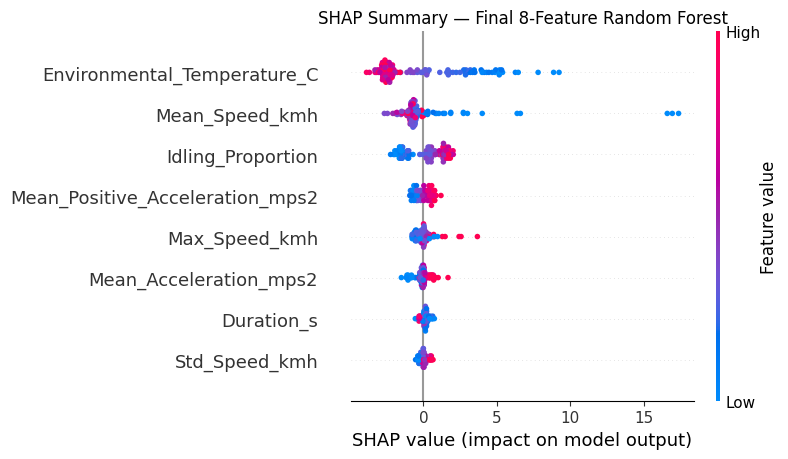

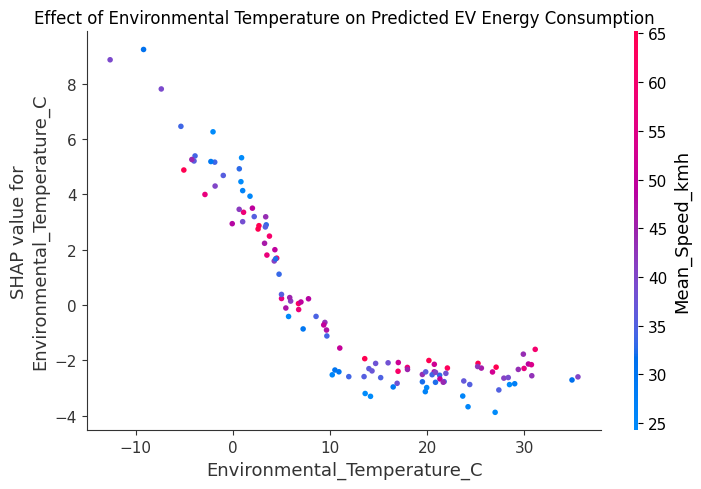

FINAL SHAP FIGURES SAVED
✓ 21_Final_8Feature_SHAP_Beeswarm.png
✓ 22_Final_8Feature_Temperature_SHAP.png


In [177]:
# ============================================================
# Stage 18.6 - Definitive SHAP Figures
# Final 8-Feature Random Forest
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path
import shap


FINAL_RESULTS_DIR = Path(
    r"C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results"
)


# ============================================================
# 1. SHAP Beeswarm
# ============================================================

plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_values_final_8,
    max_display=8,
    show=False
)

plt.title(
    "SHAP Summary — Final 8-Feature Random Forest"
)

plt.tight_layout()

plt.savefig(
    FINAL_RESULTS_DIR /
    "21_Final_8Feature_SHAP_Beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 2. Temperature dependence plot
# ============================================================

shap.dependence_plot(
    "Environmental_Temperature_C",
    shap_values_final_8.values,
    X_test_sensitivity,
    interaction_index="Mean_Speed_kmh",
    show=False
)

plt.title(
    "Effect of Environmental Temperature on "
    "Predicted EV Energy Consumption"
)

plt.tight_layout()

plt.savefig(
    FINAL_RESULTS_DIR /
    "22_Final_8Feature_Temperature_SHAP.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("=" * 75)
print("FINAL SHAP FIGURES SAVED")
print("=" * 75)

print(
    "✓ 21_Final_8Feature_SHAP_Beeswarm.png"
)

print(
    "✓ 22_Final_8Feature_Temperature_SHAP.png"
)

print("=" * 75)

# Stage 18.7 - Final 8-Feature Leave-One-Dataset-Out Validation

In [178]:
# ============================================================
# Stage 18.7 - Final 8-Feature Leave-One-Dataset-Out Validation
# ============================================================

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)


datasets = ["VED", "BMW", "ARGONNE"]

cross_dataset_final_8_results = []


for held_out in datasets:

    # --------------------------------------------------------
    # Split by entire dataset
    # --------------------------------------------------------

    train_mask = master_final["Dataset"] != held_out
    test_mask  = master_final["Dataset"] == held_out

    X_train_cross = master_final.loc[
        train_mask,
        SENSITIVITY_FEATURES
    ]

    y_train_cross = master_final.loc[
        train_mask,
        "Energy_Consumption_kWh_100km"
    ]

    X_test_cross = master_final.loc[
        test_mask,
        SENSITIVITY_FEATURES
    ]

    y_test_cross = master_final.loc[
        test_mask,
        "Energy_Consumption_kWh_100km"
    ]


    # --------------------------------------------------------
    # Same frozen final RF configuration
    # --------------------------------------------------------

    model_cross = RandomForestRegressor(
        n_estimators=600,
        max_depth=16,
        min_samples_split=5,
        min_samples_leaf=4,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )


    # --------------------------------------------------------
    # Train only on the other datasets
    # --------------------------------------------------------

    model_cross.fit(
        X_train_cross,
        y_train_cross
    )


    # --------------------------------------------------------
    # Predict completely held-out dataset
    # --------------------------------------------------------

    pred_cross = model_cross.predict(
        X_test_cross
    )


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    mae_cross = mean_absolute_error(
        y_test_cross,
        pred_cross
    )

    rmse_cross = np.sqrt(
        mean_squared_error(
            y_test_cross,
            pred_cross
        )
    )

    r2_cross = r2_score(
        y_test_cross,
        pred_cross
    )

    mape_cross = mean_absolute_percentage_error(
        y_test_cross,
        pred_cross
    ) * 100


    cross_dataset_final_8_results.append({

        "Held_Out_Dataset": held_out,

        "Train_N":
            len(X_train_cross),

        "Test_N":
            len(X_test_cross),

        "MAE":
            mae_cross,

        "RMSE":
            rmse_cross,

        "R2":
            r2_cross,

        "MAPE_pct":
            mape_cross
    })


    print("=" * 75)
    print(f"HELD-OUT DATASET: {held_out}")
    print("=" * 75)

    print(
        f"Training observations : "
        f"{len(X_train_cross)}"
    )

    print(
        f"Testing observations  : "
        f"{len(X_test_cross)}"
    )

    print()

    print(f"MAE  : {mae_cross:.4f}")
    print(f"RMSE : {rmse_cross:.4f}")
    print(f"R²   : {r2_cross:.4f}")
    print(f"MAPE : {mape_cross:.2f}%")

    print()


# ============================================================
# Final table
# ============================================================

cross_dataset_final_8 = pd.DataFrame(
    cross_dataset_final_8_results
)


print("=" * 75)
print(
    "FINAL 8-FEATURE LEAVE-ONE-DATASET-OUT VALIDATION"
)
print("=" * 75)

display(
    cross_dataset_final_8.round(4)
)

HELD-OUT DATASET: VED
Training observations : 87
Testing observations  : 488

MAE  : 4.7345
RMSE : 6.9253
R²   : 0.1408
MAPE : 37.51%

HELD-OUT DATASET: BMW
Training observations : 507
Testing observations  : 68

MAE  : 2.6745
RMSE : 3.2789
R²   : 0.0886
MAPE : 16.56%

HELD-OUT DATASET: ARGONNE
Training observations : 556
Testing observations  : 19

MAE  : 5.9335
RMSE : 8.3814
R²   : -0.4444
MAPE : 43.99%

FINAL 8-FEATURE LEAVE-ONE-DATASET-OUT VALIDATION


,Held_Out_Dataset,Train_N,Test_N,MAE,RMSE,R2,MAPE_pct
0,VED,87,488,4.7345,6.9253,0.1408,37.5080
1,BMW,507,68,2.6745,3.2789,0.0886,16.5598
2,ARGONNE,556,19,5.9335,8.3814,-0.4444,43.9921


# Stage 19.1 - Definitive Final Model Comparison

In [179]:
# ============================================================
# Stage 19.1 - Definitive Final Model Comparison
# ============================================================

import pandas as pd

final_model_comparison_8 = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "CV_R2_Mean": linear8_cv_r2.mean(),
        "CV_R2_SD": linear8_cv_r2.std(),
        "Holdout_MAE": LINEAR8_MAE,
        "Holdout_RMSE": LINEAR8_RMSE,
        "Holdout_R2": LINEAR8_R2,
        "Holdout_MAPE_pct": LINEAR8_MAPE
    },
    {
        "Model": "Random Forest",
        "CV_R2_Mean": final8_cv_r2.mean(),
        "CV_R2_SD": final8_cv_r2.std(),
        "Holdout_MAE": FINAL8_MAE,
        "Holdout_RMSE": FINAL8_RMSE,
        "Holdout_R2": FINAL8_R2,
        "Holdout_MAPE_pct": FINAL8_MAPE
    },
    {
        "Model": "XGBoost",
        "CV_R2_Mean": xgb8_cv_r2.mean(),
        "CV_R2_SD": xgb8_cv_r2.std(),
        "Holdout_MAE": XGB8_MAE,
        "Holdout_RMSE": XGB8_RMSE,
        "Holdout_R2": XGB8_R2,
        "Holdout_MAPE_pct": XGB8_MAPE
    },
    {
        "Model": "Stacking Ensemble",
        "CV_R2_Mean": stack8_cv_r2.mean(),
        "CV_R2_SD": stack8_cv_r2.std(),
        "Holdout_MAE": STACK8_MAE,
        "Holdout_RMSE": STACK8_RMSE,
        "Holdout_R2": STACK8_R2,
        "Holdout_MAPE_pct": STACK8_MAPE
    }
])

# Rank according to holdout R²
final_model_comparison_8 = (
    final_model_comparison_8
    .sort_values("Holdout_R2", ascending=False)
    .reset_index(drop=True)
)

print("=" * 80)
print("DEFINITIVE FINAL MODEL COMPARISON — 8 HARMONISED FEATURES")
print("=" * 80)

display(final_model_comparison_8.round(4))

print("\nSelected primary model:")
print(final_model_comparison_8.iloc[0]["Model"])

print("=" * 80)

DEFINITIVE FINAL MODEL COMPARISON — 8 HARMONISED FEATURES


,Model,CV_R2_Mean,CV_R2_SD,Holdout_MAE,Holdout_RMSE,Holdout_R2,Holdout_MAPE_pct
0,Random Forest,0.5605,0.0249,3.0322,4.3330,0.4457,20.0844
1,Stacking Ensemble,0.5882,0.0092,3.3403,5.0323,0.2524,21.2179
2,Linear Regression,0.3684,0.0648,3.6449,5.1287,0.2235,25.0025
3,XGBoost,0.5847,0.0180,3.4996,5.3606,0.1517,22.2997



Selected primary model:
Random Forest


# Stage 19.2 - Export Definitive Dissertation Results Package

In [180]:
# ============================================================
# Stage 19.2 - Export Definitive Dissertation Results Package
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import json


# ------------------------------------------------------------
# Output folder
# ------------------------------------------------------------

FINAL_DIR = Path(
    r"C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results"
)

FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 1. FINAL MODEL COMPARISON
# ============================================================

final_model_comparison_8.to_csv(
    FINAL_DIR / "23_Final_8Feature_Model_Comparison.csv",
    index=False
)


# ============================================================
# 2. FINAL CROSS-DATASET VALIDATION
# ============================================================

cross_dataset_final_8.to_csv(
    FINAL_DIR / "24_Final_8Feature_Cross_Dataset_Validation.csv",
    index=False
)


# ============================================================
# 3. FINAL SHAP IMPORTANCE
# ============================================================

shap_importance_final_8.to_csv(
    FINAL_DIR / "25_Final_8Feature_SHAP_Importance.csv",
    index=False
)


# ============================================================
# 4. FINAL HOLDOUT PREDICTIONS
# ============================================================

final_predictions_8 = pd.DataFrame({
    "Actual_kWh_100km":
        y_test_sensitivity.values,

    "Predicted_kWh_100km":
        y_pred_final_8,

    "Residual":
        y_test_sensitivity.values - y_pred_final_8,

    "Absolute_Error":
        np.abs(
            y_test_sensitivity.values - y_pred_final_8
        ),

    "Dataset":
        master_final.loc[
            X_test_sensitivity.index,
            "Dataset"
        ].values
})


final_predictions_8.to_csv(
    FINAL_DIR / "26_Final_8Feature_RF_Test_Predictions.csv",
    index=False
)


# ============================================================
# 5. FINAL FEATURE LIST
# ============================================================

final_feature_table = pd.DataFrame({
    "Feature": SENSITIVITY_FEATURES
})

final_feature_table.to_csv(
    FINAL_DIR / "27_Final_8Feature_List.csv",
    index=False
)


# ============================================================
# 6. SAVE FINAL MODEL
# ============================================================

joblib.dump(
    final_rf_8,
    FINAL_DIR / "28_Final_8Feature_Random_Forest.pkl"
)


# ============================================================
# 7. EXPERIMENT METADATA
# ============================================================

experiment_metadata = {

    "dataset": {
        "total_observations": int(len(master_final)),
        "training_observations": int(len(X_train_sensitivity)),
        "testing_observations": int(len(X_test_sensitivity)),
        "number_of_predictors": int(len(SENSITIVITY_FEATURES)),
        "target": "Energy_Consumption_kWh_100km"
    },

    "selected_model": {
        "name": "RandomForestRegressor",
        "n_estimators": 600,
        "max_depth": 16,
        "min_samples_split": 5,
        "min_samples_leaf": 4,
        "max_features": 1.0,
        "random_state": 42
    },

    "cross_validation": {
        "folds": 5,
        "cv_r2_mean": float(final8_cv_r2.mean()),
        "cv_r2_sd": float(final8_cv_r2.std()),
        "cv_mae_mean": float(final8_cv_mae.mean()),
        "cv_rmse_mean": float(final8_cv_rmse.mean())
    },

    "holdout_performance": {
        "mae": float(FINAL8_MAE),
        "rmse": float(FINAL8_RMSE),
        "r2": float(FINAL8_R2),
        "mape_pct": float(FINAL8_MAPE)
    },

    "excluded_features": [
        "Max_Acceleration_mps2",
        "Min_Acceleration_mps2"
    ],

    "exclusion_reason":
        "Cross-dataset diagnostics indicated substantial "
        "distributional incompatibility in acceleration extrema "
        "between VED, BMW and ARGONNE. Sensitivity analysis showed "
        "that excluding these variables did not materially reduce "
        "predictive performance and produced a more defensible "
        "harmonised feature specification.",

    "temperature_feature":
        "Environmental_Temperature_C"
}


with open(
    FINAL_DIR / "29_Final_Experiment_Metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        experiment_metadata,
        f,
        indent=4
    )


# ============================================================
# 8. FINAL METRICS SUMMARY
# ============================================================

final_metrics_summary = pd.DataFrame([{

    "Model":
        "Random Forest",

    "Features":
        8,

    "Training_N":
        len(X_train_sensitivity),

    "Test_N":
        len(X_test_sensitivity),

    "CV_R2_Mean":
        final8_cv_r2.mean(),

    "CV_R2_SD":
        final8_cv_r2.std(),

    "Holdout_MAE":
        FINAL8_MAE,

    "Holdout_RMSE":
        FINAL8_RMSE,

    "Holdout_R2":
        FINAL8_R2,

    "Holdout_MAPE_pct":
        FINAL8_MAPE

}])


final_metrics_summary.to_csv(
    FINAL_DIR / "30_Final_8Feature_RF_Metrics.csv",
    index=False
)


# ============================================================
# CONFIRM EXPORT
# ============================================================

print("=" * 80)
print("DEFINITIVE DISSERTATION RESULTS PACKAGE EXPORTED")
print("=" * 80)

print("\nOutput folder:")
print(FINAL_DIR)

print("\nFiles:")

files = [
    "21_Final_8Feature_SHAP_Beeswarm.png",
    "22_Final_8Feature_Temperature_SHAP.png",
    "23_Final_8Feature_Model_Comparison.csv",
    "24_Final_8Feature_Cross_Dataset_Validation.csv",
    "25_Final_8Feature_SHAP_Importance.csv",
    "26_Final_8Feature_RF_Test_Predictions.csv",
    "27_Final_8Feature_List.csv",
    "28_Final_8Feature_Random_Forest.pkl",
    "29_Final_Experiment_Metadata.json",
    "30_Final_8Feature_RF_Metrics.csv"
]

for file in files:

    path = FINAL_DIR / file

    if path.exists():
        print(f"✓ {file}")
    else:
        print(f"✗ MISSING: {file}")


print("\n" + "=" * 80)
print("FINAL AUTHORITATIVE MODEL")
print("=" * 80)

print(final_rf_8)

print("\nPerformance:")
print(
    f"CV R²      : "
    f"{final8_cv_r2.mean():.4f} ± "
    f"{final8_cv_r2.std():.4f}"
)
print(f"Holdout R² : {FINAL8_R2:.4f}")
print(f"MAE        : {FINAL8_MAE:.4f} kWh/100 km")
print(f"RMSE       : {FINAL8_RMSE:.4f} kWh/100 km")
print(f"MAPE       : {FINAL8_MAPE:.2f}%")

print("\nPrimary SHAP feature:")
print(
    shap_importance_final_8.iloc[0]["Feature"],
    "—",
    round(
        shap_importance_final_8.iloc[0]["Mean_Absolute_SHAP"],
        4
    )
)

print("=" * 80)

DEFINITIVE DISSERTATION RESULTS PACKAGE EXPORTED

Output folder:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results

Files:
✓ 21_Final_8Feature_SHAP_Beeswarm.png
✓ 22_Final_8Feature_Temperature_SHAP.png
✓ 23_Final_8Feature_Model_Comparison.csv
✓ 24_Final_8Feature_Cross_Dataset_Validation.csv
✓ 25_Final_8Feature_SHAP_Importance.csv
✓ 26_Final_8Feature_RF_Test_Predictions.csv
✓ 27_Final_8Feature_List.csv
✓ 28_Final_8Feature_Random_Forest.pkl
✓ 29_Final_Experiment_Metadata.json
✓ 30_Final_8Feature_RF_Metrics.csv

FINAL AUTHORITATIVE MODEL
RandomForestRegressor(max_depth=16, min_samples_leaf=4, min_samples_split=5,
                      n_estimators=600, n_jobs=-1, random_state=42)

Performance:
CV R²      : 0.5605 ± 0.0249
Holdout R² : 0.4457
MAE        : 3.0322 kWh/100 km
RMSE       : 4.3330 kWh/100 km
MAPE       : 20.08%

Primary SHAP feature:
Environmental_Temperature_C — 2.7417


# Stage 19.3 - CV Leakage / Legacy Variable Audit

In [181]:
# ============================================================
# Stage 19.3 - CV Leakage / Legacy Variable Audit
# ============================================================

print("=" * 80)
print("CV / LEGACY VARIABLE AUDIT")
print("=" * 80)

variables_to_check = [
    # Old/general data
    "X",
    "y",

    # Correct final training data
    "X_train_sensitivity",
    "y_train_sensitivity",

    # Old CV outputs
    "cv_scores",
    "rf_cv_scores",
    "final_cv_scores",
    "stacking_cv_scores",

    # Final authoritative CV outputs
    "final8_cv_r2",
    "linear8_cv_r2",
    "xgb8_cv_r2",
    "stack8_cv_r2"
]

for name in variables_to_check:

    if name in globals():

        obj = globals()[name]

        try:
            shape = obj.shape
        except:
            shape = "N/A"

        try:
            length = len(obj)
        except:
            length = "N/A"

        print(
            f"✓ {name:<25} "
            f"shape={str(shape):<15} "
            f"len={length}"
        )

    else:
        print(f"✗ {name:<25} not defined")


print("\n" + "=" * 80)
print("AUTHORITATIVE CV INPUT")
print("=" * 80)

print(
    "X_train_sensitivity:",
    X_train_sensitivity.shape
)

print(
    "y_train_sensitivity:",
    y_train_sensitivity.shape
)

print("\nExpected:")
print("Training rows = 460")
print("Features      = 8")

print("\nIMPORTANT:")
print(
    "Only CV results generated from the 460-row training "
    "partition are authoritative."
)

print(
    "Any earlier CV performed on X/y containing all 575 "
    "observations is legacy analysis and must not be used "
    "in the dissertation results."
)

print("=" * 80)

CV / LEGACY VARIABLE AUDIT
✓ X                         shape=(575, 9)        len=575
✓ y                         shape=(575,)          len=575
✓ X_train_sensitivity       shape=(460, 8)        len=460
✓ y_train_sensitivity       shape=(460,)          len=460
✓ cv_scores                 shape=(5,)            len=5
✗ rf_cv_scores              not defined
✓ final_cv_scores           shape=(5,)            len=5
✓ stacking_cv_scores        shape=(5,)            len=5
✓ final8_cv_r2              shape=(5,)            len=5
✓ linear8_cv_r2             shape=(5,)            len=5
✓ xgb8_cv_r2                shape=(5,)            len=5
✓ stack8_cv_r2              shape=(5,)            len=5

AUTHORITATIVE CV INPUT
X_train_sensitivity: (460, 8)
y_train_sensitivity: (460,)

Expected:
Training rows = 460
Features      = 8

IMPORTANT:
Only CV results generated from the 460-row training partition are authoritative.
Any earlier CV performed on X/y containing all 575 observations is legacy analysis an

# Stage 19.4 - Freeze Authoritative Results
# Mark Legacy Analysis Explicitly

In [182]:
# ============================================================
# Stage 19.4 - Freeze Authoritative Results
# Mark Legacy Analysis Explicitly
# ============================================================

LEGACY_VARIABLES = [
    "X",
    "y",
    "final_cv_scores",
    "stacking_cv_scores"
]

AUTHORITATIVE_VARIABLES = [
    "X_train_sensitivity",
    "y_train_sensitivity",
    "X_test_sensitivity",
    "y_test_sensitivity",
    "final_rf_8",
    "final8_cv_r2",
    "linear8_cv_r2",
    "xgb8_cv_r2",
    "stack8_cv_r2",
    "final_model_comparison_8",
    "cross_dataset_final_8",
    "shap_importance_final_8"
]

print("=" * 80)
print("FINAL ANALYSIS STATUS")
print("=" * 80)

print("\nLEGACY / SUPERSEDED — DO NOT REPORT:")
for name in LEGACY_VARIABLES:
    status = "exists" if name in globals() else "not defined"
    print(f"⚠ {name:<25} {status}")

print("\nAUTHORITATIVE — USE FOR DISSERTATION:")
for name in AUTHORITATIVE_VARIABLES:
    status = "available" if name in globals() else "MISSING"
    print(f"✓ {name:<25} {status}")

print("\n" + "=" * 80)
print("FINAL EXPERIMENTAL SPECIFICATION")
print("=" * 80)

print("""
Dataset:
    575 harmonised EV observations

Primary modelling specification:
    8 predictors

Training:
    460 observations

Holdout:
    115 observations

Cross-validation:
    5-fold CV on TRAINING DATA ONLY

Selected model:
    Random Forest

Final CV R²:
    0.5605 ± 0.0249

Final holdout:
    MAE  = 3.0322 kWh/100 km
    RMSE = 4.3330 kWh/100 km
    R²   = 0.4457
    MAPE = 20.08%

Primary SHAP feature:
    Environmental_Temperature_C
    Mean |SHAP| = 2.7417

IMPORTANT:
    Results generated using full-dataset X/y CV are
    superseded and must not be reported as final results.
""")

print("=" * 80)
print("MODELLING PIPELINE FROZEN")
print("=" * 80)

FINAL ANALYSIS STATUS

LEGACY / SUPERSEDED — DO NOT REPORT:
⚠ X                         exists
⚠ y                         exists
⚠ final_cv_scores           exists
⚠ stacking_cv_scores        exists

AUTHORITATIVE — USE FOR DISSERTATION:
✓ X_train_sensitivity       available
✓ y_train_sensitivity       available
✓ X_test_sensitivity        available
✓ y_test_sensitivity        available
✓ final_rf_8                available
✓ final8_cv_r2              available
✓ linear8_cv_r2             available
✓ xgb8_cv_r2                available
✓ stack8_cv_r2              available
✓ final_model_comparison_8  available
✓ cross_dataset_final_8     available
✓ shap_importance_final_8   available

FINAL EXPERIMENTAL SPECIFICATION

Dataset:
    575 harmonised EV observations

Primary modelling specification:
    8 predictors

Training:
    460 observations

Holdout:
    115 observations

Cross-validation:
    5-fold CV on TRAINING DATA ONLY

Selected model:
    Random Forest

Final CV R²:
    0.56

# Stage 20.1 - Target Outlier Investigation
# DIAGNOSTIC ONLY — NO OBSERVATIONS REMOVED

In [183]:
# ============================================================
# Stage 20.1 - Target Outlier Investigation
# DIAGNOSTIC ONLY — NO OBSERVATIONS REMOVED
# ============================================================

import pandas as pd
import numpy as np


target = "Energy_Consumption_kWh_100km"

print("=" * 80)
print("TARGET OUTLIER INVESTIGATION")
print("DIAGNOSTIC ONLY — DATASET IS NOT MODIFIED")
print("=" * 80)


# ------------------------------------------------------------
# 1. Overall target distribution
# ------------------------------------------------------------

print("\nOVERALL TARGET DISTRIBUTION")
print("-" * 80)

print(
    master_final[target]
    .describe(
        percentiles=[
            0.01, 0.05, 0.25, 0.50,
            0.75, 0.90, 0.95, 0.975,
            0.99, 0.995
        ]
    )
    .round(4)
)


# ------------------------------------------------------------
# 2. Distribution by source dataset
# ------------------------------------------------------------

print("\nTARGET DISTRIBUTION BY DATASET")
print("-" * 80)

dataset_target_stats = (
    master_final
    .groupby("Dataset")[target]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

display(dataset_target_stats.round(4))


# ------------------------------------------------------------
# 3. Count thresholds
# ------------------------------------------------------------

print("\nEXTREME TARGET COUNTS")
print("-" * 80)

for threshold in [25, 30, 35, 40, 50, 60, 70]:

    mask = master_final[target] > threshold

    print(
        f"> {threshold:2d} kWh/100 km : "
        f"{mask.sum():3d} observations "
        f"({mask.mean()*100:.2f}%)"
    )


# ------------------------------------------------------------
# 4. Show ALL observations > 40
# ------------------------------------------------------------

extreme_40 = (
    master_final[
        master_final[target] > 40
    ]
    .copy()
    .sort_values(
        target,
        ascending=False
    )
)

print("\nOBSERVATIONS ABOVE 40 kWh/100 km")
print("-" * 80)

print(f"Count: {len(extreme_40)}")

display(extreme_40)


# ------------------------------------------------------------
# 5. Detailed VED extremes
# ------------------------------------------------------------

ved_extreme = (
    master_final[
        (master_final["Dataset"] == "VED") &
        (master_final[target] > 40)
    ]
    .copy()
    .sort_values(
        target,
        ascending=False
    )
)

print("\nVED OBSERVATIONS ABOVE 40 kWh/100 km")
print("-" * 80)

display(ved_extreme)


# ------------------------------------------------------------
# 6. Duration of extreme observations
# ------------------------------------------------------------

print("\nEXTREME-TRIP DURATION")
print("-" * 80)

if len(ved_extreme) > 0:

    print(
        ved_extreme["Duration_s"]
        .describe()
        .round(3)
    )

    print("\nIndividual durations:")

    display(
        ved_extreme[
            [
                "Duration_s",
                "Mean_Speed_kmh",
                "Max_Speed_kmh",
                "Environmental_Temperature_C",
                target
            ]
        ].round(4)
    )


# ------------------------------------------------------------
# 7. Approximate travelled distance
#
# This is only a diagnostic estimate:
# mean speed × duration.
# ------------------------------------------------------------

master_outlier_diagnostic = master_final.copy()

master_outlier_diagnostic[
    "Approx_Distance_km"
] = (
    master_outlier_diagnostic["Mean_Speed_kmh"]
    *
    master_outlier_diagnostic["Duration_s"]
    / 3600
)


ved_extreme_diagnostic = (
    master_outlier_diagnostic[
        (master_outlier_diagnostic["Dataset"] == "VED") &
        (master_outlier_diagnostic[target] > 40)
    ]
    .copy()
    .sort_values(
        target,
        ascending=False
    )
)


print("\nVED EXTREMES WITH APPROXIMATE DISTANCE")
print("-" * 80)

display(
    ved_extreme_diagnostic[
        [
            "Mean_Speed_kmh",
            "Duration_s",
            "Approx_Distance_km",
            "Environmental_Temperature_C",
            target
        ]
    ].round(4)
)


# ------------------------------------------------------------
# 8. Compare extreme vs normal VED observations
# ------------------------------------------------------------

ved_all = master_outlier_diagnostic[
    master_outlier_diagnostic["Dataset"] == "VED"
]

ved_normal = ved_all[
    ved_all[target] <= 40
]


comparison = pd.DataFrame({

    "VED_Normal": [
        ved_normal[target].mean(),
        ved_normal["Duration_s"].median(),
        ved_normal["Approx_Distance_km"].median(),
        ved_normal["Mean_Speed_kmh"].median(),
        ved_normal["Environmental_Temperature_C"].median()
    ],

    "VED_Above_40": [
        ved_extreme_diagnostic[target].mean(),
        ved_extreme_diagnostic["Duration_s"].median(),
        ved_extreme_diagnostic["Approx_Distance_km"].median(),
        ved_extreme_diagnostic["Mean_Speed_kmh"].median(),
        ved_extreme_diagnostic[
            "Environmental_Temperature_C"
        ].median()
    ]

}, index=[
    "Mean_Target",
    "Median_Duration_s",
    "Median_Approx_Distance_km",
    "Median_Mean_Speed_kmh",
    "Median_Temperature_C"
])


print("\nVED NORMAL vs >40 COMPARISON")
print("-" * 80)

display(comparison.round(4))


# ------------------------------------------------------------
# Confirmation
# ------------------------------------------------------------

print("=" * 80)
print("DIAGNOSTIC COMPLETE")
print("=" * 80)

print(
    "No rows were removed, capped, winsorised "
    "or otherwise modified."
)

print(
    "Original master_final shape:",
    master_final.shape
)

print("=" * 80)

TARGET OUTLIER INVESTIGATION
DIAGNOSTIC ONLY — DATASET IS NOT MODIFIED

OVERALL TARGET DISTRIBUTION
--------------------------------------------------------------------------------
count    575.0000
mean      16.1494
std        7.1085
min        2.8464
1%         4.2860
5%         7.8542
25%       11.8986
50%       14.9739
75%       18.8274
90%       23.7307
95%       27.0160
97.5%     31.7703
99%       38.9684
99.5%     45.3749
max       79.1631
Name: Energy_Consumption_kWh_100km, dtype: float64

TARGET DISTRIBUTION BY DATASET
--------------------------------------------------------------------------------


,count,mean,median,std,min,max
Dataset,,,,,,
ARGONNE,19,17.3321,15.8133,7.1650,4.0049,37.6903
BMW,68,16.4740,16.5144,3.4601,9.5763,23.3014
VED,488,16.0582,14.5800,7.4790,2.8464,79.1631



EXTREME TARGET COUNTS
--------------------------------------------------------------------------------
> 25 kWh/100 km :  44 observations (7.65%)
> 30 kWh/100 km :  20 observations (3.48%)
> 35 kWh/100 km :  11 observations (1.91%)
> 40 kWh/100 km :   5 observations (0.87%)
> 50 kWh/100 km :   3 observations (0.52%)
> 60 kWh/100 km :   2 observations (0.35%)
> 70 kWh/100 km :   1 observations (0.17%)

OBSERVATIONS ABOVE 40 kWh/100 km
--------------------------------------------------------------------------------
Count: 5


,Mean_Speed_kmh,Max_Speed_kmh,Std_Speed_kmh,Mean_Acceleration_mps2,Max_Acceleration_mps2,Min_Acceleration_mps2,Mean_Positive_Acceleration_mps2,Idling_Proportion,Duration_s,Environmental_Temperature_C,Energy_Consumption_kWh_100km,Dataset
29,11.625928,29.969999,9.445854,0.012040,6.222222,-6.777774,0.166863,0.297634,522.4,-7.500000,79.163078,VED
30,12.185868,71.049995,17.174703,0.007261,9.777779,-9.750001,0.150808,0.527640,2192.2,-6.510276,65.109691,VED
23,16.471678,50.360001,17.043051,-0.033974,8.124999,-8.314815,0.193065,0.383051,388.6,-4.027966,54.308139,VED
15,36.466653,67.299995,24.525640,0.063072,7.888889,-9.472222,0.232789,0.212766,578.9,1.240812,44.040044,VED
48,23.384991,58.989998,16.768524,-0.011981,9.777779,-9.333330,0.217908,0.154270,959.8,-6.791185,41.561471,VED



VED OBSERVATIONS ABOVE 40 kWh/100 km
--------------------------------------------------------------------------------


...


VED EXTREMES WITH APPROXIMATE DISTANCE
--------------------------------------------------------------------------------


,Mean_Speed_kmh,Duration_s,Approx_Distance_km,Environmental_Temperature_C,Energy_Consumption_kWh_100km
29,11.6259,522.4,1.6871,-7.5000,79.1631
30,12.1859,2192.2,7.4205,-6.5103,65.1097
23,16.4717,388.6,1.7780,-4.0280,54.3081
15,36.4667,578.9,5.8640,1.2408,44.0400
48,23.3850,959.8,6.2347,-6.7912,41.5615



VED NORMAL vs >40 COMPARISON
--------------------------------------------------------------------------------


,VED_Normal,VED_Above_40
Mean_Target,15.6360,56.8365
Median_Duration_s,432.3000,578.9000
Median_Approx_Distance_km,4.7685,5.8640
Median_Mean_Speed_kmh,39.5007,16.4717
Median_Temperature_C,11.6146,-6.5103


DIAGNOSTIC COMPLETE
No rows were removed, capped, winsorised or otherwise modified.
Original master_final shape: (575, 12)


# Stage 20.2 - Extreme Target Energy Plausibility Audit
# DIAGNOSTIC ONLY

In [184]:
# ============================================================
# Stage 20.2 - Extreme Target Energy Plausibility Audit
# DIAGNOSTIC ONLY
# ============================================================

audit = master_outlier_diagnostic.copy()

audit["Implied_Trip_Energy_kWh"] = (
    audit["Energy_Consumption_kWh_100km"]
    * audit["Approx_Distance_km"]
    / 100
)

ved_extreme_audit = (
    audit[
        (audit["Dataset"] == "VED") &
        (audit["Energy_Consumption_kWh_100km"] > 40)
    ]
    .copy()
    .sort_values(
        "Energy_Consumption_kWh_100km",
        ascending=False
    )
)

cols = [
    "Mean_Speed_kmh",
    "Duration_s",
    "Approx_Distance_km",
    "Environmental_Temperature_C",
    "Idling_Proportion",
    "Energy_Consumption_kWh_100km",
    "Implied_Trip_Energy_kWh"
]

print("=" * 80)
print("VED EXTREME TARGET ENERGY PLAUSIBILITY")
print("=" * 80)

display(
    ved_extreme_audit[cols].round(4)
)

print("\nImplied trip-energy statistics:")
print(
    ved_extreme_audit[
        "Implied_Trip_Energy_kWh"
    ].describe().round(4)
)

print("=" * 80)

VED EXTREME TARGET ENERGY PLAUSIBILITY


,Mean_Speed_kmh,Duration_s,Approx_Distance_km,Environmental_Temperature_C,Idling_Proportion,Energy_Consumption_kWh_100km,Implied_Trip_Energy_kWh
29,11.6259,522.4,1.6871,-7.5000,0.2976,79.1631,1.3355
30,12.1859,2192.2,7.4205,-6.5103,0.5276,65.1097,4.8315
23,16.4717,388.6,1.7780,-4.0280,0.3831,54.3081,0.9656
15,36.4667,578.9,5.8640,1.2408,0.2128,44.0400,2.5825
48,23.3850,959.8,6.2347,-6.7912,0.1543,41.5615,2.5912



Implied trip-energy statistics:
count    5.0000
mean     2.4613
std      1.5128
min      0.9656
25%      1.3355
50%      2.5825
75%      2.5912
max      4.8315
Name: Implied_Trip_Energy_kWh, dtype: float64


# Stage 20.3 - Distance vs Energy Consumption Audit

In [185]:
# ============================================================
# Stage 20.3 - Distance vs Energy Consumption Audit
# ============================================================

ved_audit = audit[
    audit["Dataset"] == "VED"
].copy()

distance_groups = pd.cut(
    ved_audit["Approx_Distance_km"],
    bins=[0, 2, 5, 10, 20, float("inf")],
    labels=[
        "<2 km",
        "2-5 km",
        "5-10 km",
        "10-20 km",
        ">20 km"
    ]
)

distance_summary = (
    ved_audit
    .assign(Distance_Group=distance_groups)
    .groupby(
        "Distance_Group",
        observed=True
    )["Energy_Consumption_kWh_100km"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

print("=" * 80)
print("VED ENERGY CONSUMPTION BY APPROXIMATE TRIP DISTANCE")
print("=" * 80)

display(distance_summary.round(4))


print("\nExtreme >40 observations by distance group:")

extreme_distance_counts = (
    ved_audit[
        ved_audit[
            "Energy_Consumption_kWh_100km"
        ] > 40
    ]
    .assign(
        Distance_Group=pd.cut(
            ved_audit.loc[
                ved_audit[
                    "Energy_Consumption_kWh_100km"
                ] > 40,
                "Approx_Distance_km"
            ],
            bins=[0, 2, 5, 10, 20, float("inf")],
            labels=[
                "<2 km",
                "2-5 km",
                "5-10 km",
                "10-20 km",
                ">20 km"
            ]
        )
    )["Distance_Group"]
    .value_counts()
    .sort_index()
)

display(extreme_distance_counts)

print("=" * 80)

VED ENERGY CONSUMPTION BY APPROXIMATE TRIP DISTANCE


,count,mean,median,std,min,max
Distance_Group,,,,,,
<2 km,78,17.6286,15.5620,11.5703,2.8464,79.1631
2-5 km,177,15.1630,14.4169,5.9473,4.3650,31.8158
5-10 km,153,16.8587,14.8765,7.7334,3.0822,65.1097
10-20 km,75,14.7725,13.7796,3.5538,9.3960,26.1727
>20 km,5,18.0362,15.3568,5.1660,13.3421,24.9170



Extreme >40 observations by distance group:


Distance_Group
<2 km       2
2-5 km      0
5-10 km     3
10-20 km    0
>20 km      0
Name: count, dtype: int64

# Stage 20.4A - Search Current Kernel for VED Target Variables
# DIAGNOSTIC ONLY

In [186]:
# ============================================================
# Stage 20.4A - Search Current Kernel for VED Target Variables
# DIAGNOSTIC ONLY
# ============================================================

search_terms = [
    "energy",
    "consumption",
    "battery",
    "power",
    "soc",
    "distance",
    "ved"
]

print("=" * 80)
print("CURRENT KERNEL — POSSIBLE TARGET-CONSTRUCTION VARIABLES")
print("=" * 80)

matches = []

# IMPORTANT:
# Create a fixed snapshot so globals() cannot change
# while we iterate through it.
global_names = list(globals().keys())

for name in global_names:

    lower_name = name.lower()

    if any(term in lower_name for term in search_terms):

        try:
            obj = globals()[name]
        except KeyError:
            continue

        try:
            shape = obj.shape
        except Exception:
            shape = "N/A"

        matches.append((name, shape))


for name, shape in sorted(matches):
    print(f"{name:<50} shape={shape}")

print("\nTotal matches:", len(matches))
print("=" * 80)

CURRENT KERNEL — POSSIBLE TARGET-CONSTRUCTION VARIABLES
X_test_ved                                         shape=(488, 9)
X_train_ved                                        shape=(87, 9)
cross_rf_ved                                       shape=N/A
distance_groups                                    shape=(488,)
distance_summary                                   shape=(5, 6)
extreme_distance_counts                            shape=(5,)
pred_ved                                           shape=(488,)
test_data_ved                                      shape=(488, 11)
train_data_ved                                     shape=(87, 11)
ved_all                                            shape=(488, 13)
ved_audit                                          shape=(488, 14)
ved_cross_mae                                      shape=N/A
ved_cross_mape                                     shape=N/A
ved_cross_r2                                       shape=N/A
ved_cross_rmse                                  

## Final Model Selection Criterion

Model selection considered both training-only five-fold cross-validation and
performance on the held-out test partition.

The stacking ensemble achieved the highest mean cross-validation R² (0.5882),
followed closely by XGBoost (0.5847) and Random Forest (0.5605). However, this
cross-validation advantage did not translate to the held-out test data.

Random Forest achieved the strongest holdout performance, with an R² of
0.4457, MAE of 3.0322 kWh/100 km, and RMSE of 4.3330 kWh/100 km. The stacking
ensemble achieved a holdout R² of 0.2524, while XGBoost achieved 0.1517.

Random Forest was therefore retained as the primary predictive model because
it provided the strongest generalisation to unseen holdout observations across
the principal error and goodness-of-fit metrics. Cross-validation results are
reported alongside holdout results to show the stability of model performance
during training and to avoid relying on a single evaluation estimate.

The discrepancy between cross-validation and holdout performance is also
reported as evidence that greater model complexity did not necessarily improve
generalisation in the harmonised multi-source dataset.

# ✅ AUTHORITATIVE DISSERTATION ANALYSIS

Results from this point onward constitute the final corrected analysis used
for dissertation reporting.

Earlier exploratory results are superseded.

The final modelling specification uses eight harmonised predictors, including
environmental temperature, and excludes the dataset-inconsistent maximum and
minimum acceleration extrema.

All cross-validation and hyperparameter optimisation are restricted to the
training partition.

The final model comparison and Random Forest results were independently
reproduced from a fresh kernel.

# STAGE 21 — FRESH-KERNEL REPRODUCIBILITY CHECK

This section reproduces the authoritative final analysis independently
from the saved harmonised dataset.

Legacy exploratory stages are not required for this reproduction.

Authoritative specification:
- 575 harmonised observations
- 8 predictors
- 80/20 stratified train/test split
- random_state = 42
- training-only 5-fold CV
- selected model: Random Forest

# Stage 21.1 - Fresh-Kernel Setup and Data Load

In [187]:
# ============================================================
# Stage 21.1 - Fresh-Kernel Setup and Data Load
# ============================================================

from pathlib import Path

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score
)

from sklearn.ensemble import (
    RandomForestRegressor,
    StackingRegressor
)

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

import xgboost as xgb
import shap


# ------------------------------------------------------------
# Load authoritative harmonised dataset
# ------------------------------------------------------------

DATA_PATH = Path(
    r"C:\Projects\DS7010_Dissertation\01-Datasets\Harmonised\Master_EV_Dataset_With_Temperature.csv"
)

fresh_master = pd.read_csv(DATA_PATH)


# ------------------------------------------------------------
# Final 8-feature specification
# ------------------------------------------------------------

FRESH_FEATURES = [
    "Mean_Speed_kmh",
    "Max_Speed_kmh",
    "Std_Speed_kmh",
    "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion",
    "Duration_s",
    "Environmental_Temperature_C"
]

FRESH_TARGET = "Energy_Consumption_kWh_100km"


X_fresh = fresh_master[FRESH_FEATURES].copy()

y_fresh = fresh_master[FRESH_TARGET].copy()

dataset_fresh = fresh_master["Dataset"].copy()


print("=" * 80)
print("FRESH-KERNEL DATA LOAD")
print("=" * 80)

print("\nShape:")
print(fresh_master.shape)

print("\nPredictors:")
print(len(FRESH_FEATURES))

print("\nMissing values:")
print(fresh_master.isna().sum().sum())

print("\nDuplicates:")
print(fresh_master.duplicated().sum())

print("\nDataset distribution:")
print(fresh_master["Dataset"].value_counts())

print("=" * 80)

FRESH-KERNEL DATA LOAD

Shape:
(575, 12)

Predictors:
8

Missing values:
0

Duplicates:
0

Dataset distribution:
Dataset
VED        488
BMW         68
ARGONNE     19
Name: count, dtype: int64


# Stage 21.2 - Reproduce Final Train/Test Split

In [188]:
# ============================================================
# Stage 21.2 - Reproduce Final Train/Test Split
# ============================================================

X_train_fresh, X_test_fresh, \
y_train_fresh, y_test_fresh, \
dataset_train_fresh, dataset_test_fresh = train_test_split(
    X_fresh,
    y_fresh,
    dataset_fresh,
    test_size=0.20,
    random_state=42,
    stratify=dataset_fresh
)


fresh_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


print("=" * 80)
print("FRESH-KERNEL TRAIN / TEST SPLIT")
print("=" * 80)

print("\nTraining:")
print(X_train_fresh.shape)

print("\nTesting:")
print(X_test_fresh.shape)

print("\nTraining distribution:")
print(dataset_train_fresh.value_counts())

print("\nTesting distribution:")
print(dataset_test_fresh.value_counts())

print(
    "\nIndex overlap:",
    len(
        set(X_train_fresh.index)
        .intersection(X_test_fresh.index)
    )
)

print("=" * 80)

FRESH-KERNEL TRAIN / TEST SPLIT

Training:
(460, 8)

Testing:
(115, 8)

Training distribution:
Dataset
VED        391
BMW         54
ARGONNE     15
Name: count, dtype: int64

Testing distribution:
Dataset
VED        97
BMW        14
ARGONNE     4
Name: count, dtype: int64

Index overlap: 0


# Stage 21.3 - Fresh-Kernel Final Random Forest CV

In [189]:
# ============================================================
# Stage 21.3 - Fresh-Kernel Final Random Forest CV
# ============================================================

from sklearn.model_selection import cross_validate

rf_fresh = RandomForestRegressor(
    n_estimators=600,
    max_depth=16,
    min_samples_split=5,
    min_samples_leaf=4,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error"
}

cv_results_fresh = cross_validate(
    rf_fresh,
    X_train_fresh,
    y_train_fresh,
    cv=fresh_cv,
    scoring=scoring,
    n_jobs=-1
)

fresh_cv_r2 = cv_results_fresh["test_r2"]
fresh_cv_mae = -cv_results_fresh["test_mae"]
fresh_cv_rmse = -cv_results_fresh["test_rmse"]

print("=" * 80)
print("FRESH-KERNEL FINAL RANDOM FOREST")
print("TRAINING-ONLY 5-FOLD CROSS-VALIDATION")
print("=" * 80)

print("\nR² by fold:")

for i, score in enumerate(fresh_cv_r2, start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nCross-validation summary:")

print(
    f"R²   = {fresh_cv_r2.mean():.4f} "
    f"± {fresh_cv_r2.std():.4f}"
)

print(
    f"MAE  = {fresh_cv_mae.mean():.4f} "
    f"± {fresh_cv_mae.std():.4f}"
)

print(
    f"RMSE = {fresh_cv_rmse.mean():.4f} "
    f"± {fresh_cv_rmse.std():.4f}"
)

print("=" * 80)

FRESH-KERNEL FINAL RANDOM FOREST
TRAINING-ONLY 5-FOLD CROSS-VALIDATION

R² by fold:
Fold 1: 0.5864
Fold 2: 0.5805
Fold 3: 0.5613
Fold 4: 0.5587
Fold 5: 0.5155

Cross-validation summary:
R²   = 0.5605 ± 0.0249
MAE  = 3.2651 ± 0.1888
RMSE = 4.8644 ± 0.8119


# Stage 21.4 - Fresh-Kernel RF Holdout Reproduction

In [190]:
# ============================================================
# Stage 21.4 - Fresh-Kernel RF Holdout Reproduction
# ============================================================

rf_fresh.fit(
    X_train_fresh,
    y_train_fresh
)

pred_fresh = rf_fresh.predict(
    X_test_fresh
)

fresh_mae = mean_absolute_error(
    y_test_fresh,
    pred_fresh
)

fresh_rmse = np.sqrt(
    mean_squared_error(
        y_test_fresh,
        pred_fresh
    )
)

fresh_r2 = r2_score(
    y_test_fresh,
    pred_fresh
)

fresh_mape = (
    mean_absolute_percentage_error(
        y_test_fresh,
        pred_fresh
    ) * 100
)

print("=" * 80)
print("FRESH-KERNEL RANDOM FOREST")
print("HOLDOUT REPRODUCTION")
print("=" * 80)

print(f"\nMAE  : {fresh_mae:.4f} kWh/100 km")
print(f"RMSE : {fresh_rmse:.4f} kWh/100 km")
print(f"R²   : {fresh_r2:.4f}")
print(f"MAPE : {fresh_mape:.2f}%")

print("\nExpected authoritative values:")
print("MAE  : 3.0322")
print("RMSE : 4.3330")
print("R²   : 0.4457")
print("MAPE : 20.08%")

print("=" * 80)

FRESH-KERNEL RANDOM FOREST
HOLDOUT REPRODUCTION

MAE  : 3.0322 kWh/100 km
RMSE : 4.3330 kWh/100 km
R²   : 0.4457
MAPE : 20.08%

Expected authoritative values:
MAE  : 3.0322
RMSE : 4.3330
R²   : 0.4457
MAPE : 20.08%


# Stage 21.5 - Fresh-Kernel Linear Regression

In [191]:
# ============================================================
# Stage 21.5 - Fresh-Kernel Linear Regression
# ============================================================

linear_fresh = LinearRegression()

linear_cv = cross_validate(
    linear_fresh,
    X_train_fresh,
    y_train_fresh,
    cv=fresh_cv,
    scoring=scoring,
    n_jobs=-1
)

linear_cv_r2_fresh = linear_cv["test_r2"]
linear_cv_mae_fresh = -linear_cv["test_mae"]
linear_cv_rmse_fresh = -linear_cv["test_rmse"]

linear_fresh.fit(
    X_train_fresh,
    y_train_fresh
)

linear_pred_fresh = linear_fresh.predict(
    X_test_fresh
)

linear_holdout_mae = mean_absolute_error(
    y_test_fresh,
    linear_pred_fresh
)

linear_holdout_rmse = np.sqrt(
    mean_squared_error(
        y_test_fresh,
        linear_pred_fresh
    )
)

linear_holdout_r2 = r2_score(
    y_test_fresh,
    linear_pred_fresh
)

linear_holdout_mape = (
    mean_absolute_percentage_error(
        y_test_fresh,
        linear_pred_fresh
    ) * 100
)

print("=" * 80)
print("FRESH-KERNEL LINEAR REGRESSION")
print("=" * 80)

print("\nTraining-only CV:")
print(
    f"R²   : {linear_cv_r2_fresh.mean():.4f} "
    f"± {linear_cv_r2_fresh.std():.4f}"
)
print(
    f"MAE  : {linear_cv_mae_fresh.mean():.4f} "
    f"± {linear_cv_mae_fresh.std():.4f}"
)
print(
    f"RMSE : {linear_cv_rmse_fresh.mean():.4f} "
    f"± {linear_cv_rmse_fresh.std():.4f}"
)

print("\nHoldout:")
print(f"MAE  : {linear_holdout_mae:.4f}")
print(f"RMSE : {linear_holdout_rmse:.4f}")
print(f"R²   : {linear_holdout_r2:.4f}")
print(f"MAPE : {linear_holdout_mape:.2f}%")

print("=" * 80)

FRESH-KERNEL LINEAR REGRESSION

Training-only CV:
R²   : 0.3684 ± 0.0648
MAE  : 3.8652 ± 0.2492
RMSE : 5.7984 ± 0.8037

Holdout:
MAE  : 3.6449
RMSE : 5.1287
R²   : 0.2235
MAPE : 25.00%


# Stage 21.6 - Fresh-Kernel Frozen XGBoost

In [192]:
# ============================================================
# Stage 21.6 - Fresh-Kernel Frozen XGBoost
# ============================================================

xgb_fresh = xgb.XGBRegressor(
    n_estimators=350,
    max_depth=2,
    learning_rate=0.05021266653611523,
    subsample=0.8628010638054672,
    colsample_bytree=0.7066540909352889,
    min_child_weight=4,
    reg_alpha=1.9419334132641555,
    reg_lambda=3.394079430557259,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_cv_fresh = cross_validate(
    xgb_fresh,
    X_train_fresh,
    y_train_fresh,
    cv=fresh_cv,
    scoring=scoring,
    n_jobs=-1
)

xgb_cv_r2_fresh = xgb_cv_fresh["test_r2"]
xgb_cv_mae_fresh = -xgb_cv_fresh["test_mae"]
xgb_cv_rmse_fresh = -xgb_cv_fresh["test_rmse"]

xgb_fresh.fit(
    X_train_fresh,
    y_train_fresh
)

xgb_pred_fresh = xgb_fresh.predict(
    X_test_fresh
)

xgb_holdout_mae = mean_absolute_error(
    y_test_fresh,
    xgb_pred_fresh
)

xgb_holdout_rmse = np.sqrt(
    mean_squared_error(
        y_test_fresh,
        xgb_pred_fresh
    )
)

xgb_holdout_r2 = r2_score(
    y_test_fresh,
    xgb_pred_fresh
)

xgb_holdout_mape = (
    mean_absolute_percentage_error(
        y_test_fresh,
        xgb_pred_fresh
    ) * 100
)

print("=" * 80)
print("FRESH-KERNEL XGBOOST")
print("=" * 80)

print("\nTraining-only CV:")
print(
    f"R²   : {xgb_cv_r2_fresh.mean():.4f} "
    f"± {xgb_cv_r2_fresh.std():.4f}"
)
print(
    f"MAE  : {xgb_cv_mae_fresh.mean():.4f} "
    f"± {xgb_cv_mae_fresh.std():.4f}"
)
print(
    f"RMSE : {xgb_cv_rmse_fresh.mean():.4f} "
    f"± {xgb_cv_rmse_fresh.std():.4f}"
)

print("\nHoldout:")
print(f"MAE  : {xgb_holdout_mae:.4f}")
print(f"RMSE : {xgb_holdout_rmse:.4f}")
print(f"R²   : {xgb_holdout_r2:.4f}")
print(f"MAPE : {xgb_holdout_mape:.2f}%")

print("=" * 80)

FRESH-KERNEL XGBOOST

Training-only CV:
R²   : 0.5847 ± 0.0180
MAE  : 3.2265 ± 0.1476
RMSE : 4.6982 ± 0.5533

Holdout:
MAE  : 3.4996
RMSE : 5.3606
R²   : 0.1517
MAPE : 22.30%


# Stage 21.7 - Fresh-Kernel Stacking Ensemble

In [193]:
# ============================================================
# Stage 21.7 - Fresh-Kernel Stacking Ensemble
# ============================================================

from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression


# Frozen base models
rf_stack_fresh = RandomForestRegressor(
    n_estimators=600,
    max_depth=16,
    min_samples_split=5,
    min_samples_leaf=4,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

xgb_stack_fresh = xgb.XGBRegressor(
    n_estimators=350,
    max_depth=2,
    learning_rate=0.05021266653611523,
    subsample=0.8628010638054672,
    colsample_bytree=0.7066540909352889,
    min_child_weight=4,
    reg_alpha=1.9419334132641555,
    reg_lambda=3.394079430557259,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


stack_fresh = StackingRegressor(
    estimators=[
        ("rf", rf_stack_fresh),
        ("xgb", xgb_stack_fresh)
    ],
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=-1
)


# ------------------------------------------------------------
# Training-only CV
# ------------------------------------------------------------

stack_cv_fresh = cross_validate(
    stack_fresh,
    X_train_fresh,
    y_train_fresh,
    cv=fresh_cv,
    scoring=scoring,
    n_jobs=-1
)

stack_cv_r2_fresh = stack_cv_fresh["test_r2"]
stack_cv_mae_fresh = -stack_cv_fresh["test_mae"]
stack_cv_rmse_fresh = -stack_cv_fresh["test_rmse"]


# ------------------------------------------------------------
# Final fit
# ------------------------------------------------------------

stack_fresh.fit(
    X_train_fresh,
    y_train_fresh
)

stack_pred_fresh = stack_fresh.predict(
    X_test_fresh
)


# ------------------------------------------------------------
# Holdout metrics
# ------------------------------------------------------------

stack_holdout_mae = mean_absolute_error(
    y_test_fresh,
    stack_pred_fresh
)

stack_holdout_rmse = np.sqrt(
    mean_squared_error(
        y_test_fresh,
        stack_pred_fresh
    )
)

stack_holdout_r2 = r2_score(
    y_test_fresh,
    stack_pred_fresh
)

stack_holdout_mape = (
    mean_absolute_percentage_error(
        y_test_fresh,
        stack_pred_fresh
    ) * 100
)


print("=" * 80)
print("FRESH-KERNEL STACKING ENSEMBLE")
print("=" * 80)

print("\nTraining-only CV:")

print(
    f"R²   : {stack_cv_r2_fresh.mean():.4f} "
    f"± {stack_cv_r2_fresh.std():.4f}"
)

print(
    f"MAE  : {stack_cv_mae_fresh.mean():.4f} "
    f"± {stack_cv_mae_fresh.std():.4f}"
)

print(
    f"RMSE : {stack_cv_rmse_fresh.mean():.4f} "
    f"± {stack_cv_rmse_fresh.std():.4f}"
)

print("\nHoldout:")

print(f"MAE  : {stack_holdout_mae:.4f}")
print(f"RMSE : {stack_holdout_rmse:.4f}")
print(f"R²   : {stack_holdout_r2:.4f}")
print(f"MAPE : {stack_holdout_mape:.2f}%")

print("=" * 80)

FRESH-KERNEL STACKING ENSEMBLE

Training-only CV:
R²   : 0.5882 ± 0.0092
MAE  : 3.2206 ± 0.1797
RMSE : 4.6899 ± 0.6359

Holdout:
MAE  : 3.3403
RMSE : 5.0323
R²   : 0.2524
MAPE : 21.22%


# Stage 21.8 - Final Fresh-Kernel Reproducibility Verification

In [194]:
# ============================================================
# Stage 21.8 - Final Fresh-Kernel Reproducibility Verification
# ============================================================

import pandas as pd
import numpy as np

verification = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "CV_R2": linear_cv_r2_fresh.mean(),
        "Holdout_MAE": linear_holdout_mae,
        "Holdout_RMSE": linear_holdout_rmse,
        "Holdout_R2": linear_holdout_r2,
        "Holdout_MAPE_pct": linear_holdout_mape
    },
    {
        "Model": "Random Forest",
        "CV_R2": fresh_cv_r2.mean(),
        "Holdout_MAE": fresh_mae,
        "Holdout_RMSE": fresh_rmse,
        "Holdout_R2": fresh_r2,
        "Holdout_MAPE_pct": fresh_mape
    },
    {
        "Model": "XGBoost",
        "CV_R2": xgb_cv_r2_fresh.mean(),
        "Holdout_MAE": xgb_holdout_mae,
        "Holdout_RMSE": xgb_holdout_rmse,
        "Holdout_R2": xgb_holdout_r2,
        "Holdout_MAPE_pct": xgb_holdout_mape
    },
    {
        "Model": "Stacking Ensemble",
        "CV_R2": stack_cv_r2_fresh.mean(),
        "Holdout_MAE": stack_holdout_mae,
        "Holdout_RMSE": stack_holdout_rmse,
        "Holdout_R2": stack_holdout_r2,
        "Holdout_MAPE_pct": stack_holdout_mape
    }
])

verification = (
    verification
    .sort_values("Holdout_R2", ascending=False)
    .reset_index(drop=True)
)

print("=" * 80)
print("FRESH-KERNEL REPRODUCIBILITY — FINAL MODEL COMPARISON")
print("=" * 80)

display(verification.round(4))

print("\nPrimary model based on holdout generalisation:")
print(verification.iloc[0]["Model"])

print("\nExpected Random Forest:")
print("CV R²       = 0.5605")
print("Holdout MAE = 3.0322")
print("Holdout RMSE= 4.3330")
print("Holdout R²  = 0.4457")
print("MAPE        = 20.08%")

rf_row = verification[
    verification["Model"] == "Random Forest"
].iloc[0]

checks = {
    "CV R²": np.isclose(rf_row["CV_R2"], 0.5605, atol=0.0001),
    "MAE": np.isclose(rf_row["Holdout_MAE"], 3.0322, atol=0.0001),
    "RMSE": np.isclose(rf_row["Holdout_RMSE"], 4.3330, atol=0.0001),
    "R²": np.isclose(rf_row["Holdout_R2"], 0.4457, atol=0.0001),
    "MAPE": np.isclose(rf_row["Holdout_MAPE_pct"], 20.08, atol=0.01)
}

print("\nRandom Forest verification:")

for metric, passed in checks.items():
    print(
        f"{'✓' if passed else '✗'} "
        f"{metric}: "
        f"{'MATCH' if passed else 'CHECK REQUIRED'}"
    )

if all(checks.values()):
    print("\n" + "=" * 80)
    print("REPRODUCIBILITY STATUS: PASSED")
    print("=" * 80)
else:
    print("\nREPRODUCIBILITY STATUS: CHECK REQUIRED")

FRESH-KERNEL REPRODUCIBILITY — FINAL MODEL COMPARISON


,Model,CV_R2,Holdout_MAE,Holdout_RMSE,Holdout_R2,Holdout_MAPE_pct
0,Random Forest,0.5605,3.0322,4.3330,0.4457,20.0844
1,Stacking Ensemble,0.5882,3.3403,5.0323,0.2524,21.2179
2,Linear Regression,0.3684,3.6449,5.1287,0.2235,25.0025
3,XGBoost,0.5847,3.4996,5.3606,0.1517,22.2997



Primary model based on holdout generalisation:
Random Forest

Expected Random Forest:
CV R²       = 0.5605
Holdout MAE = 3.0322
Holdout RMSE= 4.3330
Holdout R²  = 0.4457
MAPE        = 20.08%

Random Forest verification:
✓ CV R²: MATCH
✓ MAE: MATCH
✓ RMSE: MATCH
✓ R²: MATCH
✓ MAPE: MATCH

REPRODUCIBILITY STATUS: PASSED


# Stage 22.1 - Locate 10_1674_1 in Final Harmonised Dataset
# DIAGNOSTIC ONLY

In [195]:
# ============================================================
# Stage 22.1 - Locate 10_1674_1 in Final Harmonised Dataset
# DIAGNOSTIC ONLY
# ============================================================

candidate_1674 = fresh_master[
    (fresh_master["Dataset"] == "VED") &
    np.isclose(
        fresh_master["Mean_Speed_kmh"],
        36.466653,
        atol=0.001
    ) &
    np.isclose(
        fresh_master["Duration_s"],
        578.9,
        atol=0.1
    ) &
    np.isclose(
        fresh_master["Energy_Consumption_kWh_100km"],
        44.040044,
        atol=0.001
    )
]

print("=" * 80)
print("SENSITIVITY TARGET — SEGMENT 10_1674_1")
print("=" * 80)

print("\nMatches found:", len(candidate_1674))

display(candidate_1674)

print("=" * 80)

SENSITIVITY TARGET — SEGMENT 10_1674_1

Matches found: 1


,Mean_Speed_kmh,Max_Speed_kmh,Std_Speed_kmh,Mean_Acceleration_mps2,Max_Acceleration_mps2,Min_Acceleration_mps2,Mean_Positive_Acceleration_mps2,Idling_Proportion,Duration_s,Environmental_Temperature_C,Energy_Consumption_kWh_100km,Dataset
15,36.466653,67.299995,24.52564,0.063072,7.888889,-9.472222,0.232789,0.212766,578.9,1.240812,44.040044,VED


# Stage 22.2 - Determine Original Split Membership

In [196]:
# ============================================================
# Stage 22.2 - Determine Original Split Membership
# ============================================================

segment_index_1674 = candidate_1674.index[0]

print("=" * 80)
print("SEGMENT 10_1674_1 — ORIGINAL SPLIT MEMBERSHIP")
print("=" * 80)

print("Master index:", segment_index_1674)

if segment_index_1674 in X_train_fresh.index:
    print("Location: TRAINING PARTITION")

elif segment_index_1674 in X_test_fresh.index:
    print("Location: HOLDOUT PARTITION")

else:
    print("Location: ERROR — index not found in split")

print("\nTarget:")
print(
    fresh_master.loc[
        segment_index_1674,
        "Energy_Consumption_kWh_100km"
    ]
)

print("=" * 80)

SEGMENT 10_1674_1 — ORIGINAL SPLIT MEMBERSHIP
Master index: 15
Location: TRAINING PARTITION

Target:
44.04004417606841


# Stage 22.3 - RF Sensitivity Analysis
# Remove ONLY Segment 10_1674_1 from Training
# Holdout remains completely unchanged

In [197]:
# ============================================================
# Stage 22.3 - RF Sensitivity Analysis
# Remove ONLY Segment 10_1674_1 from Training
# Holdout remains completely unchanged
# ============================================================

# Remove the identified observation ONLY from training
X_train_no1674 = X_train_fresh.drop(
    index=segment_index_1674
)

y_train_no1674 = y_train_fresh.drop(
    index=segment_index_1674
)

print("=" * 80)
print("10_1674_1 SENSITIVITY ANALYSIS")
print("=" * 80)

print("\nOriginal training observations:")
print(len(X_train_fresh))

print("\nSensitivity training observations:")
print(len(X_train_no1674))

print("\nHoldout observations — unchanged:")
print(len(X_test_fresh))

print(
    "\nSegment still in training:",
    segment_index_1674 in X_train_no1674.index
)

print(
    "Segment in holdout:",
    segment_index_1674 in X_test_fresh.index
)


# ------------------------------------------------------------
# Same frozen Random Forest
# NO retuning
# ------------------------------------------------------------

rf_no1674 = RandomForestRegressor(
    n_estimators=600,
    max_depth=16,
    min_samples_split=5,
    min_samples_leaf=4,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# Training-only 5-fold CV
# ------------------------------------------------------------

cv_no1674 = cross_validate(
    rf_no1674,
    X_train_no1674,
    y_train_no1674,
    cv=fresh_cv,
    scoring=scoring,
    n_jobs=-1
)

cv_r2_no1674 = cv_no1674["test_r2"]
cv_mae_no1674 = -cv_no1674["test_mae"]
cv_rmse_no1674 = -cv_no1674["test_rmse"]


# ------------------------------------------------------------
# Fit sensitivity model
# ------------------------------------------------------------

rf_no1674.fit(
    X_train_no1674,
    y_train_no1674
)

pred_no1674 = rf_no1674.predict(
    X_test_fresh
)


# ------------------------------------------------------------
# Same untouched holdout evaluation
# ------------------------------------------------------------

mae_no1674 = mean_absolute_error(
    y_test_fresh,
    pred_no1674
)

rmse_no1674 = np.sqrt(
    mean_squared_error(
        y_test_fresh,
        pred_no1674
    )
)

r2_no1674 = r2_score(
    y_test_fresh,
    pred_no1674
)

mape_no1674 = (
    mean_absolute_percentage_error(
        y_test_fresh,
        pred_no1674
    ) * 100
)


print("\n" + "=" * 80)
print("SENSITIVITY RESULTS")
print("=" * 80)

print("\nTraining-only CV:")
print(
    f"R²   = {cv_r2_no1674.mean():.4f} "
    f"± {cv_r2_no1674.std():.4f}"
)
print(
    f"MAE  = {cv_mae_no1674.mean():.4f} "
    f"± {cv_mae_no1674.std():.4f}"
)
print(
    f"RMSE = {cv_rmse_no1674.mean():.4f} "
    f"± {cv_rmse_no1674.std():.4f}"
)

print("\nHoldout:")
print(f"MAE  = {mae_no1674:.4f}")
print(f"RMSE = {rmse_no1674:.4f}")
print(f"R²   = {r2_no1674:.4f}")
print(f"MAPE = {mape_no1674:.2f}%")

print("=" * 80)

10_1674_1 SENSITIVITY ANALYSIS

Original training observations:
460

Sensitivity training observations:
459

Holdout observations — unchanged:
115

Segment still in training: False
Segment in holdout: False

SENSITIVITY RESULTS

Training-only CV:
R²   = 0.4444 ± 0.1250
MAE  = 3.3898 ± 0.4486
RMSE = 5.1160 ± 1.3963

Holdout:
MAE  = 3.0079
RMSE = 4.2824
R²   = 0.4586
MAPE = 19.92%


# Stage 22.4 - Original vs Exclusion Sensitivity Comparison

In [198]:
# ============================================================
# Stage 22.4 - Original vs Exclusion Sensitivity Comparison
# ============================================================

sensitivity_comparison = pd.DataFrame([
    {
        "Analysis": "Primary — All 575",
        "Train_N": len(X_train_fresh),
        "Test_N": len(X_test_fresh),
        "CV_R2": fresh_cv_r2.mean(),
        "Holdout_MAE": fresh_mae,
        "Holdout_RMSE": fresh_rmse,
        "Holdout_R2": fresh_r2,
        "Holdout_MAPE_pct": fresh_mape
    },
    {
        "Analysis": "Sensitivity — Exclude 10_1674_1",
        "Train_N": len(X_train_no1674),
        "Test_N": len(X_test_fresh),
        "CV_R2": cv_r2_no1674.mean(),
        "Holdout_MAE": mae_no1674,
        "Holdout_RMSE": rmse_no1674,
        "Holdout_R2": r2_no1674,
        "Holdout_MAPE_pct": mape_no1674
    }
])

display(sensitivity_comparison.round(4))


print("\nCHANGE AFTER EXCLUDING 10_1674_1")
print("=" * 60)

print(
    f"Δ CV R²      : "
    f"{cv_r2_no1674.mean() - fresh_cv_r2.mean():+.4f}"
)

print(
    f"Δ Holdout R² : "
    f"{r2_no1674 - fresh_r2:+.4f}"
)

print(
    f"Δ MAE        : "
    f"{mae_no1674 - fresh_mae:+.4f}"
)

print(
    f"Δ RMSE       : "
    f"{rmse_no1674 - fresh_rmse:+.4f}"
)

print(
    f"Δ MAPE       : "
    f"{mape_no1674 - fresh_mape:+.2f} percentage points"
)

print("=" * 60)

,Analysis,Train_N,Test_N,CV_R2,Holdout_MAE,Holdout_RMSE,Holdout_R2,Holdout_MAPE_pct
0,Primary — All 575,460,115,0.5605,3.0322,4.3330,0.4457,20.0844
1,Sensitivity — Exclude 10_1674_1,459,115,0.4444,3.0079,4.2824,0.4586,19.9246



CHANGE AFTER EXCLUDING 10_1674_1
Δ CV R²      : -0.1161
Δ Holdout R² : +0.0129
Δ MAE        : -0.0243
Δ RMSE       : -0.0507
Δ MAPE       : -0.16 percentage points


# Stage 23.1 - Paired Bootstrap Holdout Uncertainty
# FINAL MODELS — SAME 115 HOLDOUT OBSERVATIONS

In [199]:
# ============================================================
# Stage 23.1 - Paired Bootstrap Holdout Uncertainty
# FINAL MODELS — SAME 115 HOLDOUT OBSERVATIONS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# Convert to aligned NumPy arrays
# ------------------------------------------------------------

y_boot = np.asarray(y_test_fresh)

predictions_boot = {
    "Random Forest": np.asarray(pred_fresh),
    "Stacking": np.asarray(stack_pred_fresh),
    "XGBoost": np.asarray(xgb_pred_fresh),
    "Linear Regression": np.asarray(linear_pred_fresh)
}

n = len(y_boot)

print("=" * 90)
print("PAIRED BOOTSTRAP — HOLDOUT UNCERTAINTY")
print("=" * 90)

print("\nHoldout observations:", n)

for name, pred in predictions_boot.items():
    print(
        f"{name:20s}: "
        f"{len(pred)} predictions"
    )

# ------------------------------------------------------------
# Bootstrap
# ------------------------------------------------------------

N_BOOT = 5000
rng = np.random.default_rng(42)

bootstrap_results = {
    model: {
        "MAE": [],
        "RMSE": [],
        "R2": []
    }
    for model in predictions_boot
}

# Store paired differences:
# positive ΔR² means RF is better
# negative ΔMAE/RMSE means RF is better

paired_differences = {
    model: {
        "Delta_R2_RF_minus_Model": [],
        "Delta_MAE_RF_minus_Model": [],
        "Delta_RMSE_RF_minus_Model": []
    }
    for model in [
        "Stacking",
        "XGBoost",
        "Linear Regression"
    ]
}

valid_bootstraps = 0

for _ in range(N_BOOT):

    idx = rng.integers(
        0,
        n,
        size=n
    )

    y_b = y_boot[idx]

    # R² is undefined if bootstrap target has zero variance.
    # Extremely unlikely here, but skip defensively.
    if np.var(y_b) == 0:
        continue

    metrics_this_boot = {}

    for model, pred in predictions_boot.items():

        pred_b = pred[idx]

        mae_b = mean_absolute_error(
            y_b,
            pred_b
        )

        rmse_b = np.sqrt(
            mean_squared_error(
                y_b,
                pred_b
            )
        )

        r2_b = r2_score(
            y_b,
            pred_b
        )

        bootstrap_results[model]["MAE"].append(mae_b)
        bootstrap_results[model]["RMSE"].append(rmse_b)
        bootstrap_results[model]["R2"].append(r2_b)

        metrics_this_boot[model] = {
            "MAE": mae_b,
            "RMSE": rmse_b,
            "R2": r2_b
        }

    # Paired RF-versus-other differences
    for model in [
        "Stacking",
        "XGBoost",
        "Linear Regression"
    ]:

        paired_differences[model][
            "Delta_R2_RF_minus_Model"
        ].append(
            metrics_this_boot["Random Forest"]["R2"]
            -
            metrics_this_boot[model]["R2"]
        )

        paired_differences[model][
            "Delta_MAE_RF_minus_Model"
        ].append(
            metrics_this_boot["Random Forest"]["MAE"]
            -
            metrics_this_boot[model]["MAE"]
        )

        paired_differences[model][
            "Delta_RMSE_RF_minus_Model"
        ].append(
            metrics_this_boot["Random Forest"]["RMSE"]
            -
            metrics_this_boot[model]["RMSE"]
        )

    valid_bootstraps += 1


print("\nRequested bootstrap samples:", N_BOOT)
print("Valid bootstrap samples    :", valid_bootstraps)

print("=" * 90)

PAIRED BOOTSTRAP — HOLDOUT UNCERTAINTY

Holdout observations: 115
Random Forest       : 115 predictions
Stacking            : 115 predictions
XGBoost             : 115 predictions
Linear Regression   : 115 predictions

Requested bootstrap samples: 5000
Valid bootstrap samples    : 5000


# Stage 23.2 - Bootstrap Confidence Intervals

In [200]:
# ============================================================
# Stage 23.2 - Bootstrap Confidence Intervals
# ============================================================

bootstrap_summary_rows = []

for model, metrics in bootstrap_results.items():

    row = {"Model": model}

    for metric_name, values in metrics.items():

        values = np.asarray(values)

        row[f"{metric_name}_Boot_Mean"] = np.mean(values)

        row[f"{metric_name}_CI_Lower"] = np.percentile(
            values,
            2.5
        )

        row[f"{metric_name}_CI_Upper"] = np.percentile(
            values,
            97.5
        )

    bootstrap_summary_rows.append(row)


bootstrap_summary = pd.DataFrame(
    bootstrap_summary_rows
)

print("=" * 90)
print("95% BOOTSTRAP CONFIDENCE INTERVALS")
print("=" * 90)

display(
    bootstrap_summary.round(4)
)

95% BOOTSTRAP CONFIDENCE INTERVALS


,Model,MAE_Boot_Mean,MAE_CI_Lower,MAE_CI_Upper,RMSE_Boot_Mean,RMSE_CI_Lower,RMSE_CI_Upper,R2_Boot_Mean,R2_CI_Lower,R2_CI_Upper
0,Random Forest,3.0344,2.5045,3.6353,4.3087,3.4063,5.4190,0.4293,0.0710,0.6446
1,Stacking,3.3474,2.7110,4.1085,4.9812,3.6287,6.7279,0.2260,-0.4338,0.5995
2,XGBoost,3.5085,2.8370,4.3198,5.3035,3.8152,7.1833,0.1226,-0.6263,0.5483
3,Linear Regression,3.6463,3.0512,4.3607,5.0717,3.7835,6.7874,0.2009,-0.4604,0.5472


# Stage 23.3 - Paired RF vs Other Models

In [201]:
# ============================================================
# Stage 23.3 - Paired RF vs Other Models
# ============================================================

paired_summary_rows = []

for model, differences in paired_differences.items():

    r2_diff = np.asarray(
        differences["Delta_R2_RF_minus_Model"]
    )

    mae_diff = np.asarray(
        differences["Delta_MAE_RF_minus_Model"]
    )

    rmse_diff = np.asarray(
        differences["Delta_RMSE_RF_minus_Model"]
    )

    paired_summary_rows.append({
        "Comparison": f"RF vs {model}",

        "Delta_R2_Mean":
            np.mean(r2_diff),

        "Delta_R2_CI_Lower":
            np.percentile(r2_diff, 2.5),

        "Delta_R2_CI_Upper":
            np.percentile(r2_diff, 97.5),

        "Pct_RF_Higher_R2":
            np.mean(r2_diff > 0) * 100,

        "Delta_MAE_Mean":
            np.mean(mae_diff),

        "Delta_MAE_CI_Lower":
            np.percentile(mae_diff, 2.5),

        "Delta_MAE_CI_Upper":
            np.percentile(mae_diff, 97.5),

        "Pct_RF_Lower_MAE":
            np.mean(mae_diff < 0) * 100,

        "Delta_RMSE_Mean":
            np.mean(rmse_diff),

        "Delta_RMSE_CI_Lower":
            np.percentile(rmse_diff, 2.5),

        "Delta_RMSE_CI_Upper":
            np.percentile(rmse_diff, 97.5),

        "Pct_RF_Lower_RMSE":
            np.mean(rmse_diff < 0) * 100
    })


paired_summary = pd.DataFrame(
    paired_summary_rows
)

print("=" * 90)
print("PAIRED BOOTSTRAP — RANDOM FOREST VS OTHER MODELS")
print("=" * 90)

display(
    paired_summary.round(4)
)

print("\nINTERPRETATION KEY")
print("-" * 90)

print(
    "Δ R² > 0  : Random Forest performs better."
)

print(
    "Δ MAE < 0 : Random Forest performs better."
)

print(
    "Δ RMSE < 0: Random Forest performs better."
)

print(
    "\nIf a 95% paired-difference CI includes zero, "
    "the observed advantage is not clearly separated "
    "from holdout-sampling uncertainty."
)

print("=" * 90)

PAIRED BOOTSTRAP — RANDOM FOREST VS OTHER MODELS


,Comparison,Delta_R2_Mean,Delta_R2_CI_Lower,Delta_R2_CI_Upper,Pct_RF_Higher_R2,Delta_MAE_Mean,Delta_MAE_CI_Lower,Delta_MAE_CI_Upper,Pct_RF_Lower_MAE,Delta_RMSE_Mean,Delta_RMSE_CI_Lower,Delta_RMSE_CI_Upper,Pct_RF_Lower_RMSE
0,RF vs Stacking,0.2034,0.0174,0.5183,99.44,-0.3130,-0.5969,-0.0622,99.42,-0.6725,-1.3514,-0.0771,99.44
1,RF vs XGBoost,0.3067,0.0578,0.7174,99.92,-0.4741,-0.8566,-0.1351,99.90,-0.9948,-1.8493,-0.2425,99.92
2,RF vs Linear Regression,0.2284,0.0056,0.5689,97.86,-0.6119,-1.0195,-0.2008,99.84,-0.7630,-1.5056,-0.0239,97.86



INTERPRETATION KEY
------------------------------------------------------------------------------------------
Δ R² > 0  : Random Forest performs better.
Δ MAE < 0 : Random Forest performs better.
Δ RMSE < 0: Random Forest performs better.

If a 95% paired-difference CI includes zero, the observed advantage is not clearly separated from holdout-sampling uncertainty.


# STAGE 24 — FINAL METHODOLOGICAL DECISION & RESULTS REGISTER

## Status: ANALYSIS FROZEN

This register defines the authoritative methodological decisions, final model
specifications, validation results, robustness analyses, cross-dataset
experiments, explainability results, and reproducibility checks to be used in
the dissertation.

Earlier exploratory analyses, superseded feature specifications, legacy model
results, and cross-validation results calculated using the complete
575-observation dataset must not be reported as final findings.

---

# 1. FINAL HARMONISED DATASET

## 1.1 Dataset composition

The final harmonised dataset contains observations from three independent
electric-vehicle datasets:

- VED: 488 observations
- BMW: 68 observations
- Argonne: 19 observations

Total:

- 575 observations
- 0 missing values
- 0 duplicate observations

Target variable:

- Energy_Consumption_kWh_100km

The target represents normalised trip-level energy consumption expressed in
kWh/100 km.

---

## 1.2 Final predictor specification

The final modelling specification contains eight predictors:

1. Mean_Speed_kmh
2. Max_Speed_kmh
3. Std_Speed_kmh
4. Mean_Acceleration_mps2
5. Mean_Positive_Acceleration_mps2
6. Idling_Proportion
7. Duration_s
8. Environmental_Temperature_C

Two acceleration-extrema variables were excluded:

- Max_Acceleration_mps2
- Min_Acceleration_mps2

### Acceleration harmonisation decision

The acceleration audit identified substantial cross-dataset differences in
the distributions of maximum and minimum acceleration.

VED acceleration extrema frequently approached approximately ±10 m/s²,
whereas BMW and Argonne generally exhibited substantially smaller extreme
values.

Because these variables were strongly dataset-dependent, retaining them risked
allowing the models to learn dataset-specific measurement characteristics
rather than transferable driving behaviour.

Mean_Acceleration_mps2 and Mean_Positive_Acceleration_mps2 demonstrated
greater cross-dataset comparability and were therefore retained.

A pre-retuning sensitivity comparison also indicated that removing the
acceleration-extrema variables did not reduce holdout performance:

- 10-feature holdout R² = 0.3725
- 8-feature sensitivity holdout R² = 0.3770
- Δ R² = +0.0045

The removal of Max_Acceleration_mps2 and Min_Acceleration_mps2 was therefore
treated primarily as a cross-dataset harmonisation decision rather than a
performance-driven feature-selection procedure.

The final eight-feature models were subsequently re-optimised independently.
Consequently, the preliminary 0.3725-to-0.3770 comparison must not be confused
with the final Random Forest performance reported later in this register.

---
### Environmental temperature harmonisation

A common environmental-temperature predictor was created as:

- VED:
  Mean_Temp_C
  Source concept: outside-air temperature measured during real-world driving
  Observed range: approximately -14.5°C to 35.5°C

- BMW:
  Mean_Ambient_Temp_C
  Source concept: ambient environmental temperature
  Observed range: approximately -3.3°C to 31.1°C

- Argonne:
  Mean_Test_Cell_Temp_C
  Source concept: controlled test-cell temperature
  Observed range: approximately -16.1°C to 39.1°C

These variables were harmonised as:

- Environmental_Temperature_C

The Argonne variable differs methodologically from the VED and BMW variables.
VED and BMW represent observed environmental conditions, whereas the Argonne
temperature represents a controlled laboratory test-cell condition.

The variables were nevertheless treated as representing the common physical
construct of vehicle thermal operating environment. The Argonne test-cell
temperature therefore acts as a controlled experimental analogue of ambient
environmental temperature rather than a direct measurement of outdoor weather.

This harmonisation decision is recognised as a limitation when interpreting
cross-dataset results and SHAP feature importance.

# 2. TARGET AND EXTREME-VALUE AUDIT

## 2.1 Extreme target observations

Five VED observations exceeded 40 kWh/100 km.

These observations were not automatically classified as errors or removed.

The extreme observations occurred predominantly under cold environmental
conditions. Examination of approximate trip distance and implied integrated
battery energy indicated that the corresponding trip-level energy requirements
remained physically plausible.

Battery energy for VED was calculated independently from high-voltage battery
current and voltage measurements rather than inferred solely from battery
state-of-charge change.

Therefore, extreme target magnitude alone was not considered sufficient
evidence for exclusion.

---

## 2.2 SOC saturation investigation

A targeted audit identified segment:

- 10_1674_1

for which the reported battery SOC remained at 100% throughout the segment.

However, examination of the underlying electrical signals showed that:

- battery voltage remained variable;
- battery current remained variable;
- battery power remained variable;
- discharge behaviour remained present;
- regenerative behaviour remained present;
- rectangular integration produced approximately 44.04054 kWh/100 km;
- trapezoidal integration produced approximately 44.04004 kWh/100 km.

The close agreement between the two numerical integration approaches supported
the stability of the independently calculated energy target.

The constant SOC measurement was therefore interpreted as a limitation of the
SOC signal near its upper boundary rather than evidence that the integrated
energy target was invalid.

---

## 2.3 Sensitivity analysis for segment 10_1674_1

Segment 10_1674_1 belonged to the original training partition.

A sensitivity experiment removed this observation from the training data while
preserving the original 115-observation holdout partition unchanged.

### Primary Random Forest

Training observations:

- 460

Training-only CV:

- R² = 0.5605 ± 0.0249

Holdout:

- R² = 0.4457
- MAE = 3.0322 kWh/100 km
- RMSE = 4.3330 kWh/100 km
- MAPE = 20.08%

### Sensitivity Random Forest

Training observations:

- 459

Training-only CV:

- R² = 0.4444 ± 0.1250
- MAE = 3.3898 ± 0.4486
- RMSE = 5.1160 ± 1.3963

Holdout:

- R² = 0.4586
- MAE = 3.0079 kWh/100 km
- RMSE = 4.2824 kWh/100 km
- MAPE = 19.92%

### Change following exclusion

- Δ CV R² = -0.1161
- Δ holdout R² = +0.0129
- Δ MAE = -0.0243 kWh/100 km
- Δ RMSE = -0.0507 kWh/100 km
- Δ MAPE = -0.16 percentage points

Removing the observation substantially altered fold-level CV behaviour while
producing only a small change in performance on the unchanged holdout
partition.

The observation was therefore not retained or excluded according to which
choice generated superior model performance.

Instead, the decision was based on the preceding data-quality investigation,
which found insufficient evidence that the independently integrated target was
invalid.

### Final decision

RETAIN segment 10_1674_1.

Final harmonised dataset:

- 575 observations

---

# 3. FINAL TRAIN / HOLDOUT SPLIT

A single frozen train/holdout split was used for final model development and
evaluation.

## Training partition

- Total: 460 observations
- VED: 391
- BMW: 54
- Argonne: 15

## Holdout partition

- Total: 115 observations
- VED: 97
- BMW: 14
- Argonne: 4

Train/test index overlap:

- 0 observations

The holdout partition remained untouched during model optimisation and
hyperparameter selection.

---

# 4. VALIDATION AND MODEL-DEVELOPMENT STRATEGY

The final modelling framework used:

- five-fold cross-validation;
- cross-validation restricted to the 460-observation training partition;
- hyperparameter optimisation restricted to training data;
- final evaluation on the untouched 115-observation holdout partition;
- leave-one-dataset-out validation for cross-dataset transfer assessment;
- targeted sensitivity analyses;
- paired bootstrap resampling for holdout model-comparison uncertainty;
- fresh-kernel reproduction of the final modelling pipeline.

The final five-fold splitter was:

- KFold
- n_splits = 5
- shuffle = True
- random_state = 42

Any earlier cross-validation calculated using X/y containing all 575
observations is considered legacy analysis and must not be reported as final
model-validation evidence.

---

## 4.1 Final Random Forest Optuna optimisation

The final eight-feature Random Forest was tuned using Optuna on the training
partition only.

Objective:

- maximise mean five-fold cross-validation R²

Number of Optuna trials:

- 30

Random Forest search space:

- n_estimators: integer 200–600, step 50
- max_depth: integer 5–20
- min_samples_split: integer 2–12
- min_samples_leaf: integer 1–6
- max_features:
  - "sqrt"
  - "log2"
  - 0.5
  - 0.7
  - 1.0

Fixed model settings:

- random_state = 42
- n_jobs = -1

Optimisation data:

- X_train_sensitivity
- y_train_sensitivity

The untouched holdout partition was not used during optimisation.

Best training-only CV R²:

- 0.560476

Selected hyperparameters:

- n_estimators = 600
- max_depth = 16
- min_samples_split = 5
- min_samples_leaf = 4
- max_features = 1.0

---

## 4.2 Final XGBoost Optuna optimisation

The final eight-feature XGBoost model was also tuned using Optuna on the
training partition only.

Objective:

- maximise mean five-fold cross-validation R²

Number of Optuna trials:

- 30

XGBoost search space:

- n_estimators: integer 100–600, step 50
- max_depth: integer 2–8
- learning_rate: 0.01–0.20, logarithmic scale
- subsample: 0.60–1.00
- colsample_bytree: 0.60–1.00
- min_child_weight: integer 1–10
- reg_alpha: 0.00–2.00
- reg_lambda: 0.50–5.00

Fixed model settings:

- objective = "reg:squarederror"
- random_state = 42
- n_jobs = -1

Optimisation data:

- X_train_sensitivity
- y_train_sensitivity

The untouched holdout partition was not used during optimisation.

Best training-only CV R²:

- 0.584684

Selected hyperparameters:

- n_estimators = 350
- max_depth = 2
- learning_rate = 0.05021266653611523
- subsample = 0.8628010638054672
- colsample_bytree = 0.7066540909352889
- min_child_weight = 4
- reg_alpha = 1.9419334132641555
- reg_lambda = 3.394079430557259

---

# 4B. REFERENCE MODELS AND TEMPERATURE ABLATION

Two reference specifications were reproduced in the fresh-kernel pipeline
using the same frozen training and holdout partitions.

---

## 4B.1 Dummy mean baseline

Training-only CV:

- R² = -0.0014 ± 0.0015
- MAE = 4.9517 ± 0.3008
- RMSE = 7.3187 ± 1.0187

Holdout:

- R² = -0.0023
- MAE = 4.4156 kWh/100 km
- RMSE = 5.8268 kWh/100 km
- MAPE = 31.04%

The dummy model provides a naïve reference against which the predictive models
can be evaluated.

---

## 4B.2 Behaviour-only Random Forest

The behaviour-only Random Forest used the same frozen Random Forest
architecture as the final model but excluded:

- Environmental_Temperature_C

The seven predictors were:

1. Mean_Speed_kmh
2. Max_Speed_kmh
3. Std_Speed_kmh
4. Mean_Acceleration_mps2
5. Mean_Positive_Acceleration_mps2
6. Idling_Proportion
7. Duration_s

Training-only CV:

- R² = 0.2844 ± 0.0760
- MAE = 4.1734 ± 0.1093
- RMSE = 6.1396 ± 0.6014

Holdout:

- R² = -0.1530
- MAE = 4.1223 kWh/100 km
- RMSE = 6.2494 kWh/100 km
- MAPE = 27.40%

Although the behaviour-only Random Forest performed better than the dummy
baseline during training-only cross-validation, its negative holdout R²
indicated weak generalisation to the untouched holdout observations.

---

## 4B.3 Temperature-enhanced Random Forest

The final Random Forest added:

- Environmental_Temperature_C

to the seven behaviour-related predictors.

Training-only CV:

- R² = 0.5605 ± 0.0249

Holdout:

- R² = 0.4457
- MAE = 3.0322 kWh/100 km
- RMSE = 4.3330 kWh/100 km
- MAPE = 20.08%

Relative to the behaviour-only Random Forest, inclusion of environmental
temperature was associated with:

- Δ CV R² = +0.2761
- Δ holdout R² = +0.5987
- Δ MAE = -1.0901 kWh/100 km
- Δ RMSE = -1.9163 kWh/100 km
- Δ MAPE = -7.32 percentage points

This ablation experiment provides complementary predictive evidence for the
importance of environmental temperature.

The comparison demonstrates predictive association and must not be interpreted
as evidence of a causal effect of temperature.

---
### Final training-object naming

The Python objects X_train_sensitivity and y_train_sensitivity are legacy
variable names created during the acceleration-feature sensitivity analysis.

In the authoritative final pipeline, these objects represent the complete
460-observation training partition under the final eight-feature specification.

They are not a reduced sensitivity subset.

The object names were retained to preserve reproducibility of the executed
notebook, but they should not be interpreted as a separate analytical sample.

# 5. FINAL MODEL COMPARISON

## 5.1 Random Forest

Training-only CV:

- R² = 0.5605 ± 0.0249
- MAE = 3.2651 ± 0.1888
- RMSE = 4.8644 ± 0.8119

Holdout:

- R² = 0.4457
- MAE = 3.0322 kWh/100 km
- RMSE = 4.3330 kWh/100 km
- MAPE = 20.08%

---

## 5.2 Stacking Ensemble

Base models:

- Random Forest
- XGBoost

Meta-model:

- Linear Regression

Training-only CV:

- R² = 0.5882 ± 0.0092
- MAE = 3.2206 ± 0.1797
- RMSE = 4.6899 ± 0.6359

Holdout:

- R² = 0.2524
- MAE = 3.3403 kWh/100 km
- RMSE = 5.0323 kWh/100 km
- MAPE = 21.22%

---

## 5.3 XGBoost

Training-only CV:

- R² = 0.5847 ± 0.0180
- MAE = 3.2265 ± 0.1476
- RMSE = 4.6982 ± 0.5533

Holdout:

- R² = 0.1517
- MAE = 3.4996 kWh/100 km
- RMSE = 5.3606 kWh/100 km
- MAPE = 22.30%

---

## 5.4 Linear Regression

Training-only CV:

- R² = 0.3684 ± 0.0648
- MAE = 3.8652 ± 0.2492
- RMSE = 5.7984 ± 0.8037

Holdout:

- R² = 0.2235
- MAE = 3.6449 kWh/100 km
- RMSE = 5.1287 kWh/100 km
- MAPE = 25.00%

---

# 5B. FINAL RANDOM FOREST REGRESSION DIAGNOSTICS

Actual-versus-predicted and residual diagnostics were calculated using the
final Random Forest and the untouched 115-observation holdout partition.

Residual definition:

Residual = Actual - Predicted

Residual summary:

- Mean residual = +0.0583 kWh/100 km
- Median residual = -0.1812 kWh/100 km
- Residual standard deviation = 4.3516 kWh/100 km
- Largest underprediction = +10.8628 kWh/100 km
- Largest overprediction = -21.7279 kWh/100 km
- Prediction-residual correlation = -0.2428

Mean and median residuals were close to zero, indicating little overall
systematic prediction bias across the holdout sample.

However, larger errors remained for individual observations, particularly
toward the extremes of the target distribution.

The negative prediction-residual correlation is consistent with some
regression-to-the-mean behaviour. This diagnostic alone is not interpreted as
evidence of a formal residual-pattern violation.

These findings are consistent with the moderate holdout explanatory
performance of the final Random Forest and demonstrate that uncertainty remains
for individual-trip predictions.

Authoritative diagnostic figures:

- 34_Final_RF_Actual_vs_Predicted.png
- 35_Final_RF_Residuals_vs_Predicted.png

---
### Largest individual prediction error

The largest absolute residual in the untouched holdout partition occurred for
an Argonne observation (master index 570).

Observed characteristics were:

- Actual energy consumption = 19.2606 kWh/100 km
- Predicted energy consumption = 40.9884 kWh/100 km
- Residual (actual - predicted) = -21.7279 kWh/100 km
- Mean speed = 4.09 km/h
- Maximum speed = 27.92 km/h
- Idling proportion = 0.7925
- Duration = 92.9 s
- Environmental temperature = 0.82°C

The observation therefore represented a short, very-low-speed operating
condition with approximately 79% idling.

The Random Forest substantially overpredicted energy consumption for this
case. The combination of low speed, high idling proportion, short duration,
and low environmental temperature may have placed the observation in a region
of the predictor space for which the model had limited representative
training information.

The fact that this observation originated from Argonne is also consistent
with the weaker cross-dataset generalisation observed in the leave-one-dataset-
out analysis. However, this individual error is not interpreted as evidence
that dataset origin alone caused the prediction error.

The observation was retained because the diagnostic identified no evidence of
a data-processing or target-construction error. It is instead reported as an
example of the limitations of individual-trip prediction under unusual
operating conditions.
# 6. PRIMARY MODEL SELECTION

Selected primary model:

- Random Forest

Frozen hyperparameters:

- n_estimators = 600
- max_depth = 16
- min_samples_split = 5
- min_samples_leaf = 4
- max_features = 1.0
- random_state = 42

Stacking and XGBoost achieved slightly higher mean training-only
cross-validation R² values than Random Forest.

However, Random Forest achieved substantially stronger performance on the
untouched holdout partition.

The disagreement between CV ranking and holdout ranking was investigated using
paired bootstrap resampling rather than selecting a model solely from the
observed point estimates.

The final model selection therefore considered:

- training-only cross-validation performance;
- untouched holdout performance;
- bootstrap uncertainty;
- predictive error metrics;
- model interpretability;
- stability of the final results.

Random Forest was retained as the primary model.

---

# 7. HOLDOUT BOOTSTRAP UNCERTAINTY

A total of 5,000 paired bootstrap samples were generated from the common
115-observation holdout partition.

The same resampled observations were used simultaneously for each model,
preserving the paired structure of the comparison.

---

## 7.1 Random Forest absolute uncertainty

Bootstrap mean R²:

- 0.4293

95% bootstrap interval:

- [0.0710, 0.6446]

The relatively wide interval demonstrates uncertainty in the exact magnitude
of generalisation performance associated with the finite holdout sample.

---

## 7.2 Random Forest vs Stacking

Δ R²:

- Mean = +0.2034
- 95% interval = [+0.0174, +0.5183]

Δ MAE:

- Mean = -0.3130
- 95% interval = [-0.5969, -0.0622]

Δ RMSE:

- Mean = -0.6725
- 95% interval = [-1.3514, -0.0771]

Random Forest produced higher R² in approximately:

- 99.44% of bootstrap samples

---

## 7.3 Random Forest vs XGBoost

Δ R²:

- Mean = +0.3067
- 95% interval = [+0.0578, +0.7174]

Δ MAE:

- Mean = -0.4741
- 95% interval = [-0.8566, -0.1351]

Δ RMSE:

- Mean = -0.9948
- 95% interval = [-1.8493, -0.2425]

Random Forest produced higher R² in approximately:

- 99.92% of bootstrap samples

---

## 7.4 Random Forest vs Linear Regression

Δ R²:

- Mean = +0.2284
- 95% interval = [+0.0056, +0.5689]

Δ MAE:

- Mean = -0.6119
- 95% interval = [-1.0195, -0.2008]

Δ RMSE:

- Mean = -0.7630
- 95% interval = [-1.5056, -0.0239]

The paired bootstrap results provide evidence that the Random Forest holdout
advantage was consistently observed across resampled versions of the holdout
data.

However, bootstrap analysis is treated as an uncertainty and robustness
assessment rather than as a substitute for an independent external validation
dataset or as evidence of causal/statistical significance.

---

# 8. CROSS-DATASET GENERALISATION

Leave-one-dataset-out validation was conducted using the final eight-feature
Random Forest specification.

Each experiment trained the model on two datasets and evaluated it on the
remaining dataset.

---

## 8.1 Held-out VED

Training observations:

- 87

Testing observations:

- 488

Performance:

- MAE = 4.7345 kWh/100 km
- RMSE = 6.9253 kWh/100 km
- R² = 0.1408
- MAPE = 37.51%

This experiment must be interpreted cautiously because the model was trained
using only 87 BMW and Argonne observations before being evaluated on the much
larger 488-observation VED dataset.

The relatively small and heterogeneous training sample limits the strength of
conclusions concerning transfer into VED.

---

## 8.2 Held-out BMW

Training observations:

- 507

Testing observations:

- 68

Performance:

- MAE = 2.6745 kWh/100 km
- RMSE = 3.2789 kWh/100 km
- R² = 0.0886
- MAPE = 16.56%

The relatively low absolute errors but low R² indicate that the model achieved
some proximity to observed BMW consumption values while explaining only a
limited proportion of between-trip variation.

---

## 8.3 Held-out Argonne

Training observations:

- 556

Testing observations:

- 19

Performance:

- MAE = 5.9335 kWh/100 km
- RMSE = 8.3814 kWh/100 km
- R² = -0.4444
- MAPE = 43.99%

The negative R² indicates poor transfer to the held-out Argonne observations.

However, this result must be interpreted cautiously because the Argonne test
set contains only 19 observations.

Consequently, the R² and error estimates are particularly sensitive to
individual observations and should not be interpreted as precise estimates of
performance across all Argonne-like operating conditions.

---

## 8.4 Overall cross-dataset interpretation

Cross-dataset transfer performance was substantially weaker than the
mixed-dataset holdout performance.

The results suggest that EV energy-consumption relationships learned from one
combination of datasets do not transfer uniformly to datasets collected using
different vehicles, operating conditions, sampling characteristics, and
measurement protocols.

LODO results are therefore interpreted as evidence of cross-dataset
generalisation difficulty rather than precise estimates of universal
deployment performance.

---
### Effect of acceleration harmonisation on cross-dataset transfer

Cross-dataset validation was also compared before and after removal of the
dataset-sensitive maximum and minimum acceleration variables.

R² comparison:

| Held-out dataset | 10-feature R² | Final 8-feature R² |
|---|---:|---:|
| VED | 0.1507 | 0.1408 |
| BMW | 0.1107 | 0.0886 |
| Argonne | -0.5739 | -0.4444 |

Removing the acceleration-extrema variables did not produce a general
improvement in leave-one-dataset-out performance.

Transfer performance decreased slightly for the VED and BMW experiments,
while the negative Argonne R² became less severe.

This indicates that dataset-dependent acceleration extrema were not the sole
cause of poor cross-dataset generalisation. The remaining transfer limitations
are therefore likely to reflect broader differences in vehicle populations,
operating conditions, measurement protocols, sampling structures, and data
generation processes.

The eight-feature specification was retained because the acceleration audit
supported stronger semantic and measurement comparability across datasets,
rather than because it produced uniformly superior LODO performance.
# 9. FINAL SHAP ANALYSIS

SHAP analysis was performed using:

- the final eight-feature Random Forest;
- the untouched 115-observation holdout partition.

SHAP matrix dimensions:

- 115 observations × 8 predictors

Global mean absolute SHAP importance:

1. Environmental_Temperature_C = 2.7417
2. Mean_Speed_kmh = 1.4013
3. Idling_Proportion = 1.1782
4. Mean_Positive_Acceleration_mps2 = 0.4582
5. Max_Speed_kmh = 0.3975
6. Mean_Acceleration_mps2 = 0.3216
7. Duration_s = 0.1851
8. Std_Speed_kmh = 0.1803

Environmental_Temperature_C was therefore the dominant explanatory feature in
the final Random Forest predictions.

The temperature SHAP dependence analysis showed a nonlinear model association,
with lower environmental temperatures generally associated with positive SHAP
contributions to predicted energy consumption.

These findings describe the behaviour of the fitted predictive model and the
associations learned from the analysed data.

They do not establish causal effects.

---

# 9B. FINAL SHAP REPRODUCIBILITY

The complete SHAP analysis was independently reproduced during the
fresh-kernel final pipeline using the reproduced eight-feature Random Forest
and the same untouched 115-observation holdout partition.

Reproduced SHAP matrix:

- Observations = 115
- Predictors = 8
- Shape = (115, 8)

The reproduced global feature ranking and Mean |SHAP| values matched the
previously generated authoritative results.

Primary SHAP feature:

- Environmental_Temperature_C

Mean |SHAP|:

- 2.7417

Authoritative fresh-kernel SHAP outputs:

- 31_Final_Fresh_RF_SHAP_Beeswarm.png
- 32_Final_Fresh_RF_Temperature_SHAP.png
- 33_Final_Fresh_RF_SHAP_Importance.csv

Final status:

SHAP REPRODUCIBILITY PASSED

---
# 10. DOWNSTREAM RANGE-ESTIMATION ANALYSIS

## 10.1 Purpose

A downstream range-estimation analysis was conducted to connect the final
energy-consumption model to the range-estimation objective of the study.

This analysis did not train a separate range-prediction model. Instead, energy-
consumption predictions produced by the frozen final Random Forest were
translated into consumption-derived range estimates.

The analysis was restricted to VED because its documentation identifies the
three pure battery-electric vehicles (VehId 10, 455 and 541) as 2013 Nissan
Leaf vehicles with an advertised nominal battery capacity of 24 kWh.

All 488 VED observations in the harmonised dataset were independently verified
as belonging to these three documented pure EVs.

The purpose of this downstream analysis was therefore to determine whether
predicted energy consumption could support more informative range estimates
than a simple static consumption assumption.

---

## 10.2 Validation subset

Range estimation was evaluated only on the VED observations contained in the
untouched final holdout partition.

VED holdout observations:

- N = 97

The holdout identities were reconstructed using the same stratified train/test
split used by the frozen modelling pipeline:

- test_size = 0.20
- random_state = 42
- stratification variable = Dataset

The reconstructed holdout was verified against the saved final Random Forest
prediction file.

Verification results:

- Total holdout N = 115
- VED = 97
- BMW = 14
- Argonne = 4
- Actual target values matched row-for-row
- Dataset labels matched row-for-row
- Maximum target difference = 0.0

The 488 VED rows in the harmonised master dataset were also independently
verified against the VED segment audit table across the target variable,
driving features and environmental temperature, with zero numerical
discrepancy.

---

## 10.3 Battery-capacity and SOC verification

The VED documentation identifies all three pure EVs used in the analysis as
2013 Nissan Leaf vehicles with an advertised nominal battery capacity of
24 kWh.

The documented pure-EV identifiers were:

- VehId 10
- VehId 455
- VehId 541

The VED audit table contained:

- VehId 10: 189 observations
- VehId 455: 289 observations
- VehId 541: 10 observations

No unexpected vehicle identifiers were present.

Start and end SOC values were available for all 488 VED observations and all
values remained within the valid 0–100% range.

Twenty-five observations exhibited zero SOC change, but no observations
exhibited an increase in SOC between segment start and end.

SOC was therefore used only to scale the nominal available battery energy for
the remaining-range calculation and was not used as the source of the
energy-consumption target.

---

## 10.4 Range derivation

For the VED vehicles, nominal full-charge range was derived from energy
consumption using the documented nominal battery capacity of 24 kWh.

Reference full-charge range was calculated from measured segment-level energy
consumption:

Reference full-charge range (km)
= 24 / measured consumption (kWh/100 km) × 100

Random-Forest-derived full-charge range was calculated from predicted energy
consumption:

RF-derived full-charge range (km)
= 24 / predicted consumption (kWh/100 km) × 100

Available nominal battery energy at segment start was calculated as:

Available energy at segment start (kWh)
= 24 × Start_SOC / 100

SOC-adjusted reference remaining range was calculated as:

Reference remaining range (km)
= available energy / measured consumption × 100

SOC-adjusted RF-derived remaining range was calculated as:

RF-derived remaining range (km)
= available energy / predicted consumption × 100

These quantities represent consumption-derived range estimates. They are not
independently observed distance-to-empty measurements and must not be
interpreted as direct measurements of actual achievable vehicle range.

---

## 10.5 Primary range-estimation results

For the 97 VED observations in the untouched holdout partition:

### Nominal full-charge range

- Reference mean range = 167.39 km
- RF-derived mean range = 160.25 km
- MAE = 34.07 km
- RMSE = 54.87 km
- Mean bias = -7.14 km
- Median absolute error = 21.93 km
- MAPE = 19.41%
- Median absolute percentage error = 16.00%

The negative mean bias indicates that the RF-derived estimates were, on
average, slightly lower than the corresponding consumption-derived reference
ranges.

### SOC-adjusted remaining range

- Reference mean remaining range = 123.92 km
- RF-derived mean remaining range = 119.97 km
- MAE = 26.30 km
- RMSE = 45.30 km
- Mean bias = -3.95 km
- MAPE = 19.41%
- Median absolute error = 17.52 km
- Median absolute percentage error = 16.00%

The SOC-adjusted remaining-range metrics were independently recalculated from
first principles using all 97 VED holdout observations.

The recalculated values matched the stored range-analysis variables with zero
numerical discrepancy.

The identical percentage-error measures for full-charge and SOC-adjusted
remaining range arise because both reference and predicted range are multiplied
by the same starting-SOC factor.

---

## 10.6 Low-consumption and high-derived-range audit

Because range is inversely proportional to energy consumption, unusually low
segment-level consumption can produce large extrapolated nominal full-charge
ranges.

Seven VED holdout observations produced reference full-charge ranges above
250 km.

Rather than excluding these observations according to an arbitrary range
threshold, a targeted audit was conducted using the original VED
high-voltage battery current and voltage signals.

The seven observations had measured energy consumption between approximately:

- 4.84 and 8.37 kWh/100 km

All seven observations exhibited decreasing SOC.

Raw electrical signals were then used to reconstruct gross battery discharge,
regenerative energy and net battery energy.

The reconstructed net battery-energy values reproduced the authoritative
integrated energy values:

- Maximum absolute energy discrepancy = 0.0 kWh
- Maximum absolute consumption discrepancy ≈ 0.183 kWh/100 km

Regenerative energy represented approximately:

- Minimum = 31.7% of gross discharge
- Mean = 50.5%
- Median = 49.7%
- Maximum = 67.5%

The low net-consumption observations therefore had an observable electrical
explanation associated with substantial regenerative energy recovery.

The audit did not establish the road or elevation mechanism responsible for
the regeneration, and no claim of downhill driving is therefore made.

The seven observations were retained in the primary analysis.

---

## 10.7 Range sensitivity analysis

No observations were removed from the primary range analysis.

A sensitivity analysis was performed to quantify the mathematical amplification
of absolute kilometre errors caused by the reciprocal conversion from energy
consumption to range.

Primary analysis — all VED holdout observations:

- N = 97
- MAE = 34.07 km
- RMSE = 54.87 km
- Mean bias = -7.14 km
- MAPE = 19.41%
- Median APE = 16.00%

Sensitivity — reference range ≤ 300 km:

- N = 92
- MAE = 27.13 km
- RMSE = 36.24 km
- Mean bias = -1.27 km
- MAPE = 18.37%
- Median APE = 13.85%

Sensitivity — reference range ≤ 250 km:

- N = 90
- MAE = 25.64 km
- RMSE = 33.78 km
- Mean bias = -3.38 km
- MAPE = 18.07%
- Median APE = 13.56%

High derived-range observations:

- Reference range > 250 km: 7
- Reference range > 300 km: 5
- Reference range > 400 km: 2

The substantial reduction in kilometre-based RMSE under the sensitivity
thresholds, alongside the smaller change in percentage error, indicates that
the reciprocal conversion from consumption to range amplifies absolute
kilometre errors for unusually low-consumption segments.

Because the targeted raw-electrical audit found a physically observable
explanation for the low net-energy consumption values, these sensitivity
thresholds remain diagnostic only and do not replace the primary
97-observation analysis.

---

## 10.8 Static range baseline

To determine whether the machine-learning-derived range estimates provided
value beyond a simple static consumption assumption, a naïve baseline was
constructed using only the VED observations in the frozen training partition.

VED training observations:

- N = 391

Mean training-set energy consumption:

- 15.9772 kWh/100 km

This corresponds to a constant nominal full-charge range of:

- 150.60 km

The baseline therefore represents the range estimate that would result from
assuming the same average training-set consumption for every VED holdout
observation.

No holdout information was used to construct the baseline.

---

## 10.9 Random Forest versus static range baseline

The frozen Random Forest and the static training-mean baseline were evaluated
against the same 97 untouched VED holdout observations.

### Overall nominal full-charge range

Random Forest:

- MAE = 34.07 km
- RMSE = 54.87 km
- MAPE = 19.41%
- Mean bias = -7.14 km

Static training-mean baseline:

- MAE = 49.35 km
- RMSE = 74.27 km
- MAPE = 29.60%
- Mean bias = -16.70 km

Relative to the static baseline, the Random Forest reduced:

- MAE by 15.28 km
- MAE by 30.96%
- MAPE by 10.18 percentage points
- MAPE by approximately 34.4% on a relative basis

The Random Forest therefore produced substantially more accurate
consumption-derived nominal range estimates than the static training-mean
consumption assumption.

### SOC-adjusted remaining range

Random Forest:

- MAE = 26.30 km
- RMSE = 45.30 km
- MAPE = 19.41%

Static training-mean baseline:

- MAE = 37.01 km
- RMSE = 60.50 km
- MAPE = 29.60%

The Random Forest therefore also improved SOC-adjusted consumption-derived
remaining-range estimates relative to the static baseline.

---

## 10.10 Temperature-stratified baseline comparison

Because environmental temperature was the dominant explanatory feature in the
final Random Forest, the range-baseline comparison was additionally examined
across three temperature bands.

The bands were defined before inspection of baseline performance:

- <5°C
- 5–15°C
- >15°C

Holdout sample sizes were:

- <5°C: N = 34
- 5–15°C: N = 24
- >15°C: N = 39

Mean measured energy consumption showed a clear temperature-related pattern:

- <5°C = 21.14 kWh/100 km
- 5–15°C = 14.65 kWh/100 km
- >15°C = 13.81 kWh/100 km

### Below 5°C

Random Forest:

- MAE = 20.59 km
- RMSE = 26.06 km
- MAPE = 17.85%

Static baseline:

- MAE = 40.93 km
- RMSE = 46.09 km
- MAPE = 39.74%

### 5–15°C

Random Forest:

- MAE = 28.05 km
- RMSE = 38.53 km
- MAPE = 16.43%

Static baseline:

- MAE = 41.75 km
- RMSE = 56.68 km
- MAPE = 22.53%

### Above 15°C

Random Forest:

- MAE = 49.54 km
- RMSE = 77.35 km
- MAPE = 22.61%

Static baseline:

- MAE = 61.37 km
- RMSE = 99.45 km
- MAPE = 25.10%

The Random Forest outperformed the static baseline in all three temperature
bands.

The largest proportional improvement occurred under cold conditions below
5°C, where Random Forest MAE was approximately half that of the static
training-mean baseline.

These results are consistent with the temperature-ablation and SHAP analyses,
which identified environmental temperature as an important predictor of
energy consumption.

However, the temperature-stratified results remain observational predictive
comparisons and do not establish a causal effect of temperature.

---

## 10.11 Interpretation

The downstream analysis demonstrates that predictions from the final
energy-consumption model can be translated into consumption-derived range
estimates.

More importantly, comparison with a static training-derived consumption
baseline showed that the Random Forest provided more accurate downstream range
estimates on the untouched VED holdout observations.

For nominal full-charge range, the Random Forest reduced MAE by approximately
31% and MAPE by approximately 34% relative to the static baseline.

The improvement was particularly pronounced below 5°C, supporting the
practical value of accounting for environmental and operating conditions
rather than assuming a constant energy-consumption rate.

The findings therefore support the use of machine-learning-based energy-
consumption prediction as an input to range-estimation calculations.

---

## 10.12 Limitations of the range analysis

Several limitations constrain interpretation of these results.

First, the reference range values were mathematically derived from measured
segment-level energy consumption and nominal battery capacity. They were not
independently observed distance-to-empty measurements.

Second, the 24 kWh value represents advertised nominal battery capacity rather
than measured usable battery capacity at the time of each trip. Battery ageing,
state of health, reserve capacity and battery-management-system restrictions
were not explicitly modelled.

Third, short driving segments can produce consumption values that imply very
large extrapolated full-charge ranges. The reciprocal conversion from
consumption to range consequently magnifies prediction errors when consumption
is low.

Fourth, although the low-consumption observations were supported by raw
electrical evidence of substantial regenerative energy recovery, the analysis
did not establish the road-gradient or elevation mechanisms producing that
regeneration.

Fifth, the baseline comparison demonstrates improvement relative to a simple
static training-mean consumption assumption. It does not demonstrate
superiority to the Nissan Leaf's production range-estimation algorithm or to
other advanced vehicle range-estimation systems.

Consequently, the results should be interpreted as evidence that the final
machine-learning energy-consumption model can improve consumption-derived
range estimation relative to a naïve static baseline, rather than as direct
validation of actual vehicle distance-to-empty prediction.

# 11. FRESH-KERNEL REPRODUCIBILITY

The final modelling pipeline was reconstructed in a fresh Python kernel from
the saved harmonised dataset.

The fresh pipeline reproduced the authoritative results for:

- Linear Regression
- Random Forest
- XGBoost
- Stacking Ensemble
- final SHAP analysis
- reference models

Random Forest verification:

- CV R²: MATCH
- Holdout MAE: MATCH
- Holdout RMSE: MATCH
- Holdout R²: MATCH
- Holdout MAPE: MATCH

The final SHAP feature ranking and Mean |SHAP| values also reproduced.

Final status:

REPRODUCIBILITY PASSED

---

# 12. AUTHORITATIVE RESULTS SUMMARY

## Dataset

- Total observations = 575
- Final predictors = 8
- Training observations = 460
- Untouched holdout observations = 115

## Primary model

Random Forest

## Frozen Random Forest

- n_estimators = 600
- max_depth = 16
- min_samples_split = 5
- min_samples_leaf = 4
- max_features = 1.0
- random_state = 42

## Training-only five-fold CV

- R² = 0.5605 ± 0.0249
- MAE = 3.2651 ± 0.1888
- RMSE = 4.8644 ± 0.8119

## Untouched holdout performance

- R² = 0.4457
- MAE = 3.0322 kWh/100 km
- RMSE = 4.3330 kWh/100 km
- MAPE = 20.08%

## Primary explanatory feature

Environmental_Temperature_C

Mean |SHAP|:

- 2.7417

## Temperature ablation

Behaviour-only RF holdout R²:

- -0.1530

Temperature-enhanced RF holdout R²:

- 0.4457

Difference:

- +0.5987

This comparison is interpreted as predictive ablation evidence rather than
evidence of a causal temperature effect.

---

# ## Downstream range-estimation analysis

VED untouched holdout:

- N = 97

Random Forest nominal full-charge range:

- MAE = 34.07 km
- RMSE = 54.87 km
- MAPE = 19.41%

Static training-mean baseline:

- MAE = 49.35 km
- RMSE = 74.27 km
- MAPE = 29.60%

Random Forest improvement relative to static baseline:

- MAE reduction = 15.28 km
- Relative MAE reduction = 30.96%
- MAPE reduction = 10.18 percentage points
- Relative MAPE reduction ≈ 34.4%

SOC-adjusted Random Forest remaining-range performance:

- MAE = 26.30 km
- RMSE = 45.30 km
- MAPE = 19.41%

The range analysis supports improved consumption-derived range estimation
relative to a static training-mean consumption baseline. It does not constitute
validation against independently observed distance-to-empty range or a
production vehicle range-estimation system.

# 13. FINAL ANALYSIS STATUS

The analytical and modelling phase of the dissertation is complete.

The following components are authoritative and frozen:

- Final harmonised dataset: **575 observations**
- Final feature specification: **8 predictors**
- Final training partition: **460 observations**
- Final holdout partition: **115 observations**
- Final Random Forest model: **FROZEN**
- Final XGBoost model: **FROZEN**
- Final Stacking Ensemble: **FROZEN**
- Final Linear Regression model: **FROZEN**
- Final reference models: **FROZEN**
- Final model comparison: **FROZEN**
- Final cross-dataset validation: **FROZEN**
- Final SHAP analysis: **FROZEN**
- Final regression diagnostics: **FROZEN**
- Final bootstrap uncertainty analysis: **FROZEN**

Fresh-kernel reproducibility:

**PASSED**

SHAP reproducibility:

**PASSED**

Primary final model:

**Random Forest**

Authoritative holdout performance:

- R² = 0.4457
- MAE = 3.0322 kWh/100 km
- RMSE = 4.3330 kWh/100 km
- MAPE = 20.08%

Training-only five-fold CV:

- R² = 0.5605 ± 0.0249
- MAE = 3.2651 ± 0.1888
- RMSE = 4.8644 ± 0.8119

Primary explanatory feature:

- Environmental_Temperature_C
- Mean |SHAP| = 2.7417

No further model tuning, feature selection, target exclusion, hyperparameter
search, or modification of the frozen train/holdout split should be performed
unless a substantive methodological or implementation error is discovered.

All dissertation tables, figures, performance metrics, methodological claims,
robustness analyses, and model interpretations must trace back to the
authoritative analyses recorded in this register.

The modelling phase is therefore considered:

**COMPLETE AND FROZEN**

# 13. POST-FREEZE ROBUSTNESS ANALYSES

## 13.1 Group-aware validation sensitivity

A supplementary group-aware validation analysis was conducted to examine
whether the final Random Forest performance was sensitive to dependence
between observations originating from the same vehicle or dataset source.

The analysis used the frozen 460-observation training partition and the
final eight-feature Random Forest specification without additional
hyperparameter tuning.

Five mutually exclusive groups were constructed:

- VED vehicle 455: 238 training observations
- VED vehicle 10: 147 training observations
- BMW dataset source: 54 training observations
- Argonne dataset source: 15 training observations
- VED vehicle 541: 6 training observations

GroupKFold validation was applied so that each group was completely absent
from model training when predictions were generated for that group.

Per-group results were:

| Validation group | N | MAE (kWh/100 km) | RMSE (kWh/100 km) | R² |
|---|---:|---:|---:|---:|
| VED vehicle 455 | 238 | 4.5296 | 5.4935 | -0.0388 |
| VED vehicle 10 | 147 | 5.9403 | 8.9029 | 0.1201 |
| BMW source | 54 | 2.9552 | 3.6908 | -0.0996 |
| Argonne source | 15 | 5.5832 | 7.9655 | -0.1398 |
| VED vehicle 541 | 6 | 2.0117 | 2.9507 | 0.5127 |

Each of the 460 training observations received exactly one out-of-fold
prediction.

Pooled group-aware out-of-fold performance was:

- MAE = 4.7971 kWh/100 km
- RMSE = 6.6877 kWh/100 km
- R² = 0.1804

The unweighted mean fold results were:

- Mean MAE = 4.2040 kWh/100 km
- Mean RMSE = 5.8007 kWh/100 km
- Mean R² = 0.0709
- Fold R² SD = 0.2660

Because group sizes were highly unequal, the pooled out-of-fold metrics are
treated as the principal summary rather than the unweighted mean of the five
fold metrics.

The reduction in performance relative to the primary stratified holdout
evaluation indicates that prediction is more difficult when transferring to
entirely unseen vehicle or dataset-source groups. This provides evidence that
the primary model's generalisation performance is partly dependent on the
composition of the training data and should therefore be interpreted
cautiously when considering transfer to unseen vehicles or data sources.

The result is treated as a robustness/generalisation sensitivity analysis and
does not replace the pre-specified primary frozen holdout evaluation.

Saved files:

- 41_Final_Group_Aware_RF_Sensitivity.csv
- 42_Final_Group_Aware_RF_Summary.csv


## 13.2 Bootstrap uncertainty of primary holdout performance

Uncertainty around the final Random Forest holdout metrics was quantified
using a paired non-parametric bootstrap of the 115 frozen holdout
actual-predicted pairs.

No model was retrained during this procedure.

A total of 10,000 bootstrap samples were generated with replacement using
random seed 42. Percentile-based 95% confidence intervals were calculated
for MAE, RMSE and R².

The results were:

| Metric | Point estimate | 95% CI |
|---|---:|---:|
| MAE (kWh/100 km) | 3.0322 | 2.4982 to 3.6341 |
| RMSE (kWh/100 km) | 4.3330 | 3.3965 to 5.4059 |
| R² | 0.4457 | 0.0687 to 0.6465 |

All 10,000 bootstrap samples produced valid R² estimates.

The intervals demonstrate uncertainty around the point estimates, particularly
for R². Nevertheless, the percentile confidence interval for R² remained
above zero in this bootstrap analysis.

These confidence intervals complement the primary point estimates and provide
an indication of sampling uncertainty within the frozen 115-observation
holdout set.

Saved file:

- 43_Final_RF_Holdout_Bootstrap_CI.csv


## 13.3 Final interpretation of robustness analyses

Taken together, the robustness analyses qualify rather than overturn the
primary findings.

The primary frozen holdout evaluation produced:

- MAE = 3.0322 kWh/100 km
- RMSE = 4.3330 kWh/100 km
- R² = 0.4457

Bootstrap confidence intervals indicate that these estimates are subject to
sampling uncertainty.

The stricter group-aware analysis produced weaker pooled performance
(R² = 0.1804), indicating reduced transferability when entire vehicles or
dataset sources are unseen during training.

Accordingly, the dissertation should distinguish between:

1. predictive performance on the pre-specified mixed-dataset holdout; and
2. generalisation to completely unseen vehicle/source groups.

The latter represents a more demanding validation scenario and identifies
an important limitation and direction for future research.

---

# FINAL ANALYSIS STATUS

The computational analysis is now frozen.

No further:

- feature selection,
- observation exclusion,
- hyperparameter tuning,
- model comparison,
- robustness testing,
- range filtering, or
- post-hoc optimisation

should be performed unless a reproducibility error is subsequently identified.

All subsequent work should focus on reporting, interpretation, dissertation
writing, reproducibility documentation and final quality assurance.

## FINAL REGRESSION DIAGNOSTICS

Actual-versus-predicted and residual diagnostics were generated using the
final Random Forest and the untouched 115-observation holdout partition.

Residual summary:

- Mean residual = +0.0583 kWh/100 km
- Median residual = -0.1812 kWh/100 km
- Residual standard deviation = 4.3516 kWh/100 km
- Largest underprediction = +10.8628 kWh/100 km
- Largest overprediction = -21.7279 kWh/100 km
- Prediction-residual correlation = -0.2428

Mean and median residuals were close to zero, indicating little overall
systematic prediction bias across the holdout sample. However, larger
errors remained for some individual observations, particularly toward
the extremes of the target distribution.

The negative prediction-residual correlation suggests some
regression-to-the-mean behaviour, although this diagnostic alone is not
treated as evidence of a formal residual-pattern violation.

These findings are consistent with the moderate holdout explanatory
performance of the final Random Forest and reinforce the need to report
uncertainty and limitations in individual-trip prediction.

RANGE ANALYSIS: FROZEN

Primary range analysis:
97 untouched VED holdout observations

Full-charge range:
MAE = 34.07 km
RMSE = 54.87 km
MAPE = 19.41%

SOC-adjusted remaining range:
MAE = 25.30 km
RMSE = 45.30 km
MAPE = 19.41%

Range interpretation:
Consumption-derived downstream application; not independently observed
distance-to-empty validation.

NO FURTHER RANGE FILTERING, MODEL TUNING OR DATA EXCLUSION SHOULD BE PERFORMED.

# Stage 25.1 - Fresh-Kernel Final 8-Feature RF SHAP
# REPRODUCIBILITY CHECK

## FINAL SHAP REPRODUCIBILITY

SHAP analysis was independently reproduced in the fresh-kernel final
pipeline using the final 8-feature Random Forest and the untouched
115-observation holdout partition.

SHAP matrix:
- 115 observations
- 8 predictors

The reproduced global feature ranking and Mean |SHAP| values matched
the previously generated authoritative results.

Environmental_Temperature_C remained the dominant feature:
Mean |SHAP| = 2.7417.

Final fresh-kernel SHAP outputs:
- 31_Final_Fresh_RF_SHAP_Beeswarm.png
- 32_Final_Fresh_RF_Temperature_SHAP.png
- 33_Final_Fresh_RF_SHAP_Importance.csv

Status:
SHAP REPRODUCIBILITY PASSED

## 4b. REFERENCE MODELS AND TEMPERATURE ABLATION

Two reference specifications were evaluated using the same frozen
460-observation training partition and 115-observation untouched
holdout partition.

### Dummy Mean Baseline

Training-only CV:
- R² = -0.0014 ± 0.0015
- MAE = 4.9517 ± 0.3008
- RMSE = 7.3187 ± 1.0187

Holdout:
- R² = -0.0023
- MAE = 4.4156 kWh/100 km
- RMSE = 5.8268 kWh/100 km
- MAPE = 31.04%

### Behaviour-Only Random Forest

The behaviour-only Random Forest used the same frozen Random Forest
architecture as the final model but excluded
Environmental_Temperature_C.

Predictors:
- Mean_Speed_kmh
- Max_Speed_kmh
- Std_Speed_kmh
- Mean_Acceleration_mps2
- Mean_Positive_Acceleration_mps2
- Idling_Proportion
- Duration_s

Training-only CV:
- R² = 0.2844 ± 0.0760
- MAE = 4.1734 ± 0.1093
- RMSE = 6.1396 ± 0.6014

Holdout:
- R² = -0.1530
- MAE = 4.1223 kWh/100 km
- RMSE = 6.2494 kWh/100 km
- MAPE = 27.40%

### Temperature-Enhanced Final Random Forest

Training-only CV:
- R² = 0.5605 ± 0.0249

Holdout:
- R² = 0.4457
- MAE = 3.0322 kWh/100 km
- RMSE = 4.3330 kWh/100 km
- MAPE = 20.08%

Relative to the behaviour-only Random Forest, inclusion of
Environmental_Temperature_C was associated with:

- Δ CV R² = +0.2761
- Δ holdout R² = +0.5987
- Δ MAE = -1.0901 kWh/100 km
- Δ RMSE = -1.9163 kWh/100 km
- Δ MAPE = -7.32 percentage points

The behaviour-only Random Forest performed better than the naive
mean baseline during training-only cross-validation, but its negative
holdout R² indicated that it did not generalise successfully to the
untouched holdout partition.

The substantial improvement observed when environmental temperature
was included provides complementary predictive evidence to the SHAP
analysis, which independently ranked Environmental_Temperature_C as
the most influential feature in the final model.

This comparison is interpreted as an ablation/reference-model
analysis and does not establish a causal effect of temperature.

In [202]:
# ============================================================
# Stage 25.1 - Fresh-Kernel Final 8-Feature RF SHAP
# REPRODUCIBILITY CHECK
# ============================================================

import shap
import numpy as np
import pandas as pd

print("=" * 90)
print("FRESH-KERNEL SHAP — FINAL 8-FEATURE RANDOM FOREST")
print("=" * 90)

print("\nModel:")
print(rf_fresh)

print("\nExplained dataset:")
print("Held-out test partition")

print("\nObservations:")
print(len(X_test_fresh))

print("\nFeatures:")
print(X_test_fresh.shape[1])


# ------------------------------------------------------------
# Create TreeExplainer for the reproduced final RF
# ------------------------------------------------------------

explainer_fresh = shap.TreeExplainer(
    rf_fresh
)


# ------------------------------------------------------------
# Calculate SHAP values
# ------------------------------------------------------------

shap_values_fresh = explainer_fresh(
    X_test_fresh
)


print("\nSHAP matrix shape:")
print(shap_values_fresh.values.shape)


# ------------------------------------------------------------
# Global mean absolute SHAP importance
# ------------------------------------------------------------

shap_importance_fresh = pd.DataFrame({
    "Feature": X_test_fresh.columns,
    "Mean_Absolute_SHAP": np.abs(
        shap_values_fresh.values
    ).mean(axis=0)
})

shap_importance_fresh = (
    shap_importance_fresh
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\nGLOBAL SHAP FEATURE IMPORTANCE")
print("-" * 90)

display(
    shap_importance_fresh.round(4)
)


# ------------------------------------------------------------
# Basic validation
# ------------------------------------------------------------

print("\nVALIDATION")
print("-" * 90)

print(
    "SHAP observations:",
    shap_values_fresh.values.shape[0]
)

print(
    "Expected observations:",
    len(X_test_fresh)
)

print(
    "SHAP features:",
    shap_values_fresh.values.shape[1]
)

print(
    "Expected features:",
    len(FRESH_FEATURES)
)

print("\nTop feature:")
print(
    shap_importance_fresh.iloc[0]["Feature"]
)

print("\nTop Mean |SHAP|:")
print(
    round(
        shap_importance_fresh.iloc[0][
            "Mean_Absolute_SHAP"
        ],
        4
    )
)

print("=" * 90)

FRESH-KERNEL SHAP — FINAL 8-FEATURE RANDOM FOREST

Model:
RandomForestRegressor(max_depth=16, min_samples_leaf=4, min_samples_split=5,
                      n_estimators=600, n_jobs=-1, random_state=42)

Explained dataset:
Held-out test partition

Observations:
115

Features:
8

SHAP matrix shape:
(115, 8)

GLOBAL SHAP FEATURE IMPORTANCE
------------------------------------------------------------------------------------------


,Feature,Mean_Absolute_SHAP
0,Environmental_Temperature_C,2.7417
1,Mean_Speed_kmh,1.4013
2,Idling_Proportion,1.1782
3,Mean_Positive_Acceleration_mps2,0.4582
4,Max_Speed_kmh,0.3975
5,Mean_Acceleration_mps2,0.3216
6,Duration_s,0.1851
7,Std_Speed_kmh,0.1803



VALIDATION
------------------------------------------------------------------------------------------
SHAP observations: 115
Expected observations: 115
SHAP features: 8
Expected features: 8

Top feature:
Environmental_Temperature_C

Top Mean |SHAP|:
2.7417


# Stage 25.2 - FINAL Fresh-Kernel SHAP Beeswarm

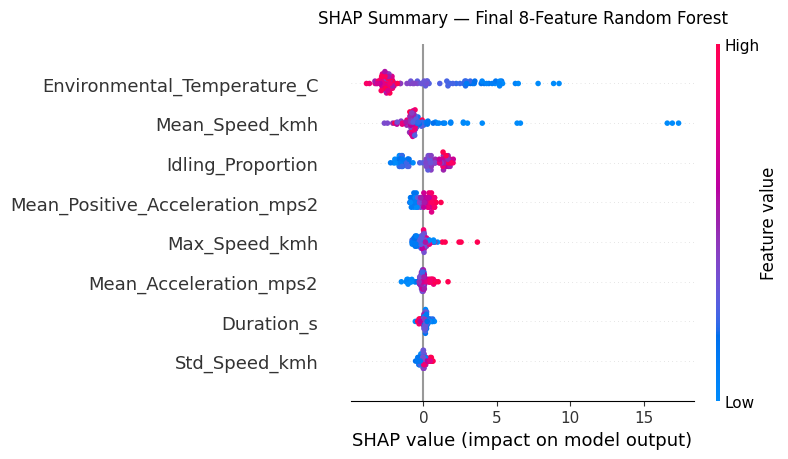

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\31_Final_Fresh_RF_SHAP_Beeswarm.png


In [203]:
# ============================================================
# Stage 25.2 - FINAL Fresh-Kernel SHAP Beeswarm
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path

FINAL_RESULTS = Path(
    r"C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results"
)

FINAL_RESULTS.mkdir(
    parents=True,
    exist_ok=True
)

plt.figure()

shap.plots.beeswarm(
    shap_values_fresh,
    max_display=8,
    show=False
)

plt.title(
    "SHAP Summary — Final 8-Feature Random Forest",
    pad=15
)

plt.tight_layout()

beeswarm_path = (
    FINAL_RESULTS /
    "31_Final_Fresh_RF_SHAP_Beeswarm.png"
)

plt.savefig(
    beeswarm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(beeswarm_path)

# Stage 25.3 - FINAL Fresh-Kernel Temperature SHAP Dependence

<Figure size 800x600 with 0 Axes>

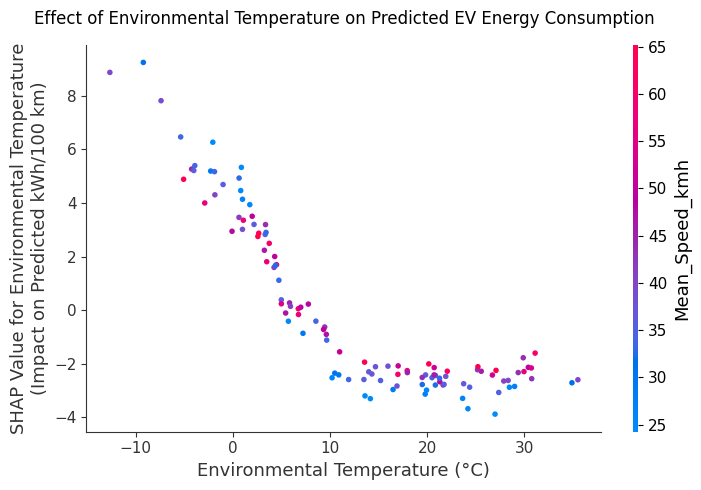

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\32_Final_Fresh_RF_Temperature_SHAP.png


In [204]:
# ============================================================
# Stage 25.3 - FINAL Fresh-Kernel Temperature SHAP Dependence
# ============================================================

temperature_feature = "Environmental_Temperature_C"
interaction_feature = "Mean_Speed_kmh"

plt.figure(figsize=(8, 6))

shap.dependence_plot(
    temperature_feature,
    shap_values_fresh.values,
    X_test_fresh,
    interaction_index=interaction_feature,
    show=False
)

plt.title(
    "Effect of Environmental Temperature on Predicted EV Energy Consumption",
    pad=15
)

plt.xlabel(
    "Environmental Temperature (°C)"
)

plt.ylabel(
    "SHAP Value for Environmental Temperature\n"
    "(Impact on Predicted kWh/100 km)"
)

plt.tight_layout()

temperature_path = (
    FINAL_RESULTS /
    "32_Final_Fresh_RF_Temperature_SHAP.png"
)

plt.savefig(
    temperature_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(temperature_path)

# Stage 25.4 - Export Fresh-Kernel SHAP Importance

In [205]:
# ============================================================
# Stage 25.4 - Export Fresh-Kernel SHAP Importance
# ============================================================

shap_table_path = (
    FINAL_RESULTS /
    "33_Final_Fresh_RF_SHAP_Importance.csv"
)

shap_importance_fresh.to_csv(
    shap_table_path,
    index=False
)

print("=" * 80)
print("FRESH-KERNEL SHAP EXPORT COMPLETE")
print("=" * 80)

print("\nSaved:")
print(beeswarm_path)
print(temperature_path)
print(shap_table_path)

print("\nPrimary SHAP feature:")
print(
    shap_importance_fresh.iloc[0]["Feature"]
)

print(
    "Mean |SHAP|:",
    round(
        shap_importance_fresh.iloc[0]["Mean_Absolute_SHAP"],
        4
    )
)

print("=" * 80)

FRESH-KERNEL SHAP EXPORT COMPLETE

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\31_Final_Fresh_RF_SHAP_Beeswarm.png
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\32_Final_Fresh_RF_Temperature_SHAP.png
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\33_Final_Fresh_RF_SHAP_Importance.csv

Primary SHAP feature:
Environmental_Temperature_C
Mean |SHAP|: 2.7417


# Stage 26.1 - FINAL RF Actual vs Predicted
# Untouched 115-observation holdout

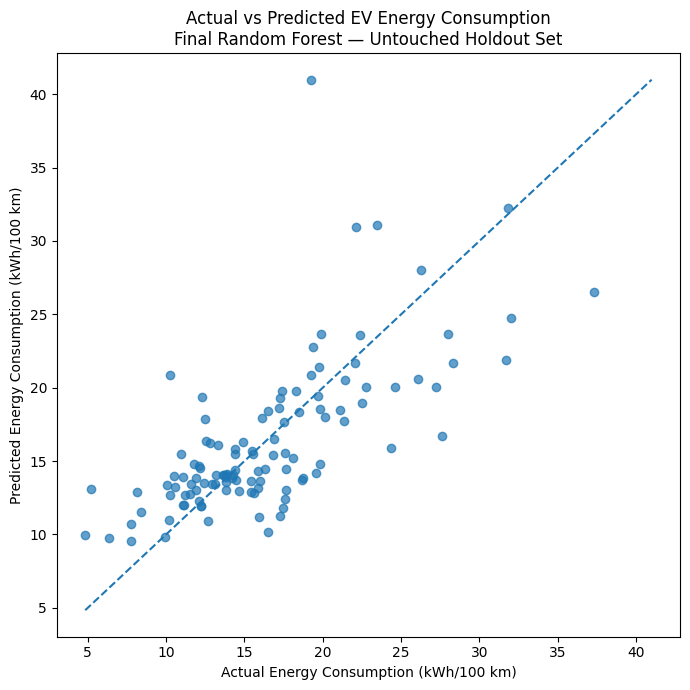

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\34_Final_RF_Actual_vs_Predicted.png


In [206]:
# ============================================================
# Stage 26.1 - FINAL RF Actual vs Predicted
# Untouched 115-observation holdout
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

actual = np.asarray(y_test_fresh)
predicted = np.asarray(pred_fresh)

plot_min = min(actual.min(), predicted.min())
plot_max = max(actual.max(), predicted.max())

plt.figure(figsize=(7, 7))

plt.scatter(
    actual,
    predicted,
    alpha=0.7
)

# Perfect-prediction reference line
plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--"
)

plt.xlabel(
    "Actual Energy Consumption (kWh/100 km)"
)

plt.ylabel(
    "Predicted Energy Consumption (kWh/100 km)"
)

plt.title(
    "Actual vs Predicted EV Energy Consumption\n"
    "Final Random Forest — Untouched Holdout Set"
)

plt.tight_layout()

actual_pred_path = (
    FINAL_RESULTS /
    "34_Final_RF_Actual_vs_Predicted.png"
)

plt.savefig(
    actual_pred_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(actual_pred_path)

# Stage 26.2 - FINAL RF Residual Diagnostic

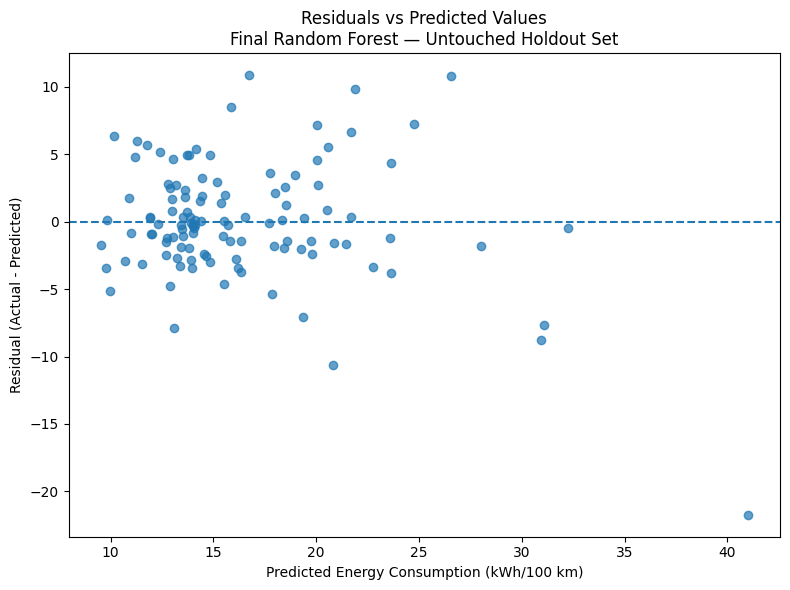

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\35_Final_RF_Residuals_vs_Predicted.png


In [207]:
# ============================================================
# Stage 26.2 - FINAL RF Residual Diagnostic
# ============================================================

residuals = actual - predicted

plt.figure(figsize=(8, 6))

plt.scatter(
    predicted,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel(
    "Predicted Energy Consumption (kWh/100 km)"
)

plt.ylabel(
    "Residual (Actual - Predicted)"
)

plt.title(
    "Residuals vs Predicted Values\n"
    "Final Random Forest — Untouched Holdout Set"
)

plt.tight_layout()

residual_path = (
    FINAL_RESULTS /
    "35_Final_RF_Residuals_vs_Predicted.png"
)

plt.savefig(
    residual_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(residual_path)

# Stage 26.3 - FINAL RF Residual Summary

In [208]:
# ============================================================
# Stage 26.3 - FINAL RF Residual Summary
# ============================================================

residual_summary = pd.Series(
    residuals,
    name="Residual"
).describe(
    percentiles=[
        0.05,
        0.25,
        0.50,
        0.75,
        0.95
    ]
)

print("=" * 80)
print("FINAL RF RESIDUAL SUMMARY")
print("=" * 80)

print(residual_summary.round(4))

print("\nMean residual:")
print(round(residuals.mean(), 4))

print("\nMedian residual:")
print(round(np.median(residuals), 4))

print("\nLargest underprediction:")
print(round(residuals.max(), 4))

print("\nLargest overprediction:")
print(round(residuals.min(), 4))

print("\nCorrelation between prediction and residual:")
print(
    round(
        np.corrcoef(
            predicted,
            residuals
        )[0, 1],
        4
    )
)

print("=" * 80)

FINAL RF RESIDUAL SUMMARY
count    115.0000
mean       0.0583
std        4.3516
min      -21.7279
5%        -5.8745
25%       -1.9219
50%       -0.1812
75%        2.4370
95%        6.8038
max       10.8628
Name: Residual, dtype: float64

Mean residual:
0.0583

Median residual:
-0.1812

Largest underprediction:
10.8628

Largest overprediction:
-21.7279

Correlation between prediction and residual:
-0.2428


# Stage 27.1 - Fresh-Kernel Reference Model Specifications

In [209]:
# ============================================================
# Stage 27.1 - Fresh-Kernel Reference Model Specifications
# ============================================================

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Behaviour-only specification
# Same final variables EXCEPT environmental temperature
# ------------------------------------------------------------

BEHAVIOUR_FEATURES = [
    "Mean_Speed_kmh",
    "Max_Speed_kmh",
    "Std_Speed_kmh",
    "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion",
    "Duration_s"
]

X_train_behaviour = X_train_fresh[BEHAVIOUR_FEATURES].copy()
X_test_behaviour = X_test_fresh[BEHAVIOUR_FEATURES].copy()


print("=" * 90)
print("FRESH-KERNEL REFERENCE MODEL SPECIFICATIONS")
print("=" * 90)

print("\nTraining observations:")
print(len(X_train_behaviour))

print("\nHoldout observations:")
print(len(X_test_behaviour))

print("\nBehaviour-only predictors:")
print(len(BEHAVIOUR_FEATURES))

for feature in BEHAVIOUR_FEATURES:
    print(" -", feature)

print("\nExcluded from behaviour-only reference:")
print(" - Environmental_Temperature_C")

print("=" * 90)

FRESH-KERNEL REFERENCE MODEL SPECIFICATIONS

Training observations:
460

Holdout observations:
115

Behaviour-only predictors:
7
 - Mean_Speed_kmh
 - Max_Speed_kmh
 - Std_Speed_kmh
 - Mean_Acceleration_mps2
 - Mean_Positive_Acceleration_mps2
 - Idling_Proportion
 - Duration_s

Excluded from behaviour-only reference:
 - Environmental_Temperature_C


# Stage 27.2 - Dummy Mean Baseline

In [210]:
# ============================================================
# Stage 27.2 - Dummy Mean Baseline
# ============================================================

dummy_model = DummyRegressor(
    strategy="mean"
)

dummy_cv = cross_validate(
    dummy_model,
    X_train_fresh,
    y_train_fresh,
    cv=fresh_cv,
    scoring=scoring,
    n_jobs=-1
)

dummy_cv_r2 = dummy_cv["test_r2"]
dummy_cv_mae = -dummy_cv["test_mae"]
dummy_cv_rmse = -dummy_cv["test_rmse"]

dummy_model.fit(
    X_train_fresh,
    y_train_fresh
)

dummy_pred = dummy_model.predict(
    X_test_fresh
)

dummy_mae = mean_absolute_error(
    y_test_fresh,
    dummy_pred
)

dummy_rmse = np.sqrt(
    mean_squared_error(
        y_test_fresh,
        dummy_pred
    )
)

dummy_r2 = r2_score(
    y_test_fresh,
    dummy_pred
)

dummy_mape = (
    mean_absolute_percentage_error(
        y_test_fresh,
        dummy_pred
    ) * 100
)

print("=" * 90)
print("FRESH-KERNEL DUMMY MEAN BASELINE")
print("=" * 90)

print("\nTraining-only CV:")
print(f"R²   = {dummy_cv_r2.mean():.4f} ± {dummy_cv_r2.std():.4f}")
print(f"MAE  = {dummy_cv_mae.mean():.4f} ± {dummy_cv_mae.std():.4f}")
print(f"RMSE = {dummy_cv_rmse.mean():.4f} ± {dummy_cv_rmse.std():.4f}")

print("\nHoldout:")
print(f"MAE  = {dummy_mae:.4f}")
print(f"RMSE = {dummy_rmse:.4f}")
print(f"R²   = {dummy_r2:.4f}")
print(f"MAPE = {dummy_mape:.2f}%")

print("=" * 90)

FRESH-KERNEL DUMMY MEAN BASELINE

Training-only CV:
R²   = -0.0014 ± 0.0015
MAE  = 4.9517 ± 0.3008
RMSE = 7.3187 ± 1.0187

Holdout:
MAE  = 4.4156
RMSE = 5.8268
R²   = -0.0023
MAPE = 31.04%


# Stage 27.3 - Behaviour-Only Random Forest Reference
# Same frozen RF architecture

In [211]:
# ============================================================
# Stage 27.3 - Behaviour-Only Random Forest Reference
# Same frozen RF architecture
# ============================================================

rf_behaviour = RandomForestRegressor(
    n_estimators=600,
    max_depth=16,
    min_samples_split=5,
    min_samples_leaf=4,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

behaviour_cv = cross_validate(
    rf_behaviour,
    X_train_behaviour,
    y_train_fresh,
    cv=fresh_cv,
    scoring=scoring,
    n_jobs=-1
)

behaviour_cv_r2 = behaviour_cv["test_r2"]
behaviour_cv_mae = -behaviour_cv["test_mae"]
behaviour_cv_rmse = -behaviour_cv["test_rmse"]

rf_behaviour.fit(
    X_train_behaviour,
    y_train_fresh
)

behaviour_pred = rf_behaviour.predict(
    X_test_behaviour
)

behaviour_mae = mean_absolute_error(
    y_test_fresh,
    behaviour_pred
)

behaviour_rmse = np.sqrt(
    mean_squared_error(
        y_test_fresh,
        behaviour_pred
    )
)

behaviour_r2 = r2_score(
    y_test_fresh,
    behaviour_pred
)

behaviour_mape = (
    mean_absolute_percentage_error(
        y_test_fresh,
        behaviour_pred
    ) * 100
)

print("=" * 90)
print("FRESH-KERNEL BEHAVIOUR-ONLY RANDOM FOREST")
print("=" * 90)

print("\nTraining-only CV:")
print(
    f"R²   = {behaviour_cv_r2.mean():.4f} "
    f"± {behaviour_cv_r2.std():.4f}"
)
print(
    f"MAE  = {behaviour_cv_mae.mean():.4f} "
    f"± {behaviour_cv_mae.std():.4f}"
)
print(
    f"RMSE = {behaviour_cv_rmse.mean():.4f} "
    f"± {behaviour_cv_rmse.std():.4f}"
)

print("\nHoldout:")
print(f"MAE  = {behaviour_mae:.4f}")
print(f"RMSE = {behaviour_rmse:.4f}")
print(f"R²   = {behaviour_r2:.4f}")
print(f"MAPE = {behaviour_mape:.2f}%")

print("=" * 90)

FRESH-KERNEL BEHAVIOUR-ONLY RANDOM FOREST

Training-only CV:
R²   = 0.2844 ± 0.0760
MAE  = 4.1734 ± 0.1093
RMSE = 6.1396 ± 0.6014

Holdout:
MAE  = 4.1223
RMSE = 6.2494
R²   = -0.1530
MAPE = 27.40%


# Stage 27.4 - Reference vs Final Temperature-Enhanced RF

In [212]:
# ============================================================
# Stage 27.4 - Reference vs Final Temperature-Enhanced RF
# ============================================================

reference_comparison = pd.DataFrame([
    {
        "Model": "Dummy Mean Baseline",
        "Features": "None",
        "CV_R2": dummy_cv_r2.mean(),
        "Holdout_MAE": dummy_mae,
        "Holdout_RMSE": dummy_rmse,
        "Holdout_R2": dummy_r2,
        "Holdout_MAPE_pct": dummy_mape
    },
    {
        "Model": "Behaviour-Only RF",
        "Features": 7,
        "CV_R2": behaviour_cv_r2.mean(),
        "Holdout_MAE": behaviour_mae,
        "Holdout_RMSE": behaviour_rmse,
        "Holdout_R2": behaviour_r2,
        "Holdout_MAPE_pct": behaviour_mape
    },
    {
        "Model": "Final RF + Temperature",
        "Features": 8,
        "CV_R2": fresh_cv_r2.mean(),
        "Holdout_MAE": fresh_mae,
        "Holdout_RMSE": fresh_rmse,
        "Holdout_R2": fresh_r2,
        "Holdout_MAPE_pct": fresh_mape
    }
])

display(reference_comparison.round(4))

print("\nTEMPERATURE-ENHANCED RF vs BEHAVIOUR-ONLY RF")
print("=" * 70)

print(
    f"Δ CV R²      : "
    f"{fresh_cv_r2.mean() - behaviour_cv_r2.mean():+.4f}"
)

print(
    f"Δ Holdout R² : "
    f"{fresh_r2 - behaviour_r2:+.4f}"
)

print(
    f"Δ MAE        : "
    f"{fresh_mae - behaviour_mae:+.4f}"
)

print(
    f"Δ RMSE       : "
    f"{fresh_rmse - behaviour_rmse:+.4f}"
)

print(
    f"Δ MAPE       : "
    f"{fresh_mape - behaviour_mape:+.2f} percentage points"
)

print("=" * 70)

,Model,Features,CV_R2,Holdout_MAE,Holdout_RMSE,Holdout_R2,Holdout_MAPE_pct
0,Dummy Mean Baseline,None,-0.0014,4.4156,5.8268,-0.0023,31.0399
1,Behaviour-Only RF,7,0.2844,4.1223,6.2494,-0.1530,27.3998
2,Final RF + Temperature,8,0.5605,3.0322,4.3330,0.4457,20.0844



TEMPERATURE-ENHANCED RF vs BEHAVIOUR-ONLY RF
Δ CV R²      : +0.2761
Δ Holdout R² : +0.5987
Δ MAE        : -1.0901
Δ RMSE       : -1.9163
Δ MAPE       : -7.32 percentage points


# Stage 28 - Largest Holdout Residual Investigation
# DIAGNOSTIC ONLY — NO MODEL CHANG

In [213]:
# ============================================================
# Stage 28 - Largest Holdout Residual Investigation
# DIAGNOSTIC ONLY — NO MODEL CHANGES
# ============================================================

import numpy as np
import pandas as pd

actual = np.asarray(y_test_fresh)
predicted = np.asarray(pred_fresh)

residuals = actual - predicted

# Largest absolute error
largest_abs_pos = np.argmax(np.abs(residuals))

largest_index = X_test_fresh.index[largest_abs_pos]

diagnostic_row = X_test_fresh.loc[[largest_index]].copy()

diagnostic_row["Actual_kWh_100km"] = y_test_fresh.loc[largest_index]
diagnostic_row["Predicted_kWh_100km"] = pred_fresh[largest_abs_pos]
diagnostic_row["Residual_Actual_minus_Predicted"] = residuals[largest_abs_pos]

# Attach dataset identity
diagnostic_row["Dataset"] = fresh_master.loc[largest_index, "Dataset"]

print("=" * 90)
print("LARGEST ABSOLUTE HOLDOUT RESIDUAL")
print("=" * 90)

print("\nMaster index:")
print(largest_index)

print("\nDataset:")
print(diagnostic_row["Dataset"].iloc[0])

print("\nActual:")
print(round(diagnostic_row["Actual_kWh_100km"].iloc[0], 4))

print("\nPredicted:")
print(round(diagnostic_row["Predicted_kWh_100km"].iloc[0], 4))

print("\nResidual (Actual - Predicted):")
print(round(diagnostic_row["Residual_Actual_minus_Predicted"].iloc[0], 4))

print("\nFinal predictor values:")
display(diagnostic_row.T)

print("=" * 90)
print("DIAGNOSTIC COMPLETE — NO DATA OR MODEL MODIFIED")
print("=" * 90)

LARGEST ABSOLUTE HOLDOUT RESIDUAL

Master index:
570

Dataset:
ARGONNE

Actual:
19.2606

Predicted:
40.9884

Residual (Actual - Predicted):
-21.7279

Final predictor values:


,570
Mean_Speed_kmh,4.093332
Max_Speed_kmh,27.917221
Std_Speed_kmh,8.818705
Mean_Acceleration_mps2,0.0
Mean_Positive_Acceleration_mps2,0.606233
Idling_Proportion,0.792473
Duration_s,92.9
Environmental_Temperature_C,0.818833
Actual_kWh_100km,19.260553
Predicted_kWh_100km,40.988441


DIAGNOSTIC COMPLETE — NO DATA OR MODEL MODIFIED


Step 1

In [214]:
from pathlib import Path
import pandas as pd

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

matches = list(
    PROJECT.rglob("MASTER_EV_Dataset_With_Temperature.csv")
)

print("=" * 80)
print("FINAL MASTER DATASET LOAD")
print("=" * 80)

print("Matches found:", len(matches))

if len(matches) == 1:
    master_file = matches[0]
    master_final = pd.read_csv(master_file)

    print("\nPath:")
    print(master_file)

    print("\nShape:")
    print(master_final.shape)

    print("\nColumns:")
    for col in master_final.columns:
        print(col)

    print("\nDataset distribution:")
    print(master_final["Dataset"].value_counts())

else:
    print("Expected exactly one matching master file.")

print("=" * 80)

FINAL MASTER DATASET LOAD
Matches found: 1

Path:
C:\Projects\DS7010_Dissertation\01-Datasets\Harmonised\MASTER_EV_Dataset_With_Temperature.csv

Shape:
(575, 12)

Columns:
Mean_Speed_kmh
Max_Speed_kmh
Std_Speed_kmh
Mean_Acceleration_mps2
Max_Acceleration_mps2
Min_Acceleration_mps2
Mean_Positive_Acceleration_mps2
Idling_Proportion
Duration_s
Environmental_Temperature_C
Energy_Consumption_kWh_100km
Dataset

Dataset distribution:
Dataset
VED        488
BMW         68
ARGONNE     19
Name: count, dtype: int64


# Task 3 — Step 2
# Reconstruct Authoritative Frozen Train/Holdout Split
# NO MODEL TRAINED

In [215]:
# ============================================================
# Task 3 — Step 2
# Reconstruct Authoritative Frozen Train/Holdout Split
# NO MODEL TRAINED
# ============================================================

import numpy as np
from sklearn.model_selection import train_test_split

print("=" * 90)
print("TASK 3 — FROZEN SPLIT RECONSTRUCTION")
print("=" * 90)

# ------------------------------------------------------------
# Reconstruct exact authoritative split
# ------------------------------------------------------------

all_indices = master_final.index.to_numpy()

train_idx, holdout_idx = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=master_final["Dataset"]
)

train_final = master_final.loc[train_idx].copy()
holdout_final = master_final.loc[holdout_idx].copy()

# ------------------------------------------------------------
# Basic verification
# ------------------------------------------------------------

print("\nTraining N:")
print(len(train_final))

print("\nHoldout N:")
print(len(holdout_final))

print("\nTraining dataset distribution:")
print(train_final["Dataset"].value_counts())

print("\nHoldout dataset distribution:")
print(holdout_final["Dataset"].value_counts())

print("\nTrain / holdout index overlap:")
print(
    len(
        set(train_idx).intersection(
            set(holdout_idx)
        )
    )
)

print("\nTotal observations accounted for:")
print(len(train_final) + len(holdout_final))

print("\nMissing target values:")
print(
    "Training:",
    train_final["Energy_Consumption_kWh_100km"].isna().sum()
)
print(
    "Holdout:",
    holdout_final["Energy_Consumption_kWh_100km"].isna().sum()
)

print("\n" + "=" * 90)

if (
    len(train_final) == 460
    and len(holdout_final) == 115
    and len(set(train_idx).intersection(set(holdout_idx))) == 0
):
    print("FROZEN SPLIT RECONSTRUCTION: PASSED")
else:
    print("WARNING — SPLIT DOES NOT MATCH EXPECTED STRUCTURE")

print("NO MODEL TRAINED — NO DATA MODIFIED")
print("=" * 90)

TASK 3 — FROZEN SPLIT RECONSTRUCTION

Training N:
460

Holdout N:
115

Training dataset distribution:
Dataset
VED        391
BMW         54
ARGONNE     15
Name: count, dtype: int64

Holdout dataset distribution:
Dataset
VED        97
BMW        14
ARGONNE     4
Name: count, dtype: int64

Train / holdout index overlap:
0

Total observations accounted for:
575

Missing target values:
Training: 0
Holdout: 0

FROZEN SPLIT RECONSTRUCTION: PASSED
NO MODEL TRAINED — NO DATA MODIFIED


# Task 3 — Step 3
# Hypothesis Feature-Set Audit
# NO MODEL TRAINED
# NO DATA MODIFIED

In [216]:
# ============================================================
# Task 3 — Step 3
# Hypothesis Feature-Set Audit
# NO MODEL TRAINED
# NO DATA MODIFIED
# ============================================================

print("=" * 95)
print("TASK 3 — HYPOTHESIS FEATURE-SET AUDIT")
print("=" * 95)

# ------------------------------------------------------------
# 1. Columns available in authoritative master dataset
# ------------------------------------------------------------

print("\nAUTHORITATIVE MASTER COLUMNS")
print("-" * 95)

for i, col in enumerate(master_final.columns, start=1):
    print(f"{i:2d}. {col}")

# ------------------------------------------------------------
# 2. Proposal-required baseline variables
# ------------------------------------------------------------

proposal_baseline = [
    "Mean_Speed_kmh",
    "Distance_km"
]

print("\n" + "-" * 95)
print("PROPOSAL SPEED-AND-DISTANCE BASELINE")
print("-" * 95)

for feature in proposal_baseline:

    if feature in master_final.columns:
        print(f"{feature}: AVAILABLE")
    else:
        print(f"{feature}: NOT PRESENT IN FINAL MASTER")

# ------------------------------------------------------------
# 3. Candidate final behaviour variables
# ------------------------------------------------------------

behaviour_candidates = [
    "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion",
    "Std_Speed_kmh",
    "Max_Speed_kmh"
]

print("\n" + "-" * 95)
print("CANDIDATE BEHAVIOUR / DRIVING-DYNAMICS FEATURES")
print("-" * 95)

for feature in behaviour_candidates:

    if feature in master_final.columns:

        print(f"\n{feature}: AVAILABLE")

        print(
            master_final[feature]
            .describe()
            .round(4)
        )

    else:
        print(f"\n{feature}: NOT AVAILABLE")

# ------------------------------------------------------------
# 4. Other potentially relevant variables
# ------------------------------------------------------------

print("\n" + "-" * 95)
print("OTHER FINAL PREDICTORS")
print("-" * 95)

other_features = [
    "Duration_s",
    "Environmental_Temperature_C"
]

for feature in other_features:

    print(f"\n{feature}")

    if feature in master_final.columns:
        print(
            master_final[feature]
            .describe()
            .round(4)
        )
    else:
        print("NOT AVAILABLE")

# ------------------------------------------------------------
# 5. Missing-value audit
# ------------------------------------------------------------

candidate_features = [
    "Mean_Speed_kmh",
    "Max_Speed_kmh",
    "Std_Speed_kmh",
    "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion",
    "Duration_s",
    "Environmental_Temperature_C"
]

print("\n" + "-" * 95)
print("MISSING VALUES IN FINAL CANDIDATE FEATURES")
print("-" * 95)

print(
    master_final[candidate_features]
    .isna()
    .sum()
)

print("\n" + "=" * 95)
print("FEATURE-SET AUDIT COMPLETE")
print("NO MODEL TRAINED — NO DATA MODIFIED")
print("=" * 95)

TASK 3 — HYPOTHESIS FEATURE-SET AUDIT

AUTHORITATIVE MASTER COLUMNS
-----------------------------------------------------------------------------------------------
 1. Mean_Speed_kmh
 2. Max_Speed_kmh
 3. Std_Speed_kmh
 4. Mean_Acceleration_mps2
 5. Max_Acceleration_mps2
 6. Min_Acceleration_mps2
 7. Mean_Positive_Acceleration_mps2
 8. Idling_Proportion
 9. Duration_s
10. Environmental_Temperature_C
11. Energy_Consumption_kWh_100km
12. Dataset

-----------------------------------------------------------------------------------------------
PROPOSAL SPEED-AND-DISTANCE BASELINE
-----------------------------------------------------------------------------------------------
Mean_Speed_kmh: AVAILABLE
Distance_km: NOT PRESENT IN FINAL MASTER

-----------------------------------------------------------------------------------------------
CANDIDATE BEHAVIOUR / DRIVING-DYNAMICS FEATURES
-----------------------------------------------------------------------------------------------

Mean_Accelera

# Task 3 — Step 4
# Search Existing Processed Files for Distance Variables
# INSPECTION ONLY
# NO DATA OR MODEL MODIFICATION

In [217]:
# ============================================================
# Task 3 — Step 4
# Search Existing Processed Files for Distance Variables
# INSPECTION ONLY
# NO DATA OR MODEL MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

print("=" * 100)
print("TASK 3 — DISTANCE VARIABLE SEARCH")
print("=" * 100)

# Search CSV files in dataset / processed areas
csv_files = list(PROJECT.rglob("*.csv"))

print("\nCSV files found:", len(csv_files))

matches = []

for file in csv_files:

    try:
        # Read header only — fast and does not load full files
        cols = pd.read_csv(file, nrows=0).columns.tolist()

        distance_cols = [
            col for col in cols
            if any(
                term in col.lower()
                for term in [
                    "distance",
                    "trip_distance",
                    "segment_distance"
                ]
            )
        ]

        if distance_cols:

            matches.append({
                "File": str(file),
                "Distance_Columns": distance_cols,
                "All_Columns": cols
            })

    except Exception:
        pass

print("\nFiles containing possible distance variables:")
print("-" * 100)

if len(matches) == 0:

    print("NO DISTANCE COLUMNS FOUND")

else:

    for i, item in enumerate(matches, start=1):

        print(f"\n[{i}]")
        print("FILE:")
        print(item["File"])

        print("\nDISTANCE COLUMNS:")
        for col in item["Distance_Columns"]:
            print("  ", col)

        print("\nALL COLUMNS:")
        print(item["All_Columns"])

        print("-" * 100)

print("\nTotal files with distance variables:", len(matches))

print("\n" + "=" * 100)
print("SEARCH COMPLETE")
print("NO DATA MODIFIED — NO MODEL TRAINED")
print("=" * 100)

TASK 3 — DISTANCE VARIABLE SEARCH

CSV files found: 169

Files containing possible distance variables:
----------------------------------------------------------------------------------------------------

[1]
FILE:
C:\Projects\DS7010_Dissertation\01-Datasets\VED_BEV_AUDIT_TABLE.csv

DISTANCE COLUMNS:
   Distance_km
   Distance_km_trap
   Distance_Difference_pct

ALL COLUMNS:
['Segment_ID', 'VehId', 'Trip', 'Rows', 'Energy_kWh', 'Distance_km', 'Energy_kWh_trap', 'Distance_km_trap', 'Energy_Difference_pct', 'Distance_Difference_pct', 'Energy_Consumption_kWh_100km', 'Start_SOC', 'End_SOC', 'SOC_Drop_pct', 'Duration_s', 'Mean_Speed_kmh', 'Max_Speed_kmh', 'Std_Speed_kmh', 'Mean_Acceleration_mps2', 'Mean_Positive_Acceleration_mps2', 'Max_Acceleration_mps2', 'Min_Acceleration_mps2', 'Mean_Temp_C', 'Mean_Heater_W', 'Idling_Proportion', 'RPA_mps2']
----------------------------------------------------------------------------------------------------

[2]
FILE:
C:\Projects\DS7010_Dissertation\06-R

# Task 3 — Step 5
# Verify Audit-Table Alignment with Final Master Dataset
# BEFORE ADDING DISTANCE
# NO MODEL TRAINED

In [218]:
# ============================================================
# Task 3 — Step 5
# Verify Audit-Table Alignment with Final Master Dataset
# BEFORE ADDING DISTANCE
# NO MODEL TRAINED
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 105)
print("TASK 3 — AUDIT TABLE / MASTER ROW-ALIGNMENT VERIFICATION")
print("=" * 105)

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

# ------------------------------------------------------------
# 1. Locate authoritative audit tables
# ------------------------------------------------------------

ved_files = list(PROJECT.rglob("VED_BEV_AUDIT_TABLE.csv"))
bmw_files = list(PROJECT.rglob("BMW_AUDIT_TABLE.csv"))
argonne_files = list(PROJECT.rglob("ARGONNE_AUDIT_TABLE.csv"))

print("\nFiles located:")
print("VED:", len(ved_files))
print("BMW:", len(bmw_files))
print("ARGONNE:", len(argonne_files))

if not (
    len(ved_files) == 1
    and len(bmw_files) == 1
    and len(argonne_files) == 1
):
    print("\nSTOP — expected exactly one audit table per dataset.")

else:

    ved_audit = pd.read_csv(ved_files[0])
    bmw_audit = pd.read_csv(bmw_files[0])
    argonne_audit = pd.read_csv(argonne_files[0])

    # --------------------------------------------------------
    # 2. Master subsets
    # --------------------------------------------------------

    master_ved = (
        master_final[
            master_final["Dataset"] == "VED"
        ]
        .reset_index(drop=True)
    )

    master_bmw = (
        master_final[
            master_final["Dataset"] == "BMW"
        ]
        .reset_index(drop=True)
    )

    master_argonne = (
        master_final[
            master_final["Dataset"] == "ARGONNE"
        ]
        .reset_index(drop=True)
    )

    print("\nROW COUNTS")
    print("-" * 105)

    print(
        "VED     | Master:",
        len(master_ved),
        "| Audit:",
        len(ved_audit)
    )

    print(
        "BMW     | Master:",
        len(master_bmw),
        "| Audit:",
        len(bmw_audit)
    )

    print(
        "ARGONNE | Master:",
        len(master_argonne),
        "| Audit:",
        len(argonne_audit)
    )

    # --------------------------------------------------------
    # 3. Feature mappings
    # --------------------------------------------------------

    checks = {

        "VED": {
            "master": master_ved,
            "audit": ved_audit,
            "mapping": {
                "Mean_Speed_kmh": "Mean_Speed_kmh",
                "Max_Speed_kmh": "Max_Speed_kmh",
                "Std_Speed_kmh": "Std_Speed_kmh",
                "Mean_Acceleration_mps2":
                    "Mean_Acceleration_mps2",
                "Mean_Positive_Acceleration_mps2":
                    "Mean_Positive_Acceleration_mps2",
                "Idling_Proportion":
                    "Idling_Proportion",
                "Duration_s":
                    "Duration_s",
                "Environmental_Temperature_C":
                    "Mean_Temp_C",
                "Energy_Consumption_kWh_100km":
                    "Energy_Consumption_kWh_100km"
            }
        },

        "BMW": {
            "master": master_bmw,
            "audit": bmw_audit,
            "mapping": {
                "Mean_Speed_kmh": "Mean_Speed_kmh",
                "Max_Speed_kmh": "Max_Speed_kmh",
                "Std_Speed_kmh": "Std_Speed_kmh",
                "Mean_Acceleration_mps2":
                    "Mean_Acceleration_mps2",
                "Mean_Positive_Acceleration_mps2":
                    "Mean_Positive_Acceleration_mps2",
                "Idling_Proportion":
                    "Idling_Proportion",
                "Duration_s":
                    "Duration_s",
                "Environmental_Temperature_C":
                    "Mean_Ambient_Temp_C",
                "Energy_Consumption_kWh_100km":
                    "Energy_Consumption_kWh_100km"
            }
        },

        "ARGONNE": {
            "master": master_argonne,
            "audit": argonne_audit,
            "mapping": {
                "Mean_Speed_kmh": "Mean_Speed_kmh",
                "Max_Speed_kmh": "Max_Speed_kmh",
                "Std_Speed_kmh": "Std_Speed_kmh",
                "Mean_Acceleration_mps2":
                    "Mean_Acceleration_mps2",
                "Mean_Positive_Acceleration_mps2":
                    "Mean_Positive_Acceleration_mps2",
                "Idling_Proportion":
                    "Idling_Proportion",
                "Duration_s":
                    "Duration_s",
                "Environmental_Temperature_C":
                    "Mean_Test_Cell_Temp_C",
                "Energy_Consumption_kWh_100km":
                    "Energy_Consumption_kWh_100km"
            }
        }
    }

    # --------------------------------------------------------
    # 4. Row-by-row numerical verification
    # --------------------------------------------------------

    all_passed = True

    for dataset_name, info in checks.items():

        master_part = info["master"]
        audit_part = info["audit"]
        mapping = info["mapping"]

        print("\n" + "-" * 105)
        print(dataset_name, "ROW-BY-ROW CHECK")
        print("-" * 105)

        if len(master_part) != len(audit_part):

            print("ROW COUNT MISMATCH")
            all_passed = False
            continue

        for master_col, audit_col in mapping.items():

            if audit_col not in audit_part.columns:

                print(
                    f"{master_col:<40} "
                    f"AUDIT COLUMN MISSING: {audit_col}"
                )

                all_passed = False
                continue

            master_values = pd.to_numeric(
                master_part[master_col],
                errors="coerce"
            ).to_numpy()

            audit_values = pd.to_numeric(
                audit_part[audit_col],
                errors="coerce"
            ).to_numpy()

            differences = np.abs(
                master_values - audit_values
            )

            max_diff = np.nanmax(differences)

            passed = np.allclose(
                master_values,
                audit_values,
                rtol=1e-7,
                atol=1e-8,
                equal_nan=True
            )

            status = (
                "MATCH"
                if passed
                else "MISMATCH"
            )

            print(
                f"{master_col:<40} "
                f"{status:<10} "
                f"max diff = {max_diff:.10f}"
            )

            if not passed:
                all_passed = False

    # --------------------------------------------------------
    # 5. Distance quality — inspection only
    # --------------------------------------------------------

    print("\n" + "-" * 105)
    print("DISTANCE VARIABLE QUALITY")
    print("-" * 105)

    distance_sources = [
        ("VED", ved_audit, "Distance_km"),
        ("BMW", bmw_audit, "Calculated_Distance_km"),
        (
            "ARGONNE",
            argonne_audit,
            "Calculated_Distance_km"
        )
    ]

    for name, df, col in distance_sources:

        print(f"\n{name} — {col}")

        if col not in df.columns:

            print("MISSING")

        else:

            values = pd.to_numeric(
                df[col],
                errors="coerce"
            )

            print(
                values.describe().round(4)
            )

            print(
                "Missing:",
                values.isna().sum()
            )

            print(
                "Zero/non-positive:",
                (values <= 0).sum()
            )

    # --------------------------------------------------------
    # Final status
    # --------------------------------------------------------

    print("\n" + "=" * 105)

    if all_passed:
        print(
            "ROW ALIGNMENT STATUS: VERIFIED"
        )
    else:
        print(
            "ROW ALIGNMENT STATUS: NOT YET VERIFIED"
        )

    print(
        "NO DISTANCE ADDED TO MASTER"
    )
    print(
        "NO MODEL TRAINED — NO DATA MODIFIED"
    )

    print("=" * 105)

TASK 3 — AUDIT TABLE / MASTER ROW-ALIGNMENT VERIFICATION

Files located:
VED: 1
BMW: 1
ARGONNE: 1

ROW COUNTS
---------------------------------------------------------------------------------------------------------
VED     | Master: 488 | Audit: 488
BMW     | Master: 68 | Audit: 70
ARGONNE | Master: 19 | Audit: 20

---------------------------------------------------------------------------------------------------------
VED ROW-BY-ROW CHECK
---------------------------------------------------------------------------------------------------------
Mean_Speed_kmh                           MATCH      max diff = 0.0000000000
Max_Speed_kmh                            MATCH      max diff = 0.0000000000
Std_Speed_kmh                            MATCH      max diff = 0.0000000000
Mean_Acceleration_mps2                   MATCH      max diff = 0.0000000000
Mean_Positive_Acceleration_mps2          MATCH      max diff = 0.0000000000
Idling_Proportion                        MATCH      max diff = 0.0000

# Task 3 — Step 6
# Identify Exact BMW and Argonne Rows Used in Final Master
# MATCHING / INSPECTION ONLY
# NO DATA OR MODEL MODIFICATION

In [219]:
# ============================================================
# Task 3 — Step 6
# Identify Exact BMW and Argonne Rows Used in Final Master
# MATCHING / INSPECTION ONLY
# NO DATA OR MODEL MODIFICATION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 105)
print("TASK 3 — BMW / ARGONNE FINAL-ROW MATCHING")
print("=" * 105)

# ------------------------------------------------------------
# Shared feature mappings
# ------------------------------------------------------------

bmw_mapping = {
    "Mean_Speed_kmh": "Mean_Speed_kmh",
    "Max_Speed_kmh": "Max_Speed_kmh",
    "Std_Speed_kmh": "Std_Speed_kmh",
    "Mean_Acceleration_mps2": "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2":
        "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion": "Idling_Proportion",
    "Duration_s": "Duration_s",
    "Environmental_Temperature_C": "Mean_Ambient_Temp_C",
    "Energy_Consumption_kWh_100km":
        "Energy_Consumption_kWh_100km"
}

argonne_mapping = {
    "Mean_Speed_kmh": "Mean_Speed_kmh",
    "Max_Speed_kmh": "Max_Speed_kmh",
    "Std_Speed_kmh": "Std_Speed_kmh",
    "Mean_Acceleration_mps2": "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2":
        "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion": "Idling_Proportion",
    "Duration_s": "Duration_s",
    "Environmental_Temperature_C": "Mean_Test_Cell_Temp_C",
    "Energy_Consumption_kWh_100km":
        "Energy_Consumption_kWh_100km"
}


def match_master_to_audit(
    master_part,
    audit_part,
    mapping,
    dataset_name
):

    print("\n" + "-" * 105)
    print(dataset_name)
    print("-" * 105)

    master_part = master_part.copy()
    audit_part = audit_part.copy()

    matched_audit_indices = []
    match_counts = []
    match_details = []

    # --------------------------------------------------------
    # For every final-master row, search the audit table
    # using ALL shared numerical variables simultaneously
    # --------------------------------------------------------

    for master_index, master_row in master_part.iterrows():

        mask = np.ones(
            len(audit_part),
            dtype=bool
        )

        for master_col, audit_col in mapping.items():

            audit_values = pd.to_numeric(
                audit_part[audit_col],
                errors="coerce"
            ).to_numpy()

            target_value = float(
                master_row[master_col]
            )

            mask &= np.isclose(
                audit_values,
                target_value,
                rtol=1e-7,
                atol=1e-8,
                equal_nan=True
            )

        candidates = audit_part.index[mask].tolist()

        match_counts.append(
            len(candidates)
        )

        if len(candidates) == 1:

            matched_audit_indices.append(
                candidates[0]
            )

            match_details.append({
                "Master_Index": master_index,
                "Audit_Index": candidates[0],
                "Match_Count": 1
            })

        else:

            match_details.append({
                "Master_Index": master_index,
                "Audit_Index":
                    candidates[0]
                    if len(candidates) > 0
                    else np.nan,
                "Match_Count": len(candidates)
            })

    match_details = pd.DataFrame(
        match_details
    )

    print("Master rows:", len(master_part))
    print("Audit rows:", len(audit_part))

    print("\nMatch-count distribution:")
    print(
        pd.Series(match_counts)
        .value_counts()
        .sort_index()
    )

    unique_matches = (
        match_details["Match_Count"] == 1
    ).sum()

    print(
        "\nMaster rows with exactly one audit match:",
        unique_matches,
        "/",
        len(master_part)
    )

    # --------------------------------------------------------
    # Check whether any audit row was assigned twice
    # --------------------------------------------------------

    successful = match_details[
        match_details["Match_Count"] == 1
    ]

    duplicate_assignments = (
        successful["Audit_Index"]
        .duplicated()
        .sum()
    )

    print(
        "Duplicate audit-row assignments:",
        duplicate_assignments
    )

    # --------------------------------------------------------
    # Identify audit rows not present in final master
    # --------------------------------------------------------

    used_indices = set(
        successful["Audit_Index"]
        .astype(int)
        .tolist()
    )

    excluded_indices = [
        idx
        for idx in audit_part.index
        if idx not in used_indices
    ]

    print(
        "\nAudit rows NOT represented "
        "in final master:"
    )

    print(excluded_indices)

    if len(excluded_indices) > 0:

        display_cols = []

        # Include useful identity columns where available
        for col in [
            "Trip_ID",
            "Trip",
            "Test_ID",
            "Cycle",
            "Calculated_Distance_km",
            "Energy_Consumption_kWh_100km",
            "Mean_Speed_kmh",
            "Duration_s"
        ]:
            if col in audit_part.columns:
                display_cols.append(col)

        print("\nExcluded-row details:")

        display(
            audit_part.loc[
                excluded_indices,
                display_cols
            ]
        )

    # --------------------------------------------------------
    # Return mapping for later use — nothing modified
    # --------------------------------------------------------

    return match_details


# ------------------------------------------------------------
# Final-master subsets — retain ORIGINAL master indices
# ------------------------------------------------------------

master_bmw_original = master_final[
    master_final["Dataset"] == "BMW"
].copy()

master_argonne_original = master_final[
    master_final["Dataset"] == "ARGONNE"
].copy()

# ------------------------------------------------------------
# Run matching
# ------------------------------------------------------------

bmw_matches = match_master_to_audit(
    master_bmw_original,
    bmw_audit,
    bmw_mapping,
    "BMW"
)

argonne_matches = match_master_to_audit(
    master_argonne_original,
    argonne_audit,
    argonne_mapping,
    "ARGONNE"
)

# ------------------------------------------------------------
# Overall decision
# ------------------------------------------------------------

bmw_ok = (
    (bmw_matches["Match_Count"] == 1).all()
    and
    not bmw_matches["Audit_Index"].duplicated().any()
)

argonne_ok = (
    (argonne_matches["Match_Count"] == 1).all()
    and
    not argonne_matches["Audit_Index"].duplicated().any()
)

print("\n" + "=" * 105)

print("BMW matching status:")
print(
    "VERIFIED"
    if bmw_ok
    else "NOT VERIFIED"
)

print("\nARGONNE matching status:")
print(
    "VERIFIED"
    if argonne_ok
    else "NOT VERIFIED"
)

print("\nExpected excluded audit rows:")
print("BMW: 2")
print("ARGONNE: 1")

print("\nActual excluded audit rows:")
print(
    "BMW:",
    len(bmw_audit) -
    (bmw_matches["Match_Count"] == 1).sum()
)

print(
    "ARGONNE:",
    len(argonne_audit) -
    (argonne_matches["Match_Count"] == 1).sum()
)

print("\nNO DISTANCE ADDED")
print("NO MODEL TRAINED")
print("NO SOURCE OR MASTER DATA MODIFIED")
print("=" * 105)

TASK 3 — BMW / ARGONNE FINAL-ROW MATCHING

---------------------------------------------------------------------------------------------------------
BMW
---------------------------------------------------------------------------------------------------------
Master rows: 68
Audit rows: 70

Match-count distribution:
1    68
Name: count, dtype: int64

Master rows with exactly one audit match: 68 / 68
Duplicate audit-row assignments: 0

Audit rows NOT represented in final master:
[35, 40]

Excluded-row details:


,Trip_ID,Calculated_Distance_km,Energy_Consumption_kWh_100km,Mean_Speed_kmh,Duration_s
35,TripB04,16.594296,-34.852702,20.216401,2954.9
40,TripB09,54.182571,-29.291961,34.768325,5610.1



---------------------------------------------------------------------------------------------------------
ARGONNE
---------------------------------------------------------------------------------------------------------
Master rows: 19
Audit rows: 20

Match-count distribution:
1    19
Name: count, dtype: int64

Master rows with exactly one audit match: 19 / 19
Duplicate audit-row assignments: 0

Audit rows NOT represented in final master:
[2]

Excluded-row details:


,Trip_ID,Calculated_Distance_km,Energy_Consumption_kWh_100km,Mean_Speed_kmh,Duration_s
2,61505016,10.258211,-5.764438,53.266443,693.199



BMW matching status:
VERIFIED

ARGONNE matching status:
VERIFIED

Expected excluded audit rows:
BMW: 2
ARGONNE: 1

Actual excluded audit rows:
BMW: 2
ARGONNE: 1

NO DISTANCE ADDED
NO MODEL TRAINED
NO SOURCE OR MASTER DATA MODIFIED


# Task 3 — Step 7
# Construct Verified Distance Variable
# SEPARATE ANALYSIS COPY ONLY
# NO MODEL TRAINED
# NO SOURCE DATA MODIFIED

In [220]:
# ============================================================
# Task 3 — Step 7
# Construct Verified Distance Variable
# SEPARATE ANALYSIS COPY ONLY
# NO MODEL TRAINED
# NO SOURCE DATA MODIFIED
# ============================================================

import numpy as np
import pandas as pd

print("=" * 105)
print("TASK 3 — VERIFIED DISTANCE RECONSTRUCTION")
print("=" * 105)

# ------------------------------------------------------------
# 1. Create separate analysis copy
# ------------------------------------------------------------

master_hypothesis = master_final.copy()

master_hypothesis["Distance_km"] = np.nan

# ------------------------------------------------------------
# 2. VED
# Row-by-row alignment was already independently verified
# ------------------------------------------------------------

ved_master_indices = master_hypothesis.index[
    master_hypothesis["Dataset"] == "VED"
]

ved_distances = pd.to_numeric(
    ved_audit["Distance_km"],
    errors="coerce"
).to_numpy()

if len(ved_master_indices) != len(ved_distances):
    raise ValueError("VED row-count mismatch.")

master_hypothesis.loc[
    ved_master_indices,
    "Distance_km"
] = ved_distances

# ------------------------------------------------------------
# 3. BMW
# Use exact verified master-to-audit mapping from Step 6
# ------------------------------------------------------------

for _, row in bmw_matches.iterrows():

    if row["Match_Count"] != 1:
        raise ValueError(
            "BMW contains a non-unique match."
        )

    master_index = int(row["Master_Index"])
    audit_index = int(row["Audit_Index"])

    master_hypothesis.loc[
        master_index,
        "Distance_km"
    ] = pd.to_numeric(
        bmw_audit.loc[
            audit_index,
            "Calculated_Distance_km"
        ],
        errors="coerce"
    )

# ------------------------------------------------------------
# 4. Argonne
# Use exact verified master-to-audit mapping from Step 6
# ------------------------------------------------------------

for _, row in argonne_matches.iterrows():

    if row["Match_Count"] != 1:
        raise ValueError(
            "Argonne contains a non-unique match."
        )

    master_index = int(row["Master_Index"])
    audit_index = int(row["Audit_Index"])

    master_hypothesis.loc[
        master_index,
        "Distance_km"
    ] = pd.to_numeric(
        argonne_audit.loc[
            audit_index,
            "Calculated_Distance_km"
        ],
        errors="coerce"
    )

# ------------------------------------------------------------
# 5. Global quality checks
# ------------------------------------------------------------

print("\nOVERALL DISTANCE QUALITY")
print("-" * 105)

print(
    master_hypothesis["Distance_km"]
    .describe()
    .round(4)
)

print(
    "\nMissing distance:",
    master_hypothesis["Distance_km"]
    .isna()
    .sum()
)

print(
    "Non-positive distance:",
    (
        master_hypothesis["Distance_km"] <= 0
    ).sum()
)

# ------------------------------------------------------------
# 6. Dataset-specific summaries
# ------------------------------------------------------------

print("\n" + "-" * 105)
print("DISTANCE BY DATASET")
print("-" * 105)

distance_summary = (
    master_hypothesis
    .groupby("Dataset")["Distance_km"]
    .agg(
        [
            "count",
            "mean",
            "std",
            "min",
            "median",
            "max"
        ]
    )
    .round(4)
)

display(distance_summary)

# ------------------------------------------------------------
# 7. Verify original 12 master columns are unchanged
# ------------------------------------------------------------

original_columns = master_final.columns.tolist()

unchanged = True

for col in original_columns:

    if col == "Dataset":

        same = (
            master_hypothesis[col]
            .equals(master_final[col])
        )

    else:

        same = np.allclose(
            pd.to_numeric(
                master_hypothesis[col],
                errors="coerce"
            ),
            pd.to_numeric(
                master_final[col],
                errors="coerce"
            ),
            rtol=0,
            atol=0,
            equal_nan=True
        )

    if not same:
        print(
            "WARNING — original column changed:",
            col
        )
        unchanged = False

# ------------------------------------------------------------
# 8. Verify split identities remain unchanged
# ------------------------------------------------------------

train_hypothesis = master_hypothesis.loc[
    train_idx
].copy()

holdout_hypothesis = master_hypothesis.loc[
    holdout_idx
].copy()

print("\n" + "-" * 105)
print("FROZEN SPLIT CHECK")
print("-" * 105)

print(
    "Training N:",
    len(train_hypothesis)
)

print(
    "Holdout N:",
    len(holdout_hypothesis)
)

print(
    "\nTraining distribution:"
)
print(
    train_hypothesis[
        "Dataset"
    ].value_counts()
)

print(
    "\nHoldout distribution:"
)
print(
    holdout_hypothesis[
        "Dataset"
    ].value_counts()
)

# ------------------------------------------------------------
# 9. Final status
# ------------------------------------------------------------

distance_ok = (
    master_hypothesis["Distance_km"]
    .notna()
    .all()
    and
    (
        master_hypothesis["Distance_km"] > 0
    ).all()
)

print("\n" + "=" * 105)

print(
    "DISTANCE RECONSTRUCTION:",
    "VERIFIED"
    if distance_ok
    else "FAILED"
)

print(
    "ORIGINAL MASTER COLUMNS:",
    "UNCHANGED"
    if unchanged
    else "CHECK REQUIRED"
)

print(
    "Final analysis shape:",
    master_hypothesis.shape
)

print(
    "Expected shape: (575, 13)"
)

print("\nNO MODEL TRAINED")
print("NO SOURCE FILE MODIFIED")
print("master_final NOT MODIFIED")
print("=" * 105)

TASK 3 — VERIFIED DISTANCE RECONSTRUCTION

OVERALL DISTANCE QUALITY
---------------------------------------------------------------------------------------------------------
count    575.0000
mean       7.3490
std        8.7564
min        0.1057
25%        2.4772
50%        4.6832
75%        8.7726
max       60.9748
Name: Distance_km, dtype: float64

Missing distance: 0
Non-positive distance: 0

---------------------------------------------------------------------------------------------------------
DISTANCE BY DATASET
---------------------------------------------------------------------------------------------------------


,count,mean,std,min,median,max
Dataset,,,,,,
ARGONNE,19,31.9162,18.4698,0.1057,35.5062,53.5505
BMW,68,18.9269,10.9385,2.7833,16.3792,60.9748
VED,488,4.7792,3.5242,0.5358,3.7762,21.4788



---------------------------------------------------------------------------------------------------------
FROZEN SPLIT CHECK
---------------------------------------------------------------------------------------------------------
Training N: 460
Holdout N: 115

Training distribution:
Dataset
VED        391
BMW         54
ARGONNE     15
Name: count, dtype: int64

Holdout distribution:
Dataset
VED        97
BMW        14
ARGONNE     4
Name: count, dtype: int64

DISTANCE RECONSTRUCTION: VERIFIED
ORIGINAL MASTER COLUMNS: UNCHANGED
Final analysis shape: (575, 13)
Expected shape: (575, 13)

NO MODEL TRAINED
NO SOURCE FILE MODIFIED
master_final NOT MODIFIED


# Task 3 — Step 8
# Freeze H0/H1 Feature Specifications
# NO MODEL TRAINED

In [221]:
# ============================================================
# Task 3 — Step 8
# Freeze H0/H1 Feature Specifications
# NO MODEL TRAINED
# ============================================================

import numpy as np

print("=" * 100)
print("TASK 3 — HYPOTHESIS MODEL SPECIFICATION")
print("=" * 100)

target = "Energy_Consumption_kWh_100km"

# ------------------------------------------------------------
# H0 comparator:
# speed-and-distance baseline from proposal
# ------------------------------------------------------------

baseline_features = [
    "Mean_Speed_kmh",
    "Distance_km"
]

# ------------------------------------------------------------
# H1 comparator:
# same baseline + behaviour-related variables
# ------------------------------------------------------------

behaviour_features = [
    "Mean_Speed_kmh",
    "Distance_km",
    "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion"
]

added_behaviour_features = [
    feature
    for feature in behaviour_features
    if feature not in baseline_features
]

# ------------------------------------------------------------
# Display frozen definitions
# ------------------------------------------------------------

print("\nSPEED-AND-DISTANCE BASELINE")
print("-" * 100)

for feature in baseline_features:
    print(" -", feature)

print("\nBEHAVIOUR-INFORMED MODEL")
print("-" * 100)

for feature in behaviour_features:
    print(" -", feature)

print("\nADDED BEHAVIOUR VARIABLES")
print("-" * 100)

for feature in added_behaviour_features:
    print(" -", feature)

# ------------------------------------------------------------
# Availability
# ------------------------------------------------------------

required = list(
    dict.fromkeys(
        baseline_features
        + behaviour_features
        + [target]
    )
)

missing_columns = [
    col
    for col in required
    if col not in master_hypothesis.columns
]

print("\n" + "-" * 100)
print("COLUMN AVAILABILITY")
print("-" * 100)

print("Missing required columns:", missing_columns)

# ------------------------------------------------------------
# Missing / infinite values
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("DATA QUALITY")
print("-" * 100)

quality = master_hypothesis[
    required
].copy()

print("\nMissing values:")
print(
    quality.isna().sum()
)

numeric_quality = quality.apply(
    lambda x: np.isfinite(
        x.astype(float)
    ).sum()
)

print("\nFinite values:")
print(numeric_quality)

# ------------------------------------------------------------
# Frozen train / holdout matrices
# ------------------------------------------------------------

X_train_baseline = (
    train_hypothesis[
        baseline_features
    ].copy()
)

X_holdout_baseline = (
    holdout_hypothesis[
        baseline_features
    ].copy()
)

X_train_behaviour = (
    train_hypothesis[
        behaviour_features
    ].copy()
)

X_holdout_behaviour = (
    holdout_hypothesis[
        behaviour_features
    ].copy()
)

y_train_hypothesis = (
    train_hypothesis[target]
    .copy()
)

y_holdout_hypothesis = (
    holdout_hypothesis[target]
    .copy()
)

print("\n" + "-" * 100)
print("MATRIX SHAPES")
print("-" * 100)

print(
    "Baseline training:",
    X_train_baseline.shape
)

print(
    "Baseline holdout:",
    X_holdout_baseline.shape
)

print(
    "Behaviour training:",
    X_train_behaviour.shape
)

print(
    "Behaviour holdout:",
    X_holdout_behaviour.shape
)

print(
    "Training target:",
    y_train_hypothesis.shape
)

print(
    "Holdout target:",
    y_holdout_hypothesis.shape
)

# ------------------------------------------------------------
# Verify identical row identities
# ------------------------------------------------------------

same_train_rows = (
    X_train_baseline.index.equals(
        X_train_behaviour.index
    )
    and
    X_train_baseline.index.equals(
        y_train_hypothesis.index
    )
)

same_holdout_rows = (
    X_holdout_baseline.index.equals(
        X_holdout_behaviour.index
    )
    and
    X_holdout_baseline.index.equals(
        y_holdout_hypothesis.index
    )
)

print("\n" + "-" * 100)
print("ROW-IDENTITY CHECK")
print("-" * 100)

print(
    "Same training observations:",
    same_train_rows
)

print(
    "Same holdout observations:",
    same_holdout_rows
)

print("\n" + "=" * 100)

if (
    len(missing_columns) == 0
    and quality.isna().sum().sum() == 0
    and same_train_rows
    and same_holdout_rows
):
    print("HYPOTHESIS FEATURE SPECIFICATION: VERIFIED")
else:
    print("HYPOTHESIS FEATURE SPECIFICATION: CHECK REQUIRED")

print("\nNO MODEL TRAINED")
print("NO HOLDOUT PERFORMANCE INSPECTED")
print("=" * 100)

TASK 3 — HYPOTHESIS MODEL SPECIFICATION

SPEED-AND-DISTANCE BASELINE
----------------------------------------------------------------------------------------------------
 - Mean_Speed_kmh
 - Distance_km

BEHAVIOUR-INFORMED MODEL
----------------------------------------------------------------------------------------------------
 - Mean_Speed_kmh
 - Distance_km
 - Mean_Acceleration_mps2
 - Mean_Positive_Acceleration_mps2
 - Idling_Proportion

ADDED BEHAVIOUR VARIABLES
----------------------------------------------------------------------------------------------------
 - Mean_Acceleration_mps2
 - Mean_Positive_Acceleration_mps2
 - Idling_Proportion

----------------------------------------------------------------------------------------------------
COLUMN AVAILABILITY
----------------------------------------------------------------------------------------------------
Missing required columns: []

--------------------------------------------------------------------------------------------

# Task 3 — Step 9
# Speed-Distance Baseline vs Behaviour-Informed Random Forest
# SAME MODEL ARCHITECTURE — FEATURE ABLATION TEST
# TRAINING-ONLY CV + UNTOUCHED HOLDOUT

In [222]:
# ============================================================
# Task 3 — Step 9
# Speed-Distance Baseline vs Behaviour-Informed Random Forest
# SAME MODEL ARCHITECTURE — FEATURE ABLATION TEST
# TRAINING-ONLY CV + UNTOUCHED HOLDOUT
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 105)
print("TASK 3 — HYPOTHESIS MODEL COMPARISON")
print("=" * 105)

# ------------------------------------------------------------
# 1. Fixed Random Forest architecture
# Same architecture for BOTH feature specifications
# ------------------------------------------------------------

rf_params = {
    "n_estimators": 600,
    "max_depth": 16,
    "min_samples_split": 5,
    "min_samples_leaf": 4,
    "max_features": 1.0,
    "random_state": 42,
    "n_jobs": -1
}

baseline_rf = RandomForestRegressor(
    **rf_params
)

behaviour_rf = RandomForestRegressor(
    **rf_params
)

# ------------------------------------------------------------
# 2. Training-only CV
# ------------------------------------------------------------

cv_hypothesis = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

def cv_metrics(model, X, y):

    r2 = cross_val_score(
        model,
        X,
        y,
        cv=cv_hypothesis,
        scoring="r2",
        n_jobs=-1
    )

    mae = -cross_val_score(
        model,
        X,
        y,
        cv=cv_hypothesis,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    rmse = -cross_val_score(
        model,
        X,
        y,
        cv=cv_hypothesis,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    return r2, mae, rmse


baseline_cv_r2, baseline_cv_mae, baseline_cv_rmse = (
    cv_metrics(
        baseline_rf,
        X_train_baseline,
        y_train_hypothesis
    )
)

behaviour_cv_r2, behaviour_cv_mae, behaviour_cv_rmse = (
    cv_metrics(
        behaviour_rf,
        X_train_behaviour,
        y_train_hypothesis
    )
)

# ------------------------------------------------------------
# 3. Fit on complete frozen training partition
# ------------------------------------------------------------

baseline_rf.fit(
    X_train_baseline,
    y_train_hypothesis
)

behaviour_rf.fit(
    X_train_behaviour,
    y_train_hypothesis
)

# ------------------------------------------------------------
# 4. Predict untouched holdout
# ------------------------------------------------------------

baseline_pred = baseline_rf.predict(
    X_holdout_baseline
)

behaviour_pred = behaviour_rf.predict(
    X_holdout_behaviour
)

# ------------------------------------------------------------
# 5. Holdout metrics
# ------------------------------------------------------------

def holdout_metrics(y_true, pred):

    mae = mean_absolute_error(
        y_true,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            pred
        )
    )

    r2 = r2_score(
        y_true,
        pred
    )

    mape = np.mean(
        np.abs(
            (
                y_true.to_numpy()
                - pred
            )
            / y_true.to_numpy()
        )
    ) * 100

    return mae, rmse, r2, mape


(
    baseline_mae,
    baseline_rmse,
    baseline_r2,
    baseline_mape
) = holdout_metrics(
    y_holdout_hypothesis,
    baseline_pred
)


(
    behaviour_mae,
    behaviour_rmse,
    behaviour_r2,
    behaviour_mape
) = holdout_metrics(
    y_holdout_hypothesis,
    behaviour_pred
)

# ------------------------------------------------------------
# 6. Report CV
# ------------------------------------------------------------

print("\n" + "-" * 105)
print("TRAINING-ONLY FIVE-FOLD CROSS-VALIDATION")
print("-" * 105)

cv_table = pd.DataFrame({
    "Model": [
        "Speed + Distance",
        "Behaviour-Informed"
    ],

    "CV_R2_Mean": [
        baseline_cv_r2.mean(),
        behaviour_cv_r2.mean()
    ],

    "CV_R2_SD": [
        baseline_cv_r2.std(),
        behaviour_cv_r2.std()
    ],

    "CV_MAE_Mean": [
        baseline_cv_mae.mean(),
        behaviour_cv_mae.mean()
    ],

    "CV_MAE_SD": [
        baseline_cv_mae.std(),
        behaviour_cv_mae.std()
    ],

    "CV_RMSE_Mean": [
        baseline_cv_rmse.mean(),
        behaviour_cv_rmse.mean()
    ],

    "CV_RMSE_SD": [
        baseline_cv_rmse.std(),
        behaviour_cv_rmse.std()
    ]
})

display(
    cv_table.round(4)
)

# ------------------------------------------------------------
# 7. Report holdout
# ------------------------------------------------------------

print("\n" + "-" * 105)
print("UNTOUCHED HOLDOUT PERFORMANCE")
print("-" * 105)

holdout_table = pd.DataFrame({
    "Model": [
        "Speed + Distance",
        "Behaviour-Informed"
    ],

    "MAE": [
        baseline_mae,
        behaviour_mae
    ],

    "RMSE": [
        baseline_rmse,
        behaviour_rmse
    ],

    "R2": [
        baseline_r2,
        behaviour_r2
    ],

    "MAPE_pct": [
        baseline_mape,
        behaviour_mape
    ]
})

display(
    holdout_table.round(4)
)

# ------------------------------------------------------------
# 8. Raw holdout differences
# Positive improvements mean behaviour model is better
# ------------------------------------------------------------

print("\n" + "-" * 105)
print("OBSERVED HOLDOUT DIFFERENCE")
print("-" * 105)

print(
    "MAE improvement:",
    round(
        baseline_mae
        - behaviour_mae,
        4
    ),
    "kWh/100 km"
)

print(
    "RMSE improvement:",
    round(
        baseline_rmse
        - behaviour_rmse,
        4
    ),
    "kWh/100 km"
)

print(
    "R² improvement:",
    round(
        behaviour_r2
        - baseline_r2,
        4
    )
)

print(
    "MAPE improvement:",
    round(
        baseline_mape
        - behaviour_mape,
        4
    ),
    "percentage points"
)

print("\n" + "=" * 105)
print("MODEL COMPARISON COMPLETE")
print("HYPOTHESIS DECISION NOT YET MADE")
print("NEXT STEP: PAIRED BOOTSTRAP ON COMMON HOLDOUT")
print("=" * 105)

TASK 3 — HYPOTHESIS MODEL COMPARISON

---------------------------------------------------------------------------------------------------------
TRAINING-ONLY FIVE-FOLD CROSS-VALIDATION
---------------------------------------------------------------------------------------------------------


,Model,CV_R2_Mean,CV_R2_SD,CV_MAE_Mean,CV_MAE_SD,CV_RMSE_Mean,CV_RMSE_SD
0,Speed + Distance,0.1698,0.1101,4.7796,0.2416,6.5978,0.5985
1,Behaviour-Informed,0.2761,0.0958,4.2442,0.0633,6.1634,0.5809



---------------------------------------------------------------------------------------------------------
UNTOUCHED HOLDOUT PERFORMANCE
---------------------------------------------------------------------------------------------------------


,Model,MAE,RMSE,R2,MAPE_pct
0,Speed + Distance,4.4928,6.5105,-0.2513,30.313
1,Behaviour-Informed,4.1819,6.2501,-0.1533,27.712



---------------------------------------------------------------------------------------------------------
OBSERVED HOLDOUT DIFFERENCE
---------------------------------------------------------------------------------------------------------
MAE improvement: 0.3109 kWh/100 km
RMSE improvement: 0.2604 kWh/100 km
R² improvement: 0.0981
MAPE improvement: 2.601 percentage points

MODEL COMPARISON COMPLETE
HYPOTHESIS DECISION NOT YET MADE
NEXT STEP: PAIRED BOOTSTRAP ON COMMON HOLDOUT


# Task 3 — Step 10
# Paired Bootstrap Hypothesis Test
# Speed-Distance Baseline vs Behaviour-Informed RF
# FROZEN 115-OBSERVATION HOLDOUT
# NO MODEL RETRAINING

In [223]:
# ============================================================
# Task 3 — Step 10
# Paired Bootstrap Hypothesis Test
# Speed-Distance Baseline vs Behaviour-Informed RF
# FROZEN 115-OBSERVATION HOLDOUT
# NO MODEL RETRAINING
# ============================================================

import numpy as np
import pandas as pd

print("=" * 105)
print("TASK 3 — PAIRED BOOTSTRAP HYPOTHESIS TEST")
print("=" * 105)

# ------------------------------------------------------------
# 1. Convert frozen holdout values to arrays
# ------------------------------------------------------------

y_true = y_holdout_hypothesis.to_numpy()

pred_baseline = np.asarray(
    baseline_pred
)

pred_behaviour = np.asarray(
    behaviour_pred
)

n = len(y_true)

print("\nHoldout observations:", n)

# ------------------------------------------------------------
# 2. Observed metrics
#
# Positive difference means behaviour-informed model is better:
#
# baseline error - behaviour error > 0
# ------------------------------------------------------------

def mae_metric(y, pred):
    return np.mean(
        np.abs(y - pred)
    )


def rmse_metric(y, pred):
    return np.sqrt(
        np.mean(
            (y - pred) ** 2
        )
    )


observed_baseline_mae = mae_metric(
    y_true,
    pred_baseline
)

observed_behaviour_mae = mae_metric(
    y_true,
    pred_behaviour
)

observed_baseline_rmse = rmse_metric(
    y_true,
    pred_baseline
)

observed_behaviour_rmse = rmse_metric(
    y_true,
    pred_behaviour
)

observed_mae_difference = (
    observed_baseline_mae
    - observed_behaviour_mae
)

observed_rmse_difference = (
    observed_baseline_rmse
    - observed_behaviour_rmse
)

print("\nOBSERVED DIFFERENCES")
print("-" * 105)

print(
    f"MAE difference "
    f"(baseline - behaviour) = "
    f"{observed_mae_difference:.6f}"
)

print(
    f"RMSE difference "
    f"(baseline - behaviour) = "
    f"{observed_rmse_difference:.6f}"
)

# ------------------------------------------------------------
# 3. Paired bootstrap
# ------------------------------------------------------------

N_BOOTSTRAP = 10000
rng = np.random.default_rng(42)

bootstrap_mae_diff = np.empty(
    N_BOOTSTRAP
)

bootstrap_rmse_diff = np.empty(
    N_BOOTSTRAP
)

for b in range(N_BOOTSTRAP):

    sample_idx = rng.integers(
        0,
        n,
        size=n
    )

    y_b = y_true[sample_idx]

    baseline_b = pred_baseline[
        sample_idx
    ]

    behaviour_b = pred_behaviour[
        sample_idx
    ]

    bootstrap_mae_diff[b] = (
        mae_metric(
            y_b,
            baseline_b
        )
        -
        mae_metric(
            y_b,
            behaviour_b
        )
    )

    bootstrap_rmse_diff[b] = (
        rmse_metric(
            y_b,
            baseline_b
        )
        -
        rmse_metric(
            y_b,
            behaviour_b
        )
    )

# ------------------------------------------------------------
# 4. Percentile 95% confidence intervals
# ------------------------------------------------------------

mae_ci = np.percentile(
    bootstrap_mae_diff,
    [2.5, 97.5]
)

rmse_ci = np.percentile(
    bootstrap_rmse_diff,
    [2.5, 97.5]
)

# ------------------------------------------------------------
# 5. Bootstrap support probabilities
#
# Proportion of resamples where behaviour model has
# lower error than baseline.
# ------------------------------------------------------------

mae_prob_improvement = np.mean(
    bootstrap_mae_diff > 0
)

rmse_prob_improvement = np.mean(
    bootstrap_rmse_diff > 0
)

# ------------------------------------------------------------
# 6. Two-sided bootstrap-style p-value
#
# Based on proportion of bootstrap differences on
# either side of zero.
# ------------------------------------------------------------

mae_p_two_sided = min(
    1.0,
    2 * min(
        np.mean(
            bootstrap_mae_diff <= 0
        ),
        np.mean(
            bootstrap_mae_diff >= 0
        )
    )
)

rmse_p_two_sided = min(
    1.0,
    2 * min(
        np.mean(
            bootstrap_rmse_diff <= 0
        ),
        np.mean(
            bootstrap_rmse_diff >= 0
        )
    )
)

# ------------------------------------------------------------
# 7. Summary table
# ------------------------------------------------------------

bootstrap_results = pd.DataFrame({

    "Metric": [
        "MAE",
        "RMSE"
    ],

    "Baseline_Error": [
        observed_baseline_mae,
        observed_baseline_rmse
    ],

    "Behaviour_Error": [
        observed_behaviour_mae,
        observed_behaviour_rmse
    ],

    "Observed_Improvement": [
        observed_mae_difference,
        observed_rmse_difference
    ],

    "CI_2.5pct": [
        mae_ci[0],
        rmse_ci[0]
    ],

    "CI_97.5pct": [
        mae_ci[1],
        rmse_ci[1]
    ],

    "Bootstrap_Prob_Improvement": [
        mae_prob_improvement,
        rmse_prob_improvement
    ],

    "Two_Sided_p": [
        mae_p_two_sided,
        rmse_p_two_sided
    ]
})

print("\n" + "-" * 105)
print("PAIRED BOOTSTRAP RESULTS")
print("-" * 105)

display(
    bootstrap_results.round(6)
)

# ------------------------------------------------------------
# 8. CI decision only
# ------------------------------------------------------------

print("\n" + "-" * 105)
print("95% CI DECISION")
print("-" * 105)

if mae_ci[0] > 0:
    print(
        "MAE: 95% CI excludes zero in favour "
        "of behaviour-informed model."
    )
else:
    print(
        "MAE: 95% CI includes zero — "
        "significant improvement not established."
    )

if rmse_ci[0] > 0:
    print(
        "RMSE: 95% CI excludes zero in favour "
        "of behaviour-informed model."
    )
else:
    print(
        "RMSE: 95% CI includes zero — "
        "significant improvement not established."
    )

print("\n" + "=" * 105)
print("BOOTSTRAP COMPLETE")
print("NO MODEL RETRAINED")
print("NO DATA MODIFIED")
print("=" * 105)

TASK 3 — PAIRED BOOTSTRAP HYPOTHESIS TEST

Holdout observations: 115

OBSERVED DIFFERENCES
---------------------------------------------------------------------------------------------------------
MAE difference (baseline - behaviour) = 0.310922
RMSE difference (baseline - behaviour) = 0.260368

---------------------------------------------------------------------------------------------------------
PAIRED BOOTSTRAP RESULTS
---------------------------------------------------------------------------------------------------------


,Metric,Baseline_Error,Behaviour_Error,Observed_Improvement,CI_2.5pct,CI_97.5pct,Bootstrap_Prob_Improvement,Two_Sided_p
0,MAE,4.492838,4.181916,0.310922,-0.079839,0.715285,0.9391,0.1218
1,RMSE,6.510516,6.250148,0.260368,-0.172992,0.705532,0.8872,0.2256



---------------------------------------------------------------------------------------------------------
95% CI DECISION
---------------------------------------------------------------------------------------------------------
MAE: 95% CI includes zero — significant improvement not established.
RMSE: 95% CI includes zero — significant improvement not established.

BOOTSTRAP COMPLETE
NO MODEL RETRAINED
NO DATA MODIFIED


# Task 3 — Step 11
# Save Final H0/H1 Hypothesis-Test Results
# NO MODEL RETRAINING

In [224]:
# ============================================================
# Task 3 — Step 11
# Save Final H0/H1 Hypothesis-Test Results
# NO MODEL RETRAINING
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

results_dir = (
    PROJECT
    / "06-Results"
    / "Final_Dissertation_Results"
)

results_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 100)
print("TASK 3 — SAVE FINAL HYPOTHESIS RESULTS")
print("=" * 100)

# ------------------------------------------------------------
# 1. Main hypothesis results
# ------------------------------------------------------------

final_hypothesis_results = pd.DataFrame({

    "Metric": [
        "MAE",
        "RMSE"
    ],

    "Speed_Distance_Baseline": [
        observed_baseline_mae,
        observed_baseline_rmse
    ],

    "Behaviour_Informed": [
        observed_behaviour_mae,
        observed_behaviour_rmse
    ],

    "Improvement_Baseline_minus_Behaviour": [
        observed_mae_difference,
        observed_rmse_difference
    ],

    "CI_2.5pct": [
        mae_ci[0],
        rmse_ci[0]
    ],

    "CI_97.5pct": [
        mae_ci[1],
        rmse_ci[1]
    ],

    "Bootstrap_Probability_Improvement": [
        mae_prob_improvement,
        rmse_prob_improvement
    ],

    "Two_Sided_p": [
        mae_p_two_sided,
        rmse_p_two_sided
    ],

    "Statistically_Significant_0.05": [
        mae_ci[0] > 0,
        rmse_ci[0] > 0
    ]
})

results_file = (
    results_dir
    / "H1_H0_Behaviour_vs_Speed_Distance_Bootstrap.csv"
)

final_hypothesis_results.to_csv(
    results_file,
    index=False
)

# ------------------------------------------------------------
# 2. Save model specifications
# ------------------------------------------------------------

specification_text = f"""
H0/H1 FORMAL TEST — FINAL ANALYSIS RECORD
=========================================

Purpose
-------
Test whether adding driving-behaviour variables significantly
improves EV energy-consumption prediction compared with a
speed-and-distance baseline.

Frozen dataset
--------------
Total observations: 575
Training observations: 460
Holdout observations: 115

Training distribution:
VED: 391
BMW: 54
ARGONNE: 15

Holdout distribution:
VED: 97
BMW: 14
ARGONNE: 4

Speed-and-distance baseline
---------------------------
Features:
- Mean_Speed_kmh
- Distance_km

Behaviour-informed comparator
-----------------------------
Features:
- Mean_Speed_kmh
- Distance_km
- Mean_Acceleration_mps2
- Mean_Positive_Acceleration_mps2
- Idling_Proportion

Distance reconstruction
-----------------------
VED:
Distance_km from VED_BEV_AUDIT_TABLE.csv

BMW:
Calculated_Distance_km from BMW_AUDIT_TABLE.csv
68 final observations uniquely matched.
Two audit observations excluded during prior harmonisation.

ARGONNE:
Calculated_Distance_km from ARGONNE_AUDIT_TABLE.csv
19 final observations uniquely matched.
One audit observation excluded during prior harmonisation.

All 575 final observations had verified positive distance values.
The original final master dataset was not modified.

Model
-----
RandomForestRegressor

n_estimators = 600
max_depth = 16
min_samples_split = 5
min_samples_leaf = 4
max_features = 1.0
random_state = 42

The same RF architecture was used for both feature specifications.

Observed holdout performance
----------------------------
Speed + Distance:
MAE  = {observed_baseline_mae:.6f}
RMSE = {observed_baseline_rmse:.6f}

Behaviour-Informed:
MAE  = {observed_behaviour_mae:.6f}
RMSE = {observed_behaviour_rmse:.6f}

Observed improvements
---------------------
MAE improvement:
{observed_mae_difference:.6f} kWh/100 km

RMSE improvement:
{observed_rmse_difference:.6f} kWh/100 km

Paired bootstrap
----------------
Bootstrap repetitions: 10,000
Holdout observations resampled as paired cases.
Random seed: 42.

MAE improvement 95% CI:
[{mae_ci[0]:.6f}, {mae_ci[1]:.6f}]

MAE two-sided p:
{mae_p_two_sided:.6f}

RMSE improvement 95% CI:
[{rmse_ci[0]:.6f}, {rmse_ci[1]:.6f}]

RMSE two-sided p:
{rmse_p_two_sided:.6f}

Decision
--------
The behaviour-informed model produced numerically lower MAE
and RMSE than the speed-and-distance baseline.

However, both 95% confidence intervals included zero and
both two-sided p-values exceeded 0.05.

Therefore:

H1 was not statistically supported, and H0 was not rejected.

This does NOT demonstrate that behaviour has no predictive
value. Rather, statistically significant improvement over
the speed-and-distance baseline was not established on the
frozen holdout sample.
"""

spec_file = (
    results_dir
    / "H1_H0_Formal_Test_Method_and_Decision.txt"
)

spec_file.write_text(
    specification_text,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 3. Verification
# ------------------------------------------------------------

print("\nSaved:")
print(results_file)

print("\nSaved:")
print(spec_file)

print("\nFinal results:")
display(
    final_hypothesis_results.round(6)
)

print("\n" + "=" * 100)
print("H0/H1 ANALYSIS PERMANENTLY RECORDED")
print("NO MODEL RETRAINED")
print("=" * 100)

TASK 3 — SAVE FINAL HYPOTHESIS RESULTS

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\H1_H0_Behaviour_vs_Speed_Distance_Bootstrap.csv

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\H1_H0_Formal_Test_Method_and_Decision.txt

Final results:


,Metric,Speed_Distance_Baseline,Behaviour_Informed,Improvement_Baseline_minus_Behaviour,CI_2.5pct,CI_97.5pct,Bootstrap_Probability_Improvement,Two_Sided_p,Statistically_Significant_0.05
0,MAE,4.492838,4.181916,0.310922,-0.079839,0.715285,0.9391,0.1218,False
1,RMSE,6.510516,6.250148,0.260368,-0.172992,0.705532,0.8872,0.2256,False



H0/H1 ANALYSIS PERMANENTLY RECORDED
NO MODEL RETRAINED


# FINAL ANALYSIS AUDIT — STEP 12
# Search for existing Stacking + SHAP outputs
# INSPECTION ONLY

In [225]:
# ============================================================
# FINAL ANALYSIS AUDIT — STEP 12
# Search for existing Stacking + SHAP outputs
# INSPECTION ONLY
# ============================================================

from pathlib import Path

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

print("=" * 100)
print("FINAL ANALYSIS AUDIT — STACKING + SHAP FILE SEARCH")
print("=" * 100)

# ------------------------------------------------------------
# Find potentially relevant files
# ------------------------------------------------------------

all_files = [
    p for p in PROJECT.rglob("*")
    if p.is_file()
]

stacking_terms = [
    "stack",
    "stacking",
    "ensemble"
]

shap_terms = [
    "shap",
    "waterfall",
    "dependence",
    "force",
    "local_explanation",
    "local_shap"
]

stacking_files = [
    p for p in all_files
    if any(
        term in p.name.lower()
        for term in stacking_terms
    )
]

shap_files = [
    p for p in all_files
    if any(
        term in p.name.lower()
        for term in shap_terms
    )
]

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("A. POSSIBLE STACKING / ENSEMBLE FILES")
print("-" * 100)

print("Files found:", len(stacking_files))

if stacking_files:
    for i, p in enumerate(stacking_files, 1):
        print(f"\n[{i}] {p.name}")
        print(p)
else:
    print("\nNO STACKING / ENSEMBLE FILES FOUND")


print("\n" + "-" * 100)
print("B. POSSIBLE SHAP FILES")
print("-" * 100)

print("Files found:", len(shap_files))

if shap_files:
    for i, p in enumerate(shap_files, 1):
        print(f"\n[{i}] {p.name}")
        print(p)
else:
    print("\nNO SHAP FILES FOUND")


# ------------------------------------------------------------
# Search notebook names too
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("C. NOTEBOOKS / PYTHON FILES THAT MAY CONTAIN ANALYSIS")
print("-" * 100)

analysis_code_files = [
    p for p in all_files
    if p.suffix.lower() in [".ipynb", ".py"]
    and any(
        term in p.name.lower()
        for term in [
            "machine",
            "model",
            "pipeline",
            "shap",
            "stack",
            "analysis"
        ]
    )
]

print("Files found:", len(analysis_code_files))

for i, p in enumerate(analysis_code_files, 1):
    print(f"\n[{i}] {p.name}")
    print(p)


print("\n" + "=" * 100)
print("SEARCH COMPLETE")
print("NO MODEL TRAINED")
print("NO DATA MODIFIED")
print("=" * 100)

FINAL ANALYSIS AUDIT — STACKING + SHAP FILE SEARCH

----------------------------------------------------------------------------------------------------
A. POSSIBLE STACKING / ENSEMBLE FILES
----------------------------------------------------------------------------------------------------
Files found: 0

NO STACKING / ENSEMBLE FILES FOUND

----------------------------------------------------------------------------------------------------
B. POSSIBLE SHAP FILES
----------------------------------------------------------------------------------------------------
Files found: 14

[1] SHAP_Bar.png
C:\Projects\DS7010_Dissertation\06-Results\Figures\SHAP_Bar.png

[2] SHAP_Summary.png
C:\Projects\DS7010_Dissertation\06-Results\Figures\SHAP_Summary.png

[3] 04_SHAP_Feature_Importance.csv
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\04_SHAP_Feature_Importance.csv

[4] 11_Final_SHAP_Beeswarm.png
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\11_F

 FINAL ANALYSIS AUDIT — STEP 13
# Search ML notebook contents for Stacking / Ensemble analysis
# INSPECTION ONLY

In [226]:
# ============================================================
# FINAL ANALYSIS AUDIT — STEP 13
# Search ML notebook contents for Stacking / Ensemble analysis
# INSPECTION ONLY
# ============================================================

from pathlib import Path
import json

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

notebook_file = (
    PROJECT
    / "03-Notebooks"
    / "05_MACHINE_LEARNING_PIPELINE.ipynb"
)

print("=" * 100)
print("FINAL ANALYSIS AUDIT — STACKING NOTEBOOK SEARCH")
print("=" * 100)

print("\nNotebook:")
print(notebook_file)

if not notebook_file.exists():
    print("\nERROR: Notebook not found.")

else:

    with open(
        notebook_file,
        "r",
        encoding="utf-8"
    ) as f:
        notebook = json.load(f)

    search_terms = [
        "stacking",
        "stackingregressor",
        "stacked",
        "ensemble",
        "meta-model",
        "meta_model",
        "meta learner",
        "meta_learner"
    ]

    matches = []

    for cell_number, cell in enumerate(
        notebook.get("cells", []),
        start=1
    ):

        source = "".join(
            cell.get("source", [])
        )

        source_lower = source.lower()

        found_terms = [
            term
            for term in search_terms
            if term in source_lower
        ]

        if found_terms:

            matches.append({
                "Cell": cell_number,
                "Type": cell.get(
                    "cell_type",
                    "unknown"
                ),
                "Terms": found_terms,
                "Source": source
            })

    print("\nMatching cells:", len(matches))

    if len(matches) == 0:

        print(
            "\nNO STACKING / ENSEMBLE CODE "
            "FOUND IN THE ML NOTEBOOK."
        )

    else:

        for match in matches:

            print("\n" + "-" * 100)

            print(
                f"CELL {match['Cell']} "
                f"({match['Type']})"
            )

            print(
                "Matched terms:",
                match["Terms"]
            )

            print("\nSOURCE:")
            print(match["Source"][:4000])

            if len(match["Source"]) > 4000:
                print(
                    "\n[Source truncated for display]"
                )

    print("\n" + "=" * 100)
    print("NOTEBOOK SEARCH COMPLETE")
    print("NO MODEL TRAINED")
    print("NO DATA MODIFIED")
    print("=" * 100)

FINAL ANALYSIS AUDIT — STACKING NOTEBOOK SEARCH

Notebook:
C:\Projects\DS7010_Dissertation\03-Notebooks\05_MACHINE_LEARNING_PIPELINE.ipynb

Matching cells: 46

----------------------------------------------------------------------------------------------------
CELL 5 (code)
Matched terms: ['ensemble']

SOURCE:
# ==========================================================
# Stage 1 - Imports
# ==========================================================

from pathlib import Path

import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

----------------

# FINAL ANALYSIS AUDIT — STEP 14
# Authoritative Results File Inventory
# INSPECTION ONLY
# NO MODEL TRAINING
# =======================

In [227]:
# ============================================================
# FINAL ANALYSIS AUDIT — STEP 14
# Authoritative Results File Inventory
# INSPECTION ONLY
# NO MODEL TRAINING
# ============================================================

from pathlib import Path

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

RESULTS_DIR = (
    PROJECT
    / "06-Results"
    / "Final_Dissertation_Results"
)

print("=" * 110)
print("FINAL ANALYSIS AUDIT — AUTHORITATIVE RESULTS INVENTORY")
print("=" * 110)

print("\nResults directory:")
print(RESULTS_DIR)

if not RESULTS_DIR.exists():

    print("\nERROR: Final results directory not found.")

else:

    files = sorted(
        [
            p for p in RESULTS_DIR.rglob("*")
            if p.is_file()
        ],
        key=lambda p: p.name.lower()
    )

    print("\nTotal files found:")
    print(len(files))

    # --------------------------------------------------------
    # Expected evidence categories
    # --------------------------------------------------------

    categories = {

        "MODEL COMPARISON": [
            "comparison",
            "model"
        ],

        "RANDOM FOREST PREDICTIONS": [
            "rf",
            "prediction"
        ],

        "SHAP": [
            "shap"
        ],

        "CROSS-DATASET / LODO": [
            "cross",
            "lodo",
            "dataset"
        ],

        "BOOTSTRAP": [
            "bootstrap"
        ],

        "RANGE": [
            "range"
        ],

        "H0 / H1": [
            "h0",
            "h1",
            "hypothesis"
        ],

        "DIAGNOSTICS": [
            "residual",
            "actual",
            "predicted"
        ]
    }

    # --------------------------------------------------------
    # Print full inventory
    # --------------------------------------------------------

    print("\n" + "-" * 110)
    print("FULL FILE INVENTORY")
    print("-" * 110)

    for i, p in enumerate(files, start=1):
        print(f"{i:3d}. {p.name}")

    # --------------------------------------------------------
    # Category audit
    # --------------------------------------------------------

    print("\n" + "-" * 110)
    print("CATEGORY CHECK")
    print("-" * 110)

    category_results = {}

    for category, keywords in categories.items():

        matched = [
            p for p in files
            if any(
                keyword in p.name.lower()
                for keyword in keywords
            )
        ]

        category_results[category] = matched

        print(f"\n{category}")
        print("-" * 60)

        if matched:
            print(f"Files found: {len(matched)}")

            for p in matched:
                print(" -", p.name)

        else:
            print("NO MATCHING FILE FOUND")

    # --------------------------------------------------------
    # Critical named files we already expect
    # --------------------------------------------------------

    expected_files = [
        "26_Final_8Feature_RF_Test_Predictions.csv",
        "31_Final_Fresh_RF_SHAP_Beeswarm.png",
        "32_Final_Fresh_RF_Temperature_SHAP.png",
        "33_Final_Fresh_RF_SHAP_Importance.csv",
        "34_Final_RF_Actual_vs_Predicted.png",
        "35_Final_RF_Residuals_vs_Predicted.png",
        "H1_H0_Behaviour_vs_Speed_Distance_Bootstrap.csv",
        "H1_H0_Formal_Test_Method_and_Decision.txt"
    ]

    print("\n" + "-" * 110)
    print("CRITICAL FILE CHECK")
    print("-" * 110)

    file_names = {
        p.name
        for p in files
    }

    all_critical_present = True

    for name in expected_files:

        present = name in file_names

        print(
            f"{'✓' if present else '✗'} "
            f"{name}"
        )

        if not present:
            all_critical_present = False

    # --------------------------------------------------------
    # Final status
    # --------------------------------------------------------

    print("\n" + "=" * 110)

    if all_critical_present:
        print("CRITICAL RESULTS FILE STATUS: PASSED")
    else:
        print("CRITICAL RESULTS FILE STATUS: CHECK REQUIRED")

    print("NO MODEL TRAINED")
    print("NO DATA MODIFIED")
    print("=" * 110)

FINAL ANALYSIS AUDIT — AUTHORITATIVE RESULTS INVENTORY

Results directory:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results

Total files found:
45

--------------------------------------------------------------------------------------------------------------
FULL FILE INVENTORY
--------------------------------------------------------------------------------------------------------------
  1. 01_Final_RF_Summary.csv
  2. 02_Final_Model_Comparison.csv
  3. 03_Cross_Dataset_Validation.csv
  4. 04_SHAP_Feature_Importance.csv
  5. 05_Frozen_Random_Forest.pkl
  6. 06_Frozen_RF_Test_Predictions.csv
  7. 07_Final_Model_Comparison_MAE.png
  8. 08_RF_Actual_vs_Predicted.png
  9. 09_RF_Residual_Plot.png
 10. 10_RF_Residual_Distribution.png
 11. 11_Final_SHAP_Beeswarm.png
 12. 12_Temperature_SHAP_Dependence.png
 13. 13_Final_SHAP_Waterfall.png
 14. 14_Final_Temperature_RF_Metrics.csv
 15. 15_Final_RF_Cross_Validation.csv
 16. 16_Final_Cross_Dataset_Validation.csv
 17. 17_Final

# FINAL ANALYSIS AUDIT — STEP 15
# Locate Existing Range-Estimation Analysis
# SEARCH ONLY — NOTHING MODIFIED

In [228]:
# ============================================================
# FINAL ANALYSIS AUDIT — STEP 15
# Locate Existing Range-Estimation Analysis
# SEARCH ONLY — NOTHING MODIFIED
# ============================================================

from pathlib import Path
import json

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

print("=" * 110)
print("FINAL ANALYSIS AUDIT — RANGE ESTIMATION SEARCH")
print("=" * 110)

# ------------------------------------------------------------
# A. Search filenames throughout project
# ------------------------------------------------------------

range_terms = [
    "range",
    "remaining_range",
    "estimated_range",
    "range_estimation",
    "naive_range"
]

all_files = [
    p for p in PROJECT.rglob("*")
    if p.is_file()
]

range_files = [
    p for p in all_files
    if any(
        term in p.name.lower()
        for term in range_terms
    )
]

print("\nA. FILES WITH RANGE-RELATED NAMES")
print("-" * 110)
print("Files found:", len(range_files))

if range_files:
    for i, p in enumerate(range_files, 1):
        print(f"\n[{i}] {p.name}")
        print(p)
else:
    print("\nNO RANGE-NAMED FILES FOUND")


# ------------------------------------------------------------
# B. Search notebook contents
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("B. NOTEBOOK CELLS CONTAINING RANGE ANALYSIS")
print("-" * 110)

notebooks = list(
    (PROJECT / "03-Notebooks").glob("*.ipynb")
)

search_phrases = [
    "range estimation",
    "estimated_range",
    "remaining_range",
    "implied range",
    "naive range",
    "range_km",
    "battery capacity",
    "soc-adjusted",
    "soc adjusted"
]

notebook_matches = []

for notebook_path in notebooks:

    try:
        with open(
            notebook_path,
            "r",
            encoding="utf-8"
        ) as f:
            notebook = json.load(f)

        for cell_number, cell in enumerate(
            notebook.get("cells", []),
            start=1
        ):

            source = "".join(
                cell.get("source", [])
            )

            source_lower = source.lower()

            matched_terms = [
                term
                for term in search_phrases
                if term in source_lower
            ]

            if matched_terms:

                notebook_matches.append({
                    "Notebook": notebook_path.name,
                    "Cell": cell_number,
                    "Type": cell.get(
                        "cell_type",
                        "unknown"
                    ),
                    "Terms": matched_terms,
                    "Source": source
                })

    except Exception as e:
        print(
            "Could not inspect:",
            notebook_path.name,
            "|",
            e
        )


print("Matching notebook cells:", len(notebook_matches))

if notebook_matches:

    for match in notebook_matches:

        print("\n" + "=" * 110)

        print(
            f"{match['Notebook']} "
            f"| Cell {match['Cell']} "
            f"| {match['Type']}"
        )

        print(
            "Matched:",
            match["Terms"]
        )

        print("-" * 110)

        # Enough context to identify the analysis
        print(
            match["Source"][:5000]
        )

        if len(match["Source"]) > 5000:
            print(
                "\n[Cell source truncated]"
            )

else:
    print("\nNO RANGE ANALYSIS FOUND IN NOTEBOOK SOURCE.")


# ------------------------------------------------------------
# C. Search TXT / CSV filenames and text records
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("C. RANGE REFERENCES IN SAVED TEXT RECORDS")
print("-" * 110)

text_files = [
    p for p in all_files
    if p.suffix.lower() in [".txt", ".md"]
]

text_matches = []

for p in text_files:

    try:

        text = p.read_text(
            encoding="utf-8",
            errors="ignore"
        )

        lower = text.lower()

        if any(
            term in lower
            for term in search_phrases
        ):

            text_matches.append(p)

    except Exception:
        pass


print("Text records found:", len(text_matches))

for i, p in enumerate(text_matches, 1):
    print(f"\n[{i}] {p.name}")
    print(p)


print("\n" + "=" * 110)
print("RANGE SEARCH COMPLETE")
print("NO MODEL TRAINED")
print("NO DATA MODIFIED")
print("=" * 110)

FINAL ANALYSIS AUDIT — RANGE ESTIMATION SEARCH

A. FILES WITH RANGE-RELATED NAMES
--------------------------------------------------------------------------------------------------------------
Files found: 5

[1] 36_Final_Range_Estimation_Results.csv
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\36_Final_Range_Estimation_Results.csv

[2] 37_Final_Range_Sensitivity.csv
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\37_Final_Range_Sensitivity.csv

[3] 38_Final_Range_Baseline_Comparison.csv
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\38_Final_Range_Baseline_Comparison.csv

[4] 39_Final_VED_Range_Holdout_Details.csv
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\39_Final_VED_Range_Holdout_Details.csv

[5] 40_Final_Range_Method_and_Findings.txt
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\40_Final_Range_Method_and_Findings.txt

--------------------------------------------

# FINAL ANALYSIS AUDIT — STEP 16
# Export Authoritative Range-Estimation Results
# FROZEN RF PREDICTIONS ONLY
# NO MODEL TRAINING

In [229]:
# ============================================================
# FINAL ANALYSIS AUDIT — STEP 16
# Export Authoritative Range-Estimation Results
# FROZEN RF PREDICTIONS ONLY
# NO MODEL TRAINING
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

print("=" * 110)
print("FINAL RANGE-ESTIMATION EXPORT")
print("=" * 110)

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

RESULTS_DIR = (
    PROJECT
    / "06-Results"
    / "Final_Dissertation_Results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 1. Locate authoritative source files
# ------------------------------------------------------------

master_matches = list(
    PROJECT.rglob("MASTER_EV_Dataset_With_Temperature.csv")
)

prediction_matches = list(
    PROJECT.rglob("26_Final_8Feature_RF_Test_Predictions.csv")
)

ved_audit_matches = list(
    PROJECT.rglob("VED_BEV_AUDIT_TABLE.csv")
)

print("\nSource files:")
print("Master matches     :", len(master_matches))
print("Prediction matches :", len(prediction_matches))
print("VED audit matches  :", len(ved_audit_matches))

if not (
    len(master_matches) == 1
    and len(prediction_matches) == 1
    and len(ved_audit_matches) == 1
):
    raise RuntimeError(
        "Expected exactly one master, prediction and VED audit file."
    )

master = pd.read_csv(
    master_matches[0]
)

rf_predictions = pd.read_csv(
    prediction_matches[0]
)

ved_audit = pd.read_csv(
    ved_audit_matches[0]
)

# ------------------------------------------------------------
# 2. Reconstruct VERIFIED frozen stratified split
# ------------------------------------------------------------

indices = master.index.to_numpy()

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=master["Dataset"]
)

holdout = master.loc[test_idx].copy()
train = master.loc[train_idx].copy()

# Prediction file was previously verified row-for-row
if len(holdout) != len(rf_predictions):
    raise RuntimeError(
        "Holdout and frozen prediction row counts differ."
    )

actual_match = np.allclose(
    holdout[
        "Energy_Consumption_kWh_100km"
    ].to_numpy(),
    rf_predictions[
        "Actual_kWh_100km"
    ].to_numpy(),
    rtol=0,
    atol=1e-10
)

dataset_match = np.array_equal(
    holdout["Dataset"].to_numpy(),
    rf_predictions["Dataset"].to_numpy()
)

if not (
    actual_match
    and dataset_match
):
    raise RuntimeError(
        "Frozen prediction linkage verification failed."
    )

holdout["Predicted_kWh_100km"] = (
    rf_predictions[
        "Predicted_kWh_100km"
    ].to_numpy()
)

# ------------------------------------------------------------
# 3. Keep VED holdout only
# ------------------------------------------------------------

ved_holdout = holdout[
    holdout["Dataset"] == "VED"
].copy()

if len(ved_holdout) != 97:
    raise RuntimeError(
        f"Expected 97 VED holdout observations, found {len(ved_holdout)}."
    )

# Verified master VED rows correspond to VED audit rows 0–487
ved_holdout["Segment_ID"] = (
    ved_audit.loc[
        ved_holdout.index,
        "Segment_ID"
    ].to_numpy()
)

ved_holdout["VehId"] = (
    ved_audit.loc[
        ved_holdout.index,
        "VehId"
    ].to_numpy()
)

ved_holdout["Start_SOC"] = (
    ved_audit.loc[
        ved_holdout.index,
        "Start_SOC"
    ].to_numpy()
)

# ------------------------------------------------------------
# 4. Range derivation
# ------------------------------------------------------------

BATTERY_CAPACITY_KWH = 24.0

ved_holdout["Reference_Full_Range_km"] = (
    BATTERY_CAPACITY_KWH
    / ved_holdout[
        "Energy_Consumption_kWh_100km"
    ]
    * 100
)

ved_holdout["RF_Full_Range_km"] = (
    BATTERY_CAPACITY_KWH
    / ved_holdout[
        "Predicted_kWh_100km"
    ]
    * 100
)

ved_holdout["Available_Energy_Start_kWh"] = (
    BATTERY_CAPACITY_KWH
    * ved_holdout["Start_SOC"]
    / 100
)

ved_holdout["Reference_Remaining_Range_km"] = (
    ved_holdout[
        "Available_Energy_Start_kWh"
    ]
    / ved_holdout[
        "Energy_Consumption_kWh_100km"
    ]
    * 100
)

ved_holdout["RF_Remaining_Range_km"] = (
    ved_holdout[
        "Available_Energy_Start_kWh"
    ]
    / ved_holdout[
        "Predicted_kWh_100km"
    ]
    * 100
)

ved_holdout["Full_Range_Error_km"] = (
    ved_holdout["RF_Full_Range_km"]
    - ved_holdout["Reference_Full_Range_km"]
)

ved_holdout["Remaining_Range_Error_km"] = (
    ved_holdout["RF_Remaining_Range_km"]
    - ved_holdout[
        "Reference_Remaining_Range_km"
    ]
)

ved_holdout["Full_Range_APE_pct"] = (
    ved_holdout[
        "Full_Range_Error_km"
    ].abs()
    / ved_holdout[
        "Reference_Full_Range_km"
    ]
    * 100
)

ved_holdout["Remaining_Range_APE_pct"] = (
    ved_holdout[
        "Remaining_Range_Error_km"
    ].abs()
    / ved_holdout[
        "Reference_Remaining_Range_km"
    ]
    * 100
)

# ------------------------------------------------------------
# 5. Primary metrics
# ------------------------------------------------------------

def error_metrics(error, ape):

    return {
        "MAE_km":
            error.abs().mean(),

        "RMSE_km":
            np.sqrt(
                np.mean(error ** 2)
            ),

        "Mean_Bias_km":
            error.mean(),

        "Median_AE_km":
            error.abs().median(),

        "MAPE_pct":
            ape.mean(),

        "Median_APE_pct":
            ape.median()
    }


full_metrics = error_metrics(
    ved_holdout["Full_Range_Error_km"],
    ved_holdout["Full_Range_APE_pct"]
)

remaining_metrics = error_metrics(
    ved_holdout[
        "Remaining_Range_Error_km"
    ],
    ved_holdout[
        "Remaining_Range_APE_pct"
    ]
)

primary_results = pd.DataFrame([
    {
        "Analysis":
            "Nominal full-charge range",

        "N":
            len(ved_holdout),

        "Reference_Mean_km":
            ved_holdout[
                "Reference_Full_Range_km"
            ].mean(),

        "RF_Mean_km":
            ved_holdout[
                "RF_Full_Range_km"
            ].mean(),

        **full_metrics
    },

    {
        "Analysis":
            "SOC-adjusted remaining range",

        "N":
            len(ved_holdout),

        "Reference_Mean_km":
            ved_holdout[
                "Reference_Remaining_Range_km"
            ].mean(),

        "RF_Mean_km":
            ved_holdout[
                "RF_Remaining_Range_km"
            ].mean(),

        **remaining_metrics
    }
])

# ------------------------------------------------------------
# 6. Sensitivity analysis
# ------------------------------------------------------------

def sensitivity_row(df, label):

    error = (
        df["RF_Full_Range_km"]
        - df["Reference_Full_Range_km"]
    )

    ape = (
        error.abs()
        / df["Reference_Full_Range_km"]
        * 100
    )

    return {
        "Analysis": label,
        "N": len(df),
        "MAE_km":
            error.abs().mean(),
        "RMSE_km":
            np.sqrt(
                np.mean(error ** 2)
            ),
        "Mean_Bias_km":
            error.mean(),
        "MAPE_pct":
            ape.mean(),
        "Median_APE_pct":
            ape.median()
    }


sensitivity_results = pd.DataFrame([
    sensitivity_row(
        ved_holdout,
        "Primary — all VED holdout"
    ),

    sensitivity_row(
        ved_holdout[
            ved_holdout[
                "Reference_Full_Range_km"
            ] <= 300
        ],
        "Sensitivity — reference range <=300 km"
    ),

    sensitivity_row(
        ved_holdout[
            ved_holdout[
                "Reference_Full_Range_km"
            ] <= 250
        ],
        "Sensitivity — reference range <=250 km"
    )
])

# ------------------------------------------------------------
# 7. Static training-mean baseline
# ------------------------------------------------------------

ved_train = train[
    train["Dataset"] == "VED"
].copy()

naive_consumption = (
    ved_train[
        "Energy_Consumption_kWh_100km"
    ].mean()
)

naive_full_range = (
    BATTERY_CAPACITY_KWH
    / naive_consumption
    * 100
)

range_compare = ved_holdout.copy()

range_compare["Naive_Full_Range_km"] = (
    naive_full_range
)

range_compare["Naive_Remaining_Range_km"] = (
    naive_full_range
    * range_compare["Start_SOC"]
    / 100
)

range_compare["Naive_Full_Error_km"] = (
    range_compare["Naive_Full_Range_km"]
    - range_compare[
        "Reference_Full_Range_km"
    ]
)

range_compare["Naive_Full_APE_pct"] = (
    range_compare[
        "Naive_Full_Error_km"
    ].abs()
    / range_compare[
        "Reference_Full_Range_km"
    ]
    * 100
)

range_compare["Temperature_Band"] = pd.cut(
    range_compare[
        "Environmental_Temperature_C"
    ],
    bins=[
        -float("inf"),
        5,
        15,
        float("inf")
    ],
    labels=[
        "<5 C",
        "5-15 C",
        ">15 C"
    ],
    right=False
)

def baseline_compare(df, label):

    rf_error = (
        df["RF_Full_Range_km"]
        - df["Reference_Full_Range_km"]
    )

    naive_error = (
        df["Naive_Full_Range_km"]
        - df["Reference_Full_Range_km"]
    )

    return {
        "Group":
            label,

        "N":
            len(df),

        "RF_MAE_km":
            rf_error.abs().mean(),

        "Naive_MAE_km":
            naive_error.abs().mean(),

        "RF_RMSE_km":
            np.sqrt(
                np.mean(rf_error ** 2)
            ),

        "Naive_RMSE_km":
            np.sqrt(
                np.mean(naive_error ** 2)
            ),

        "RF_MAPE_pct":
            (
                rf_error.abs()
                / df[
                    "Reference_Full_Range_km"
                ]
                * 100
            ).mean(),

        "Naive_MAPE_pct":
            (
                naive_error.abs()
                / df[
                    "Reference_Full_Range_km"
                ]
                * 100
            ).mean()
    }


baseline_rows = [
    baseline_compare(
        range_compare,
        "Overall"
    )
]

for band in [
    "<5 C",
    "5-15 C",
    ">15 C"
]:

    baseline_rows.append(
        baseline_compare(
            range_compare[
                range_compare[
                    "Temperature_Band"
                ] == band
            ],
            band
        )
    )

baseline_results = pd.DataFrame(
    baseline_rows
)

# ------------------------------------------------------------
# 8. Save authoritative files
# ------------------------------------------------------------

primary_file = (
    RESULTS_DIR
    / "36_Final_Range_Estimation_Results.csv"
)

sensitivity_file = (
    RESULTS_DIR
    / "37_Final_Range_Sensitivity.csv"
)

baseline_file = (
    RESULTS_DIR
    / "38_Final_Range_Baseline_Comparison.csv"
)

holdout_file = (
    RESULTS_DIR
    / "39_Final_VED_Range_Holdout_Details.csv"
)

method_file = (
    RESULTS_DIR
    / "40_Final_Range_Method_and_Findings.txt"
)

primary_results.to_csv(
    primary_file,
    index=False
)

sensitivity_results.to_csv(
    sensitivity_file,
    index=False
)

baseline_results.to_csv(
    baseline_file,
    index=False
)

range_compare.to_csv(
    holdout_file,
    index=True
)

method_text = f"""
FINAL DOWNSTREAM RANGE-ESTIMATION ANALYSIS
==========================================

Status
------
FROZEN

Dataset
-------
VED observations in untouched final holdout: 97
VED observations in frozen training partition: 391

Battery-capacity assumption
---------------------------
Documented nominal battery capacity: 24 kWh

Nominal full-charge range
-------------------------
Reference mean:
{ved_holdout['Reference_Full_Range_km'].mean():.6f} km

RF-derived mean:
{ved_holdout['RF_Full_Range_km'].mean():.6f} km

MAE:
{full_metrics['MAE_km']:.6f} km

RMSE:
{full_metrics['RMSE_km']:.6f} km

Mean bias:
{full_metrics['Mean_Bias_km']:.6f} km

MAPE:
{full_metrics['MAPE_pct']:.6f} %

SOC-adjusted remaining range
----------------------------
Reference mean:
{ved_holdout['Reference_Remaining_Range_km'].mean():.6f} km

RF-derived mean:
{ved_holdout['RF_Remaining_Range_km'].mean():.6f} km

MAE:
{remaining_metrics['MAE_km']:.6f} km

RMSE:
{remaining_metrics['RMSE_km']:.6f} km

Mean bias:
{remaining_metrics['Mean_Bias_km']:.6f} km

MAPE:
{remaining_metrics['MAPE_pct']:.6f} %

Naive baseline
--------------
Training-derived mean VED consumption:
{naive_consumption:.6f} kWh/100 km

Constant nominal range:
{naive_full_range:.6f} km

Interpretation
--------------
The Random Forest consumption predictions were translated into
consumption-derived range estimates.

The comparison is against a static training-derived mean-consumption
baseline.

These are not independently observed distance-to-empty measurements.

No model was retrained for the range analysis.
"""

method_file.write_text(
    method_text,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 9. Verification report
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("PRIMARY RANGE RESULTS")
print("-" * 110)

display(
    primary_results.round(4)
)

print("\n" + "-" * 110)
print("RANGE SENSITIVITY")
print("-" * 110)

display(
    sensitivity_results.round(4)
)

print("\n" + "-" * 110)
print("RF vs STATIC BASELINE")
print("-" * 110)

display(
    baseline_results.round(4)
)

print("\nSaved files:")

for p in [
    primary_file,
    sensitivity_file,
    baseline_file,
    holdout_file,
    method_file
]:
    print("✓", p.name)

print("\n" + "=" * 110)

print(
    "Verified SOC-adjusted MAE:",
    round(
        remaining_metrics["MAE_km"],
        4
    ),
    "km"
)

print(
    "EXPECTED AUTHORITATIVE VALUE: 26.30 km"
)

print("\nRANGE RESULTS EXPORT: COMPLETE")
print("NO MODEL TRAINED")
print("NO SOURCE DATA MODIFIED")
print("=" * 110)

FINAL RANGE-ESTIMATION EXPORT

Source files:
Master matches     : 1
Prediction matches : 1
VED audit matches  : 1

--------------------------------------------------------------------------------------------------------------
PRIMARY RANGE RESULTS
--------------------------------------------------------------------------------------------------------------


,Analysis,N,Reference_Mean_km,RF_Mean_km,MAE_km,RMSE_km,Mean_Bias_km,Median_AE_km,MAPE_pct,Median_APE_pct
0,Nominal full-charge range,97,167.3905,160.2503,34.0735,54.8715,-7.1402,21.9306,19.4142,16.0
1,SOC-adjusted remaining range,97,123.9215,119.9749,26.3016,45.2994,-3.9466,17.5154,19.4142,16.0



--------------------------------------------------------------------------------------------------------------
RANGE SENSITIVITY
--------------------------------------------------------------------------------------------------------------


,Analysis,N,MAE_km,RMSE_km,Mean_Bias_km,MAPE_pct,Median_APE_pct
0,Primary — all VED holdout,97,34.0735,54.8715,-7.1402,19.4142,16.0000
1,Sensitivity — reference range <=300 km,92,27.1273,36.2395,1.2698,18.3733,13.8461
2,Sensitivity — reference range <=250 km,90,25.6435,33.7816,3.3846,18.0669,13.5591



--------------------------------------------------------------------------------------------------------------
RF vs STATIC BASELINE
--------------------------------------------------------------------------------------------------------------


,Group,N,RF_MAE_km,Naive_MAE_km,RF_RMSE_km,Naive_RMSE_km,RF_MAPE_pct,Naive_MAPE_pct
0,Overall,97,34.0735,49.3521,54.8715,74.2706,19.4142,29.5959
1,<5 C,34,20.5851,40.9297,26.0553,46.0863,17.8503,39.7441
2,5-15 C,24,28.0483,41.7547,38.5302,56.6848,16.4300,22.5299
3,>15 C,39,49.5403,61.3699,77.3509,99.4515,22.6140,25.0972



Saved files:
✓ 36_Final_Range_Estimation_Results.csv
✓ 37_Final_Range_Sensitivity.csv
✓ 38_Final_Range_Baseline_Comparison.csv
✓ 39_Final_VED_Range_Holdout_Details.csv
✓ 40_Final_Range_Method_and_Findings.txt

Verified SOC-adjusted MAE: 26.3016 km
EXPECTED AUTHORITATIVE VALUE: 26.30 km

RANGE RESULTS EXPORT: COMPLETE
NO MODEL TRAINED
NO SOURCE DATA MODIFIED


# FINAL CLEANUP — STEP A
# Verify Final Model Comparison Contains Stacking
# INSPECTION ONLY
# NO MODEL TRAINING / NO FILE MODIFICATION

In [230]:
# ============================================================
# FINAL CLEANUP — STEP A
# Verify Final Model Comparison Contains Stacking
# INSPECTION ONLY
# NO MODEL TRAINING / NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

file_path = (
    PROJECT
    / "06-Results"
    / "Final_Dissertation_Results"
    / "23_Final_8Feature_Model_Comparison.csv"
)

print("=" * 100)
print("FINAL MODEL COMPARISON — STACKING VERIFICATION")
print("=" * 100)

print("\nFile:")
print(file_path)

if not file_path.exists():
    print("\nERROR: File does not exist.")

else:
    results = pd.read_csv(file_path)

    print("\nShape:")
    print(results.shape)

    print("\nColumns:")
    print(results.columns.tolist())

    print("\nFull contents:")
    display(results)

    # Search every text value for stacking/ensemble
    text = results.astype(str).apply(
        lambda col: col.str.lower()
    )

    stacking_found = (
        text.apply(
            lambda col:
            col.str.contains(
                r"stack|ensemble",
                regex=True,
                na=False
            )
        )
        .any()
        .any()
    )

    print("\n" + "-" * 100)

    if stacking_found:
        print("STACKING STATUS: FOUND IN FINAL MODEL COMPARISON")
    else:
        print("STACKING STATUS: NOT FOUND IN FINAL MODEL COMPARISON")

print("\n" + "=" * 100)
print("INSPECTION COMPLETE")
print("NO MODEL TRAINED")
print("NO FILE MODIFIED")
print("=" * 100)

FINAL MODEL COMPARISON — STACKING VERIFICATION

File:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\23_Final_8Feature_Model_Comparison.csv

Shape:
(4, 7)

Columns:
['Model', 'CV_R2_Mean', 'CV_R2_SD', 'Holdout_MAE', 'Holdout_RMSE', 'Holdout_R2', 'Holdout_MAPE_pct']

Full contents:


,Model,CV_R2_Mean,CV_R2_SD,Holdout_MAE,Holdout_RMSE,Holdout_R2,Holdout_MAPE_pct
0,Random Forest,0.560476,0.024914,3.032176,4.333046,0.445717,20.084368
1,Stacking Ensemble,0.588207,0.009153,3.340340,5.032324,0.252377,21.217942
2,Linear Regression,0.368449,0.064755,3.644945,5.128712,0.223464,25.002497
3,XGBoost,0.584684,0.018017,3.499579,5.360557,0.151670,22.299700



----------------------------------------------------------------------------------------------------
STACKING STATUS: FOUND IN FINAL MODEL COMPARISON

INSPECTION COMPLETE
NO MODEL TRAINED
NO FILE MODIFIED


# FINAL CLEANUP — STEP B
# Trace BMW / Argonne Exclusion Reasons
# INSPECTION ONLY
# NO DATA MODIFICATION / NO MODEL TRAINING

In [231]:
# ============================================================
# FINAL CLEANUP — STEP B
# Trace BMW / Argonne Exclusion Reasons
# INSPECTION ONLY
# NO DATA MODIFICATION / NO MODEL TRAINING
# ============================================================

from pathlib import Path
import json

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")
NOTEBOOK_DIR = PROJECT / "03-Notebooks"

targets = [
    "TripB04",
    "TripB09",
    "61505016"
]

print("=" * 105)
print("BMW / ARGONNE EXCLUSION REASON TRACE")
print("=" * 105)

notebooks = list(NOTEBOOK_DIR.glob("*.ipynb"))

matches = []

for notebook_path in notebooks:

    try:
        with open(
            notebook_path,
            "r",
            encoding="utf-8"
        ) as f:
            notebook = json.load(f)

        for cell_number, cell in enumerate(
            notebook.get("cells", []),
            start=1
        ):

            source = "".join(
                cell.get("source", [])
            )

            outputs_text = ""

            for output in cell.get("outputs", []):

                if "text" in output:
                    text = output["text"]

                    if isinstance(text, list):
                        outputs_text += "".join(text)
                    else:
                        outputs_text += str(text)

                if "data" in output:

                    data = output["data"]

                    for key in [
                        "text/plain",
                        "text/html"
                    ]:
                        if key in data:

                            value = data[key]

                            if isinstance(value, list):
                                outputs_text += "".join(value)
                            else:
                                outputs_text += str(value)

            combined = source + "\n" + outputs_text

            found_targets = [
                target
                for target in targets
                if target.lower() in combined.lower()
            ]

            # Also identify likely filtering/exclusion cells
            exclusion_terms = [
                "exclude",
                "excluded",
                "filter",
                "invalid",
                "remove",
                "drop",
                "negative",
                "energy_consumption",
                "calculated_distance"
            ]

            exclusion_context = any(
                term in combined.lower()
                for term in exclusion_terms
            )

            if found_targets:

                matches.append({
                    "Notebook": notebook_path.name,
                    "Cell": cell_number,
                    "Targets": found_targets,
                    "Exclusion_Context": exclusion_context,
                    "Source": source,
                    "Output": outputs_text
                })

    except Exception as e:
        print(
            "Could not inspect",
            notebook_path.name,
            ":",
            e
        )

print("\nMatches found:", len(matches))

for match in matches:

    print("\n" + "=" * 105)

    print(
        match["Notebook"],
        "| Cell",
        match["Cell"]
    )

    print(
        "Target(s):",
        match["Targets"]
    )

    print(
        "Possible exclusion/filter context:",
        match["Exclusion_Context"]
    )

    print("\nSOURCE:")
    print("-" * 105)
    print(match["Source"][:5000])

    if match["Output"].strip():

        print("\nOUTPUT:")
        print("-" * 105)
        print(match["Output"][:5000])


print("\n" + "=" * 105)
print("TRACE COMPLETE")
print("NO DATA MODIFIED")
print("NO MODEL TRAINED")
print("=" * 105)

BMW / ARGONNE EXCLUSION REASON TRACE

Matches found: 25

02_BMW_i3_PIPELINE.ipynb | Cell 38
Target(s): ['TripB04', 'TripB09']
Possible exclusion/filter context: False

SOURCE:
---------------------------------------------------------------------------------------------------------
trip_energy = (
    bmw_all
    .groupby("Trip_ID")
    .agg(
        Net_Energy_kWh=(
            "Energy_Increment_kWh",
            "sum"
        ),

        Charging_Energy_kWh=(
            "Energy_Increment_kWh",
            lambda x: x[x > 0].sum()
        ),

        Discharging_Energy_kWh=(
            "Energy_Increment_kWh",
            lambda x: -x[x < 0].sum()
        )
    )
    .reset_index()
)

print("Trip energy statistics:")
display(
    trip_energy.describe()
)

print("\nLowest-energy trips:")
display(
    trip_energy
    .sort_values("Net_Energy_kWh")
    .head(10)
)

print("\nHighest-energy trips:")
display(
    trip_energy
    .sort_values(
        "Net_Energy_kWh",
        ascending=Fals

### Step C: lock down the H0/H1 statistical-test result.

In [232]:
from pathlib import Path

file_path = Path(
    r"C:\Projects\DS7010_Dissertation\06-Results"
    r"\Final_Dissertation_Results"
    r"\H1_H0_Formal_Test_Method_and_Decision.txt"
)

print("=" * 100)
print("H0/H1 FINAL RECORD VERIFICATION")
print("=" * 100)

print("\nFile exists:", file_path.exists())
print("\nFile:")
print(file_path)

if file_path.exists():
    print("\n" + "-" * 100)
    print(file_path.read_text(encoding="utf-8"))
    print("-" * 100)

print("\nNO FILE MODIFIED")
print("NO MODEL TRAINED")

H0/H1 FINAL RECORD VERIFICATION

File exists: True

File:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\H1_H0_Formal_Test_Method_and_Decision.txt

----------------------------------------------------------------------------------------------------

H0/H1 FORMAL TEST — FINAL ANALYSIS RECORD

Purpose
-------
Test whether adding driving-behaviour variables significantly
improves EV energy-consumption prediction compared with a
speed-and-distance baseline.

Frozen dataset
--------------
Total observations: 575
Training observations: 460
Holdout observations: 115

Training distribution:
VED: 391
BMW: 54
ARGONNE: 15

Holdout distribution:
VED: 97
BMW: 14
ARGONNE: 4

Speed-and-distance baseline
---------------------------
Features:
- Mean_Speed_kmh
- Distance_km

Behaviour-informed comparator
-----------------------------
Features:
- Mean_Speed_kmh
- Distance_km
- Mean_Acceleration_mps2
- Mean_Positive_Acceleration_mps2
- Idling_Proportion

Distance reconstruction
----

# STAGE 24A — FINAL ANALYSIS REGISTER ADDENDUM

## Status: ANALYSIS COMPLETE AND FROZEN

This addendum supplements the Stage 24 Final Methodological Decision & Results
Register. It records the final exclusion audit, downstream range-estimation
analysis, and formal hypothesis test completed after the original Stage 24
register was written.

No additional model tuning, feature selection, observation exclusion, or
dataset modification was performed as part of these analyses.

---

## 1. FINAL OBSERVATION EXCLUSION RECORD

The final harmonised modelling dataset contains:

- VED: 488 observations
- BMW: 68 observations
- Argonne: 19 observations
- Total: 575 observations

Three observations from the processed BMW and Argonne audit tables were not
included in the final modelling dataset because they produced non-positive
derived energy-consumption targets.

### BMW exclusions

Two BMW i3 trips were excluded:

- TripB04: -34.8527 kWh/100 km
- TripB09: -29.2920 kWh/100 km

Both observations produced negative net trip-energy consumption after
accounting for regenerative energy and therefore yielded negative values for
the modelling target.

The BMW audit contained 70 observations before this target-validity filtering,
leaving 68 observations in the final harmonised dataset.

Although these observations were also identified as statistical outliers,
their exclusion was based on the invalid/non-positive target values rather
than statistical extremeness alone.

### Argonne exclusion

One Argonne observation was excluded:

- Test 61505016
- Net energy: approximately -591.33 Wh
- Derived energy consumption: approximately -5.7644 kWh/100 km

For this test, regenerative energy exceeded discharged energy over the
measurement interval, resulting in a negative net-energy value and therefore
a negative derived consumption target.

The Argonne audit contained 20 observations before this target-validity
filtering, leaving 19 observations in the final harmonised dataset.

No observations were removed solely because they exhibited unusually high or
low but otherwise valid positive energy-consumption values.

---

## 2. FINAL DOWNSTREAM RANGE-ESTIMATION ANALYSIS

Range estimation was evaluated as a downstream transformation of the frozen
Random Forest energy-consumption predictions.

The analysis used the 97 VED observations contained in the untouched final
holdout set.

A documented nominal VED battery capacity of 24 kWh was used.

### Nominal full-charge range

- MAE: 34.07 km
- RMSE: 54.87 km
- MAPE: 19.41%

### SOC-adjusted remaining range

- MAE: 26.30 km
- RMSE: 45.30 km
- MAPE: 19.41%

The range analysis also included:

- sensitivity analysis for high derived-range observations;
- comparison with a static training-derived mean-consumption baseline; and
- comparison across temperature bands (<5°C, 5–15°C, and >15°C).

These range estimates are consumption-derived estimates and must not be
interpreted as validation against independently observed distance-to-empty
measurements.

No Random Forest retraining was performed for the range analysis.

---

## 3. FORMAL HYPOTHESIS TEST

The final hypothesis analysis tested whether adding driving-behaviour
variables significantly improved energy-consumption prediction relative to a
speed-and-distance baseline.

Both models used the same Random Forest architecture and the same frozen
460-observation training partition and 115-observation holdout partition.

### Speed-and-distance baseline

Predictors:

- Mean_Speed_kmh
- Distance_km

Holdout performance:

- MAE: 4.492838 kWh/100 km
- RMSE: 6.510516 kWh/100 km

### Behaviour-informed comparator

Predictors:

- Mean_Speed_kmh
- Distance_km
- Mean_Acceleration_mps2
- Mean_Positive_Acceleration_mps2
- Idling_Proportion

Holdout performance:

- MAE: 4.181916 kWh/100 km
- RMSE: 6.250148 kWh/100 km

Observed improvement:

- MAE improvement: 0.310922 kWh/100 km
- RMSE improvement: 0.260368 kWh/100 km

A paired bootstrap with 10,000 resamples of the 115 holdout observations was
used to quantify uncertainty in the paired performance differences.

### MAE

- 95% CI: [-0.079839, 0.715285]
- two-sided p = 0.1218

### RMSE

- 95% CI: [-0.172992, 0.705532]
- two-sided p = 0.2256

Both confidence intervals included zero and both p-values exceeded the
alpha = 0.05 significance threshold.

Therefore:

**H1 was not statistically supported, and H0 was not rejected.**

The behaviour-informed model nevertheless produced numerically lower MAE and
RMSE. The statistical result therefore does not demonstrate that driving
behaviour has no predictive value. Rather, statistically significant
improvement over the speed-and-distance baseline was not established on the
frozen holdout sample.

---

## 4. FINAL ANALYSIS FREEZE

The dissertation analysis is now considered complete.

The authoritative analytical package includes:

- three-dataset harmonisation;
- normalised energy-consumption target (kWh/100 km);
- validated observation exclusions;
- eight-feature final predictor specification;
- leakage-aware frozen training/holdout partition;
- training-only cross-validation;
- Linear Regression;
- Random Forest;
- XGBoost;
- Stacking Ensemble;
- final Random Forest holdout evaluation;
- cross-dataset validation;
- residual diagnostics;
- SHAP global and local explainability;
- temperature-related analysis;
- downstream range estimation;
- range sensitivity analysis;
- static range-baseline comparison;
- temperature-band range comparison;
- formal H0/H1 comparison; and
- paired bootstrap uncertainty analysis.

No further model tuning, dataset expansion, feature selection, observation
exclusion, or exploratory modelling should be performed unless required in
response to supervisor feedback.

**FINAL STATUS: ANALYSIS COMPLETE AND FROZEN**

# POST-FREEZE ROBUSTNESS — STEP 1A
# Restore Authoritative Master + Frozen Split
# NO MODEL TRAINING / NO DATA MODIFICATION

In [233]:
# ============================================================
# POST-FREEZE ROBUSTNESS — STEP 1A
# Restore Authoritative Master + Frozen Split
# NO MODEL TRAINING / NO DATA MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

print("=" * 105)
print("RESTORE AUTHORITATIVE MASTER + FROZEN SPLIT")
print("=" * 105)

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

# ------------------------------------------------------------
# 1. Load authoritative final master
# ------------------------------------------------------------

master_path = (
    PROJECT
    / "01-Datasets"
    / "Harmonised"
    / "MASTER_EV_Dataset_With_Temperature.csv"
)

master_final = pd.read_csv(master_path)

print("\nMaster path:")
print(master_path)

print("\nMaster shape:")
print(master_final.shape)

print("\nDataset distribution:")
print(master_final["Dataset"].value_counts())

# ------------------------------------------------------------
# 2. Restore VERIFIED frozen stratified split
# ------------------------------------------------------------

all_indices = master_final.index.to_numpy()

train_idx, test_idx = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=master_final["Dataset"]
)

print("\nFrozen training N:")
print(len(train_idx))

print("\nFrozen holdout N:")
print(len(test_idx))

print("\nTraining distribution:")
print(
    master_final.loc[train_idx, "Dataset"]
    .value_counts()
)

print("\nHoldout distribution:")
print(
    master_final.loc[test_idx, "Dataset"]
    .value_counts()
)

print("\nTrain / holdout overlap:")
print(
    len(
        set(train_idx).intersection(
            set(test_idx)
        )
    )
)

print("\n" + "=" * 105)

expected_train = {"VED": 391, "BMW": 54, "ARGONNE": 15}
expected_test = {"VED": 97, "BMW": 14, "ARGONNE": 4}

actual_train = (
    master_final.loc[train_idx, "Dataset"]
    .value_counts()
    .to_dict()
)

actual_test = (
    master_final.loc[test_idx, "Dataset"]
    .value_counts()
    .to_dict()
)

if (
    len(master_final) == 575
    and len(train_idx) == 460
    and len(test_idx) == 115
    and actual_train == expected_train
    and actual_test == expected_test
):
    print("FROZEN SPLIT RESTORATION: PASSED")
else:
    print("STOP — RESTORED SPLIT DOES NOT MATCH AUTHORITATIVE SPLIT")

print("NO MODEL TRAINED")
print("NO DATA MODIFIED")
print("=" * 105)

RESTORE AUTHORITATIVE MASTER + FROZEN SPLIT

Master path:
C:\Projects\DS7010_Dissertation\01-Datasets\Harmonised\MASTER_EV_Dataset_With_Temperature.csv

Master shape:
(575, 12)

Dataset distribution:
Dataset
VED        488
BMW         68
ARGONNE     19
Name: count, dtype: int64

Frozen training N:
460

Frozen holdout N:
115

Training distribution:
Dataset
VED        391
BMW         54
ARGONNE     15
Name: count, dtype: int64

Holdout distribution:
Dataset
VED        97
BMW        14
ARGONNE     4
Name: count, dtype: int64

Train / holdout overlap:
0

FROZEN SPLIT RESTORATION: PASSED
NO MODEL TRAINED
NO DATA MODIFIED


# POST-FREEZE ROBUSTNESS — STEP 1B
# Restore VED Vehicle IDs + Construct Group Labels
# INSPECTION ONLY
# NO MODEL TRAINING / NO DATA MODIFICATION

In [234]:
# ============================================================
# POST-FREEZE ROBUSTNESS — STEP 1B
# Restore VED Vehicle IDs + Construct Group Labels
# INSPECTION ONLY
# NO MODEL TRAINING / NO DATA MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupKFold

print("=" * 105)
print("GROUP-AWARE VALIDATION — VERIFIED GROUP CONSTRUCTION")
print("=" * 105)

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

# ------------------------------------------------------------
# 1. Load verified VED audit table
# ------------------------------------------------------------

ved_audit_path = (
    PROJECT
    / "01-Datasets"
    / "VED_BEV_AUDIT_TABLE.csv"
)

print("\nVED audit file:")
print(ved_audit_path)

if not ved_audit_path.exists():
    raise FileNotFoundError(
        f"VED audit table not found: {ved_audit_path}"
    )

ved_audit_group = pd.read_csv(ved_audit_path)

print("\nVED audit shape:")
print(ved_audit_group.shape)

# ------------------------------------------------------------
# 2. Verify VED audit/master alignment AGAIN
# ------------------------------------------------------------

master_ved = (
    master_final[
        master_final["Dataset"] == "VED"
    ]
    .copy()
)

print("\nMaster VED rows:")
print(len(master_ved))

print("VED audit rows:")
print(len(ved_audit_group))

check_cols = [
    "Mean_Speed_kmh",
    "Max_Speed_kmh",
    "Std_Speed_kmh",
    "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion",
    "Duration_s",
    "Energy_Consumption_kWh_100km"
]

alignment_ok = True

if len(master_ved) != len(ved_audit_group):
    alignment_ok = False
    print("\nSTOP — VED ROW COUNT MISMATCH")

else:

    print("\nVED ROW-BY-ROW ALIGNMENT CHECK")
    print("-" * 105)

    for col in check_cols:

        diff = np.abs(
            master_ved[col].to_numpy(dtype=float)
            -
            ved_audit_group[col].to_numpy(dtype=float)
        )

        max_diff = np.nanmax(diff)

        status = (
            "MATCH"
            if np.allclose(
                master_ved[col].to_numpy(dtype=float),
                ved_audit_group[col].to_numpy(dtype=float),
                equal_nan=True
            )
            else "MISMATCH"
        )

        print(
            f"{col:40s} {status:10s} "
            f"max diff = {max_diff:.10f}"
        )

        if status != "MATCH":
            alignment_ok = False

if not alignment_ok:
    raise RuntimeError(
        "STOP — VED audit/master alignment was not verified."
    )

# ------------------------------------------------------------
# 3. Build frozen training frame
# ------------------------------------------------------------

group_train = master_final.loc[train_idx].copy()

groups = pd.Series(
    index=group_train.index,
    dtype="object"
)

# ------------------------------------------------------------
# 4. VED observations -> actual VehId
#
# Verified master VED rows correspond row-for-row to
# ved_audit_group rows 0:487.
# ------------------------------------------------------------

ved_training_indices = group_train.index[
    group_train["Dataset"] == "VED"
]

groups.loc[ved_training_indices] = (
    "VED_Veh_"
    + ved_audit_group.loc[
        ved_training_indices,
        "VehId"
    ]
    .astype(int)
    .astype(str)
)

# BMW and Argonne treated as source-level groups
groups.loc[
    group_train["Dataset"] == "BMW"
] = "BMW_SOURCE"

groups.loc[
    group_train["Dataset"] == "ARGONNE"
] = "ARGONNE_SOURCE"

# ------------------------------------------------------------
# 5. Audit groups
# ------------------------------------------------------------

print("\n" + "-" * 105)
print("TRAINING GROUP DISTRIBUTION")
print("-" * 105)

print(groups.value_counts())

print("\nUnique groups:")
print(sorted(groups.dropna().unique()))

print("\nNumber of groups:")
print(groups.nunique())

print("\nMissing group labels:")
print(groups.isna().sum())

# ------------------------------------------------------------
# 6. Inspect GroupKFold structure ONLY
# ------------------------------------------------------------

features_8 = [
    "Mean_Speed_kmh",
    "Max_Speed_kmh",
    "Std_Speed_kmh",
    "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion",
    "Duration_s",
    "Environmental_Temperature_C"
]

X_group = group_train[features_8].copy()

y_group = group_train[
    "Energy_Consumption_kWh_100km"
].copy()

gkf = GroupKFold(n_splits=5)

fold_rows = []

print("\n" + "-" * 105)
print("GROUPKFOLD STRUCTURE")
print("-" * 105)

for fold, (tr_pos, val_pos) in enumerate(
    gkf.split(
        X_group,
        y_group,
        groups=groups
    ),
    start=1
):

    train_groups = sorted(
        groups.iloc[tr_pos].unique()
    )

    validation_groups = sorted(
        groups.iloc[val_pos].unique()
    )

    row = {
        "Fold": fold,
        "Train_N": len(tr_pos),
        "Validation_N": len(val_pos),
        "Validation_Groups":
            ", ".join(validation_groups),
        "Train_Groups":
            ", ".join(train_groups)
    }

    fold_rows.append(row)

    print(f"\nFold {fold}")
    print("Train N:", len(tr_pos))
    print("Validation N:", len(val_pos))
    print(
        "Validation group(s):",
        validation_groups
    )

fold_audit = pd.DataFrame(fold_rows)

print("\n" + "-" * 105)
print("FINAL FOLD AUDIT")
print("-" * 105)

display(fold_audit)

print("\n" + "=" * 105)
print("GROUP CONSTRUCTION AUDIT COMPLETE")
print("NO MODEL TRAINED")
print("NO DATA MODIFIED")
print("=" * 105)

GROUP-AWARE VALIDATION — VERIFIED GROUP CONSTRUCTION

VED audit file:
C:\Projects\DS7010_Dissertation\01-Datasets\VED_BEV_AUDIT_TABLE.csv

VED audit shape:
(488, 26)

Master VED rows:
488
VED audit rows:
488

VED ROW-BY-ROW ALIGNMENT CHECK
---------------------------------------------------------------------------------------------------------
Mean_Speed_kmh                           MATCH      max diff = 0.0000000000
Max_Speed_kmh                            MATCH      max diff = 0.0000000000
Std_Speed_kmh                            MATCH      max diff = 0.0000000000
Mean_Acceleration_mps2                   MATCH      max diff = 0.0000000000
Mean_Positive_Acceleration_mps2          MATCH      max diff = 0.0000000000
Idling_Proportion                        MATCH      max diff = 0.0000000000
Duration_s                               MATCH      max diff = 0.0000000000
Energy_Consumption_kWh_100km             MATCH      max diff = 0.0000000000

---------------------------------------------

,Fold,Train_N,Validation_N,Validation_Groups,Train_Groups
0,1,222,238,VED_Veh_455,"ARGONNE_SOURCE, BMW_SOURCE, VED_Veh_10, VED_Ve..."
1,2,313,147,VED_Veh_10,"ARGONNE_SOURCE, BMW_SOURCE, VED_Veh_455, VED_V..."
2,3,406,54,BMW_SOURCE,"ARGONNE_SOURCE, VED_Veh_10, VED_Veh_455, VED_V..."
3,4,445,15,ARGONNE_SOURCE,"BMW_SOURCE, VED_Veh_10, VED_Veh_455, VED_Veh_541"
4,5,454,6,VED_Veh_541,"ARGONNE_SOURCE, BMW_SOURCE, VED_Veh_10, VED_Ve..."



GROUP CONSTRUCTION AUDIT COMPLETE
NO MODEL TRAINED
NO DATA MODIFIED


# POST-FREEZE ROBUSTNESS — STEP 2
# Frozen 8-Feature RF — Group-Aware Generalisation Sensitivity
# NO RETUNING

In [235]:
# ============================================================
# POST-FREEZE ROBUSTNESS — STEP 2
# Frozen 8-Feature RF — Group-Aware Generalisation Sensitivity
# NO RETUNING
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 105)
print("GROUP-AWARE RF GENERALISATION SENSITIVITY")
print("=" * 105)

# ------------------------------------------------------------
# 1. Frozen final RF specification
# ------------------------------------------------------------

def make_frozen_rf():

    return RandomForestRegressor(
        n_estimators=600,
        max_depth=16,
        min_samples_split=5,
        min_samples_leaf=4,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )

# ------------------------------------------------------------
# 2. Same group-aware folds verified in Step 1B
# ------------------------------------------------------------

gkf = GroupKFold(n_splits=5)

# Store one out-of-fold prediction for every training row
oof_pred = pd.Series(
    index=X_group.index,
    dtype=float
)

fold_results = []

# ------------------------------------------------------------
# 3. Fit frozen model once per group-held-out fold
# ------------------------------------------------------------

for fold, (tr_pos, val_pos) in enumerate(
    gkf.split(
        X_group,
        y_group,
        groups=groups
    ),
    start=1
):

    X_tr = X_group.iloc[tr_pos]
    y_tr = y_group.iloc[tr_pos]

    X_val = X_group.iloc[val_pos]
    y_val = y_group.iloc[val_pos]

    validation_group = (
        groups.iloc[val_pos]
        .unique()
        .tolist()
    )

    model = make_frozen_rf()

    model.fit(
        X_tr,
        y_tr
    )

    pred = model.predict(
        X_val
    )

    # Save aligned OOF predictions
    oof_pred.loc[
        X_val.index
    ] = pred

    mae = mean_absolute_error(
        y_val,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            pred
        )
    )

    # R² technically computable for all these folds,
    # but interpret very small folds cautiously
    r2 = r2_score(
        y_val,
        pred
    )

    fold_results.append({
        "Fold": fold,
        "Validation_Group":
            validation_group[0],
        "Train_N":
            len(X_tr),
        "Validation_N":
            len(X_val),
        "MAE":
            mae,
        "RMSE":
            rmse,
        "R2":
            r2
    })

# ------------------------------------------------------------
# 4. Fold-level table
# ------------------------------------------------------------

group_fold_results = pd.DataFrame(
    fold_results
)

print("\n" + "-" * 105)
print("PER-GROUP VALIDATION RESULTS")
print("-" * 105)

display(
    group_fold_results.round(4)
)

# ------------------------------------------------------------
# 5. Verify every training row received exactly one OOF prediction
# ------------------------------------------------------------

print("\nOOF prediction coverage:")
print(
    oof_pred.notna().sum(),
    "/",
    len(oof_pred)
)

if oof_pred.isna().any():
    raise RuntimeError(
        "Some training observations did not receive an OOF prediction."
    )

# ------------------------------------------------------------
# 6. Pooled out-of-fold performance
# ------------------------------------------------------------

y_oof = y_group.loc[
    oof_pred.index
]

pooled_mae = mean_absolute_error(
    y_oof,
    oof_pred
)

pooled_rmse = np.sqrt(
    mean_squared_error(
        y_oof,
        oof_pred
    )
)

pooled_r2 = r2_score(
    y_oof,
    oof_pred
)

print("\n" + "-" * 105)
print("POOLED GROUP-AWARE OUT-OF-FOLD PERFORMANCE")
print("-" * 105)

print(
    f"MAE  : {pooled_mae:.4f} kWh/100 km"
)

print(
    f"RMSE : {pooled_rmse:.4f} kWh/100 km"
)

print(
    f"R²   : {pooled_r2:.4f}"
)

# ------------------------------------------------------------
# 7. Simple fold summaries
# Report for completeness, not as sole result
# ------------------------------------------------------------

print("\n" + "-" * 105)
print("UNWEIGHTED FOLD SUMMARY — INTERPRET CAUTIOUSLY")
print("-" * 105)

print(
    f"Mean fold MAE  : "
    f"{group_fold_results['MAE'].mean():.4f}"
)

print(
    f"Mean fold RMSE : "
    f"{group_fold_results['RMSE'].mean():.4f}"
)

print(
    f"Mean fold R²   : "
    f"{group_fold_results['R2'].mean():.4f}"
)

print(
    f"Fold R² SD     : "
    f"{group_fold_results['R2'].std():.4f}"
)

print("\nIMPORTANT:")
print(
    "Fold sizes are highly unequal (238, 147, 54, 15, 6)."
)

print(
    "The pooled OOF metrics should therefore be treated "
    "as the principal single summary."
)

print("\n" + "=" * 105)
print("GROUP-AWARE SENSITIVITY COMPLETE")
print("FROZEN RF USED — NO RETUNING")
print("NO SOURCE DATA MODIFIED")
print("=" * 105)

GROUP-AWARE RF GENERALISATION SENSITIVITY

---------------------------------------------------------------------------------------------------------
PER-GROUP VALIDATION RESULTS
---------------------------------------------------------------------------------------------------------


,Fold,Validation_Group,Train_N,Validation_N,MAE,RMSE,R2
0,1,VED_Veh_455,222,238,4.5296,5.4935,-0.0388
1,2,VED_Veh_10,313,147,5.9403,8.9029,0.1201
2,3,BMW_SOURCE,406,54,2.9552,3.6908,-0.0996
3,4,ARGONNE_SOURCE,445,15,5.5832,7.9655,-0.1398
4,5,VED_Veh_541,454,6,2.0117,2.9507,0.5127



OOF prediction coverage:
460 / 460

---------------------------------------------------------------------------------------------------------
POOLED GROUP-AWARE OUT-OF-FOLD PERFORMANCE
---------------------------------------------------------------------------------------------------------
MAE  : 4.7971 kWh/100 km
RMSE : 6.6877 kWh/100 km
R²   : 0.1804

---------------------------------------------------------------------------------------------------------
UNWEIGHTED FOLD SUMMARY — INTERPRET CAUTIOUSLY
---------------------------------------------------------------------------------------------------------
Mean fold MAE  : 4.2040
Mean fold RMSE : 5.8007
Mean fold R²   : 0.0709
Fold R² SD     : 0.2660

IMPORTANT:
Fold sizes are highly unequal (238, 147, 54, 15, 6).
The pooled OOF metrics should therefore be treated as the principal single summary.

GROUP-AWARE SENSITIVITY COMPLETE
FROZEN RF USED — NO RETUNING
NO SOURCE DATA MODIFIED


# POST-FREEZE ROBUSTNESS — STEP 3
# Save Group-Aware RF Sensitivity Results
# NO MODEL TRAINING

In [236]:
# ============================================================
# POST-FREEZE ROBUSTNESS — STEP 3
# Save Group-Aware RF Sensitivity Results
# NO MODEL TRAINING
# ============================================================

from pathlib import Path
import pandas as pd

RESULTS = Path(
    r"C:\Projects\DS7010_Dissertation"
    r"\06-Results\Final_Dissertation_Results"
)

# ------------------------------------------------------------
# 1. Save per-group fold results
# ------------------------------------------------------------

fold_file = (
    RESULTS
    / "41_Final_Group_Aware_RF_Sensitivity.csv"
)

group_fold_results.to_csv(
    fold_file,
    index=False
)

# ------------------------------------------------------------
# 2. Save pooled summary
# ------------------------------------------------------------

summary = pd.DataFrame([{
    "Analysis":
        "Group-aware pooled out-of-fold sensitivity",
    "N": len(y_oof),
    "Number_of_Groups": groups.nunique(),
    "MAE_kWh_100km": pooled_mae,
    "RMSE_kWh_100km": pooled_rmse,
    "R2": pooled_r2,
    "Mean_Fold_MAE":
        group_fold_results["MAE"].mean(),
    "Mean_Fold_RMSE":
        group_fold_results["RMSE"].mean(),
    "Mean_Fold_R2":
        group_fold_results["R2"].mean(),
    "Fold_R2_SD":
        group_fold_results["R2"].std()
}])

summary_file = (
    RESULTS
    / "42_Final_Group_Aware_RF_Summary.csv"
)

summary.to_csv(
    summary_file,
    index=False
)

# ------------------------------------------------------------
# 3. Verification
# ------------------------------------------------------------

print("=" * 100)
print("GROUP-AWARE SENSITIVITY EXPORT")
print("=" * 100)

print("\nSaved:")
print(fold_file)

print("\nSaved:")
print(summary_file)

print("\nSummary:")
display(summary.round(4))

print("\nPer-group results:")
display(group_fold_results.round(4))

print("\n" + "=" * 100)
print("EXPORT COMPLETE")
print("NO MODEL TRAINED")
print("NO SOURCE DATA MODIFIED")
print("=" * 100)

GROUP-AWARE SENSITIVITY EXPORT

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\41_Final_Group_Aware_RF_Sensitivity.csv

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\42_Final_Group_Aware_RF_Summary.csv

Summary:


,Analysis,N,Number_of_Groups,MAE_kWh_100km,RMSE_kWh_100km,R2,Mean_Fold_MAE,Mean_Fold_RMSE,Mean_Fold_R2,Fold_R2_SD
0,Group-aware pooled out-of-fold sensitivity,460,5,4.7971,6.6877,0.1804,4.204,5.8007,0.0709,0.266



Per-group results:


,Fold,Validation_Group,Train_N,Validation_N,MAE,RMSE,R2
0,1,VED_Veh_455,222,238,4.5296,5.4935,-0.0388
1,2,VED_Veh_10,313,147,5.9403,8.9029,0.1201
2,3,BMW_SOURCE,406,54,2.9552,3.6908,-0.0996
3,4,ARGONNE_SOURCE,445,15,5.5832,7.9655,-0.1398
4,5,VED_Veh_541,454,6,2.0117,2.9507,0.5127



EXPORT COMPLETE
NO MODEL TRAINED
NO SOURCE DATA MODIFIED


# POST-FREEZE ROBUSTNESS — STEP 4
# Restore + Verify Authoritative Frozen RF Holdout Predictions
# INSPECTION ONLY
# NO MODEL TRAINING / NO DATA MODIFICATION

In [237]:
# ============================================================
# POST-FREEZE ROBUSTNESS — STEP 4
# Restore + Verify Authoritative Frozen RF Holdout Predictions
# INSPECTION ONLY
# NO MODEL TRAINING / NO DATA MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

print("=" * 105)
print("FROZEN RF HOLDOUT PREDICTIONS — RESTORATION CHECK")
print("=" * 105)

RESULTS = Path(
    r"C:\Projects\DS7010_Dissertation"
    r"\06-Results\Final_Dissertation_Results"
)

prediction_file = (
    RESULTS
    / "26_Final_8Feature_RF_Test_Predictions.csv"
)

print("\nFile:")
print(prediction_file)

if not prediction_file.exists():
    raise FileNotFoundError(
        f"Prediction file not found: {prediction_file}"
    )

frozen_predictions = pd.read_csv(
    prediction_file
)

print("\nShape:")
print(frozen_predictions.shape)

print("\nColumns:")
print(frozen_predictions.columns.tolist())

print("\nMissing values:")
print(frozen_predictions.isna().sum())

print("\nFirst five rows:")
display(frozen_predictions.head())

# ------------------------------------------------------------
# Verify expected columns
# ------------------------------------------------------------

required = [
    "Actual_kWh_100km",
    "Predicted_kWh_100km"
]

missing = [
    col for col in required
    if col not in frozen_predictions.columns
]

if missing:
    raise RuntimeError(
        f"STOP — required prediction columns missing: {missing}"
    )

# ------------------------------------------------------------
# Recalculate authoritative point metrics
# ------------------------------------------------------------

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

actual = frozen_predictions[
    "Actual_kWh_100km"
].to_numpy()

predicted = frozen_predictions[
    "Predicted_kWh_100km"
].to_numpy()

mae_check = mean_absolute_error(
    actual,
    predicted
)

rmse_check = np.sqrt(
    mean_squared_error(
        actual,
        predicted
    )
)

r2_check = r2_score(
    actual,
    predicted
)

print("\n" + "-" * 105)
print("RECALCULATED POINT METRICS")
print("-" * 105)

print(f"N    = {len(actual)}")
print(f"MAE  = {mae_check:.6f}")
print(f"RMSE = {rmse_check:.6f}")
print(f"R²   = {r2_check:.6f}")

# Expected authoritative values
expected_mae = 3.032176
expected_rmse = 4.333046
expected_r2 = 0.445717

print("\nDifferences from authoritative final results:")
print(
    "MAE difference :",
    f"{mae_check - expected_mae:.10f}"
)
print(
    "RMSE difference:",
    f"{rmse_check - expected_rmse:.10f}"
)
print(
    "R² difference  :",
    f"{r2_check - expected_r2:.10f}"
)

if (
    len(actual) == 115
    and np.isclose(mae_check, expected_mae, atol=1e-5)
    and np.isclose(rmse_check, expected_rmse, atol=1e-5)
    and np.isclose(r2_check, expected_r2, atol=1e-5)
):
    print("\nFROZEN PREDICTION VERIFICATION: PASSED")
else:
    print(
        "\nSTOP — prediction file does not exactly reproduce "
        "the authoritative final RF metrics."
    )

print("\n" + "=" * 105)
print("VERIFICATION COMPLETE")
print("NO MODEL TRAINED")
print("NO DATA MODIFIED")
print("=" * 105)

FROZEN RF HOLDOUT PREDICTIONS — RESTORATION CHECK

File:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\26_Final_8Feature_RF_Test_Predictions.csv

Shape:
(115, 5)

Columns:
['Actual_kWh_100km', 'Predicted_kWh_100km', 'Residual', 'Absolute_Error', 'Dataset']

Missing values:
Actual_kWh_100km       0
Predicted_kWh_100km    0
Residual               0
Absolute_Error         0
Dataset                0
dtype: int64

First five rows:


,Actual_kWh_100km,Predicted_kWh_100km,Residual,Absolute_Error,Dataset
0,11.145313,12.033589,-0.888276,0.888276,VED
1,19.822085,18.553215,1.268870,1.268870,VED
2,19.260553,40.988441,-21.727889,21.727889,ARGONNE
3,19.254731,20.854764,-1.600034,1.600034,VED
4,15.570998,15.492098,0.078900,0.078900,VED



---------------------------------------------------------------------------------------------------------
RECALCULATED POINT METRICS
---------------------------------------------------------------------------------------------------------
N    = 115
MAE  = 3.032176
RMSE = 4.333046
R²   = 0.445717

Differences from authoritative final results:
MAE difference : 0.0000002239
RMSE difference: -0.0000002434
R² difference  : -0.0000002430

FROZEN PREDICTION VERIFICATION: PASSED

VERIFICATION COMPLETE
NO MODEL TRAINED
NO DATA MODIFIED


# POST-FREEZE ROBUSTNESS — STEP 5
# Bootstrap 95% CIs for Frozen RF Holdout Metrics
# 10,000 paired resamples
# NO MODEL TRAINING / NO DATA MODIFICATION

In [238]:
# ============================================================
# POST-FREEZE ROBUSTNESS — STEP 5
# Bootstrap 95% CIs for Frozen RF Holdout Metrics
# 10,000 paired resamples
# NO MODEL TRAINING / NO DATA MODIFICATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 105)
print("FROZEN RF HOLDOUT — BOOTSTRAP CONFIDENCE INTERVALS")
print("=" * 105)

# ------------------------------------------------------------
# 1. Authoritative frozen predictions from Step 4
# ------------------------------------------------------------

y_true = frozen_predictions[
    "Actual_kWh_100km"
].to_numpy()

y_pred = frozen_predictions[
    "Predicted_kWh_100km"
].to_numpy()

n = len(y_true)

# ------------------------------------------------------------
# 2. Bootstrap settings
# ------------------------------------------------------------

N_BOOT = 10000
SEED = 42

rng = np.random.default_rng(SEED)

bootstrap_mae = []
bootstrap_rmse = []
bootstrap_r2 = []

invalid_r2 = 0

# ------------------------------------------------------------
# 3. Paired bootstrap
# ------------------------------------------------------------

for _ in range(N_BOOT):

    sample_idx = rng.integers(
        0,
        n,
        size=n
    )

    y_b = y_true[sample_idx]
    p_b = y_pred[sample_idx]

    bootstrap_mae.append(
        mean_absolute_error(
            y_b,
            p_b
        )
    )

    bootstrap_rmse.append(
        np.sqrt(
            mean_squared_error(
                y_b,
                p_b
            )
        )
    )

    # Guard against zero-variance bootstrap samples
    if np.var(y_b) > 0:
        bootstrap_r2.append(
            r2_score(
                y_b,
                p_b
            )
        )
    else:
        invalid_r2 += 1

bootstrap_mae = np.asarray(
    bootstrap_mae
)

bootstrap_rmse = np.asarray(
    bootstrap_rmse
)

bootstrap_r2 = np.asarray(
    bootstrap_r2
)

# ------------------------------------------------------------
# 4. Point estimates
# ------------------------------------------------------------

point_mae = mean_absolute_error(
    y_true,
    y_pred
)

point_rmse = np.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

point_r2 = r2_score(
    y_true,
    y_pred
)

# ------------------------------------------------------------
# 5. Percentile 95% confidence intervals
# ------------------------------------------------------------

mae_ci = np.percentile(
    bootstrap_mae,
    [2.5, 97.5]
)

rmse_ci = np.percentile(
    bootstrap_rmse,
    [2.5, 97.5]
)

r2_ci = np.percentile(
    bootstrap_r2,
    [2.5, 97.5]
)

# ------------------------------------------------------------
# 6. Results table
# ------------------------------------------------------------

bootstrap_ci_results = pd.DataFrame([
    {
        "Metric": "MAE",
        "Point_Estimate": point_mae,
        "CI_2.5pct": mae_ci[0],
        "CI_97.5pct": mae_ci[1],
        "Bootstrap_N": N_BOOT,
        "Valid_Bootstrap_N": len(bootstrap_mae)
    },
    {
        "Metric": "RMSE",
        "Point_Estimate": point_rmse,
        "CI_2.5pct": rmse_ci[0],
        "CI_97.5pct": rmse_ci[1],
        "Bootstrap_N": N_BOOT,
        "Valid_Bootstrap_N": len(bootstrap_rmse)
    },
    {
        "Metric": "R2",
        "Point_Estimate": point_r2,
        "CI_2.5pct": r2_ci[0],
        "CI_97.5pct": r2_ci[1],
        "Bootstrap_N": N_BOOT,
        "Valid_Bootstrap_N": len(bootstrap_r2)
    }
])

print("\nHoldout observations:", n)
print("Bootstrap repetitions:", N_BOOT)
print("Random seed:", SEED)
print("Invalid R² bootstrap samples:", invalid_r2)

print("\n" + "-" * 105)
print("95% PERCENTILE BOOTSTRAP CONFIDENCE INTERVALS")
print("-" * 105)

display(
    bootstrap_ci_results.round(6)
)

print("\nREPORTING VALUES")
print("-" * 105)

print(
    f"MAE  = {point_mae:.4f} "
    f"(95% CI {mae_ci[0]:.4f} to {mae_ci[1]:.4f})"
)

print(
    f"RMSE = {point_rmse:.4f} "
    f"(95% CI {rmse_ci[0]:.4f} to {rmse_ci[1]:.4f})"
)

print(
    f"R²   = {point_r2:.4f} "
    f"(95% CI {r2_ci[0]:.4f} to {r2_ci[1]:.4f})"
)

print("\n" + "=" * 105)
print("BOOTSTRAP COMPLETE")
print("FROZEN PREDICTIONS USED")
print("NO MODEL TRAINED")
print("NO DATA MODIFIED")
print("=" * 105)

FROZEN RF HOLDOUT — BOOTSTRAP CONFIDENCE INTERVALS

Holdout observations: 115
Bootstrap repetitions: 10000
Random seed: 42
Invalid R² bootstrap samples: 0

---------------------------------------------------------------------------------------------------------
95% PERCENTILE BOOTSTRAP CONFIDENCE INTERVALS
---------------------------------------------------------------------------------------------------------


,Metric,Point_Estimate,CI_2.5pct,CI_97.5pct,Bootstrap_N,Valid_Bootstrap_N
0,MAE,3.032176,2.498216,3.634113,10000,10000
1,RMSE,4.333046,3.396478,5.405897,10000,10000
2,R2,0.445717,0.068662,0.646517,10000,10000



REPORTING VALUES
---------------------------------------------------------------------------------------------------------
MAE  = 3.0322 (95% CI 2.4982 to 3.6341)
RMSE = 4.3330 (95% CI 3.3965 to 5.4059)
R²   = 0.4457 (95% CI 0.0687 to 0.6465)

BOOTSTRAP COMPLETE
FROZEN PREDICTIONS USED
NO MODEL TRAINED
NO DATA MODIFIED


# POST-FREEZE ROBUSTNESS — STEP 6
# Save Frozen Holdout Bootstrap Confidence Intervals
# NO MODEL TRAINING / NO RECALCULATION

In [239]:
# ============================================================
# POST-FREEZE ROBUSTNESS — STEP 6
# Save Frozen Holdout Bootstrap Confidence Intervals
# NO MODEL TRAINING / NO RECALCULATION
# ============================================================

from pathlib import Path

RESULTS = Path(
    r"C:\Projects\DS7010_Dissertation"
    r"\06-Results\Final_Dissertation_Results"
)

output_file = (
    RESULTS
    / "43_Final_RF_Holdout_Bootstrap_CI.csv"
)

bootstrap_ci_results.to_csv(
    output_file,
    index=False
)

print("=" * 100)
print("BOOTSTRAP CI EXPORT")
print("=" * 100)

print("\nSaved:")
print(output_file)

print("\nFinal saved results:")
display(
    bootstrap_ci_results.round(6)
)

print("\n" + "=" * 100)
print("EXPORT COMPLETE")
print("NO MODEL TRAINED")
print("NO DATA MODIFIED")
print("=" * 100)

BOOTSTRAP CI EXPORT

Saved:
C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\43_Final_RF_Holdout_Bootstrap_CI.csv

Final saved results:


,Metric,Point_Estimate,CI_2.5pct,CI_97.5pct,Bootstrap_N,Valid_Bootstrap_N
0,MAE,3.032176,2.498216,3.634113,10000,10000
1,RMSE,4.333046,3.396478,5.405897,10000,10000
2,R2,0.445717,0.068662,0.646517,10000,10000



EXPORT COMPLETE
NO MODEL TRAINED
NO DATA MODIFIED


# DISSERTATION WRITING AUDIT
# ARGONNE FINAL 19 OBSERVATIONS — SOURCE / TEST IDENTIFICATION
# READ ONLY — NO DATA OR MODEL MODIFICATION

In [240]:
# ============================================================
# DISSERTATION WRITING AUDIT
# ARGONNE FINAL 19 OBSERVATIONS — SOURCE / TEST IDENTIFICATION
# READ ONLY — NO DATA OR MODEL MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

print("=" * 110)
print("ARGONNE FINAL OBSERVATIONS — SOURCE IDENTIFICATION AUDIT")
print("=" * 110)

# ------------------------------------------------------------
# 1. Locate Argonne audit tables
# ------------------------------------------------------------

candidates = list(PROJECT.rglob("*ARGONNE*AUDIT*.csv"))

print("\nARGONNE AUDIT FILES FOUND:")
print("-" * 110)

for i, path in enumerate(candidates, 1):
    print(f"{i}. {path}")

if not candidates:
    print("NO ARGONNE AUDIT TABLE FOUND")

else:

    # Prefer exact known filename if available
    exact = [
        p for p in candidates
        if p.name.upper() == "ARGONNE_AUDIT_TABLE.CSV"
    ]

    audit_path = exact[0] if exact else candidates[0]

    print("\nUsing:")
    print(audit_path)

    arg = pd.read_csv(audit_path)

    print("\nShape:")
    print(arg.shape)

    print("\nColumns:")
    for col in arg.columns:
        print(" -", col)

    # --------------------------------------------------------
    # 2. Display identifiers / source-related columns
    # --------------------------------------------------------

    search_terms = [
        "trip",
        "vehicle",
        "veh",
        "model",
        "make",
        "test",
        "cycle",
        "source",
        "file",
        "id",
        "year",
        "battery"
    ]

    identifier_cols = [
        col for col in arg.columns
        if any(term in col.lower() for term in search_terms)
    ]

    print("\n" + "-" * 110)
    print("POSSIBLE SOURCE / VEHICLE / TEST IDENTIFIER COLUMNS")
    print("-" * 110)

    print(identifier_cols)

    if identifier_cols:
        print("\nUnique values / examples:")

        for col in identifier_cols:

            print("\nCOLUMN:", col)

            values = arg[col].dropna()

            print("Unique count:", values.nunique())

            print(
                values
                .astype(str)
                .drop_duplicates()
                .head(50)
                .to_string(index=False)
            )

    # --------------------------------------------------------
    # 3. Show all rows with useful identifiers + key variables
    # --------------------------------------------------------

    useful_cols = identifier_cols.copy()

    for col in [
        "Calculated_Distance_km",
        "Energy_Consumption_kWh_100km",
        "Mean_Speed_kmh",
        "Duration_s",
        "Mean_Test_Cell_Temp_C"
    ]:
        if col in arg.columns and col not in useful_cols:
            useful_cols.append(col)

    print("\n" + "-" * 110)
    print("ARGONNE AUDIT ROWS")
    print("-" * 110)

    if useful_cols:
        display(arg[useful_cols])
    else:
        display(arg)

print("\n" + "=" * 110)
print("AUDIT COMPLETE")
print("NO DATA MODIFIED")
print("NO MODEL TRAINED")
print("=" * 110)

ARGONNE FINAL OBSERVATIONS — SOURCE IDENTIFICATION AUDIT

ARGONNE AUDIT FILES FOUND:
--------------------------------------------------------------------------------------------------------------
1. C:\Projects\DS7010_Dissertation\02-Processed\Argonne\ARGONNE_AUDIT_TABLE.csv

Using:
C:\Projects\DS7010_Dissertation\02-Processed\Argonne\ARGONNE_AUDIT_TABLE.csv

Shape:
(20, 20)

Columns:
 - Trip_ID
 - Mean_Speed_kmh
 - Max_Speed_kmh
 - Std_Speed_kmh
 - Mean_Acceleration_mps2
 - Max_Acceleration_mps2
 - Min_Acceleration_mps2
 - Mean_Positive_Acceleration_mps2
 - Idling_Proportion
 - Start_SOC
 - End_SOC
 - Mean_Test_Cell_Temp_C
 - Mean_Test_Cell_RH
 - Mean_Motor_RPM
 - Mean_Tractive_Effort_N
 - Mean_Accelerator_Position
 - Duration_s
 - Calculated_Distance_km
 - Net_Energy_Wh
 - Energy_Consumption_kWh_100km

--------------------------------------------------------------------------------------------------------------
POSSIBLE SOURCE / VEHICLE / TEST IDENTIFIER COLUMNS
---------------------

,Trip_ID,Idling_Proportion,Mean_Test_Cell_Temp_C,Mean_Test_Cell_RH,Calculated_Distance_km,Energy_Consumption_kWh_100km,Mean_Speed_kmh,Duration_s
0,61505014,0.038175,23.700399,43.220576,10.027020,13.080920,65.619499,549.999
1,61505015,0.038538,23.434814,44.002443,10.019917,37.690272,65.573020,549.999
2,61505016,0.133853,22.024835,47.323174,10.258211,-5.764438,53.266443,693.199
3,61505017,0.137421,24.771481,39.660371,16.293094,26.538541,72.226525,811.999
4,61505018,0.151461,24.427732,39.928624,22.415477,4.004945,66.030416,1221.999
5,61505019,0.269705,22.748966,53.576255,53.277096,11.847801,39.708846,4829.995
6,61505020,0.101733,25.860059,44.728550,38.378260,15.105394,85.809477,1609.998
7,61505021,0.281409,21.752455,57.144243,40.518995,10.512188,35.250117,4137.996
8,61505022,0.040856,27.101223,42.005470,13.533568,15.869896,95.699948,509.000
9,61505024,0.270367,35.431691,40.310564,53.366211,13.158548,39.775265,4829.995



AUDIT COMPLETE
NO DATA MODIFIED
NO MODEL TRAINED


# DISSERTATION WRITING AUDIT
# ARGONNE FINAL-19 MATCH + ORIGINAL SOURCE TRACE
# READ ONLY — NO DATA OR MODEL MODIFICATION

In [241]:
master_path = (
    PROJECT
    / "01-Datasets"
    / "Harmonised"
    / "MASTER_EV_Dataset_With_Temperature.csv"
)

In [242]:
# ============================================================
# DISSERTATION WRITING AUDIT
# ARGONNE FINAL-19 MATCH + ORIGINAL SOURCE TRACE
# READ ONLY — NO DATA OR MODEL MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT = Path(r"C:\Projects\DS7010_Dissertation")

print("=" * 110)
print("ARGONNE FINAL-19 VERIFICATION + SOURCE TRACE")
print("=" * 110)

# ------------------------------------------------------------
# 1. Load authoritative final master
# ------------------------------------------------------------

master_path = (
    PROJECT
    / "01-Datasets"
    / "Harmonised"
    / "MASTER_EV_Dataset_With_Temperature.csv"
)

print("\nMaster path:")
print(master_path)

print("\nMaster file exists:")
print(master_path.exists())

if not master_path.exists():
    raise FileNotFoundError(
        f"Master file not found:\n{master_path}"
    )

master = pd.read_csv(master_path)

print("\nMaster shape:")
print(master.shape)

master_argonne = master[
    master["Dataset"]
    .astype(str)
    .str.upper()
    .eq("ARGONNE")
].copy()

print("\nFINAL MASTER ARGONNE N:")
print(len(master_argonne))

# ------------------------------------------------------------
# 2. Load Argonne audit table
# ------------------------------------------------------------

audit_path = (
    PROJECT
    / "02-Processed"
    / "Argonne"
    / "ARGONNE_AUDIT_TABLE.csv"
)

print("\nArgonne audit path:")
print(audit_path)

print("\nArgonne audit file exists:")
print(audit_path.exists())

if not audit_path.exists():
    raise FileNotFoundError(
        f"Argonne audit table not found:\n{audit_path}"
    )

audit = pd.read_csv(audit_path)

print("\nARGONNE AUDIT N:")
print(len(audit))

# ------------------------------------------------------------
# 3. Match final master rows against audit rows
# ------------------------------------------------------------

match_cols = [
    "Mean_Speed_kmh",
    "Max_Speed_kmh",
    "Std_Speed_kmh",
    "Mean_Acceleration_mps2",
    "Mean_Positive_Acceleration_mps2",
    "Idling_Proportion",
    "Duration_s",
    "Energy_Consumption_kWh_100km"
]

used_audit_indices = []
matches = []

for master_idx, mrow in master_argonne.iterrows():

    candidates = audit.copy()

    for col in match_cols:

        candidates = candidates[
            (candidates[col] - mrow[col]).abs() < 1e-8
        ]

    if len(candidates) == 1:

        ai = candidates.index[0]

        used_audit_indices.append(ai)

        matches.append({
            "Master_Index": master_idx,
            "Audit_Index": ai,
            "Trip_ID": audit.loc[ai, "Trip_ID"],
            "Energy_Consumption_kWh_100km":
                audit.loc[
                    ai,
                    "Energy_Consumption_kWh_100km"
                ]
        })

    else:

        matches.append({
            "Master_Index": master_idx,
            "Audit_Index": None,
            "Trip_ID": None,
            "Energy_Consumption_kWh_100km": None,
            "Candidate_Count": len(candidates)
        })

matches_df = pd.DataFrame(matches)

print("\n" + "-" * 110)
print("MATCH RESULTS")
print("-" * 110)

display(matches_df)

print("\nUnique exact matches:")
print(
    matches_df["Audit_Index"].notna().sum(),
    "/",
    len(master_argonne)
)

# ------------------------------------------------------------
# 4. Identify audit row(s) excluded from final master
# ------------------------------------------------------------

excluded = audit[
    ~audit.index.isin(used_audit_indices)
].copy()

print("\n" + "-" * 110)
print("AUDIT ROW(S) NOT PRESENT IN FINAL MASTER")
print("-" * 110)

display(
    excluded[
        [
            "Trip_ID",
            "Calculated_Distance_km",
            "Energy_Consumption_kWh_100km",
            "Mean_Speed_kmh",
            "Mean_Test_Cell_Temp_C",
            "Duration_s"
        ]
    ]
)

# ------------------------------------------------------------
# 5. Search project filenames for Argonne Trip IDs
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("ORIGINAL FILE TRACE USING TRIP IDs")
print("-" * 110)

trip_ids = (
    audit["Trip_ID"]
    .astype(str)
    .tolist()
)

all_files = [
    p for p in PROJECT.rglob("*")
    if p.is_file()
]

file_matches = []

for p in all_files:

    matched_ids = [
        tid
        for tid in trip_ids
        if tid in p.name
    ]

    if matched_ids:

        file_matches.append({
            "Trip_IDs": ", ".join(matched_ids),
            "File": str(p)
        })

if file_matches:

    file_matches_df = pd.DataFrame(
        file_matches
    )

    display(file_matches_df)

else:

    print(
        "No filenames containing Argonne Trip_ID values found."
    )

# ------------------------------------------------------------
# 6. Final status
# ------------------------------------------------------------

print("\n" + "=" * 110)

if (
    len(master_argonne) == 19
    and matches_df["Audit_Index"].notna().sum() == 19
    and len(excluded) == 1
):
    print("ARGONNE FINAL-19 VERIFICATION: PASSED")
else:
    print("ARGONNE FINAL-19 VERIFICATION: CHECK REQUIRED")

print("NO DATA MODIFIED")
print("NO MODEL TRAINED")
print("=" * 110)

ARGONNE FINAL-19 VERIFICATION + SOURCE TRACE

Master path:
C:\Projects\DS7010_Dissertation\01-Datasets\Harmonised\MASTER_EV_Dataset_With_Temperature.csv

Master file exists:
True

Master shape:
(575, 12)

FINAL MASTER ARGONNE N:
19

Argonne audit path:
C:\Projects\DS7010_Dissertation\02-Processed\Argonne\ARGONNE_AUDIT_TABLE.csv

Argonne audit file exists:
True

ARGONNE AUDIT N:
20

--------------------------------------------------------------------------------------------------------------
MATCH RESULTS
--------------------------------------------------------------------------------------------------------------


,Master_Index,Audit_Index,Trip_ID,Energy_Consumption_kWh_100km
0,556,0,61505014,13.080920
1,557,1,61505015,37.690272
2,558,3,61505017,26.538541
3,559,4,61505018,4.004945
4,560,5,61505019,11.847801
5,561,6,61505020,15.105394
6,562,7,61505021,10.512188
7,563,8,61505022,15.869896
8,564,9,61505024,13.158548
9,565,10,61505025,15.552645



Unique exact matches:
19 / 19

--------------------------------------------------------------------------------------------------------------
AUDIT ROW(S) NOT PRESENT IN FINAL MASTER
--------------------------------------------------------------------------------------------------------------


,Trip_ID,Calculated_Distance_km,Energy_Consumption_kWh_100km,Mean_Speed_kmh,Mean_Test_Cell_Temp_C,Duration_s
2,61505016,10.258211,-5.764438,53.266443,22.024835,693.199



--------------------------------------------------------------------------------------------------------------
ORIGINAL FILE TRACE USING TRIP IDs
--------------------------------------------------------------------------------------------------------------


,Trip_IDs,File
0,61505014,C:\Projects\DS7010_Dissertation\01-Datasets\03...
1,61505015,C:\Projects\DS7010_Dissertation\01-Datasets\03...
2,61505016,C:\Projects\DS7010_Dissertation\01-Datasets\03...
3,61505017,C:\Projects\DS7010_Dissertation\01-Datasets\03...
4,61505018,C:\Projects\DS7010_Dissertation\01-Datasets\03...
5,61505019,C:\Projects\DS7010_Dissertation\01-Datasets\03...
6,61505020,C:\Projects\DS7010_Dissertation\01-Datasets\03...
7,61505021,C:\Projects\DS7010_Dissertation\01-Datasets\03...
8,61505022,C:\Projects\DS7010_Dissertation\01-Datasets\03...
9,61505022,C:\Projects\DS7010_Dissertation\01-Datasets\03...



ARGONNE FINAL-19 VERIFICATION: PASSED
NO DATA MODIFIED
NO MODEL TRAINED


In [243]:
import pandas as pd

f = r"C:\Projects\DS7010_Dissertation\06-Results\Final_Dissertation_Results\26_Final_8Feature_RF_Test_Predictions.csv"
d = pd.read_csv(f)
d["Residual"] = d["Actual_kWh_100km"] - d["Predicted_kWh_100km"]
d["band"] = pd.qcut(d["Actual_kWh_100km"], 3, labels=["low", "mid", "high"])

print(d.groupby("band", observed=True)["Residual"].agg(["mean", "count"]))
print(d.loc[d["Residual"].abs().idxmax()])

          mean  count
band                 
low  -2.564624     39
mid   0.958042     38
high  1.850646     38
Actual_kWh_100km       19.260553
Predicted_kWh_100km    40.988441
Residual              -21.727889
Absolute_Error         21.727889
Dataset                  ARGONNE
band                        high
Name: 2, dtype: object


In [244]:

import sklearn
print(sklearn.__version__)



1.8.0


In [245]:

import importlib.metadata as md

packages = [
    "numpy", "pandas", "scipy",
    "scikit-learn", "xgboost", "optuna",
    "shap", "matplotlib", "seaborn", "openpyxl"
]

for package in packages:
    try:
        print(f"{package}=={md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: not installed")


numpy==2.4.6
pandas==3.0.3
scipy==1.17.1
scikit-learn==1.8.0
xgboost==3.2.0
optuna==4.8.0
shap==0.52.0
matplotlib==3.10.9
seaborn==0.13.2
openpyxl==3.1.5


In [246]:
required = [
    "RandomForestRegressor",
    "study",
    "X_train",
    "y_train",
    "X_test",
    "y_test"
]

for name in required:
    print(
        f"{name}:",
        "AVAILABLE" if name in globals() else "MISSING"
    )

RandomForestRegressor: AVAILABLE
study: AVAILABLE
X_train: AVAILABLE
y_train: AVAILABLE
X_test: AVAILABLE
y_test: AVAILABLE
